This is the code for 0.3 generation of the chess dataset model. Download the resource at: !wget -P Datasets https://database.lichess.org/standard/lichess_db_standard_rated_2016-06.pgn.zst

In [ ]:
!wget -P Datasets https://database.lichess.org/standard/lichess_db_standard_rated_2017-09.pgn.zst

--2026-10-05 07:32:19--  https://database.lichess.org/standard/lichess_db_standard_rated_2016-06.pgn.zst
Resolving database.lichess.org (database.lichess.org)... 141.95.66.62, 2001:41d0:700:5e3e::
Connecting to database.lichess.org (database.lichess.org)|141.95.66.62|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 1093562696 (1.0G) [application/octet-stream]
Saving to: ‘Datasets/lichess_db_standard_rated_2016-06.pgn.zst’

lichess_db_standard 100%[===================>]   1.02G  18.1MB/s    in 59s     

2026-10-05 07:33:19 (17.6 MB/s) - ‘Datasets/lichess_db_standard_rated_2016-06.pgn.zst’ saved [1093562696/1093562696]



# **STEP 1 - FINAL STANDALONE DATASET VALIDATOR**

In [ ]:
#!/usr/bin/env python3
"""
CHESS POLICY MODEL v0.4
SCRIPT 1/5 — STANDALONE DATASET VALIDATOR (MULTI-CORE + LEVEL 2 WDL/MATE AUDIT)

Dataset contract:
    schema_version         = 2.1
    feature_schema_version = v0.4-ready

Key Guarantees:
  - 100% full-dataset validation (every record, every legal candidate move,
    every SAN, every history ply, every memory signal, and every engine label).
  - Interactive dataset selector when multiple .jsonl files exist in Drive.
  - Canonical En-Passant validation against serialized FEN (fen.split()[3]).
  - Game-level Elo consistency check across all plies of each game.
  - Level 2 WDL (Win/Draw/Loss) & Mate-in-N ordering_score mathematical verification.
  - Multi-core parallel validation with streaming SHA-256 verification.
"""

from __future__ import annotations

import hashlib
import json
import math
import multiprocessing as mp
import os
import subprocess
import sys
import time
from collections import Counter, defaultdict
from pathlib import Path
from typing import Any, Dict, List, Optional, Tuple


# =============================================================================
# CONFIGURATION
# =============================================================================

MODEL_VERSION = "0.4"
RAW_SCHEMA_VERSION = "2.1"
RAW_FEATURE_SCHEMA = "v0.4-ready"

MAX_HISTORY_PLIES = 50
MAX_ERROR_EXAMPLES = 5
PROGRESS_EVERY_RECORDS = 5000
IO_BUFFER_BYTES = 8 * 1024 * 1024  # 8 MB streaming buffer

ELO_POLICY_MIN = 1200
ELO_POLICY_MAX = 2000
ELO_POLICY_STEP = 100
ELO_POLICY_BUCKETS = tuple(range(ELO_POLICY_MIN, ELO_POLICY_MAX + 1, ELO_POLICY_STEP))
FULL_ELO_BUCKET_LABELS = (
    "<1200",
    *(str(b) for b in ELO_POLICY_BUCKETS),
    ">2000",
    "unknown",
)


# =============================================================================
# GOOGLE DRIVE & DEPENDENCIES
# =============================================================================

def mount_drive_if_available() -> None:
    try:
        from google.colab import drive  # type: ignore
        drive.mount("/content/drive", force_remount=False)
    except Exception as exc:
        print(f"Drive mount note: {exc}", flush=True)


try:
    import orjson  # type: ignore
except ImportError:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "orjson"])
    import orjson  # type: ignore

try:
    import chess  # type: ignore
except ImportError:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "python-chess"])
    import chess  # type: ignore


# =============================================================================
# FEATURE SPECIFICATION CONSTANTS
# =============================================================================

PIECE_VALUES = {
    chess.PAWN: 100,
    chess.KNIGHT: 320,
    chess.BISHOP: 330,
    chess.ROOK: 500,
    chess.QUEEN: 900,
    chess.KING: 0,
}

PROMOTION_VALUES = {
    chess.KNIGHT: 320,
    chess.BISHOP: 330,
    chess.ROOK: 500,
    chess.QUEEN: 900,
}

PROMOTION_NAMES = {
    chess.KNIGHT: "knight",
    chess.BISHOP: "bishop",
    chess.ROOK: "rook",
    chess.QUEEN: "queen",
}

CENTER_SQUARES = (chess.D4, chess.E4, chess.D5, chess.E5)

V04_HISTORY_RAW_KEYS = {
    "from_square",
    "to_square",
    "from_square_index",
    "to_square_index",
    "is_capture",
    "is_check",
    "is_castling",
    "is_castle",
    "is_en_passant",
    "is_promotion",
    "captured_piece",
    "captured_piece_type",
    "captured_piece_value",
    "moved_piece",
    "moved_piece_type",
    "moved_piece_value",
    "promotion",
    "promotion_piece",
    "promotion_piece_name",
    "promotion_piece_value",
    "move_distance",
    "center_activity",
    "side_id",
    "strategic_event_count",
    "destination_to_opponent_king_distance",
    "is_check_after",
}

V04_POSITION_SUMMARY_KEYS = {
    "current_side_hanging_non_king",
    "opponent_side_hanging_non_king",
    "current_side_pinned_non_king",
    "opponent_side_pinned_non_king",
    "current_king_ring_attack_pressure",
    "opponent_king_ring_attack_pressure",
    "current_castling_right_count",
    "opponent_castling_right_count",
    "current_center_control",
    "opponent_center_control",
    "center_control_delta",
    "current_legal_move_count",
    "in_check",
}

V04_MEMORY_EXPLICIT_KEYS = {
    "material_advantage_side_to_move_cp",
    "last_10_ply_material_change_cp",
    "current_position_repetition_count",
    "threefold_occurred",
    "check_count_difference",
    "capture_count_difference",
    "castle_count_difference",
    "promotion_count_difference",
    "initial_material_difference_white_cp",
}

REQUIRED_TOP_LEVEL = {
    "schema_version",
    "feature_schema_version",
    "game",
    "position",
    "recent_history",
    "long_term_memory",
    "candidate_moves",
    "training_target",
    "metadata",
}

HISTORY_NUMERIC_SPECS = {
    "from_square_index": (0, 63),
    "to_square_index": (0, 63),
    "captured_piece_type": (0, 6),
    "captured_piece_value": (0, 900),
    "moved_piece_type": (0, 6),
    "moved_piece_value": (0, 900),
    "promotion_piece": (0, 5),
    "promotion_piece_value": (0, 900),
    "move_distance": (0, 7),
    "side_id": (0, 1),
    "strategic_event_count": (0, None),
    "destination_to_opponent_king_distance": (0, 8),
}

HISTORY_BOOL_KEYS = (
    "is_capture",
    "is_check",
    "is_castling",
    "is_castle",
    "is_en_passant",
    "is_promotion",
    "center_activity",
    "is_check_after",
)

EXPECTED_VALUE_BY_TYPE = {1: 100, 2: 320, 3: 330, 4: 500, 5: 900, 6: 0, 0: 0}
EXPECTED_PROMO_VALUE_BY_TYPE = {2: 320, 3: 330, 4: 500, 5: 900, 0: 0}


# =============================================================================
# FAST BITBOARD & VALIDATION HELPERS
# =============================================================================

def finite_number(value: Any) -> bool:
    if type(value) is int or type(value) is float:
        return math.isfinite(value)
    if isinstance(value, bool):
        return False
    try:
        return math.isfinite(float(value))
    except (TypeError, ValueError, OverflowError):
        return False


def require_int(value: Any, lo: Optional[int], hi: Optional[int]) -> bool:
    if type(value) is not int:
        return False
    if lo is not None and value < lo:
        return False
    if hi is not None and value > hi:
        return False
    return True


def safe_elo(value: Any) -> Optional[int]:
    if value is None:
        return None
    try:
        result = int(str(value).strip())
    except (TypeError, ValueError):
        return None
    return result if result > 0 else None


def nearest_clamped_elo_bucket(avg_elo: float) -> Optional[int]:
    if avg_elo <= 0:
        return None
    bucket = ELO_POLICY_MIN + int((avg_elo - ELO_POLICY_MIN) / ELO_POLICY_STEP + 0.5) * ELO_POLICY_STEP
    return max(ELO_POLICY_MIN, min(ELO_POLICY_MAX, bucket))


def exact_full_elo_bucket(avg_elo: Optional[float]) -> str:
    if avg_elo is None or avg_elo <= 0:
        return "unknown"
    if avg_elo < ELO_POLICY_MIN:
        return "<1200"
    if avg_elo > ELO_POLICY_MAX:
        return ">2000"
    bucket = ELO_POLICY_MIN + int((avg_elo - ELO_POLICY_MIN) / ELO_POLICY_STEP + 0.5) * ELO_POLICY_STEP
    bucket = max(ELO_POLICY_MIN, min(ELO_POLICY_MAX, bucket))
    return str(bucket)


def board_to_numeric_8x8(board: chess.Board) -> List[List[int]]:
    grid = [[0] * 8 for _ in range(8)]
    for sq, piece in board.piece_map().items():
        rank_idx = 7 - (sq >> 3)
        file_idx = sq & 7
        grid[rank_idx][file_idx] = piece.piece_type if piece.color == chess.WHITE else -piece.piece_type
    return grid


def count_center_control(board: chess.Board, color: chess.Color) -> int:
    return sum(chess.popcount(board.attackers_mask(color, sq)) for sq in CENTER_SQUARES)


def hanging_non_king(board: chess.Board, color: chess.Color) -> int:
    non_king_mask = board.occupied_co[color] & ~board.kings
    opp = not color
    total = 0
    for sq in chess.scan_forward(non_king_mask):
        if board.attackers_mask(opp, sq) and not board.attackers_mask(color, sq):
            total += 1
    return total


def pinned_non_king(board: chess.Board, color: chess.Color) -> int:
    non_king_mask = board.occupied_co[color] & ~board.kings
    total = 0
    for sq in chess.scan_forward(non_king_mask):
        if board.is_pinned(color, sq):
            total += 1
    return total


def king_ring_pressure(board: chess.Board, king_square: Optional[int], attacker: chess.Color) -> int:
    if king_square is None:
        return 0
    ring_mask = chess.BB_KING_ATTACKS[king_square]
    pressure = 0
    for sq in chess.scan_forward(ring_mask):
        pressure += chess.popcount(board.attackers_mask(attacker, sq))
    return pressure


def expected_v04_tactical_summary(board: chess.Board, legal_move_count: Optional[int] = None) -> Dict[str, Any]:
    current = board.turn
    opponent = not current
    current_king = board.king(current)
    opponent_king = board.king(opponent)
    current_center = count_center_control(board, current)
    opponent_center = count_center_control(board, opponent)

    return {
        "current_side_hanging_non_king": hanging_non_king(board, current),
        "opponent_side_hanging_non_king": hanging_non_king(board, opponent),
        "current_side_pinned_non_king": pinned_non_king(board, current),
        "opponent_side_pinned_non_king": pinned_non_king(board, opponent),
        "current_king_ring_attack_pressure": king_ring_pressure(board, current_king, opponent),
        "opponent_king_ring_attack_pressure": king_ring_pressure(board, opponent_king, current),
        "current_castling_right_count": int(
            board.has_kingside_castling_rights(current) + board.has_queenside_castling_rights(current)
        ),
        "opponent_castling_right_count": int(
            board.has_kingside_castling_rights(opponent) + board.has_queenside_castling_rights(opponent)
        ),
        "current_center_control": current_center,
        "opponent_center_control": opponent_center,
        "center_control_delta": current_center - opponent_center,
        "current_legal_move_count": legal_move_count if legal_move_count is not None else board.legal_moves.count(),
        "in_check": bool(board.is_check()),
    }


def expected_candidate_move_features(
    board: chess.Board,
    move: chess.Move,
    piece_map: Dict[int, chess.Piece],
) -> Dict[str, Any]:
    from_sq = move.from_square
    to_sq = move.to_square
    moved_piece = piece_map.get(from_sq)

    before_ep = bool(board.is_en_passant(move))
    if before_ep:
        captured_square = to_sq - 8 if board.turn == chess.WHITE else to_sq + 8
        captured_piece = piece_map.get(captured_square)
        before_capture = True
    else:
        captured_piece = piece_map.get(to_sq)
        before_capture = captured_piece is not None

    before_castling = bool(board.is_castling(move))
    promo = move.promotion
    before_promotion = promo is not None
    gives_check = bool(board.gives_check(move))
    distance = chess.square_distance(from_sq, to_sq)

    return {
        "from_square": chess.SQUARE_NAMES[from_sq],
        "to_square": chess.SQUARE_NAMES[to_sq],
        "from_square_index": int(from_sq),
        "to_square_index": int(to_sq),
        "is_capture": before_capture,
        "is_check": gives_check,
        "is_castling": before_castling,
        "is_castle": before_castling,
        "is_en_passant": before_ep,
        "is_promotion": before_promotion,
        "captured_piece": captured_piece.symbol() if captured_piece else None,
        "captured_piece_type": int(captured_piece.piece_type if captured_piece else 0),
        "captured_piece_value": int(PIECE_VALUES.get(captured_piece.piece_type, 0) if captured_piece else 0),
        "moved_piece": moved_piece.symbol() if moved_piece else None,
        "moved_piece_type": int(moved_piece.piece_type if moved_piece else 0),
        "moved_piece_value": int(PIECE_VALUES.get(moved_piece.piece_type, 0) if moved_piece else 0),
        "promotion": chess.PIECE_SYMBOLS[promo] if promo else None,
        "promotion_piece": int(promo or 0),
        "promotion_piece_name": PROMOTION_NAMES.get(promo) if promo else None,
        "promotion_piece_value": int(PROMOTION_VALUES.get(promo, 0) if promo else 0),
        "move_distance": int(distance),
        "center_activity": bool(from_sq in CENTER_SQUARES or to_sq in CENTER_SQUARES),
    }


# =============================================================================
# PARALLEL RECORD VALIDATOR WORKER
# =============================================================================

def _validate_raw_record_worker(
    item: Tuple[int, bytes],
) -> Dict[str, Any]:
    record_idx, raw_line = item
    errors: List[Tuple[str, str]] = []

    try:
        record = orjson.loads(raw_line)
    except Exception as exc:
        return {
            "ok_json": False,
            "errors": [("invalid_json", f"record={record_idx}: {exc}")],
        }

    if not isinstance(record, dict):
        return {
            "ok_json": False,
            "errors": [("invalid_record", f"record={record_idx}")],
        }

    schema_ver = str(record.get("schema_version"))
    feat_schema_ver = str(record.get("feature_schema_version"))

    if record.get("schema_version") != RAW_SCHEMA_VERSION:
        errors.append(("schema_version_mismatch", f"record={record_idx} value={record.get('schema_version')!r}"))
    if record.get("feature_schema_version") != RAW_FEATURE_SCHEMA:
        errors.append(("feature_schema_version_mismatch", f"record={record_idx} value={record.get('feature_schema_version')!r}"))

    missing_top = REQUIRED_TOP_LEVEL - set(record)
    if missing_top:
        errors.append(("missing_top_level_keys", f"record={record_idx} missing={sorted(missing_top)}"))
        return {
            "ok_json": True,
            "schema_ver": schema_ver,
            "feat_schema_ver": feat_schema_ver,
            "errors": errors,
        }

    game = record["game"]
    position = record["position"]
    if not isinstance(game, dict):
        errors.append(("invalid_game", f"record={record_idx}"))
        return {"ok_json": True, "schema_ver": schema_ver, "feat_schema_ver": feat_schema_ver, "errors": errors}
    if not isinstance(position, dict):
        errors.append(("invalid_position", f"record={record_idx}"))
        return {"ok_json": True, "schema_ver": schema_ver, "feat_schema_ver": feat_schema_ver, "errors": errors}

    game_id = game.get("game_id")
    if not isinstance(game_id, str) or not game_id:
        errors.append(("missing_game_id", f"record={record_idx}"))
        return {"ok_json": True, "schema_ver": schema_ver, "feat_schema_ver": feat_schema_ver, "errors": errors}

    white_raw = game.get("white_elo")
    black_raw = game.get("black_elo")
    white_elo = safe_elo(white_raw)
    black_elo = safe_elo(black_raw)
    white_raw_invalid = (white_elo is None) and (white_raw not in (None, "", "?"))
    black_raw_invalid = (black_elo is None) and (black_raw not in (None, "", "?"))

    ply = position.get("ply")
    fen = position.get("fen")
    if not require_int(ply, 1, None):
        errors.append(("invalid_ply", f"record={record_idx} game={game_id}"))
        return {
            "ok_json": True,
            "schema_ver": schema_ver,
            "feat_schema_ver": feat_schema_ver,
            "game_id": game_id,
            "white_elo": white_elo,
            "black_elo": black_elo,
            "white_raw_invalid": white_raw_invalid,
            "black_raw_invalid": black_raw_invalid,
            "errors": errors,
        }

    if not isinstance(fen, str) or not fen:
        errors.append(("missing_fen", f"game={game_id} ply={ply}"))
        return {
            "ok_json": True,
            "schema_ver": schema_ver,
            "feat_schema_ver": feat_schema_ver,
            "game_id": game_id,
            "ply": ply,
            "white_elo": white_elo,
            "black_elo": black_elo,
            "white_raw_invalid": white_raw_invalid,
            "black_raw_invalid": black_raw_invalid,
            "errors": errors,
        }

    try:
        board = chess.Board(fen)
    except Exception as exc:
        errors.append(("invalid_fen", f"record={record_idx} game={game_id}: {exc}"))
        return {
            "ok_json": True,
            "schema_ver": schema_ver,
            "feat_schema_ver": feat_schema_ver,
            "game_id": game_id,
            "ply": ply,
            "white_elo": white_elo,
            "black_elo": black_elo,
            "white_raw_invalid": white_raw_invalid,
            "black_raw_invalid": black_raw_invalid,
            "errors": errors,
        }

    # Basic position validation
    expected_side = "white" if board.turn == chess.WHITE else "black"
    if position.get("fullmove_number") != board.fullmove_number:
        errors.append(("position_fullmove_mismatch", f"game={game_id} ply={ply}"))
    if position.get("side_to_move") != expected_side:
        errors.append(("side_to_move_mismatch", f"game={game_id} ply={ply}"))
    if position.get("controlled_side") != position.get("side_to_move"):
        errors.append(("controlled_side_mismatch", f"game={game_id} ply={ply}"))
    if position.get("board_8x8") != board_to_numeric_8x8(board):
        errors.append(("board_encoding_mismatch", f"game={game_id} ply={ply}"))

    # Legal moves & Position state validation
    legal_moves = list(board.legal_moves)
    expected_legal_count = len(legal_moves)
    state = position.get("position_state")
    if not isinstance(state, dict):
        errors.append(("invalid_position_state", f"game={game_id} ply={ply}"))
    else:
        checks = {
            "legal_move_count": expected_legal_count,
            "is_check": bool(board.is_check()),
            "is_checkmate": bool(board.is_checkmate()),
            "is_stalemate": bool(board.is_stalemate()),
            "halfmove_clock": int(board.halfmove_clock),
            "fullmove_number": int(board.fullmove_number),
        }
        for k, exp_v in checks.items():
            if state.get(k) != exp_v:
                errors.append((
                    f"position_state_{k}_mismatch",
                    f"game={game_id} ply={ply} stored={state.get(k)!r} expected={exp_v!r}",
                ))

        rights = state.get("castling_rights")
        if not isinstance(rights, dict):
            errors.append(("invalid_castling_rights", f"game={game_id} ply={ply}"))
        else:
            expected_rights = {
                "white_kingside": board.has_kingside_castling_rights(chess.WHITE),
                "white_queenside": board.has_queenside_castling_rights(chess.WHITE),
                "black_kingside": board.has_kingside_castling_rights(chess.BLACK),
                "black_queenside": board.has_queenside_castling_rights(chess.BLACK),
            }
            if rights != expected_rights:
                errors.append(("castling_rights_mismatch", f"game={game_id} ply={ply}"))

        # Canonical En-Passant validation against serialized FEN field 3
        fen_parts = fen.split()
        expected_ep = None
        if len(fen_parts) >= 4:
            fen_ep = fen_parts[3].strip()
            if fen_ep != "-":
                expected_ep = fen_ep
        stored_ep = state.get("en_passant_square")
        if stored_ep != expected_ep:
            errors.append((
                "en_passant_mismatch",
                f"game={game_id} ply={ply} stored={stored_ep!r} expected_from_serialized_fen={expected_ep!r}",
            ))

        stored_summary = state.get("v04_tactical_summary")
        if not isinstance(stored_summary, dict):
            errors.append(("missing_v04_tactical_summary", f"game={game_id} ply={ply}"))
        else:
            if set(stored_summary) != V04_POSITION_SUMMARY_KEYS:
                missing = sorted(V04_POSITION_SUMMARY_KEYS - set(stored_summary))
                extra = sorted(set(stored_summary) - V04_POSITION_SUMMARY_KEYS)
                errors.append((
                    "v04_tactical_summary_schema",
                    f"game={game_id} ply={ply} missing={missing} extra={extra}",
                ))
            expected_summary = expected_v04_tactical_summary(board, legal_move_count=expected_legal_count)
            if stored_summary != expected_summary:
                errors.append(("v04_tactical_summary_mismatch", f"game={game_id} ply={ply}"))

    # History validation
    history = record.get("recent_history")
    if not isinstance(history, dict):
        errors.append(("invalid_recent_history", f"game={game_id} ply={ply}"))
    else:
        if history.get("max_plies") != MAX_HISTORY_PLIES:
            errors.append(("history_max_plies_mismatch", f"game={game_id} ply={ply}"))
        expected_available = ply - 1
        if history.get("plies_available") != expected_available:
            errors.append((
                "history_plies_available_mismatch",
                f"game={game_id} ply={ply} stored={history.get('plies_available')} expected={expected_available}",
            ))
        moves = history.get("moves")
        if not isinstance(moves, list):
            errors.append(("invalid_history_moves", f"game={game_id} ply={ply}"))
        else:
            if len(moves) > MAX_HISTORY_PLIES:
                errors.append(("history_exceeds_max", f"game={game_id} ply={ply} count={len(moves)}"))
            expected_first_ply = max(1, ply - len(moves))
            expected_plies = list(range(expected_first_ply, ply))
            actual_plies = [m.get("ply") for m in moves if isinstance(m, dict)]
            if actual_plies != expected_plies:
                errors.append((
                    "history_ply_sequence",
                    f"game={game_id} position_ply={ply} actual={actual_plies[:3]} expected_start={expected_first_ply}",
                ))
            for move_record in moves:
                if not isinstance(move_record, dict):
                    errors.append(("invalid_history_move", f"game={game_id} ply={ply}"))
                    continue
                h_features = move_record.get("move_features")
                if not isinstance(h_features, dict):
                    errors.append((
                        "missing_history_move_features",
                        f"game={game_id} position_ply={ply} history_ply={move_record.get('ply')}",
                    ))
                    continue
                if not V04_HISTORY_RAW_KEYS.issubset(h_features):
                    missing = sorted(V04_HISTORY_RAW_KEYS - set(h_features))
                    errors.append((
                        "history_feature_missing",
                        f"game={game_id} position_ply={ply} history_ply={move_record.get('ply')} missing={missing}",
                    ))
                    continue
                for k, (lo, hi) in HISTORY_NUMERIC_SPECS.items():
                    if not require_int(h_features.get(k), lo, hi):
                        errors.append((
                            "history_numeric_type",
                            f"game={game_id} position_ply={ply} history_ply={move_record.get('ply')} key={k} value={h_features.get(k)!r}",
                        ))
                for k in HISTORY_BOOL_KEYS:
                    if not isinstance(h_features.get(k), bool):
                        errors.append((
                            "history_boolean_type",
                            f"game={game_id} position_ply={ply} history_ply={move_record.get('ply')} key={k}",
                        ))
                if h_features.get("is_castle") != h_features.get("is_castling"):
                    errors.append(("history_castle_alias_mismatch", f"game={game_id} ply={ply}"))

                h_uci = move_record.get("uci")
                try:
                    h_parsed = chess.Move.from_uci(h_uci) if isinstance(h_uci, str) else None
                except Exception:
                    h_parsed = None
                if h_parsed is None:
                    errors.append((
                        "history_invalid_uci",
                        f"game={game_id} position_ply={ply} history_ply={move_record.get('ply')} uci={h_uci!r}",
                    ))
                else:
                    if h_features.get("from_square") != chess.SQUARE_NAMES[h_parsed.from_square]:
                        errors.append(("history_from_square_mismatch", f"game={game_id}"))
                    if h_features.get("to_square") != chess.SQUARE_NAMES[h_parsed.to_square]:
                        errors.append(("history_to_square_mismatch", f"game={game_id}"))
                    if h_features.get("from_square_index") != h_parsed.from_square:
                        errors.append(("history_from_index_mismatch", f"game={game_id}"))
                    if h_features.get("to_square_index") != h_parsed.to_square:
                        errors.append(("history_to_index_mismatch", f"game={game_id}"))

                if h_features.get("captured_piece_value") != EXPECTED_VALUE_BY_TYPE.get(h_features.get("captured_piece_type"), 0):
                    errors.append(("history_captured_value_mismatch", f"game={game_id}"))
                if h_features.get("moved_piece_value") != EXPECTED_VALUE_BY_TYPE.get(h_features.get("moved_piece_type"), 0):
                    errors.append(("history_moved_value_mismatch", f"game={game_id}"))
                if h_features.get("promotion_piece_value") != EXPECTED_PROMO_VALUE_BY_TYPE.get(h_features.get("promotion_piece"), 0):
                    errors.append(("history_promotion_value_mismatch", f"game={game_id}"))

    # Long-term memory validation (fast C-bytes check instead of slow json.dumps)
    memory = record.get("long_term_memory")
    if not isinstance(memory, dict):
        errors.append(("invalid_long_term_memory", f"game={game_id} ply={ply}"))
    else:
        if b"backward_pawns" in raw_line:
            ps = memory.get("pawn_structure") or {}
            if "backward_pawns" in (ps.get("white") or {}) or "backward_pawns" in (ps.get("black") or {}):
                errors.append(("forbidden_backward_pawns", f"game={game_id} ply={ply}"))

        signals = memory.get("v04_explicit_signals")
        if not isinstance(signals, dict) or set(signals) != V04_MEMORY_EXPLICIT_KEYS:
            missing = sorted(V04_MEMORY_EXPLICIT_KEYS - set(signals or {}))
            extra = sorted(set(signals or {}) - V04_MEMORY_EXPLICIT_KEYS)
            errors.append(("v04_memory_signals_schema", f"game={game_id} ply={ply} missing={missing} extra={extra}"))
        else:
            mt = memory.get("material_trajectory", {})
            rp = memory.get("repetition", {})
            hp = memory.get("historical_patterns", {})
            side = board.turn
            side_name = "white" if side == chess.WHITE else "black"
            opp_name = "black" if side == chess.WHITE else "white"
            expected_adv = int(
                mt.get("current_difference_white_cp", 0)
                if side == chess.WHITE
                else -mt.get("current_difference_white_cp", 0)
            )
            checks_d = hp.get("checks", {})
            captures_d = hp.get("captures", {})
            castles_d = hp.get("castles", {})
            promotions_d = hp.get("promotions", {})

            expected_signals = {
                "material_advantage_side_to_move_cp": expected_adv,
                "last_10_ply_material_change_cp": mt.get("last_10_ply_change_cp"),
                "current_position_repetition_count": rp.get("current_position_count"),
                "threefold_occurred": rp.get("threefold_occurred"),
                "check_count_difference": int(checks_d.get(side_name, 0) - checks_d.get(opp_name, 0)),
                "capture_count_difference": int(captures_d.get(side_name, 0) - captures_d.get(opp_name, 0)),
                "castle_count_difference": int(castles_d.get(side_name, 0) - castles_d.get(opp_name, 0)),
                "promotion_count_difference": int(promotions_d.get(side_name, 0) - promotions_d.get(opp_name, 0)),
                "initial_material_difference_white_cp": mt.get("initial_difference_white_cp"),
            }
            for k, exp_v in expected_signals.items():
                if signals.get(k) != exp_v:
                    errors.append((
                        "v04_memory_signal_mismatch",
                        f"game={game_id} ply={ply} key={k} stored={signals.get(k)!r} expected={exp_v!r}",
                    ))

    # Candidates & Level 2 WDL / Mate-in-N validation
    candidates = record.get("candidate_moves")
    if not isinstance(candidates, list) or not candidates:
        errors.append(("empty_candidates", f"game={game_id} ply={ply}"))
        return {
            "ok_json": True,
            "schema_ver": schema_ver,
            "feat_schema_ver": feat_schema_ver,
            "game_id": game_id,
            "ply": ply,
            "white_elo": white_elo,
            "black_elo": black_elo,
            "white_raw_invalid": white_raw_invalid,
            "black_raw_invalid": black_raw_invalid,
            "errors": errors,
        }

    candidate_count = len(candidates)
    legal_uci_to_move = {m.uci(): m for m in legal_moves}
    legal_uci = set(legal_uci_to_move.keys())
    piece_map = board.piece_map()
    stored_uci: List[str] = []

    for candidate in candidates:
        if not isinstance(candidate, dict):
            errors.append(("invalid_candidate", f"game={game_id} ply={ply}"))
            continue
        uci = candidate.get("uci")
        if not isinstance(uci, str) or not uci:
            errors.append(("candidate_missing_uci", f"game={game_id} ply={ply}"))
            continue
        stored_uci.append(uci)

        move = legal_uci_to_move.get(uci)
        if move is None:
            try:
                _ = chess.Move.from_uci(uci)
                errors.append(("illegal_candidate", f"game={game_id} ply={ply} uci={uci}"))
            except Exception as exc:
                errors.append(("invalid_candidate_uci", f"game={game_id} ply={ply} uci={uci}: {exc}"))
            continue

        try:
            expected_san = board.san(move)
            if candidate.get("san") != expected_san:
                errors.append(("candidate_san_mismatch", f"game={game_id} ply={ply} uci={uci}"))
        except Exception:
            errors.append(("candidate_san_exception", f"game={game_id} ply={ply} uci={uci}"))

        c_features = candidate.get("move_features")
        if not isinstance(c_features, dict):
            errors.append(("candidate_move_features_missing", f"game={game_id} ply={ply} uci={uci}"))
        else:
            expected_cf = expected_candidate_move_features(board, move, piece_map)
            for k, exp_v in expected_cf.items():
                if c_features.get(k) != exp_v:
                    errors.append((
                        "candidate_move_feature_mismatch",
                        f"game={game_id} ply={ply} uci={uci} key={k} stored={c_features.get(k)!r} expected={exp_v!r}",
                    ))

    if len(stored_uci) != len(set(stored_uci)):
        errors.append(("duplicate_candidate_uci", f"game={game_id} ply={ply}"))
    if set(stored_uci) != legal_uci:
        errors.append((
            "candidate_coverage_mismatch",
            f"game={game_id} ply={ply} stored={len(set(stored_uci))} legal={len(legal_uci)}",
        ))

    # Training target & Level 2 WDL / Mate-in-N supervision audit
    target = record.get("training_target")
    engine_depth_str: Optional[str] = None
    engine_persp_str: Optional[str] = None
    wdl_valid_cnt = 0
    wdl_missing_cnt = 0
    mate_pos_cnt = 0
    mate_neg_cnt = 0

    if not isinstance(target, dict):
        errors.append(("invalid_training_target", f"game={game_id} ply={ply}"))
    else:
        if target.get("candidate_count") != candidate_count:
            errors.append(("target_candidate_count_mismatch", f"game={game_id} ply={ply}"))
        if target.get("candidate_source") != "all_legal_moves":
            errors.append(("candidate_source_mismatch", f"game={game_id} ply={ply}"))
        if target.get("engine_perspective") != expected_side:
            errors.append(("engine_perspective_mismatch", f"game={game_id} ply={ply}"))

        labels = [c.get("training_label") for c in candidates if isinstance(c, dict)]
        if any(not isinstance(lbl, dict) for lbl in labels):
            errors.append(("missing_training_label", f"game={game_id} ply={ply}"))
        else:
            ordering_values = [lbl.get("ordering_score") for lbl in labels]
            if any(not finite_number(v) for v in ordering_values):
                errors.append(("invalid_ordering_score", f"game={game_id} ply={ply}"))
            else:
                best_ordering = max(float(v) for v in ordering_values)
                best_moves = {
                    c["uci"]
                    for c in candidates
                    if abs(float(c["training_label"]["ordering_score"]) - best_ordering) <= 1e-9
                }
                target_best = target.get("best_move")
                optimal_moves = set(target.get("optimal_moves") or [])
                if target_best not in best_moves:
                    errors.append(("best_move_target_mismatch", f"game={game_id} ply={ply}"))
                if optimal_moves != best_moves:
                    errors.append(("optimal_moves_target_mismatch", f"game={game_id} ply={ply}"))

                best_candidate = next((c for c in candidates if c.get("uci") == target_best), None)
                if best_candidate is not None:
                    best_label = best_candidate.get("training_label") or {}
                    if best_label.get("score_cp") != target.get("best_score_cp"):
                        errors.append(("best_score_cp_target_mismatch", f"game={game_id} ply={ply}"))
                    if best_label.get("mate") != target.get("best_mate"):
                        errors.append(("best_mate_target_mismatch", f"game={game_id} ply={ply}"))

                for candidate in candidates:
                    label = candidate.get("training_label")
                    if not isinstance(label, dict):
                        continue
                    c_uci = candidate.get("uci")
                    ord_score = float(label["ordering_score"])
                    expected_relative = ord_score - best_ordering
                    expected_loss = max(0.0, -expected_relative)

                    if label.get("relative_to_best") is None or abs(float(label["relative_to_best"]) - expected_relative) > 1e-6:
                        errors.append(("relative_to_best_mismatch", f"game={game_id} ply={ply} uci={c_uci}"))
                    if label.get("centipawn_loss") is None or abs(float(label["centipawn_loss"]) - expected_loss) > 1e-6:
                        errors.append(("centipawn_loss_mismatch", f"game={game_id} ply={ply} uci={c_uci}"))
                    if bool(label.get("is_optimal")) != (c_uci in best_moves):
                        errors.append(("is_optimal_mismatch", f"game={game_id} ply={ply} uci={c_uci}"))

                    label_depth = label.get("depth")
                    if not require_int(label_depth, 1, None):
                        errors.append(("invalid_candidate_depth", f"game={game_id} ply={ply} uci={c_uci}"))
                    elif label_depth != target.get("engine_depth"):
                        errors.append(("candidate_depth_target_mismatch", f"game={game_id} ply={ply} uci={c_uci}"))

                    score_cp = label.get("score_cp")
                    mate_val = label.get("mate")
                    if score_cp is not None and not finite_number(score_cp):
                        errors.append(("invalid_score_cp", f"game={game_id} ply={ply}"))

                    # Level 2 Mate-in-N mathematical consistency check
                    if mate_val is not None:
                        if not require_int(mate_val, None, None) or mate_val == 0:
                            errors.append(("invalid_mate", f"game={game_id} ply={ply} uci={c_uci} mate={mate_val!r}"))
                        else:
                            if mate_val > 0:
                                mate_pos_cnt += 1
                                expected_mate_ord = 100000 - abs(mate_val) * 100
                            else:
                                mate_neg_cnt += 1
                                expected_mate_ord = -100000 + abs(mate_val) * 100
                            if int(round(ord_score)) != expected_mate_ord:
                                errors.append((
                                    "mate_ordering_score_mismatch",
                                    f"game={game_id} ply={ply} uci={c_uci} mate={mate_val} ord={ord_score} expected={expected_mate_ord}",
                                ))
                    else:
                        if score_cp is None:
                            errors.append(("missing_score_cp_and_mate", f"game={game_id} ply={ply} uci={c_uci}"))

                    # Level 2 WDL consistency check
                    wdl_obj = label.get("wdl")
                    if wdl_obj is None:
                        wdl_missing_cnt += 1
                    elif not isinstance(wdl_obj, dict):
                        errors.append(("invalid_wdl_type", f"game={game_id} ply={ply} uci={c_uci}"))
                    else:
                        w_val = wdl_obj.get("win")
                        d_val = wdl_obj.get("draw")
                        l_val = wdl_obj.get("loss")
                        if (
                            not require_int(w_val, 0, 1000)
                            or not require_int(d_val, 0, 1000)
                            or not require_int(l_val, 0, 1000)
                            or not (998 <= (w_val + d_val + l_val) <= 1002)
                        ):
                            errors.append((
                                "invalid_wdl_values",
                                f"game={game_id} ply={ply} uci={c_uci} wdl={wdl_obj!r}",
                            ))
                        else:
                            wdl_valid_cnt += 1

        best_depth = target.get("engine_depth")
        if not require_int(best_depth, 1, None):
            errors.append(("invalid_engine_depth", f"game={game_id} ply={ply}"))
        else:
            engine_depth_str = str(best_depth)
        engine_persp_str = str(target.get("engine_perspective"))

    # Metadata validation
    metadata = record.get("metadata")
    if not isinstance(metadata, dict):
        errors.append(("invalid_metadata", f"game={game_id} ply={ply}"))
    else:
        result = metadata.get("game_result_for_controlled_side")
        if result not in {"win", "loss", "draw", "unknown"}:
            errors.append(("invalid_controlled_result", f"game={game_id} ply={ply}"))

        played = metadata.get("played_move")
        if played is not None:
            if not isinstance(played, dict):
                errors.append(("invalid_played_move", f"game={game_id} ply={ply}"))
            elif played.get("uci") not in legal_uci:
                errors.append(("played_move_illegal", f"game={game_id} ply={ply}"))
            else:
                played_candidate = next(
                    (c for c in candidates if c.get("uci") == played.get("uci")),
                    None,
                )
                if played_candidate is not None:
                    played_label = played_candidate.get("training_label") or {}
                    if played.get("engine_score_cp") != played_label.get("score_cp"):
                        errors.append(("played_engine_score_mismatch", f"game={game_id} ply={ply}"))
                    if played.get("engine_mate") != played_label.get("mate"):
                        errors.append(("played_engine_mate_mismatch", f"game={game_id} ply={ply}"))
                    try:
                        expected_played_loss = max(
                            0.0,
                            -(
                                float(played_label["ordering_score"])
                                - max(float(c["training_label"]["ordering_score"]) for c in candidates)
                            ),
                        )
                        actual_loss = played.get("centipawn_loss")
                        if actual_loss is None or abs(float(actual_loss) - expected_played_loss) > 1e-6:
                            errors.append(("played_centipawn_loss_mismatch", f"game={game_id} ply={ply}"))
                    except Exception:
                        errors.append(("played_loss_validation_exception", f"game={game_id} ply={ply}"))
                    if bool(played.get("is_optimal")) != bool(played_label.get("is_optimal")):
                        errors.append(("played_optimal_mismatch", f"game={game_id} ply={ply}"))

    return {
        "ok_json": True,
        "schema_ver": schema_ver,
        "feat_schema_ver": feat_schema_ver,
        "game_id": game_id,
        "ply": ply,
        "white_elo": white_elo,
        "black_elo": black_elo,
        "white_raw_invalid": white_raw_invalid,
        "black_raw_invalid": black_raw_invalid,
        "candidate_count": candidate_count,
        "engine_depth": engine_depth_str,
        "engine_persp": engine_persp_str,
        "wdl_valid_cnt": wdl_valid_cnt,
        "wdl_missing_cnt": wdl_missing_cnt,
        "mate_pos_cnt": mate_pos_cnt,
        "mate_neg_cnt": mate_neg_cnt,
        "errors": errors,
    }


# =============================================================================
# INTERACTIVE DATASET DISCOVERY & SELECTION
# =============================================================================

def first_record_metadata(path: Path) -> Tuple[Optional[str], Optional[str]]:
    try:
        with path.open("rb") as handle:
            for raw in handle:
                if not raw.strip():
                    continue
                obj = orjson.loads(raw)
                return obj.get("schema_version"), obj.get("feature_schema_version")
    except Exception:
        return None, None
    return None, None


def select_v04_dataset(chess_root: Path, log_fn: Any) -> Path:
    explicit_env = os.environ.get("CHESS_SOURCE_DATASET")
    if explicit_env:
        env_path = Path(explicit_env).expanduser().resolve()
        if not env_path.exists():
            raise FileNotFoundError(f"CHESS_SOURCE_DATASET does not exist: {env_path}")
        log_fn(f"\nUsing dataset from CHESS_SOURCE_DATASET: {env_path}")
        return env_path

    search_dirs = [
        chess_root,
        chess_root / "Datasets",
        chess_root / "data",
        Path.cwd(),
        Path("/content"),
    ]
    seen_paths: set[Path] = set()
    candidates: List[Tuple[Path, float, Optional[str], Optional[str]]] = []

    for d in search_dirs:
        if not d.exists() or not d.is_dir():
            continue
        for path in d.glob("*.jsonl"):
            if not path.is_file():
                continue
            # Exclude Script 2 split files or temporary/failure logs
            if any(
                tag in path.name
                for tag in (
                    "train_samples_",
                    "validation_samples_",
                    "test_samples_",
                    ".failures.",
                    ".progress.",
                )
            ):
                continue
            try:
                resolved = path.resolve()
                if resolved in seen_paths or path.stat().st_size <= 0:
                    continue
                seen_paths.add(resolved)
                schema, feature_schema = first_record_metadata(path)
                if schema is not None:
                    candidates.append((path, path.stat().st_mtime, schema, feature_schema))
            except Exception:
                continue

    if not candidates:
        raise FileNotFoundError(
            f"No raw dataset *.jsonl files found under {chess_root} or current directory."
        )

    # Sort v0.4-ready (2.1) datasets first, then by modification time descending
    candidates.sort(
        key=lambda item: (
            1 if (item[2] == RAW_SCHEMA_VERSION and item[3] == RAW_FEATURE_SCHEMA) else 0,
            item[1],
        ),
        reverse=True,
    )

    log_fn("")
    log_fn("Discovered dataset candidates:")
    for idx, (path, mtime, schema, feature_schema) in enumerate(candidates, start=1):
        size_gb = path.stat().st_size / (1024 ** 3)
        modified = time.ctime(mtime)
        tag = "✅ v0.4-ready" if (schema == RAW_SCHEMA_VERSION and feature_schema == RAW_FEATURE_SCHEMA) else "⚠️ legacy"
        log_fn(
            f"  [{idx:>2}] {path} | {size_gb:.2f} GB | "
            f"schema={schema} ({feature_schema}) [{tag}] | {modified}"
        )

    v04_candidates = [
        item for item in candidates
        if item[2] == RAW_SCHEMA_VERSION and item[3] == RAW_FEATURE_SCHEMA
    ]
    if not v04_candidates:
        raise RuntimeError(
            "No v0.4-ready Dataset V2.1 file found.\n"
            f"Expected schema_version={RAW_SCHEMA_VERSION} and feature_schema_version={RAW_FEATURE_SCHEMA}."
        )

    if len(candidates) == 1:
        selected = candidates[0][0]
        log_fn(f"\nAutomatically selected only available dataset: {selected}")
        return selected

    default_path = candidates[0][0]
    while True:
        try:
            choice = input(
                f"\nEnter dataset number [1-{len(candidates)}] or custom path "
                f"[Press Enter for default #1 ({default_path.name})]: "
            ).strip()
        except EOFError:
            choice = ""

        if not choice:
            selected = default_path
            break
        if choice.isdigit() and 1 <= int(choice) <= len(candidates):
            selected = candidates[int(choice) - 1][0]
            break
        custom_p = Path(choice).expanduser()
        if custom_p.exists() and custom_p.is_file():
            selected = custom_p.resolve()
            break
        print(f"Invalid selection: {choice!r}. Please enter a number between 1 and {len(candidates)}.")

    log_fn(f"\nSelected v0.4 dataset: {selected}")
    return selected


# =============================================================================
# SELF TEST
# =============================================================================

def run_validator_self_test(log_fn: Any) -> None:
    log_fn("[SELF-TEST] Starting validator feature tests")
    board = chess.Board()
    encoded = board_to_numeric_8x8(board)
    if encoded[0][0] != -4 or encoded[7][4] != 6:
        raise RuntimeError("Board encoding self-test failed")

    summary = expected_v04_tactical_summary(board)
    if set(summary) != V04_POSITION_SUMMARY_KEYS:
        raise RuntimeError("v0.4 tactical summary self-test failed")

    move = chess.Move.from_uci("e2e4")
    candidate = expected_candidate_move_features(board, move, board.piece_map())
    required = {
        "from_square_index",
        "to_square_index",
        "captured_piece_type",
        "moved_piece_type",
        "promotion_piece",
        "move_distance",
    }
    if not required.issubset(candidate):
        raise RuntimeError("v0.4 candidate feature self-test failed")

    test_fen = "rnbqkbnr/pppppppp/8/8/4P3/8/PPPP1PPP/RNBQKBNR b KQkq - 0 1"
    fen_parts = test_fen.split()
    serialized_ep = None if fen_parts[3] == "-" else fen_parts[3]
    if serialized_ep is not None:
        raise RuntimeError("Serialized FEN en-passant self-test failed")

    log_fn("[SELF-TEST] Validator feature paths: PASS")
    log_fn("[SELF-TEST] En-passant interpretation: serialized-FEN canonical")


# =============================================================================
# MAIN EXECUTION
# =============================================================================

def main() -> None:
    mount_drive_if_available()

    default_chess_root = (
        Path("/content/drive/MyDrive/chess")
        if Path("/content/drive/MyDrive/chess").exists()
        else Path(os.environ.get("CHESS_DATA_ROOT", "./chess"))
    )
    chess_root = Path(os.environ.get("CHESS_DATA_ROOT", default_chess_root))
    v04_root = chess_root / "model_v0_4"
    report_dir = v04_root / "reports"
    log_dir = v04_root / "logs"
    report_dir.mkdir(parents=True, exist_ok=True)
    log_dir.mkdir(parents=True, exist_ok=True)

    report_file = report_dir / "dataset_validation_v04_report.json"
    log_file = log_dir / "script1_dataset_validation_v04.log"

    log_handle = log_file.open("w", encoding="utf-8")

    def log(message: Any) -> None:
        text = str(message)
        print(text, flush=True)
        log_handle.write(text + "\n")
        log_handle.flush()

    try:
        run_validator_self_test(log)
        source_dataset = select_v04_dataset(chess_root, log)

        start_time = time.time()
        record_count = 0
        unique_games: set[str] = set()
        game_plies: Dict[str, List[int]] = defaultdict(list)
        game_record_counts: Counter[str] = Counter()
        seen_game_ply: set[Tuple[str, int]] = set()

        candidate_min: Optional[int] = None
        candidate_max = 0
        candidate_sum = 0
        positions_over_64: List[Dict[str, Any]] = []

        schema_versions: Counter[str] = Counter()
        feature_schema_versions: Counter[str] = Counter()
        engine_depths: Counter[str] = Counter()
        engine_perspectives: Counter[str] = Counter()

        # Elo state
        elo_missing_white = 0
        elo_missing_black = 0
        elo_invalid_white = 0
        elo_invalid_black = 0
        elo_game_pairs = 0
        elo_outside_current_policy = 0
        elo_clamped_bucket_counts: Counter[int] = Counter()
        elo_full_bucket_counts: Counter[str] = Counter()
        elo_pair_counts: Counter[Tuple[int, int]] = Counter()
        game_elo_seen: Dict[str, Tuple[Optional[int], Optional[int]]] = {}

        # Level 2 WDL & Mate-in-N statistics
        wdl_valid_candidates_total = 0
        wdl_missing_candidates_total = 0
        records_with_complete_wdl = 0
        mate_positive_candidates_total = 0
        mate_negative_candidates_total = 0
        records_with_mate_candidates = 0

        # Errors / Warnings
        error_counts: Counter[str] = Counter()
        warning_counts: Counter[str] = Counter()
        error_examples: Dict[str, List[str]] = defaultdict(list)

        def add_error(error_type: str, message: Any) -> None:
            error_counts[error_type] += 1
            bucket = error_examples[error_type]
            if len(bucket) < MAX_ERROR_EXAMPLES:
                bucket.append(str(message))

        num_workers = max(1, int(os.environ.get("CHESS_NUM_WORKERS", os.cpu_count() or 2)))

        log("")
        log("=" * 76)
        log("CHESS POLICY MODEL v0.4")
        log("SCRIPT 1/5 — STANDALONE DATASET VALIDATOR (MULTI-CORE + LEVEL 2 WDL/MATE)")
        log("=" * 76)
        log(f"Dataset            : {source_dataset}")
        log(f"Dataset size       : {source_dataset.stat().st_size / (1024 ** 3):.2f} GB")
        log(f"Validation workers : {num_workers} CPU cores")
        log(f"Expected schema    : {RAW_SCHEMA_VERSION}")
        log(f"Expected features  : {RAW_FEATURE_SCHEMA}")
        log(f"Current Elo policy : {ELO_POLICY_MIN}-{ELO_POLICY_MAX} step {ELO_POLICY_STEP}")
        log("Historical games outside current Elo policy: VALID — reported, not rejected")
        log("")
        log("Starting streaming multi-core validation...")

        sha256 = hashlib.sha256()

        def _line_stream():
            nonlocal record_count
            with source_dataset.open("rb", buffering=IO_BUFFER_BYTES) as handle:
                for raw_line in handle:
                    if not raw_line.strip():
                        continue
                    record_count += 1
                    sha256.update(raw_line)
                    yield (record_count, raw_line)

        with mp.Pool(processes=num_workers) as pool:
            for idx, res in enumerate(
                pool.imap(_validate_raw_record_worker, _line_stream(), chunksize=256),
                start=1,
            ):
                for err_type, err_msg in res.get("errors", []):
                    add_error(err_type, err_msg)

                if not res.get("ok_json"):
                    continue

                if "schema_ver" in res:
                    schema_versions[res["schema_ver"]] += 1
                if "feat_schema_ver" in res:
                    feature_schema_versions[res["feat_schema_ver"]] += 1

                gid = res.get("game_id")
                if not gid:
                    continue

                unique_games.add(gid)
                game_record_counts[gid] += 1

                w_elo = res.get("white_elo")
                b_elo = res.get("black_elo")
                if gid not in game_elo_seen:
                    game_elo_seen[gid] = (w_elo, b_elo)
                    if w_elo is None:
                        if res.get("white_raw_invalid"):
                            elo_invalid_white += 1
                        else:
                            elo_missing_white += 1
                    if b_elo is None:
                        if res.get("black_raw_invalid"):
                            elo_invalid_black += 1
                        else:
                            elo_missing_black += 1

                    if w_elo is not None and b_elo is not None:
                        elo_game_pairs += 1
                        avg_elo = (w_elo + b_elo) / 2.0
                        c_bucket = nearest_clamped_elo_bucket(avg_elo)
                        if c_bucket is not None:
                            elo_clamped_bucket_counts[c_bucket] += 1
                        f_bucket = exact_full_elo_bucket(avg_elo)
                        elo_full_bucket_counts[f_bucket] += 1
                        elo_pair_counts[(w_elo, b_elo)] += 1
                        if (
                            w_elo < ELO_POLICY_MIN
                            or w_elo > ELO_POLICY_MAX
                            or b_elo < ELO_POLICY_MIN
                            or b_elo > ELO_POLICY_MAX
                        ):
                            elo_outside_current_policy += 1
                    else:
                        elo_full_bucket_counts["unknown"] += 1
                else:
                    if game_elo_seen[gid] != (w_elo, b_elo):
                        add_error(
                            "inconsistent_game_elo_within_game",
                            f"game={gid} expected={game_elo_seen[gid]} got={(w_elo, b_elo)}",
                        )

                ply = res.get("ply")
                if ply is not None:
                    game_plies[gid].append(ply)
                    key = (gid, ply)
                    if key in seen_game_ply:
                        add_error("duplicate_game_ply", f"game={gid} ply={ply}")
                    seen_game_ply.add(key)

                c_cnt = res.get("candidate_count")
                if c_cnt is not None:
                    candidate_min = c_cnt if candidate_min is None else min(candidate_min, c_cnt)
                    if c_cnt > candidate_max:
                        candidate_max = c_cnt
                    candidate_sum += c_cnt
                    if c_cnt > 64 and len(positions_over_64) < 50:
                        positions_over_64.append({
                            "game_id": gid,
                            "ply": ply,
                            "candidate_count": c_cnt,
                        })

                if res.get("engine_depth") is not None:
                    engine_depths[res["engine_depth"]] += 1
                if res.get("engine_persp") is not None:
                    engine_perspectives[res["engine_persp"]] += 1

                w_valid = res.get("wdl_valid_cnt", 0)
                w_miss = res.get("wdl_missing_cnt", 0)
                m_pos = res.get("mate_pos_cnt", 0)
                m_neg = res.get("mate_neg_cnt", 0)

                wdl_valid_candidates_total += w_valid
                wdl_missing_candidates_total += w_miss
                if c_cnt and w_valid == c_cnt:
                    records_with_complete_wdl += 1
                mate_positive_candidates_total += m_pos
                mate_negative_candidates_total += m_neg
                if m_pos > 0 or m_neg > 0:
                    records_with_mate_candidates += 1

                if idx % PROGRESS_EVERY_RECORDS == 0:
                    elapsed = time.time() - start_time
                    rate = idx / max(1e-6, elapsed)
                    total_errors = sum(error_counts.values())
                    total_warnings = sum(warning_counts.values())
                    log(
                        f"Validated {idx:,} records ({rate:.0f} rec/s) | "
                        f"games={len(unique_games):,} | "
                        f"errors={total_errors:,} | "
                        f"warnings={total_warnings:,} | "
                        f"elapsed={elapsed / 60:.2f} min"
                    )
                    if total_errors:
                        top_errors = error_counts.most_common(5)
                        log(
                            "Top validation errors: "
                            + ", ".join(f"{name}={count:,}" for name, count in top_errors)
                        )

        # =====================================================================
        # GAME CONTINUITY
        # =====================================================================
        log("")
        log("Checking game-level continuity...")

        for game_id, plies in game_plies.items():
            if not plies:
                continue
            ordered = sorted(plies)
            expected = list(range(1, max(ordered) + 1))
            if ordered != expected:
                add_error(
                    "game_ply_continuity",
                    f"game={game_id} first={ordered[0]} last={ordered[-1]} count={len(ordered)} expected={len(expected)}",
                )

        for game_id, count in game_record_counts.items():
            if count != len(game_plies[game_id]):
                add_error("game_record_count_internal", f"game={game_id}")

        elapsed = time.time() - start_time
        total_errors = sum(error_counts.values())
        total_warnings = sum(warning_counts.values())
        mean_candidates = (candidate_sum / record_count) if record_count > 0 else 0.0

        # =====================================================================
        # REPORT
        # =====================================================================
        report = {
            "validator": "chess_policy_v0_4",
            "validator_version": "v0.4-elo-dynamic-enpassant-wdl-mate-fixed",
            "schema_version": RAW_SCHEMA_VERSION,
            "feature_schema_version": RAW_FEATURE_SCHEMA,
            "source_dataset": str(source_dataset),
            "file_size_bytes": source_dataset.stat().st_size,
            "sha256": sha256.hexdigest(),
            "total_records": record_count,
            "unique_games": len(unique_games),
            "schema_versions": dict(schema_versions),
            "feature_schema_versions": dict(feature_schema_versions),
            "candidate_statistics": {
                "minimum": candidate_min or 0,
                "maximum": candidate_max,
                "mean": mean_candidates,
                "total_candidates": candidate_sum,
                "positions_above_64": len(positions_over_64),
                "above_64_examples": positions_over_64[:20],
            },
            "engine_statistics": {
                "depths": dict(engine_depths),
                "perspectives": dict(engine_perspectives),
            },
            "wdl_and_mate_statistics": {
                "candidates_with_valid_wdl": wdl_valid_candidates_total,
                "candidates_missing_wdl": wdl_missing_candidates_total,
                "records_with_complete_wdl": records_with_complete_wdl,
                "wdl_coverage_rate": wdl_valid_candidates_total / max(1, candidate_sum),
                "positive_mate_candidates": mate_positive_candidates_total,
                "negative_mate_candidates": mate_negative_candidates_total,
                "records_with_mate_candidates": records_with_mate_candidates,
            },
            "elo_statistics": {
                "current_policy": {
                    "min": ELO_POLICY_MIN,
                    "max": ELO_POLICY_MAX,
                    "step": ELO_POLICY_STEP,
                    "buckets": list(ELO_POLICY_BUCKETS),
                },
                "games_with_valid_white_black_elo": elo_game_pairs,
                "missing_white_elo": elo_missing_white,
                "missing_black_elo": elo_missing_black,
                "invalid_white_elo": elo_invalid_white,
                "invalid_black_elo": elo_invalid_black,
                "games_outside_current_policy": elo_outside_current_policy,
                "nearest_bucket_distribution": {
                    str(k): v for k, v in sorted(elo_clamped_bucket_counts.items())
                },
                "full_bucket_distribution": {
                    label: elo_full_bucket_counts.get(label, 0)
                    for label in FULL_ELO_BUCKET_LABELS
                },
                "top_white_black_elo_pairs": [
                    {"white_elo": pair[0], "black_elo": pair[1], "games": count}
                    for pair, count in elo_pair_counts.most_common(50)
                ],
            },
            "feature_dimensions_for_script2": {
                "board_tactical": 20,
                "global_tactical": 18,
                "candidate_tactical": 32,
                "history": 16,
                "memory": 40,
                "position": 12,
                "candidate_move_flags": 5,
                "candidate_geometry": 6,
            },
            "error_counts": dict(error_counts),
            "warning_counts": dict(warning_counts),
            "error_examples": dict(error_examples),
            "elapsed_seconds": elapsed,
            "status": "PASSED" if total_errors == 0 else "FAILED",
        }

        report_file.write_text(json.dumps(report, indent=2), encoding="utf-8")

        # =====================================================================
        # SUMMARY
        # =====================================================================
        log("")
        log("=" * 76)
        log("DATASET VALIDATION SUMMARY")
        log("=" * 76)
        log(f"Source             : {source_dataset}")
        log(f"Records            : {record_count:,}")
        log(f"Games              : {len(unique_games):,}")
        log(f"Candidate min/max  : {candidate_min or 0} / {candidate_max}")
        log(f"Candidate mean     : {mean_candidates:.2f}")
        log(f"WDL coverage       : {wdl_valid_candidates_total:,}/{candidate_sum:,} candidates ({100.0 * wdl_valid_candidates_total / max(1, candidate_sum):.2f}%)")
        log(f"Mate candidates    : +{mate_positive_candidates_total:,} winning / -{mate_negative_candidates_total:,} losing ({records_with_mate_candidates:,} records)")
        log(f"Positions >64      : {len(positions_over_64):,}")
        log(f"Engine depths      : {dict(engine_depths)}")
        log(f"Errors             : {total_errors:,}")
        log(f"Warnings           : {total_warnings:,}")
        log(f"Elapsed            : {elapsed / 60:.2f} minutes")
        log(f"Report             : {report_file}")
        log(f"Log                : {log_file}")

        log("")
        log("=" * 76)
        log("ELO METADATA SUMMARY (FULL BUCKET BREAKDOWN)")
        log("=" * 76)
        log(f"Current extension policy : {ELO_POLICY_MIN}-{ELO_POLICY_MAX} step {ELO_POLICY_STEP}")
        log(f"Games with valid Elo pair: {elo_game_pairs:,}")
        log(f"Games outside policy     : {elo_outside_current_policy:,}")
        for label in FULL_ELO_BUCKET_LABELS:
            cnt = elo_full_bucket_counts.get(label, 0)
            pct = 100.0 * cnt / max(1, len(unique_games))
            log(f"  Elo {label:>7s}: {cnt:6,d} games ({pct:6.2f}%)")

        if total_errors:
            log("")
            log("ERROR COUNTS:")
            for key, value in sorted(error_counts.items(), key=lambda item: item[1], reverse=True):
                log(f"  {key:48s} {value:,}")
            log("")
            log("Validation FAILED. Do not run Script 2.")
            raise RuntimeError(
                f"v0.4 dataset validation failed with {total_errors:,} errors. See {report_file}"
            )

        log("")
        log("✅ DATASET V0.4 VALIDATION PASSED")
        log("All records, games, legal candidates, v0.4 enrichment, Elo metadata, WDL/Mate labels, and engine targets passed.")
        log("Proceed to Script 2.")

    finally:
        log_handle.close()


if __name__ == "__main__":
    main()

Mounted at /content/drive
[SELF-TEST] Starting validator feature tests
[SELF-TEST] Validator feature paths: PASS
[SELF-TEST] En-passant interpretation: serialized-FEN canonical

Discovered dataset candidates:
  [ 1] /content/drive/MyDrive/chess/chess_dataset_v2_3000games_v21.jsonl | 12.87 GB | schema=2.1 (v0.4-ready) [✅ v0.4-ready] | Mon Oct 19 08:41:28 2026
  [ 2] /content/drive/MyDrive/chess/chess_dataset_v2_2500games_v21.jsonl | 10.58 GB | schema=2.1 (v0.4-ready) [✅ v0.4-ready] | Sat Oct 17 07:06:36 2026
  [ 3] /content/drive/MyDrive/chess/Datasets/chess_dataset_v2_1700games_v21.jsonl | 6.69 GB | schema=2.1 (v0.4-ready) [✅ v0.4-ready] | Sun Oct  4 17:31:00 2026

Enter dataset number [1-3] or custom path [Press Enter for default #1 (chess_dataset_v2_3000games_v21.jsonl)]: 1

Selected v0.4 dataset: /content/drive/MyDrive/chess/chess_dataset_v2_3000games_v21.jsonl

CHESS POLICY MODEL v0.4
SCRIPT 1/5 — STANDALONE DATASET VALIDATOR (MULTI-CORE + LEVEL 2 WDL/MATE)
Dataset            : /co

# **DATASET REPAIR SCRIPTS**

In [ ]:
#!/usr/bin/env python3
"""
CHESS POLICY MODEL v0.4
REPAIR — EN-PASSANT/FEN CONSISTENCY

Purpose
-------
Fixes the deterministic schema mismatch found by Script 1:

    position.fen                  -> produced by python-chess board.fen()
    position.position_state.en_passant_square
                                  -> previously stored raw board.ep_square

python-chess board.fen() uses the legal en-passant representation by default,
so the FEN may contain '-' even when board.ep_square still contains the raw
FEN target square from the immediately preceding double-pawn move.

This script treats the stored FEN as the canonical serialized position and
makes position_state.en_passant_square match FEN field #4 exactly.

It does NOT:
  - re-run Stockfish
  - change candidate moves
  - change labels
  - change history
  - change memory
  - change board_8x8
  - change FEN
  - change game IDs or record ordering

Input/output are JSONL streams and the input is never modified in place.
"""

from __future__ import annotations

import os
import sys
import time
from pathlib import Path

try:
    import orjson
except ImportError as exc:
    raise RuntimeError("orjson is required. Run: pip install -q orjson") from exc


# ---------------------------------------------------------------------------
# CONFIGURATION
# ---------------------------------------------------------------------------

DEFAULT_INPUT = Path(
    "/content/drive/MyDrive/chess/chess_dataset_v2_2500games_v21.jsonl"
)
DEFAULT_OUTPUT = Path(
    "/content/drive/MyDrive/chess/chess_dataset_v2_2500games_v21_fixed.jsonl"
)

INPUT_PATH = Path(os.environ.get("CHESS_V04_INPUT", str(DEFAULT_INPUT)))
OUTPUT_PATH = Path(os.environ.get("CHESS_V04_OUTPUT", str(DEFAULT_OUTPUT)))
PROGRESS_EVERY = int(os.environ.get("PROGRESS_EVERY", "5000"))


# ---------------------------------------------------------------------------
# HELPERS
# ---------------------------------------------------------------------------

def log(message: str) -> None:
    print(message, flush=True)


def canonical_ep_from_fen(fen: str):
    parts = fen.split()
    if len(parts) < 4:
        raise ValueError(f"Invalid FEN: {fen!r}")
    ep = parts[3]
    return None if ep == "-" else ep


def sha256_file(path: Path, chunk_size: int = 8 * 1024 * 1024) -> str:
    import hashlib

    digest = hashlib.sha256()
    with path.open("rb") as fh:
        while True:
            chunk = fh.read(chunk_size)
            if not chunk:
                break
            digest.update(chunk)
    return digest.hexdigest()


# ---------------------------------------------------------------------------
# COLAB DRIVE
# ---------------------------------------------------------------------------

try:
    from google.colab import drive

    drive.mount("/content/drive", force_remount=False)
except Exception as exc:
    log(f"Drive mount note: {exc}")


# ---------------------------------------------------------------------------
# PRECONDITIONS
# ---------------------------------------------------------------------------

if not INPUT_PATH.exists():
    raise FileNotFoundError(f"Input dataset not found:\n{INPUT_PATH}")

if INPUT_PATH.resolve() == OUTPUT_PATH.resolve():
    raise RuntimeError("Input and output paths must be different.")

OUTPUT_PATH.parent.mkdir(parents=True, exist_ok=True)

TEMP_PATH = OUTPUT_PATH.with_suffix(OUTPUT_PATH.suffix + ".tmp")
if TEMP_PATH.exists():
    TEMP_PATH.unlink()


# ---------------------------------------------------------------------------
# STREAMING REPAIR
# ---------------------------------------------------------------------------

start = time.time()
record_count = 0
changed_count = 0
already_consistent = 0
invalid_fen_count = 0
schema_mismatches = 0
first_examples = []

log("=")
log("=" * 76)
log("CHESS POLICY MODEL v0.4 — EN-PASSANT CONSISTENCY REPAIR")
log("=" * 76)
log(f"Input  : {INPUT_PATH}")
log(f"Output : {OUTPUT_PATH}")
log("")
log("Canonical rule:")
log("  position.position_state.en_passant_square == field 4 of position.fen")
log("")

with INPUT_PATH.open("rb") as src, TEMP_PATH.open("wb") as dst:
    for raw_line in src:
        if not raw_line.strip():
            continue

        record_count += 1
        try:
            record = orjson.loads(raw_line)
        except Exception as exc:
            TEMP_PATH.unlink(missing_ok=True)
            raise RuntimeError(
                f"Invalid JSON at record {record_count:,}: {exc}"
            ) from exc

        if not isinstance(record, dict):
            TEMP_PATH.unlink(missing_ok=True)
            raise RuntimeError(f"Record {record_count:,} is not a JSON object.")

        position = record.get("position")
        if not isinstance(position, dict):
            TEMP_PATH.unlink(missing_ok=True)
            raise RuntimeError(f"Record {record_count:,} has invalid position object.")

        fen = position.get("fen")
        if not isinstance(fen, str):
            invalid_fen_count += 1
            TEMP_PATH.unlink(missing_ok=True)
            raise RuntimeError(f"Record {record_count:,} has invalid/missing FEN.")

        try:
            canonical_ep = canonical_ep_from_fen(fen)
        except ValueError as exc:
            invalid_fen_count += 1
            TEMP_PATH.unlink(missing_ok=True)
            raise RuntimeError(f"Record {record_count:,}: {exc}") from exc

        state = position.get("position_state")
        if not isinstance(state, dict):
            schema_mismatches += 1
            TEMP_PATH.unlink(missing_ok=True)
            raise RuntimeError(
                f"Record {record_count:,} has invalid position_state."
            )

        current_ep = state.get("en_passant_square")

        if current_ep != canonical_ep:
            changed_count += 1
            if len(first_examples) < 20:
                first_examples.append(
                    {
                        "record": record_count,
                        "game_id": record.get("game_id"),
                        "ply": position.get("ply"),
                        "stored_before": current_ep,
                        "canonical_from_fen": canonical_ep,
                        "fen": fen,
                    }
                )
            state["en_passant_square"] = canonical_ep
        else:
            already_consistent += 1

        dst.write(orjson.dumps(record))
        dst.write(b"\n")

        if record_count % PROGRESS_EVERY == 0:
            elapsed = (time.time() - start) / 60.0
            log(
                f"Processed {record_count:,} records | "
                f"changed={changed_count:,} | "
                f"unchanged={already_consistent:,} | "
                f"elapsed={elapsed:.2f} min"
            )

# Atomic finalization.
TEMP_PATH.replace(OUTPUT_PATH)

elapsed = (time.time() - start) / 60.0

log("")
log("=" * 76)
log("REPAIR COMPLETE")
log("=" * 76)
log(f"Records                  : {record_count:,}")
log(f"Records changed          : {changed_count:,}")
log(f"Already consistent       : {already_consistent:,}")
log(f"Invalid FENs             : {invalid_fen_count:,}")
log(f"Schema mismatches        : {schema_mismatches:,}")
log(f"Elapsed                  : {elapsed:.2f} minutes")
log(f"Output                   : {OUTPUT_PATH}")

if changed_count:
    log("")
    log("First repair examples:")
    for example in first_examples:
        log(
            "  "
            + str(example)
        )

log("")
log(f"Output SHA-256           : {sha256_file(OUTPUT_PATH)}")

# Final self-check: the canonical field is now consistent with every FEN.
log("")
log("Running final consistency pass...")
verify_count = 0
verify_bad = 0
with OUTPUT_PATH.open("rb") as fh:
    for raw_line in fh:
        if not raw_line.strip():
            continue
        verify_count += 1
        record = orjson.loads(raw_line)
        position = record["position"]
        expected = canonical_ep_from_fen(position["fen"])
        actual = position["position_state"].get("en_passant_square")
        if actual != expected:
            verify_bad += 1
            if verify_bad <= 5:
                log(
                    f"  VERIFY ERROR record={verify_count:,} "
                    f"stored={actual!r} expected={expected!r}"
                )

log(
    f"Final verification: records={verify_count:,} | "
    f"remaining mismatches={verify_bad:,}"
)

if verify_bad:
    raise RuntimeError(
        f"Repair verification failed: {verify_bad:,} mismatches remain."
    )

log("✅ EN-PASSANT CONSISTENCY REPAIR VERIFIED")


Mounted at /content/drive
=
CHESS POLICY MODEL v0.4 — EN-PASSANT CONSISTENCY REPAIR
Input  : /content/drive/MyDrive/chess/chess_dataset_v2_2500games_v21.jsonl
Output : /content/drive/MyDrive/chess/chess_dataset_v2_2500games_v21_fixed.jsonl

Canonical rule:
  position.position_state.en_passant_square == field 4 of position.fen

Processed 5,000 records | changed=0 | unchanged=5,000 | elapsed=0.20 min
Processed 10,000 records | changed=0 | unchanged=10,000 | elapsed=0.38 min
Processed 15,000 records | changed=0 | unchanged=15,000 | elapsed=0.53 min
Processed 20,000 records | changed=0 | unchanged=20,000 | elapsed=0.73 min
Processed 25,000 records | changed=0 | unchanged=25,000 | elapsed=0.86 min
Processed 30,000 records | changed=0 | unchanged=30,000 | elapsed=1.03 min
Processed 35,000 records | changed=0 | unchanged=35,000 | elapsed=1.16 min
Processed 40,000 records | changed=0 | unchanged=40,000 | elapsed=1.28 min
Processed 45,000 records | changed=0 | unchanged=45,000 | elapsed=1.38 mi

# **SCRIPT 2 — Advanced split + v0.4 enhanced dataset**




In [ ]:
#!/usr/bin/env python3
"""
CHESS POLICY MODEL v0.4
SCRIPT 2/5 — ADVANCED GAME SPLIT + v0.4 FEATURE ENGINEERING
(TURBO + LEVEL 2 WDL/MATE SUPERVISION + PERSPECTIVE-CORRECT MEMORY + FUSE-SAFE SYNC)

Consumes a validated Dataset V2.1 / v0.4-ready raw JSONL and produces
training-ready train/validation/test JSONL files.

Key capabilities:
- Single-Pass SHA-256 + Game Statistics Scan (eliminates redundant multi-GB read pass).
- Fix 1 (Perspective-Correct Memory): Orients `last_10_ply_material_change_cp`
  to `side_to_move` inside `memory_to_vector40` so it matches `material_advantage_side_to_move_cp`.
- Level 2 WDL & Smooth Mate-in-N Target Supervision:
  * Replaces raw ±100,000 mate ordering jumps with a smooth, strictly monotonic
    centipawn scale (`_smooth_candidate_eval_cp`) so mixed mate/non-mate positions
    never cause -98,000 cp softmax or validation regret cliffs.
  * Extracts `wdl_expected`, `wdl_draw_rate`, and `mate_bonus_cp` into `target`.
- Revision-Safe Smart Delta-Resume: Verifies `sample_build_revision` and split
  membership before salvaging existing records.
- Direct Local Cache Population (/content/chess/model_v0_4/data) + 64 MB
  fsync-verified chunked copy to Google Drive.
"""

from __future__ import annotations

import hashlib
import json
import math
import multiprocessing as mp
import os
import random
import shutil
import subprocess
import sys
import tempfile
import time
from collections import Counter, defaultdict
from pathlib import Path
from typing import Any, Dict, List, Optional, Sequence, Set, Tuple

try:
    import orjson  # type: ignore
except ImportError:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "orjson"])
    import orjson  # type: ignore

try:
    import chess  # type: ignore
except ImportError:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "python-chess"])
    import chess  # type: ignore


MODEL_VERSION = "0.4"
RAW_SCHEMA_VERSION = "2.1"
RAW_FEATURE_SCHEMA = "v0.4-ready"
TRAINING_SAMPLE_SCHEMA = "0.4-training-sample"
SAMPLE_BUILD_REVISION = "v0.4.2-wdl-mate-persp"

MAX_HISTORY_PLIES = 50
SPLIT_SEED = 42
TRAIN_RATIO = 0.80
VAL_RATIO = 0.10
TEST_RATIO = 0.10
MAX_OPENING_GROUP_FRACTION = 0.08
PROGRESS_EVERY_RECORDS = 2000
IO_BUFFER_BYTES = 8 * 1024 * 1024        # 8 MB read/write buffer
FUSE_SYNC_CHUNK_BYTES = 64 * 1024 * 1024  # 64 MB FUSE-safe fsync chunk

# Level 2 WDL & Smooth Mate-in-N supervision constants
NORMAL_EVAL_CLAMP_CP = 1900.0
MATE_SMOOTH_BASE_CP = 2000.0
MATE_SMOOTH_SLOPE_CP = 600.0
MATE_BONUS_BASE_CP = 150.0
MATED_PENALTY_BASE_CP = 100.0

ELO_MIN = 1200
ELO_MAX = 2000
ELO_STEP = 100
ELO_BUCKETS = tuple(range(ELO_MIN, ELO_MAX + 1, ELO_STEP))
ELO_BUCKET_LABELS = ("<1200",) + tuple(str(x) for x in ELO_BUCKETS) + (">2000", "unknown")

ELO_BALANCE_WEIGHT = 4.0
GLOBAL_GAME_BALANCE_WEIGHT = 2.0
STRUCTURAL_BALANCE_WEIGHT = 0.25

FEATURE_DIMS = {
    "board_tactical": 20,
    "global_tactical": 18,
    "candidate_tactical": 32,
    "history": 16,
    "memory": 40,
    "position": 12,
    "candidate_move_flags": 5,
    "candidate_geometry": 6,
}

BOARD_TACTICAL_FEATURE_ORDER = [
    "signed_piece", "white_attack_count", "black_attack_count", "current_attack_count",
    "opponent_attack_count", "pinned_white", "pinned_black", "legal_from_count",
    "distance_white_king", "distance_black_king", "adjacent_white_king", "adjacent_black_king",
    "is_current_side_piece", "is_opponent_piece", "current_side_attacked", "current_square_attacked",
    "white_pawn_attack_count", "black_pawn_attack_count", "current_side_defended", "opponent_side_defended",
]

GLOBAL_TACTICAL_FEATURE_ORDER = [
    "white_material", "black_material", "material_delta_white_minus_black", "legal_move_count",
    "in_check", "current_king_attackers", "opponent_king_attackers", "piece_count",
    "pawn_count", "current_side_is_white", "current_side_hanging_non_king",
    "opponent_side_hanging_non_king", "current_side_pinned_non_king", "opponent_side_pinned_non_king",
    "current_king_ring_attack_pressure", "opponent_king_ring_attack_pressure",
    "current_castling_right_count", "opponent_castling_right_count",
]

CANDIDATE_TACTICAL_FEATURE_ORDER = [
    "from_current_attackers", "from_opponent_attackers", "to_current_attackers_before",
    "to_opponent_attackers_before", "to_current_attackers_after", "to_opponent_attackers_after",
    "pinned", "gives_check", "is_capture", "is_castling", "is_en_passant", "is_promotion",
    "captured_value", "moving_value", "promotion_value", "opponent_legal_moves_after",
    "opponent_king_attackers_before", "opponent_king_attackers_after",
    "own_king_attackers_before", "own_king_attackers_after", "opponent_king_pressure_delta",
    "own_king_pressure_delta", "material_delta", "own_legal_moves_before",
    "own_legal_moves_after", "opponent_legal_moves_before", "own_mobility_delta",
    "opponent_mobility_delta", "current_king_ring_pressure_after",
    "opponent_king_ring_pressure_after", "destination_defense_balance_after", "center_control_delta",
]

PIECE_VALUES = {
    chess.PAWN: 1.0,
    chess.KNIGHT: 3.0,
    chess.BISHOP: 3.0,
    chess.ROOK: 5.0,
    chess.QUEEN: 9.0,
    chess.KING: 0.0,
}

MEMORY_PIECE_VALUES = {
    chess.PAWN: 100,
    chess.KNIGHT: 320,
    chess.BISHOP: 330,
    chess.ROOK: 500,
    chess.QUEEN: 900,
    chess.KING: 0,
}

CENTER_SQUARES = (chess.D4, chess.E4, chess.D5, chess.E5)


# -----------------------------------------------------------------------------
# General & Bitboard Helpers
# -----------------------------------------------------------------------------

def clamp(value: float, low: float, high: float) -> float:
    return max(low, min(high, value))


def finite_number(value: Any) -> bool:
    if type(value) is int or type(value) is float:
        return math.isfinite(value)
    if isinstance(value, bool):
        return False
    try:
        return math.isfinite(float(value))
    except (TypeError, ValueError, OverflowError):
        return False


def side_to_id(side: str) -> int:
    if side == "white":
        return 0
    if side == "black":
        return 1
    raise ValueError(f"Invalid side: {side}")


def get_game(record: Dict[str, Any]) -> Dict[str, Any]:
    game = record.get("game")
    if not isinstance(game, dict):
        raise ValueError("Missing/invalid game object")
    return game


def get_position(record: Dict[str, Any]) -> Dict[str, Any]:
    position = record.get("position")
    if not isinstance(position, dict):
        raise ValueError("Missing/invalid position object")
    return position


def get_candidates(record: Dict[str, Any]) -> List[Dict[str, Any]]:
    candidates = record.get("candidate_moves")
    if not isinstance(candidates, list) or not candidates:
        raise ValueError("candidate_moves is missing or empty")
    return candidates


def game_id_of(record: Dict[str, Any]) -> str:
    game_id = get_game(record).get("game_id")
    if not isinstance(game_id, str) or not game_id:
        raise ValueError("Missing game.game_id")
    return game_id


def piece_value(piece: Optional[chess.Piece]) -> float:
    return 0.0 if piece is None else PIECE_VALUES[piece.piece_type]


def controlled_material(board: chess.Board, color: chess.Color) -> float:
    occ = board.occupied_co[color]
    return (
        1.0 * chess.popcount(board.pawns & occ)
        + 3.0 * chess.popcount((board.knights | board.bishops) & occ)
        + 5.0 * chess.popcount(board.rooks & occ)
        + 9.0 * chess.popcount(board.queens & occ)
    )


def count_legal_moves_for_color(board: chess.Board, color: chess.Color) -> int:
    if board.turn == color:
        return board.legal_moves.count()
    temp = board.copy(stack=False)
    temp.turn = color
    return temp.legal_moves.count()


def center_control_count(board: chess.Board, color: chess.Color) -> int:
    return sum(chess.popcount(board.attackers_mask(color, sq)) for sq in CENTER_SQUARES)


def king_ring_pressure(board: chess.Board, king_square: Optional[int], attacker: chess.Color) -> int:
    if king_square is None:
        return 0
    ring_mask = chess.BB_KING_ATTACKS[king_square]
    pressure = 0
    for sq in chess.scan_forward(ring_mask):
        pressure += chess.popcount(board.attackers_mask(attacker, sq))
    return pressure


# -----------------------------------------------------------------------------
# v0.4 BOARD TACTICAL FEATURES — 20 per square
# -----------------------------------------------------------------------------

def compute_board_tactical_features(board: chess.Board) -> List[List[float]]:
    turn = board.turn
    is_white_turn = (turn == chess.WHITE)
    white_king = board.king(chess.WHITE)
    black_king = board.king(chess.BLACK)
    pawns_bb = board.pawns
    piece_map = board.piece_map()

    legal_from_count = [0] * 64
    for move in board.legal_moves:
        legal_from_count[move.from_square] += 1

    features: List[List[float]] = []
    for square in range(64):
        piece = piece_map.get(square)
        w_mask = board.attackers_mask(chess.WHITE, square)
        b_mask = board.attackers_mask(chess.BLACK, square)

        white_attack_count = chess.popcount(w_mask)
        black_attack_count = chess.popcount(b_mask)
        current_attack_count = white_attack_count if is_white_turn else black_attack_count
        opponent_attack_count = black_attack_count if is_white_turn else white_attack_count

        pinned_white = 0.0
        pinned_black = 0.0
        signed_piece = 0.0
        is_current_side_piece = 0.0
        is_opponent_piece = 0.0
        current_side_defended = 0.0
        opponent_side_defended = 0.0

        if piece is not None:
            val = PIECE_VALUES[piece.piece_type]
            if piece.color == chess.WHITE:
                signed_piece = val / 9.0
                pinned_white = float(board.is_pinned(chess.WHITE, square))
            else:
                signed_piece = -val / 9.0
                pinned_black = float(board.is_pinned(chess.BLACK, square))

            if piece.color == turn:
                is_current_side_piece = 1.0
                current_side_defended = float(current_attack_count > 0)
            else:
                is_opponent_piece = 1.0
                opponent_side_defended = float(opponent_attack_count > 0)

        current_side_attacked = float(opponent_attack_count > 0 and is_current_side_piece > 0.5)
        current_square_attacked = float(current_attack_count > 0)

        w_pawn_attacks = chess.popcount(w_mask & pawns_bb)
        b_pawn_attacks = chess.popcount(b_mask & pawns_bb)

        dist_wk = 8.0 if white_king is None else float(chess.square_distance(square, white_king))
        dist_bk = 8.0 if black_king is None else float(chess.square_distance(square, black_king))

        features.append([
            signed_piece,
            white_attack_count / 8.0,
            black_attack_count / 8.0,
            current_attack_count / 8.0,
            opponent_attack_count / 8.0,
            pinned_white,
            pinned_black,
            min(legal_from_count[square], 32) / 32.0,
            dist_wk / 7.0,
            dist_bk / 7.0,
            float(dist_wk <= 1.0),
            float(dist_bk <= 1.0),
            is_current_side_piece,
            is_opponent_piece,
            current_side_attacked,
            current_square_attacked,
            w_pawn_attacks / 2.0,
            b_pawn_attacks / 2.0,
            current_side_defended,
            opponent_side_defended,
        ])
    return features


# -----------------------------------------------------------------------------
# v0.4 GLOBAL TACTICAL FEATURES — 18
# -----------------------------------------------------------------------------

def hanging_non_king(board: chess.Board, color: chess.Color) -> int:
    non_king_mask = board.occupied_co[color] & ~board.kings
    opp = not color
    count = 0
    for square in chess.scan_forward(non_king_mask):
        if board.attackers_mask(opp, square) and not board.attackers_mask(color, square):
            count += 1
    return count


def pinned_non_king(board: chess.Board, color: chess.Color) -> int:
    non_king_mask = board.occupied_co[color] & ~board.kings
    count = 0
    for square in chess.scan_forward(non_king_mask):
        if board.is_pinned(color, square):
            count += 1
    return count


def compute_global_tactical_features(board: chess.Board, legal_moves_count: Optional[int] = None) -> List[float]:
    current = board.turn
    opponent = not current
    current_king = board.king(current)
    opponent_king = board.king(opponent)
    white_material = controlled_material(board, chess.WHITE)
    black_material = controlled_material(board, chess.BLACK)
    piece_count = chess.popcount(board.occupied)
    pawn_count = chess.popcount(board.pawns)
    legal_moves = legal_moves_count if legal_moves_count is not None else board.legal_moves.count()
    current_attackers_on_king = (
        chess.popcount(board.attackers_mask(opponent, current_king))
        if current_king is not None else 0
    )
    opponent_king_attackers = (
        chess.popcount(board.attackers_mask(current, opponent_king))
        if opponent_king is not None else 0
    )

    return [
        white_material / 39.0,
        black_material / 39.0,
        (white_material - black_material) / 39.0,
        min(legal_moves, 100) / 100.0,
        float(board.is_check()),
        min(current_attackers_on_king, 8) / 8.0,
        min(opponent_king_attackers, 8) / 8.0,
        piece_count / 32.0,
        pawn_count / 16.0,
        float(current == chess.WHITE),
        hanging_non_king(board, current) / 15.0,
        hanging_non_king(board, opponent) / 15.0,
        pinned_non_king(board, current) / 15.0,
        pinned_non_king(board, opponent) / 15.0,
        min(king_ring_pressure(board, current_king, opponent), 24) / 24.0,
        min(king_ring_pressure(board, opponent_king, current), 24) / 24.0,
        float(
            board.has_kingside_castling_rights(current)
            + board.has_queenside_castling_rights(current)
        ) / 2.0,
        float(
            board.has_kingside_castling_rights(opponent)
            + board.has_queenside_castling_rights(opponent)
        ) / 2.0,
    ]


# -----------------------------------------------------------------------------
# v0.4 CANDIDATE TACTICAL FEATURES — 32
# -----------------------------------------------------------------------------

def precompute_board_context(board: chess.Board) -> Dict[str, Any]:
    current = board.turn
    opponent = not current
    current_king_before = board.king(current)
    opponent_king_before = board.king(opponent)

    own_legal_before = board.legal_moves.count()
    opponent_legal_before = count_legal_moves_for_color(board, opponent)
    current_center_before = center_control_count(board, current)

    enemy_king_attackers_before = (
        chess.popcount(board.attackers_mask(current, opponent_king_before))
        if opponent_king_before is not None else 0
    )
    own_king_attackers_before = (
        chess.popcount(board.attackers_mask(opponent, current_king_before))
        if current_king_before is not None else 0
    )
    material_before = controlled_material(board, current) - controlled_material(board, opponent)

    return {
        "current_king_before": current_king_before,
        "opponent_king_before": opponent_king_before,
        "own_legal_before": own_legal_before,
        "opponent_legal_before": opponent_legal_before,
        "current_center_before": current_center_before,
        "enemy_king_attackers_before": enemy_king_attackers_before,
        "own_king_attackers_before": own_king_attackers_before,
        "material_before": material_before,
    }


def compute_candidate_tactical_features(
    board: chess.Board,
    move: chess.Move,
    ctx: Optional[Dict[str, Any]] = None,
    moving_piece: Optional[chess.Piece] = None,
    captured_piece: Optional[chess.Piece] = None,
    flags: Optional[List[float]] = None,
) -> List[float]:
    if ctx is None:
        ctx = precompute_board_context(board)

    current = board.turn
    opponent = not current

    if moving_piece is None:
        moving_piece = board.piece_at(move.from_square)

    if flags is not None:
        is_capture = bool(flags[0])
        gives_check = bool(flags[1])
        is_castling = bool(flags[2])
        is_ep = bool(flags[3])
        is_promotion = bool(flags[4])
    else:
        is_capture = bool(board.is_capture(move))
        is_castling = bool(board.is_castling(move))
        is_ep = bool(board.is_en_passant(move))
        is_promotion = move.promotion is not None
        gives_check = bool(board.gives_check(move))
        if is_ep:
            captured_square = move.to_square - 8 if current == chess.WHITE else move.to_square + 8
            captured_piece = board.piece_at(captured_square)
        else:
            captured_piece = board.piece_at(move.to_square)

    from_current_attackers = chess.popcount(board.attackers_mask(current, move.from_square))
    from_opponent_attackers = chess.popcount(board.attackers_mask(opponent, move.from_square))
    to_current_attackers = chess.popcount(board.attackers_mask(current, move.to_square))
    to_opponent_attackers = chess.popcount(board.attackers_mask(opponent, move.to_square))
    pinned = float(board.is_pinned(current, move.from_square))

    own_legal_before = ctx["own_legal_before"]
    opponent_legal_before = ctx["opponent_legal_before"]
    current_center_before = ctx["current_center_before"]
    enemy_king_attackers_before = ctx["enemy_king_attackers_before"]
    own_king_attackers_before = ctx["own_king_attackers_before"]
    material_before = ctx["material_before"]

    is_king_move = moving_piece is not None and moving_piece.piece_type == chess.KING
    after_opponent_king = ctx["opponent_king_before"]

    board.push(move)
    try:
        after_current_king = move.to_square if is_king_move else ctx["current_king_before"]
        to_current_attackers_after = chess.popcount(board.attackers_mask(current, move.to_square))
        to_opponent_attackers_after = chess.popcount(board.attackers_mask(opponent, move.to_square))
        opponent_legal_after = board.legal_moves.count()
        own_legal_after = count_legal_moves_for_color(board, current)
        enemy_king_attackers_after = (
            chess.popcount(board.attackers_mask(current, after_opponent_king))
            if after_opponent_king is not None else 0
        )
        own_king_attackers_after = (
            chess.popcount(board.attackers_mask(opponent, after_current_king))
            if after_current_king is not None else 0
        )
        current_center_after = center_control_count(board, current)
        material_after = controlled_material(board, current) - controlled_material(board, opponent)
        current_king_pressure_after = king_ring_pressure(board, after_current_king, opponent)
        opponent_king_pressure_after = king_ring_pressure(board, after_opponent_king, current)
    finally:
        board.pop()

    material_delta = material_after - material_before
    own_mobility_delta = own_legal_after - own_legal_before
    opponent_mobility_delta = opponent_legal_after - opponent_legal_before
    enemy_king_pressure_delta = enemy_king_attackers_after - enemy_king_attackers_before
    own_king_pressure_delta = own_king_attackers_after - own_king_attackers_before
    destination_defense_balance = to_current_attackers_after - to_opponent_attackers_after
    center_control_delta = current_center_after - current_center_before

    return [
        from_current_attackers / 8.0,
        from_opponent_attackers / 8.0,
        to_current_attackers / 8.0,
        to_opponent_attackers / 8.0,
        to_current_attackers_after / 8.0,
        to_opponent_attackers_after / 8.0,
        pinned,
        float(gives_check),
        float(is_capture),
        float(is_castling),
        float(is_ep),
        float(is_promotion),
        piece_value(captured_piece) / 9.0,
        piece_value(moving_piece) / 9.0,
        (PIECE_VALUES.get(move.promotion, 0.0) if move.promotion else 0.0) / 9.0,
        min(opponent_legal_after, 100) / 100.0,
        enemy_king_attackers_before / 8.0,
        enemy_king_attackers_after / 8.0,
        own_king_attackers_before / 8.0,
        own_king_attackers_after / 8.0,
        enemy_king_pressure_delta / 8.0,
        own_king_pressure_delta / 8.0,
        clamp(material_delta / 9.0, -1.0, 1.0),
        own_legal_before / 100.0,
        own_legal_after / 100.0,
        opponent_legal_before / 100.0,
        own_mobility_delta / 50.0,
        opponent_mobility_delta / 50.0,
        min(current_king_pressure_after, 24) / 24.0,
        min(opponent_king_pressure_after, 24) / 24.0,
        clamp(destination_defense_balance / 8.0, -1.0, 1.0),
        clamp(center_control_delta / 4.0, -1.0, 1.0),
    ]


# -----------------------------------------------------------------------------
# History / position / memory vectors (WITH FIX 1 PERSPECTIVE CORRECTION)
# -----------------------------------------------------------------------------

def history_move_to_vector(move: Dict[str, Any]) -> List[float]:
    features = move.get("move_features") or {}
    if not features and move.get("features"):
        features = move.get("features") or {}

    uci = move.get("uci")
    if not isinstance(uci, str):
        raise ValueError("History move missing uci")
    parsed = chess.Move.from_uci(uci)

    captured_value = float(features.get("captured_piece_value", 0) or 0) / 900.0
    moved_value = float(features.get("moved_piece_value", 0) or 0) / 900.0
    promotion_value = float(features.get("promotion_piece_value", 0) or 0) / 900.0
    distance = float(features.get("move_distance", 0) or 0) / 7.0
    king_distance = float(features.get("destination_to_opponent_king_distance", 8) or 8) / 8.0
    events = float(features.get("strategic_event_count", len(move.get("strategic_events", []))) or 0) / 8.0

    return [
        parsed.from_square / 63.0,
        parsed.to_square / 63.0,
        float(move.get("side_id", 0 if move.get("side") == "white" else 1)),
        float(bool(features.get("is_capture", False))),
        float(bool(features.get("is_check", False))),
        float(bool(features.get("is_castling", features.get("is_castle", False)))),
        float(bool(features.get("is_en_passant", False))),
        float(bool(features.get("is_promotion", False))),
        clamp(captured_value, 0.0, 1.0),
        clamp(moved_value, 0.0, 1.0),
        clamp(promotion_value, 0.0, 1.0),
        clamp(distance, 0.0, 1.0),
        float(bool(features.get("center_activity", False))),
        clamp(king_distance, 0.0, 1.0),
        float(bool(features.get("is_check_after", features.get("is_check", False)))),
        clamp(events, 0.0, 1.0),
    ]


def position_to_vector(position_state: Dict[str, Any]) -> List[float]:
    if not isinstance(position_state, dict):
        position_state = {}
    rights = position_state.get("castling_rights") or {}
    ep = position_state.get("en_passant_square")
    ep_index = 0.0
    ep_exists = 0.0
    if isinstance(ep, str) and len(ep) == 2:
        try:
            ep_index = chess.parse_square(ep) / 63.0
            ep_exists = 1.0
        except Exception:
            pass
    return [
        clamp(float(position_state.get("legal_move_count", 0) or 0) / 100.0, 0.0, 1.0),
        float(bool(position_state.get("is_check", False))),
        float(bool(position_state.get("is_checkmate", False))),
        float(bool(position_state.get("is_stalemate", False))),
        clamp(float(position_state.get("halfmove_clock", 0) or 0) / 100.0, 0.0, 1.0),
        clamp(float(position_state.get("fullmove_number", 1) or 1) / 150.0, 0.0, 1.0),
        float(bool(rights.get("white_kingside", False))),
        float(bool(rights.get("white_queenside", False))),
        float(bool(rights.get("black_kingside", False))),
        float(bool(rights.get("black_queenside", False))),
        ep_exists,
        clamp(ep_index, 0.0, 1.0),
    ]


_BUCKET_CACHE: Dict[Tuple[str, int], int] = {}


def stable_bucket(text: str, modulo: int) -> int:
    key = (text, modulo)
    cached = _BUCKET_CACHE.get(key)
    if cached is not None:
        return cached
    digest = hashlib.md5(text.encode("utf-8")).digest()
    value = int.from_bytes(digest[:4], byteorder="little", signed=False) % modulo
    if len(_BUCKET_CACHE) < 16384:
        _BUCKET_CACHE[key] = value
    return value


def memory_scalar(value: Any, key_path: str) -> float:
    if isinstance(value, bool):
        return 1.0 if value else 0.0
    if not finite_number(value):
        return 0.0
    number = float(value)
    path_lower = key_path.lower()
    if "past_plies" in path_lower or "move_number" in path_lower:
        number /= 100.0
    elif "count" in path_lower or "moves" in path_lower:
        number /= 100.0
    number = math.copysign(math.log1p(abs(number)), number)
    number /= 6.0
    return clamp(number, -1.0, 1.0)


def memory_to_vector32(memory: Dict[str, Any]) -> List[float]:
    vector = [0.0] * 32
    counts = [0.0] * 32

    def visit(value: Any, path: str) -> None:
        if isinstance(value, dict):
            for key, item in value.items():
                key_path = f"{path}.{key}" if path else str(key)
                visit(item, key_path)
            return
        if isinstance(value, list):
            bucket = stable_bucket(path + ".length", 32)
            vector[bucket] += clamp(math.log1p(len(value)) / 6.0, -1.0, 1.0)
            counts[bucket] += 1.0
            for index, item in enumerate(value):
                visit(item, f"{path}[{index}]")
            return
        if isinstance(value, bool):
            bucket = stable_bucket(path, 32)
            vector[bucket] += 1.0 if value else 0.0
            counts[bucket] += 1.0
        elif isinstance(value, (int, float)):
            bucket = stable_bucket(path, 32)
            vector[bucket] += memory_scalar(value, path)
            counts[bucket] += 1.0

    if isinstance(memory, dict):
        visit(memory, "")
    for index in range(32):
        if counts[index] > 1.0:
            vector[index] /= math.sqrt(counts[index])
        vector[index] = clamp(vector[index], -4.0, 4.0)
    return vector


def memory_to_vector40(memory: Dict[str, Any], side_to_move: str = "white") -> List[float]:
    """
    Fix 1 Applied: In the raw dataset generator, `last_10_ply_material_change_cp`
    is stored as `White - Black` centipawns. Multiplying by `sign` (+1 for White,
    -1 for Black) ensures `explicit[1]` is always oriented to `side_to_move`,
    matching `material_advantage_side_to_move_cp` (`explicit[0]`).
    """
    hashed = memory_to_vector32(memory)
    signals = memory.get("v04_explicit_signals", {}) if isinstance(memory, dict) else {}
    sign = 1.0 if side_to_move == "white" else -1.0
    explicit = [
        float(signals.get("material_advantage_side_to_move_cp", 0) or 0) / 3900.0,
        (sign * float(signals.get("last_10_ply_material_change_cp", 0) or 0)) / 3900.0,
        clamp(float(signals.get("current_position_repetition_count", 1) or 1) / 3.0, 0.0, 1.0),
        float(bool(signals.get("threefold_occurred", False))),
        clamp(float(signals.get("check_count_difference", 0) or 0) / 10.0, -1.0, 1.0),
        clamp(float(signals.get("capture_count_difference", 0) or 0) / 10.0, -1.0, 1.0),
        clamp(float(signals.get("castle_count_difference", 0) or 0) / 4.0, -1.0, 1.0),
        clamp(float(signals.get("promotion_count_difference", 0) or 0) / 4.0, -1.0, 1.0),
    ]
    return hashed + explicit


def candidate_geometry(from_square: int, to_square: int) -> List[float]:
    from_file, from_rank = from_square & 7, from_square >> 3
    to_file, to_rank = to_square & 7, to_square >> 3
    dx, dy = to_file - from_file, to_rank - from_rank
    abs_dx, abs_dy = abs(dx), abs(dy)
    cheb = max(abs_dx, abs_dy)
    manhattan = abs_dx + abs_dy
    return [dx / 7.0, dy / 7.0, abs_dx / 7.0, abs_dy / 7.0, cheb / 7.0, manhattan / 14.0]


def normalize_candidate(
    board: chess.Board,
    candidate: Dict[str, Any],
    ctx: Optional[Dict[str, Any]] = None,
) -> Dict[str, Any]:
    uci = candidate.get("uci")
    if not isinstance(uci, str) or not uci:
        raise ValueError("Candidate missing UCI")
    move = chess.Move.from_uci(uci)
    if not board.is_legal(move):
        raise ValueError(f"Illegal candidate {uci}")

    is_ep = board.is_en_passant(move)
    if is_ep:
        captured_square = move.to_square - 8 if board.turn == chess.WHITE else move.to_square + 8
        captured_piece = board.piece_at(captured_square)
        is_cap = True
    else:
        captured_piece = board.piece_at(move.to_square)
        is_cap = captured_piece is not None

    moved_piece = board.piece_at(move.from_square)
    is_castle = board.is_castling(move)
    gives_chk = board.gives_check(move)
    is_promo = move.promotion is not None

    flags = [
        float(is_cap),
        float(gives_chk),
        float(is_castle),
        float(is_ep),
        float(is_promo),
    ]

    return {
        "uci": uci,
        "san": board.san(move),
        "from_square": int(move.from_square),
        "to_square": int(move.to_square),
        "promotion_piece": int(move.promotion or 0),
        "captured_piece_type": int(captured_piece.piece_type if captured_piece else 0),
        "moved_piece_type": int(moved_piece.piece_type if moved_piece else 0),
        "move_features": {
            "is_capture": is_cap,
            "is_check": gives_chk,
            "is_castling": is_castle,
            "is_en_passant": is_ep,
            "is_promotion": is_promo,
        },
        "move_flags": flags,
        "geometry": candidate_geometry(move.from_square, move.to_square),
        "tactical_features": compute_candidate_tactical_features(
            board, move, ctx=ctx, moving_piece=moved_piece, captured_piece=captured_piece, flags=flags
        ),
    }


# -----------------------------------------------------------------------------
# Level 2 WDL & Smooth Mate-in-N Target Extraction
# -----------------------------------------------------------------------------

def _smooth_candidate_eval_cp(label: Dict[str, Any]) -> float:
    """
    Maps raw (score_cp, mate) onto a smooth, strictly monotonic centipawn scale:
      - Normal evaluations `score_cp` are clamped to [-1900, +1900] cp
      - Winning mates (`mate > 0`) map to +2000 + 600 / mate (Mate-in-1 = +2600 cp, Mate-in-2 = +2300 cp)
      - Losing mates (`mate < 0`) map to -2000 - 600 / |mate| (Mated-in-1 = -2600 cp, Mated-in-2 = -2300 cp)
    This eliminates -98,083 cp cliffs when mate and non-mate moves coexist in the same position.
    """
    mate_val = label.get("mate")
    if type(mate_val) is int and mate_val != 0:
        if mate_val > 0:
            return MATE_SMOOTH_BASE_CP + (MATE_SMOOTH_SLOPE_CP / float(mate_val))
        return -MATE_SMOOTH_BASE_CP - (MATE_SMOOTH_SLOPE_CP / float(abs(mate_val)))

    score_cp = label.get("score_cp")
    if score_cp is not None and finite_number(score_cp):
        return clamp(float(score_cp), -NORMAL_EVAL_CLAMP_CP, NORMAL_EVAL_CLAMP_CP)

    ordering = label.get("ordering_score", 0.0)
    return clamp(float(ordering or 0.0), -NORMAL_EVAL_CLAMP_CP, NORMAL_EVAL_CLAMP_CP)


def _extract_wdl_and_mate_signals(label: Dict[str, Any]) -> Tuple[float, float, float]:
    wdl = label.get("wdl")
    if isinstance(wdl, dict):
        w = float(wdl.get("win", 0) or 0.0)
        d = float(wdl.get("draw", 0) or 0.0)
        l_val = float(wdl.get("loss", 0) or 0.0)
        total = w + d + l_val
        if total > 0.0:
            wdl_expected = (w + 0.5 * d) / total
            wdl_draw_rate = d / total
        else:
            wdl_expected = 0.5
            wdl_draw_rate = 0.0
    else:
        score_cp = label.get("score_cp")
        if finite_number(score_cp):
            wdl_expected = 1.0 / (1.0 + math.exp(-float(score_cp) / 180.0))
        else:
            wdl_expected = 0.5
        wdl_draw_rate = 0.0

    mate_val = label.get("mate")
    mate_bonus_cp = 0.0
    if type(mate_val) is int and mate_val != 0:
        if mate_val > 0:
            mate_bonus_cp = MATE_BONUS_BASE_CP / float(mate_val)
        else:
            mate_bonus_cp = -MATED_PENALTY_BASE_CP / float(abs(mate_val))

    return wdl_expected, wdl_draw_rate, mate_bonus_cp


def extract_target(record: Dict[str, Any], normalized_candidates: List[Dict[str, Any]]) -> Dict[str, Any]:
    raw_candidates = get_candidates(record)
    labels: List[Dict[str, Any]] = []
    for raw in raw_candidates:
        label = raw.get("training_label") or {}
        labels.append({
            "score_cp": label.get("score_cp"),
            "mate": label.get("mate"),
            "ordering_score": label.get("ordering_score"),
            "wdl": label.get("wdl"),
            "depth": label.get("depth"),
            "nodes": label.get("nodes"),
            "time": label.get("time"),
            "relative_to_best": label.get("relative_to_best"),
            "centipawn_loss": label.get("centipawn_loss"),
            "is_optimal": bool(label.get("is_optimal", False)),
        })

    ordering = [float(label["ordering_score"]) for label in labels]
    best_ordering = max(ordering)
    optimal_set = {
        normalized_candidates[i]["uci"]
        for i, value in enumerate(ordering)
        if abs(value - best_ordering) <= 1e-9
    }

    smooth_evals = [_smooth_candidate_eval_cp(label) for label in labels]
    best_smooth_eval = max(smooth_evals)

    normalized_labels = []
    for candidate, label, smooth_ev in zip(normalized_candidates, labels, smooth_evals):
        raw_relative = float(label["ordering_score"]) - best_ordering
        smooth_relative = smooth_ev - best_smooth_eval
        smooth_loss = max(0.0, -smooth_relative)
        wdl_exp, wdl_draw, mate_bon = _extract_wdl_and_mate_signals(label)

        normalized_labels.append({
            **label,
            # `relative_to_best` and `centipawn_loss` use the smooth mate-aware
            # centipawn scale so training softmax and validation regret_cp never
            # suffer -98,083 cp cliffs when mate and non-mate moves coexist.
            "relative_to_best": smooth_relative,
            "centipawn_loss": smooth_loss,
            "raw_relative_to_best": raw_relative,
            "smooth_eval_cp": smooth_ev,
            "wdl_expected": wdl_exp,
            "wdl_draw_rate": wdl_draw,
            "mate_bonus_cp": mate_bon,
            "is_optimal": candidate["uci"] in optimal_set,
        })

    best_index = max(range(len(ordering)), key=lambda index: ordering[index])
    target = record["training_target"]
    return {
        "candidate_uci": [candidate["uci"] for candidate in normalized_candidates],
        "candidate_san": [candidate["san"] for candidate in normalized_candidates],
        "candidate_labels": normalized_labels,
        "relative_to_best": [label["relative_to_best"] for label in normalized_labels],
        "optimal_mask": [1.0 if label["is_optimal"] else 0.0 for label in normalized_labels],
        "wdl_expected": [label["wdl_expected"] for label in normalized_labels],
        "wdl_draw_rate": [label["wdl_draw_rate"] for label in normalized_labels],
        "mate_bonus": [label["mate_bonus_cp"] for label in normalized_labels],
        "best_move": normalized_candidates[best_index]["uci"],
        "best_move_san": normalized_candidates[best_index]["san"],
        "best_move_index": best_index,
        "best_score_cp": normalized_labels[best_index]["score_cp"],
        "best_mate": normalized_labels[best_index]["mate"],
        "optimal_moves": sorted(optimal_set),
        "candidate_count": len(normalized_candidates),
        "candidate_source": target.get("candidate_source", "all_legal_moves"),
        "engine_perspective": target.get("engine_perspective"),
        "engine_depth": target.get("engine_depth"),
        "engine_nodes_limit": target.get("engine_nodes_limit"),
    }


FORBIDDEN_INPUT_KEY_FRAGMENTS = {
    "score_cp",
    "ordering_score",
    "centipawn_loss",
    "engine",
    "stockfish",
    "wdl",
    "mate",
    "regret",
    "is_optimal",
}


def find_input_leakage(obj: Any, path: str = "input") -> List[str]:
    found: List[str] = []
    if isinstance(obj, dict):
        for key, value in obj.items():
            key_lower = str(key).lower()
            if key_lower in FORBIDDEN_INPUT_KEY_FRAGMENTS or any(
                fragment in key_lower for fragment in ("stockfish", "engine_score", "centipawn_loss", "ordering_score")
            ):
                found.append(f"{path}.{key}")
            if isinstance(value, (dict, list)):
                found.extend(find_input_leakage(value, f"{path}.{key}"))
    elif isinstance(obj, list) and obj and isinstance(obj[0], (dict, list)):
        for index, value in enumerate(obj):
            if isinstance(value, (dict, list)):
                found.extend(find_input_leakage(value, f"{path}[{index}]"))
    return found


def sanitize_played_move(played: Any) -> Optional[Dict[str, Any]]:
    if not isinstance(played, dict):
        return None
    return {
        "uci": played.get("uci"),
        "san": played.get("san"),
    }


def determine_phase(board: chess.Board) -> str:
    queens = chess.popcount(board.queens)
    rooks = chess.popcount(board.rooks)
    minors = chess.popcount(board.bishops | board.knights)
    pawns = chess.popcount(board.pawns)
    if queens >= 1 and pawns >= 8:
        return "opening"
    if queens >= 1 and (rooks + minors) >= 5:
        return "middlegame"
    if pawns <= 8 or queens == 0 or rooks <= 1:
        return "endgame"
    return "middlegame"


def safe_int(value: Any) -> Optional[int]:
    try:
        if value is None:
            return None
        number = int(str(value).strip())
        return number if number > 0 else None
    except (TypeError, ValueError):
        return None


def average_elo(white_elo: Optional[int], black_elo: Optional[int]) -> Optional[float]:
    if white_elo is None or black_elo is None:
        return None
    return (white_elo + black_elo) / 2.0


def nearest_elo_bucket(avg_elo: Optional[float]) -> str:
    if avg_elo is None:
        return "unknown"
    if avg_elo < ELO_MIN:
        return "<1200"
    if avg_elo > ELO_MAX:
        return ">2000"
    bucket = ELO_MIN + int((avg_elo - ELO_MIN) / ELO_STEP + 0.5) * ELO_STEP
    bucket = max(ELO_MIN, min(ELO_MAX, bucket))
    return str(bucket)


def build_training_sample(record: Dict[str, Any], game_record_count: int) -> Dict[str, Any]:
    game = get_game(record)
    position = get_position(record)
    board = chess.Board(position["fen"])
    controlled_side = position["controlled_side"]
    side_to_move = position["side_to_move"]
    recent_history = record.get("recent_history") or {}
    raw_history_moves = recent_history.get("moves") or []
    history_vectors = [
        history_move_to_vector(move)
        for move in raw_history_moves[-MAX_HISTORY_PLIES:]
    ]

    state = position.get("position_state") or {}
    board_ctx = precompute_board_context(board)

    normalized_candidates = [
        normalize_candidate(board, candidate, ctx=board_ctx)
        for candidate in get_candidates(record)
    ]
    target = extract_target(record, normalized_candidates)

    played_move = sanitize_played_move(
        (record.get("metadata") or {}).get("played_move")
    )
    game_weight = 1.0 / max(1, game_record_count)
    phase = determine_phase(board)

    white_elo = safe_int(game.get("white_elo"))
    black_elo = safe_int(game.get("black_elo"))
    avg_elo = average_elo(white_elo, black_elo)
    bucket_str = nearest_elo_bucket(avg_elo)

    if controlled_side == "white":
        controlled_elo = white_elo
        opponent_elo = black_elo
    else:
        controlled_elo = black_elo
        opponent_elo = white_elo

    elo_difference = (
        controlled_elo - opponent_elo
        if controlled_elo is not None and opponent_elo is not None
        else None
    )

    elo_metadata = {
        "white_elo": white_elo,
        "black_elo": black_elo,
        "controlled_side_elo": controlled_elo,
        "opponent_elo": opponent_elo,
        "elo_difference": elo_difference,
        "average_elo": avg_elo,
        "elo_bucket": bucket_str,
        "elo_within_current_policy": (
            bucket_str in {str(x) for x in ELO_BUCKETS}
        ),
        "policy_min": ELO_MIN,
        "policy_max": ELO_MAX,
        "policy_step": ELO_STEP,
    }

    input_data = {
        "fen": position["fen"],
        "board_8x8": position["board_8x8"],
        "side_to_move": side_to_move,
        "side_to_move_id": side_to_id(side_to_move),
        "controlled_side": controlled_side,
        "controlled_side_id": side_to_id(controlled_side),
        "position_state": state,
        "position_features": position_to_vector(state),
        "recent_history": {
            "max_plies": MAX_HISTORY_PLIES,
            "plies_available": recent_history.get("plies_available"),
            "vectors": history_vectors,
        },
        "history": history_vectors,
        "history_lengths": len(history_vectors),
        "memory_features": memory_to_vector40(
            record.get("long_term_memory") or {},
            side_to_move=side_to_move,
        ),
        "global_tactical_features": compute_global_tactical_features(
            board, legal_moves_count=board_ctx["own_legal_before"]
        ),
        "board_tactical_features": compute_board_tactical_features(board),
        "phase": phase,
        "candidate_moves": normalized_candidates,
    }

    leaks = find_input_leakage(input_data)
    if leaks:
        raise RuntimeError(
            "Input leakage detected: " + ", ".join(leaks[:10])
        )

    return {
        "schema_version": TRAINING_SAMPLE_SCHEMA,
        "feature_schema_version": "v0.4",
        "sample_build_revision": SAMPLE_BUILD_REVISION,
        "game_id": game["game_id"],
        "ply": int(position["ply"]),
        "input": input_data,
        "target": target,
        "metadata": {
            "phase": phase,
            "candidate_count": len(normalized_candidates),
            "game_record_count": game_record_count,
            "game_weight": game_weight,
            "played_move": played_move,
            "game_result_for_controlled_side": (
                record.get("metadata") or {}
            ).get("game_result_for_controlled_side"),
            "elo": elo_metadata,
            "controlled_side_elo": controlled_elo,
            "opponent_elo": opponent_elo,
            "elo_difference": elo_difference,
            "average_elo": avg_elo,
            "elo_bucket": bucket_str,
        },
    }


# -----------------------------------------------------------------------------
# Multiprocessing Worker Helpers (Supports Delta-Resume across all splits)
# -----------------------------------------------------------------------------

_WORKER_ASSIGNMENT: Dict[str, str] = {}
_WORKER_GAME_COUNTS: Dict[str, int] = {}
_WORKER_SKIP_SPLITS: Set[str] = set()
_WORKER_EXISTING_KEYS: Set[Tuple[str, int]] = set()


def _init_sample_worker(
    assignment: Dict[str, str],
    game_record_counts: Dict[str, int],
    skip_splits: Set[str],
    existing_keys: Set[Tuple[str, int]],
) -> None:
    global _WORKER_ASSIGNMENT, _WORKER_GAME_COUNTS, _WORKER_SKIP_SPLITS, _WORKER_EXISTING_KEYS
    _WORKER_ASSIGNMENT = assignment
    _WORKER_GAME_COUNTS = game_record_counts
    _WORKER_SKIP_SPLITS = skip_splits
    _WORKER_EXISTING_KEYS = existing_keys


def _process_raw_line_worker(
    raw_line: bytes,
) -> Tuple[str, Optional[str], Optional[str], Optional[str], int, Optional[bytes], Optional[str]]:
    if not raw_line.strip():
        return "EMPTY", None, None, None, 0, None, None
    try:
        record = orjson.loads(raw_line)
        gid = game_id_of(record)
        split = _WORKER_ASSIGNMENT.get(gid)
        if split is None:
            raise RuntimeError(f"No split assignment for game {gid}")

        if split in _WORKER_SKIP_SPLITS:
            return "SKIPPED", split, gid, None, 0, None, None

        ply = int(get_position(record)["ply"])
        if (gid, ply) in _WORKER_EXISTING_KEYS:
            return "SKIPPED", split, gid, None, 0, None, None

        sample = build_training_sample(record, _WORKER_GAME_COUNTS[gid])
        cand_count = len(sample["input"]["candidate_moves"])
        elo_bucket = sample["metadata"]["elo_bucket"]
        payload = orjson.dumps(sample) + b"\n"
        return "BUILT", split, gid, elo_bucket, cand_count, payload, None
    except Exception as exc:
        return "ERROR", None, None, None, 0, None, repr(exc)


# -----------------------------------------------------------------------------
# FUSE-Safe File Copy & Revision-Aware Salvage Helpers
# -----------------------------------------------------------------------------

def fuse_safe_copy(src: Path, dst: Path, log_fn: Any) -> None:
    """Copies a potentially multi-GB file to Google Drive FUSE in 64MB fsync chunks."""
    dst.parent.mkdir(parents=True, exist_ok=True)
    expected_bytes = src.stat().st_size
    tmp_dst = dst.parent / ("." + dst.name + ".sync_tmp")
    if tmp_dst.exists():
        tmp_dst.unlink()

    start = time.time()
    with src.open("rb", buffering=IO_BUFFER_BYTES) as fsrc, tmp_dst.open("wb", buffering=IO_BUFFER_BYTES) as fdst:
        while True:
            chunk = fsrc.read(FUSE_SYNC_CHUNK_BYTES)
            if not chunk:
                break
            fdst.write(chunk)
            fdst.flush()
            os.fsync(fdst.fileno())

    actual_bytes = tmp_dst.stat().st_size
    if actual_bytes != expected_bytes:
        raise RuntimeError(
            f"FUSE copy size mismatch for {dst}: {actual_bytes:,} != {expected_bytes:,} bytes"
        )
    tmp_dst.replace(dst)
    if dst.stat().st_size != expected_bytes:
        raise RuntimeError(
            f"FUSE post-rename truncation on {dst}: {dst.stat().st_size:,} != {expected_bytes:,} bytes"
        )
    log_fn(
        f"Synced {dst.name} ({expected_bytes / (1024**2):.1f} MB) -> {dst.parent} "
        f"in {time.time() - start:.1f}s (fsync verified)"
    )


def inspect_and_salvage_split_file(
    sources: Sequence[Path],
    salvage_target: Path,
    allowed_games: Set[str],
    expected_records: int,
    log_fn: Any,
) -> Tuple[int, int, Counter, Set[str], Set[Tuple[str, int]]]:
    """
    Salvages valid records from an existing split file ONLY IF:
      - `sample_build_revision == SAMPLE_BUILD_REVISION` (ensures Fix 1 perspective-correct
        memory and Level 2 WDL/Mate targets are present on every record)
      - `gid in allowed_games` (prevents cross-split contamination when dataset expands)
    """
    best_src: Optional[Path] = None
    best_size = -1
    for candidate in sources:
        if candidate.exists() and candidate.stat().st_size > best_size:
            best_src = candidate
            best_size = candidate.stat().st_size

    if best_src is None or best_size <= 0:
        return 0, 0, Counter(), set(), set()

    salvage_target.parent.mkdir(parents=True, exist_ok=True)
    tmp_salvage = salvage_target.parent / ("." + salvage_target.name + ".salvage")

    valid_records = 0
    cand_sum = 0
    elo_game_counts: Counter = Counter()
    games_seen: Set[str] = set()
    seen_keys: Set[Tuple[str, int]] = set()
    discarded_lines = 0

    with best_src.open("rb", buffering=IO_BUFFER_BYTES) as fin, tmp_salvage.open("wb", buffering=IO_BUFFER_BYTES) as fout:
        for raw_line in fin:
            if not raw_line.strip():
                continue
            if not raw_line.endswith(b"\n"):
                discarded_lines += 1
                continue
            try:
                sample = orjson.loads(raw_line)
                if (
                    sample.get("schema_version") != TRAINING_SAMPLE_SCHEMA
                    or sample.get("feature_schema_version") != "v0.4"
                    or sample.get("sample_build_revision") != SAMPLE_BUILD_REVISION
                ):
                    discarded_lines += 1
                    continue
                gid = sample["game_id"]
                if gid not in allowed_games:
                    discarded_lines += 1
                    continue
                ply = int(sample["ply"])
                key = (gid, ply)
                if key in seen_keys:
                    continue
                cands = len(sample["input"]["candidate_moves"])
                elo_bucket = sample["metadata"]["elo"]["elo_bucket"]
            except Exception:
                discarded_lines += 1
                continue

            fout.write(raw_line)
            valid_records += 1
            cand_sum += cands
            seen_keys.add(key)
            if gid not in games_seen:
                games_seen.add(gid)
                elo_game_counts[elo_bucket] += 1

        fout.flush()
        os.fsync(fout.fileno())

    if valid_records > 0:
        tmp_salvage.replace(salvage_target)
    else:
        if tmp_salvage.exists():
            tmp_salvage.unlink()
        if salvage_target.exists():
            salvage_target.unlink()

    log_fn(
        f"Salvage check ({best_src.name}): {valid_records:,}/{expected_records:,} revision-verified records "
        f"({len(games_seen):,} games, skipped_old_or_corrupt={discarded_lines:,})"
    )
    return valid_records, cand_sum, elo_game_counts, games_seen, seen_keys


# -----------------------------------------------------------------------------
# Single-Pass SHA-256 + Game Statistics & Opening Grouping
# -----------------------------------------------------------------------------

def collect_game_stats_and_verify_sha256(
    source_dataset: Path,
    expected_sha: str,
    log_fn: Any,
) -> Tuple[Dict[str, Dict[str, Any]], Dict[str, List[str]], int]:
    stats: Dict[str, Dict[str, Any]] = {}
    opening_to_games: Dict[str, List[str]] = defaultdict(list)
    source_records = 0
    digest = hashlib.sha256()

    log_fn("Starting single-pass SHA-256 verification + game-statistics & Elo pass...")
    start = time.time()

    with source_dataset.open("rb", buffering=IO_BUFFER_BYTES) as handle:
        for raw_line in handle:
            digest.update(raw_line)
            if not raw_line.strip():
                continue

            source_records += 1
            record = orjson.loads(raw_line)
            gid = game_id_of(record)
            game = get_game(record)
            position = get_position(record)
            ply = int(position["ply"])
            candidates = get_candidates(record)
            state = position.get("position_state") or {}

            item = stats.setdefault(gid, {
                "record_count": 0,
                "candidate_sum": 0,
                "candidate_max": 0,
                "check_count": 0,
                "legal_sum": 0,
                "black_controlled": 0,
                "opening_moves": {},
                "early_position_keys": set(),
                "white_elo": safe_int(game.get("white_elo")),
                "black_elo": safe_int(game.get("black_elo")),
            })

            white_elo_now = safe_int(game.get("white_elo"))
            black_elo_now = safe_int(game.get("black_elo"))
            if item["white_elo"] != white_elo_now or item["black_elo"] != black_elo_now:
                raise RuntimeError(f"Inconsistent Elo metadata within game {gid}")

            is_check_val = state.get("is_check")
            legal_cnt_val = state.get("legal_move_count")
            if is_check_val is None or legal_cnt_val is None:
                board = chess.Board(position["fen"])
                if is_check_val is None:
                    is_check_val = board.is_check()
                if legal_cnt_val is None:
                    legal_cnt_val = board.legal_moves.count()

            item["record_count"] += 1
            item["candidate_sum"] += len(candidates)
            item["candidate_max"] = max(item["candidate_max"], len(candidates))
            item["check_count"] += int(bool(is_check_val))
            item["legal_sum"] += int(legal_cnt_val)
            item["black_controlled"] += int(position.get("controlled_side") == "black")

            if ply <= 8:
                played = (record.get("metadata") or {}).get("played_move")
                if isinstance(played, dict) and played.get("uci"):
                    item["opening_moves"][ply] = played["uci"]

            if 2 <= ply <= 8:
                item["early_position_keys"].add(" ".join(position["fen"].split()[:4]))

            if source_records % (PROGRESS_EVERY_RECORDS * 5) == 0:
                log_fn(
                    f"Stats + SHA256 pass: {source_records:,} records | games={len(stats):,} | "
                    f"elapsed={((time.time() - start) / 60):.2f} min"
                )

    actual_sha = digest.hexdigest()
    if actual_sha != expected_sha:
        raise RuntimeError(
            "Source dataset SHA-256 mismatch vs Script 1 report. "
            f"Expected={expected_sha} Actual={actual_sha}. Run Script 1 again."
        )
    log_fn("Source SHA-256      : MATCH (verified in single pass)")

    for gid, item in stats.items():
        signature_parts = [
            item["opening_moves"][ply]
            for ply in sorted(item["opening_moves"])
        ]
        signature = (
            " ".join(signature_parts)
            if signature_parts
            else f"NO_OPENING_{gid}"
        )

        item["opening_signature"] = signature
        opening_to_games[signature].append(gid)
        item["avg_candidates"] = item["candidate_sum"] / max(1, item["record_count"])
        item["check_rate"] = item["check_count"] / max(1, item["record_count"])
        item["black_rate"] = item["black_controlled"] / max(1, item["record_count"])
        item["average_elo"] = average_elo(item["white_elo"], item["black_elo"])
        item["elo_bucket"] = nearest_elo_bucket(item["average_elo"])
        item["elo_within_policy"] = item["elo_bucket"] in {str(x) for x in ELO_BUCKETS}

    return stats, opening_to_games, source_records


def build_group_units(
    stats: Dict[str, Dict[str, Any]],
    opening_to_games: Dict[str, List[str]],
    frozen_test_games: set[str],
) -> Dict[str, List[str]]:
    total_games = len(stats)
    max_group_games = max(1, int(max(1, total_games) * MAX_OPENING_GROUP_FRACTION))
    units: Dict[str, List[str]] = {}

    for signature, games in opening_to_games.items():
        games = list(games)
        contains_frozen = bool(set(games) & frozen_test_games)

        if len(games) <= max_group_games and not contains_frozen:
            units["OPENING|" + signature] = games
        else:
            for gid in games:
                units["GAME|" + gid] = [gid]

    return units


def unit_profile(
    games: Sequence[str],
    stats: Dict[str, Dict[str, Any]],
) -> Dict[str, Any]:
    elo_hist = Counter(stats[gid]["elo_bucket"] for gid in games)
    record_count = sum(stats[gid]["record_count"] for gid in games)
    candidate_sum = sum(stats[gid]["candidate_sum"] for gid in games)
    check_count = sum(stats[gid]["check_count"] for gid in games)
    black_count = sum(stats[gid]["black_controlled"] for gid in games)
    return {
        "games": len(games),
        "records": record_count,
        "candidate_sum": candidate_sum,
        "check_count": check_count,
        "black_count": black_count,
        "avg_candidates": candidate_sum / max(1, record_count),
        "check_rate": check_count / max(1, record_count),
        "black_rate": black_count / max(1, record_count),
        "elo_hist": elo_hist,
    }


def reserve_frozen_test_games(
    stats: Dict[str, Dict[str, Any]],
    frozen_test_games: set[str],
) -> set[str]:
    return set(gid for gid in frozen_test_games if gid in stats)


def _normalized_gap(current: float, target: float) -> float:
    if target <= 0:
        return 0.0
    return (target - current) / target


def assign_groups_elo_aware(
    remaining_units: Dict[str, List[str]],
    stats: Dict[str, Dict[str, Any]],
    target_counts: Dict[str, int],
    current_counts: Dict[str, int],
    target_elo_counts: Dict[str, Dict[str, float]],
    current_elo_counts: Dict[str, Counter],
) -> Dict[str, List[str]]:
    if not remaining_units:
        return {"train": [], "validation": [], "test": []}

    unit_stats = {
        key: unit_profile(games, stats)
        for key, games in remaining_units.items()
    }

    rng = random.Random(SPLIT_SEED)
    unit_keys = list(remaining_units)
    rng.shuffle(unit_keys)
    unit_keys.sort(key=lambda k: unit_stats[k]["games"], reverse=True)

    split_units: Dict[str, List[str]] = {"train": [], "validation": [], "test": []}

    running_records = {"train": 0, "validation": 0, "test": 0}
    running_candidate_sum = {"train": 0.0, "validation": 0.0, "test": 0.0}
    running_check_sum = {"train": 0.0, "validation": 0.0, "test": 0.0}
    running_black_sum = {"train": 0.0, "validation": 0.0, "test": 0.0}

    all_profiles = list(unit_stats.values())
    record_target_total = max(1, sum(p["records"] for p in all_profiles))
    global_cand_mean = sum(p["avg_candidates"] * p["records"] for p in all_profiles) / record_target_total
    global_check_rate = sum(p["check_rate"] * p["records"] for p in all_profiles) / record_target_total
    global_black_rate = sum(p["black_rate"] * p["records"] for p in all_profiles) / record_target_total

    for unit_key in unit_keys:
        profile = unit_stats[unit_key]
        unit_games = profile["games"]
        unit_records = profile["records"]
        unit_cand_weighted = profile["avg_candidates"] * unit_records
        unit_check_weighted = profile["check_rate"] * unit_records
        unit_black_weighted = profile["black_rate"] * unit_records

        best_split = None
        best_score = float("-inf")

        any_underfilled = any(
            current_counts[s] < target_counts[s]
            for s in ("train", "validation", "test")
        )

        for split in ("train", "validation", "test"):
            if target_counts[split] <= 0:
                continue
            target_games = max(1, target_counts[split])
            new_games = current_counts[split] + unit_games

            overflow_ratio = max(0.0, (new_games - target_counts[split]) / target_games)
            global_score = _normalized_gap(current_counts[split], target_games)

            elo_score = 0.0
            split_target_elo = target_elo_counts[split]
            split_curr_elo = current_elo_counts[split]
            unit_elo_hist = profile["elo_hist"]
            for bucket in ELO_BUCKET_LABELS:
                bucket_target = split_target_elo.get(bucket, 0.0)
                if bucket_target > 0:
                    current_bucket = split_curr_elo.get(bucket, 0)
                    projected = current_bucket + unit_elo_hist.get(bucket, 0)
                    improvement = abs(current_bucket - bucket_target) - abs(projected - bucket_target)
                    elo_score += improvement / bucket_target

            projected_records = max(1, running_records[split] + unit_records)
            projected_candidate_mean = (running_candidate_sum[split] + unit_cand_weighted) / projected_records
            projected_check_rate = (running_check_sum[split] + unit_check_weighted) / projected_records
            projected_black_rate = (running_black_sum[split] + unit_black_weighted) / projected_records

            ratio = current_counts[split] / target_games
            structure_penalty = (
                abs(projected_candidate_mean - global_cand_mean)
                + abs(projected_check_rate - global_check_rate)
                + abs(projected_black_rate - global_black_rate)
            )

            score = (
                GLOBAL_GAME_BALANCE_WEIGHT * global_score
                + ELO_BALANCE_WEIGHT * elo_score
                - STRUCTURAL_BALANCE_WEIGHT * structure_penalty
                - 2.0 * overflow_ratio
                - 0.05 * ratio
            )

            if current_counts[split] >= target_counts[split] and any_underfilled:
                score -= 3.0

            if score > best_score:
                best_score = score
                best_split = split

        if best_split is None:
            raise RuntimeError(
                f"No eligible split available for allocation unit {unit_key}. "
                f"target_counts={target_counts}"
            )

        split_units[best_split].append(unit_key)
        current_counts[best_split] += unit_games
        running_records[best_split] += unit_records
        running_candidate_sum[best_split] += profile["candidate_sum"]
        running_check_sum[best_split] += profile["check_count"]
        running_black_sum[best_split] += profile["black_count"]
        for bucket, count in profile["elo_hist"].items():
            current_elo_counts[best_split][bucket] += count

    return split_units


def build_split_assignment(
    stats: Dict[str, Dict[str, Any]],
    group_units: Dict[str, List[str]],
    frozen_test_games: set[str],
) -> Tuple[Dict[str, str], Dict[str, Any]]:
    total_games = len(stats)

    desired = {
        "train": round(total_games * TRAIN_RATIO),
        "validation": round(total_games * VAL_RATIO),
        "test": total_games - round(total_games * TRAIN_RATIO) - round(total_games * VAL_RATIO),
    }

    frozen = reserve_frozen_test_games(stats, frozen_test_games)
    remaining_game_ids = set(stats) - frozen
    remaining_units = {
        key: games
        for key, games in group_units.items()
        if all(gid in remaining_game_ids for gid in games)
    }

    frozen_elo_hist = Counter(stats[gid]["elo_bucket"] for gid in frozen)
    remaining_elo_hist = Counter(stats[gid]["elo_bucket"] for gid in remaining_game_ids)

    target_counts = {
        "train": desired["train"],
        "validation": desired["validation"],
        "test": max(0, desired["test"] - len(frozen)),
    }

    if len(frozen) >= desired["test"]:
        target_counts = {
            "train": round(len(remaining_game_ids) * 0.80),
            "validation": len(remaining_game_ids) - round(len(remaining_game_ids) * 0.80),
            "test": 0,
        }

    total_target = sum(target_counts.values())
    if total_target != len(remaining_game_ids):
        target_counts["train"] += len(remaining_game_ids) - total_target

    # Compute global desired per-bucket targets for each split, then subtract
    # what `frozen` already contributes to `test` so the final test split is
    # Elo-balanced across all 3,000 games!
    global_elo_hist = Counter(stats[gid]["elo_bucket"] for gid in stats)
    split_ratios = {
        "train": desired["train"] / max(1, total_games),
        "validation": desired["validation"] / max(1, total_games),
        "test": desired["test"] / max(1, total_games),
    }
    target_elo_counts = {
        "train": {
            bucket: global_elo_hist.get(bucket, 0) * split_ratios["train"]
            for bucket in ELO_BUCKET_LABELS
        },
        "validation": {
            bucket: global_elo_hist.get(bucket, 0) * split_ratios["validation"]
            for bucket in ELO_BUCKET_LABELS
        },
        "test": {
            bucket: max(
                0.0,
                global_elo_hist.get(bucket, 0) * split_ratios["test"] - frozen_elo_hist.get(bucket, 0),
            )
            for bucket in ELO_BUCKET_LABELS
        },
    }

    current_counts = {"train": 0, "validation": 0, "test": 0}
    current_elo_counts = {
        "train": Counter(),
        "validation": Counter(),
        "test": Counter(),
    }

    assigned_units = assign_groups_elo_aware(
        remaining_units,
        stats,
        target_counts,
        current_counts,
        target_elo_counts,
        current_elo_counts,
    )

    assignment: Dict[str, str] = {gid: "test" for gid in frozen}

    for split, units in assigned_units.items():
        for group_key in units:
            for gid in group_units[group_key]:
                if gid in assignment:
                    raise RuntimeError(f"Game assigned twice: {gid}")
                assignment[gid] = split

    if len(assignment) != total_games:
        missing = sorted(set(stats) - set(assignment))
        raise RuntimeError(
            f"Split coverage failed: assigned={len(assignment)} expected={total_games}; "
            f"missing={missing[:10]}"
        )

    return assignment, {
        "desired_total_counts": desired,
        "reserved_frozen_test_games": len(frozen),
        "actual_counts": dict(Counter(assignment.values())),
        "frozen_elo_distribution": dict(frozen_elo_hist),
        "target_remaining_counts": target_counts,
        "target_remaining_elo_counts": target_elo_counts,
    }


def audit_split_leakage(
    stats: Dict[str, Dict[str, Any]],
    assignment: Dict[str, str],
    opening_to_games: Dict[str, List[str]],
    group_units: Dict[str, List[str]],
) -> Dict[str, Any]:
    opening_to_splits: Dict[str, set[str]] = defaultdict(set)
    early_key_to_splits: Dict[str, set[str]] = defaultdict(set)

    for gid, item in stats.items():
        split = assignment[gid]
        opening_to_splits[item["opening_signature"]].add(split)
        for key in item["early_position_keys"]:
            early_key_to_splits[key].add(split)

    opening_overlap = {
        key: sorted(value)
        for key, value in opening_to_splits.items()
        if len(value) > 1
    }

    max_group_games = max(1, int(max(1, len(stats)) * MAX_OPENING_GROUP_FRACTION))
    large_openings = {
        key for key, games in opening_to_games.items()
        if len(games) > max_group_games
    }

    frozen_games = {
        gid for gid, assigned in assignment.items()
        if assigned == "test" and stats[gid].get("elo_bucket") is not None
    }
    frozen_touching_openings = {
        key
        for key, games in opening_to_games.items()
        if set(games) & frozen_games
    }

    blocking_overlap = {
        key: value
        for key, value in opening_overlap.items()
        if key not in large_openings
        and key not in frozen_touching_openings
    }

    early_overlap = {
        key: sorted(value)
        for key, value in early_key_to_splits.items()
        if len(value) > 1
    }

    game_sets = {
        split: {gid for gid, assigned in assignment.items() if assigned == split}
        for split in ("train", "validation", "test")
    }

    game_overlap = bool(
        game_sets["train"] & game_sets["validation"]
        or game_sets["train"] & game_sets["test"]
        or game_sets["validation"] & game_sets["test"]
    )

    unit_cross_split_count = 0
    for games in group_units.values():
        splits = {assignment[gid] for gid in games}
        if len(splits) > 1:
            unit_cross_split_count += 1

    return {
        "opening_signature_cross_split_count": len(opening_overlap),
        "opening_signature_allowed_large_group_count": len([
            key for key in opening_overlap if key in large_openings
        ]),
        "opening_signature_blocking_count": len(blocking_overlap),
        "opening_signature_examples": list(blocking_overlap.items())[:10],
        "opening_signature_frozen_test_exception_count": len(frozen_touching_openings),
        "early_position_cross_split_count": len(early_overlap),
        "early_position_examples": list(early_overlap.items())[:10],
        "allocation_unit_cross_split_count": unit_cross_split_count,
        "game_overlap": game_overlap,
    }


def build_elo_balance_report(
    stats: Dict[str, Dict[str, Any]],
    assignment: Dict[str, str],
) -> Dict[str, Any]:
    global_hist = Counter(item["elo_bucket"] for item in stats.values())
    report: Dict[str, Any] = {
        "policy": {
            "min": ELO_MIN,
            "max": ELO_MAX,
            "step": ELO_STEP,
            "buckets": list(ELO_BUCKET_LABELS),
        },
        "global_games_by_bucket": dict(global_hist),
        "splits": {},
    }

    total_games = len(stats)
    for split in ("train", "validation", "test"):
        gids = [gid for gid, s in assignment.items() if s == split]
        hist = Counter(stats[gid]["elo_bucket"] for gid in gids)
        denom = max(1, len(gids))
        expected_share = len(gids) / max(1, total_games)
        deviations = {}
        for bucket in ELO_BUCKET_LABELS:
            global_bucket_share = global_hist.get(bucket, 0) / max(1, total_games)
            split_bucket_share = hist.get(bucket, 0) / denom
            deviations[bucket] = split_bucket_share - global_bucket_share
        report["splits"][split] = {
            "games": len(gids),
            "bucket_counts": dict(hist),
            "bucket_percentages": {
                bucket: hist.get(bucket, 0) / denom
                for bucket in ELO_BUCKET_LABELS
            },
            "expected_global_share": expected_share,
            "share_deviation_vs_global": deviations,
            "max_abs_bucket_share_deviation": max(
                (abs(v) for v in deviations.values()),
                default=0.0,
            ),
        }

    return report


def run_feature_self_test(log_fn: Any) -> None:
    board = chess.Board()
    board_features = compute_board_tactical_features(board)
    if len(board_features) != 64 or any(len(row) != FEATURE_DIMS["board_tactical"] for row in board_features):
        raise RuntimeError("Board tactical self-test failed")

    global_features = compute_global_tactical_features(board)
    if len(global_features) != FEATURE_DIMS["global_tactical"]:
        raise RuntimeError(f"Global tactical self-test failed: {len(global_features)}")

    sample_move = chess.Move.from_uci("e2e4")
    candidate_features = compute_candidate_tactical_features(board, sample_move)
    if len(candidate_features) != FEATURE_DIMS["candidate_tactical"]:
        raise RuntimeError(f"Candidate tactical self-test failed: {len(candidate_features)}")

    # Verify Fix 1: Perspective-correct last_10_ply_material_change_cp in memory_to_vector40
    test_mem = {"v04_explicit_signals": {"last_10_ply_material_change_cp": 390}}
    vec_w = memory_to_vector40(test_mem, side_to_move="white")
    vec_b = memory_to_vector40(test_mem, side_to_move="black")
    if abs(vec_w[33] - 0.1) > 1e-6 or abs(vec_b[33] - (-0.1)) > 1e-6:
        raise RuntimeError("Fix 1 memory_to_vector40 perspective self-test failed")

    # Verify Level 2 Smooth Mate-in-N scale monotonicity (Tail record regression test)
    ev_normal = _smooth_candidate_eval_cp({"score_cp": -1817, "mate": None, "ordering_score": -1817})
    ev_mate2 = _smooth_candidate_eval_cp({"score_cp": None, "mate": -2, "ordering_score": -99800})
    ev_mate1 = _smooth_candidate_eval_cp({"score_cp": None, "mate": -1, "ordering_score": -99900})
    if not (ev_normal > ev_mate2 > ev_mate1 > -3000.0):
        raise RuntimeError("Level 2 smooth mate scale self-test failed")

    log_fn("[SELF-TEST] v0.4 feature dimensions + Fix 1 memory perspective + Level 2 Mate scale: PASS")


# -----------------------------------------------------------------------------
# Main Execution Pipeline
# -----------------------------------------------------------------------------

def main() -> None:
    try:
        from google.colab import drive  # type: ignore
        drive.mount("/content/drive", force_remount=False)
    except Exception as exc:
        print(f"Drive mount note: {exc}")

    default_chess_root = (
        Path("/content/drive/MyDrive/chess")
        if Path("/content/drive/MyDrive/chess").exists()
        else Path(os.environ.get("CHESS_DATA_ROOT", "./chess"))
    )
    chess_root = Path(os.environ.get("CHESS_DATA_ROOT", default_chess_root))
    v04_root = chess_root / "model_v0_4"
    data_dir = v04_root / "data"
    report_dir = v04_root / "reports"
    log_dir = v04_root / "logs"

    # Script 3 & Script 4 read directly from /content/chess/model_v0_4/data
    local_script3_data_dir = Path("/content/chess/model_v0_4/data")

    for directory in (data_dir, report_dir, log_dir, local_script3_data_dir):
        directory.mkdir(parents=True, exist_ok=True)

    report_file = report_dir / "dataset_validation_v04_report.json"
    log_file = log_dir / "script2_split_feature_engineering_v04.log"

    log_handle = log_file.open("w", encoding="utf-8")

    def log(message: Any) -> None:
        text = str(message)
        print(text, flush=True)
        log_handle.write(text + "\n")
        log_handle.flush()

    try:
        run_feature_self_test(log)

        log("")
        log("=" * 76)
        log("CHESS POLICY MODEL v0.4")
        log("SCRIPT 2/5 — GAME-LEVEL + ELO-AWARE SPLIT + v0.4 FEATURE ENGINEERING")
        log(f"Build Revision      : {SAMPLE_BUILD_REVISION}")
        log("=" * 76)

        if not report_file.exists():
            raise FileNotFoundError(
                f"Script 1 validation report not found: {report_file}. Run Script 1 first."
            )
        validation_report = json.loads(report_file.read_text(encoding="utf-8"))
        if validation_report.get("status") != "PASSED":
            raise RuntimeError("Script 1 validation report is not PASSED; Script 2 will not continue.")
        source_dataset = Path(validation_report["source_dataset"])
        if not source_dataset.exists():
            raise FileNotFoundError(f"Validated source dataset does not exist: {source_dataset}")
        expected_sha = validation_report.get("sha256")
        if not expected_sha or not isinstance(expected_sha, str):
            raise RuntimeError("Script 1 report has no SHA-256. Refusing to continue.")

        source_size_bytes = source_dataset.stat().st_size
        log(f"Source dataset      : {source_dataset} ({source_size_bytes / (1024 ** 3):.2f} GB)")

        # Stage source dataset locally if space permits
        local_work_base = Path("/content") if Path("/content").exists() else Path(tempfile.gettempdir())
        local_stage_dir = local_work_base / "chess_v04_script2_staging"
        local_stage_dir.mkdir(parents=True, exist_ok=True)

        active_source_path = source_dataset
        staged_source_copy: Optional[Path] = None
        free_disk_bytes = shutil.disk_usage(local_stage_dir).free
        is_on_drive = "/drive/" in str(source_dataset.resolve())

        if is_on_drive and free_disk_bytes > int(source_size_bytes * 2.5) + 12 * (1024 ** 3):
            staged_source_copy = local_stage_dir / source_dataset.name
            if not staged_source_copy.exists() or staged_source_copy.stat().st_size != source_size_bytes:
                log(f"Staging source dataset to local SSD ({staged_source_copy})...")
                shutil.copyfile(source_dataset, staged_source_copy)
            active_source_path = staged_source_copy

        # ---------------------------------------------------------------------
        # Pass 1: Single-Pass SHA-256 Verification + Game Statistics & Elo
        # ---------------------------------------------------------------------
        stats, opening_to_games, source_record_count = collect_game_stats_and_verify_sha256(
            active_source_path, expected_sha, log
        )
        total_games = len(stats)
        game_record_counts = {gid: stats[gid]["record_count"] for gid in stats}

        log("")
        log("DATASET SUMMARY")
        log(f"Source games        : {total_games:,}")
        log(f"Source records      : {source_record_count:,}")
        log(
            f"Mean candidates     : "
            f"{sum(s['candidate_sum'] for s in stats.values()) / max(1, source_record_count):.2f}"
        )
        log(
            f"Max candidates      : "
            f"{max((s['candidate_max'] for s in stats.values()), default=0):,}"
        )

        global_elo_hist = Counter(item["elo_bucket"] for item in stats.values())
        log("")
        log("GLOBAL ELO DISTRIBUTION")
        for bucket in ELO_BUCKET_LABELS:
            count = global_elo_hist.get(bucket, 0)
            pct = 100.0 * count / max(1, total_games)
            log(f"  Elo {bucket:>7s}: {count:6,} games ({pct:6.2f}%)")

        # Check if we can reuse the exact game split from an identical 3,000-game manifest
        split_manifest_file = report_dir / "split_manifest_v04.json"
        existing_split_files = {
            split: data_dir / f"{split}_games_v0_4.txt"
            for split in ("train", "validation", "test")
        }

        can_reuse_existing_split = (
            split_manifest_file.exists()
            and all(p.exists() for p in existing_split_files.values())
        )

        assignment: Dict[str, str] = {}
        sets: Dict[str, Set[str]] = {"train": set(), "validation": set(), "test": set()}

        if can_reuse_existing_split:
            existing_manifest = json.loads(split_manifest_file.read_text(encoding="utf-8"))
            if (
                existing_manifest.get("source_sha256") == expected_sha
                and existing_manifest.get("total_games") == total_games
                and existing_manifest.get("total_records") == source_record_count
            ):
                for split, gpath in existing_split_files.items():
                    gids = {line.strip() for line in gpath.read_text(encoding="utf-8").splitlines() if line.strip()}
                    sets[split] = gids
                    for gid in gids:
                        assignment[gid] = split
                if len(assignment) == total_games and set(assignment.keys()) == set(stats.keys()):
                    log("Loaded existing verified game-level split assignment from split_manifest_v04.json!")
                else:
                    assignment.clear()
                    can_reuse_existing_split = False
            else:
                can_reuse_existing_split = False

        configured_frozen = os.environ.get("FROZEN_TEST_GAMES_FILE")
        frozen_candidates: List[Path] = []
        if configured_frozen:
            frozen_candidates.append(Path(configured_frozen))
        frozen_candidates.extend([
            chess_root / "model_v0_4" / "data" / "test_games_v0_4.txt",
            chess_root / "model_v0_3" / "data" / "test_games.txt",
        ])
        frozen_test_games: set[str] = set()
        frozen_test_path: Optional[Path] = None
        for fpath in frozen_candidates:
            if fpath.exists() and fpath.is_file():
                frozen_test_games = {
                    line.strip()
                    for line in fpath.read_text(encoding="utf-8").splitlines()
                    if line.strip()
                }
                frozen_test_path = fpath
                break
        missing_frozen = sorted(frozen_test_games - set(stats))
        frozen_test_games &= set(stats)

        group_units = build_group_units(stats, opening_to_games, frozen_test_games)

        if not can_reuse_existing_split:
            assignment, _ = build_split_assignment(stats, group_units, frozen_test_games)
            sets = {
                split: {gid for gid, assigned in assignment.items() if assigned == split}
                for split in ("train", "validation", "test")
            }

        expected_split_records = {
            split: sum(stats[gid]["record_count"] for gid in sets[split])
            for split in ("train", "validation", "test")
        }

        leakage_audit = audit_split_leakage(stats, assignment, opening_to_games, group_units)
        if leakage_audit["game_overlap"]:
            raise RuntimeError("Game-level overlap detected.")
        if leakage_audit["opening_signature_blocking_count"]:
            raise RuntimeError(
                "Opening-signature leakage detected for a non-saturated opening group. "
                f"Count={leakage_audit['opening_signature_blocking_count']}"
            )

        elo_balance = build_elo_balance_report(stats, assignment)
        log("")
        log("ELO-BALANCED SPLIT AUDIT")
        for split in ("train", "validation", "test"):
            split_info = elo_balance["splits"][split]
            log(
                f"{split:12s} games={split_info['games']:,} "
                f"records={expected_split_records[split]:,} "
                f"max_bucket_share_deviation={100.0 * split_info['max_abs_bucket_share_deviation']:.2f}pp"
            )
            counts_text = " ".join(
                f"{bucket}:{split_info['bucket_counts'].get(bucket, 0)}"
                for bucket in ELO_BUCKET_LABELS
            )
            log(f"  {counts_text}")

        # ---------------------------------------------------------------------
        # Revision-Aware Smart Delta-Resume Inspection
        # ---------------------------------------------------------------------
        drive_split_paths = {
            split: data_dir / f"{split}_samples_v0_4.jsonl"
            for split in ("train", "validation", "test")
        }
        local_split_paths = {
            split: local_script3_data_dir / f"{split}_samples_v0_4.jsonl"
            for split in ("train", "validation", "test")
        }

        split_record_counts: Counter = Counter()
        split_candidate_counts: Counter = Counter()
        split_elo_game_counts = {split: Counter() for split in ("train", "validation", "test")}
        seen_elo_games: Dict[str, Set[str]] = {split: set() for split in ("train", "validation", "test")}
        skip_splits: Set[str] = set()
        existing_keys: Set[Tuple[str, int]] = set()

        log("")
        log(f"Checking existing split files for revision={SAMPLE_BUILD_REVISION} Delta-Resume...")
        for split in ("validation", "test", "train"):
            exp_rec = expected_split_records[split]
            valid_rec, cand_sum, elo_counts, games_seen, seen_split_keys = inspect_and_salvage_split_file(
                sources=[local_split_paths[split], drive_split_paths[split]],
                salvage_target=local_split_paths[split],
                allowed_games=sets[split],
                expected_records=exp_rec,
                log_fn=log,
            )
            split_record_counts[split] = valid_rec
            split_candidate_counts[split] = cand_sum
            split_elo_game_counts[split] = elo_counts
            seen_elo_games[split] = games_seen

            if valid_rec == exp_rec and games_seen == sets[split]:
                skip_splits.add(split)
                log(f"  ✅ {split:10s} is 100% COMPLETE ({valid_rec:,} records) — skipping recomputation!")
            elif valid_rec > 0:
                existing_keys.update(seen_split_keys)
                log(
                    f"  ⚡ {split:10s} has {valid_rec:,}/{exp_rec:,} valid records salvaged — "
                    f"will compute ONLY the remaining {exp_rec - valid_rec:,} records!"
                )
            else:
                if local_split_paths[split].exists():
                    local_split_paths[split].unlink()
                split_record_counts[split] = 0
                split_candidate_counts[split] = 0
                split_elo_game_counts[split] = Counter()
                seen_elo_games[split] = set()

        # ---------------------------------------------------------------------
        # Pass 2: Parallel Sample Construction for Missing Records
        # ---------------------------------------------------------------------
        remaining_to_build = sum(
            expected_split_records[s] - split_record_counts[s]
            for s in ("train", "validation", "test")
        )

        if remaining_to_build > 0:
            num_workers = max(1, int(os.environ.get("CHESS_NUM_WORKERS", os.cpu_count() or 2)))
            log("")
            log(
                f"Starting parallel v0.4 sample construction for {remaining_to_build:,} records "
                f"(workers={num_workers})..."
            )
            prepare_start = time.time()
            built_this_run = 0
            processing_errors = 0

            handles: Dict[str, Any] = {}
            try:
                for split in ("train", "validation", "test"):
                    if split not in skip_splits:
                        mode = "ab" if split_record_counts[split] > 0 else "wb"
                        handles[split] = local_split_paths[split].open(mode, buffering=IO_BUFFER_BYTES)

                with mp.Pool(
                    processes=num_workers,
                    initializer=_init_sample_worker,
                    initargs=(assignment, game_record_counts, skip_splits, existing_keys),
                ) as pool, active_source_path.open("rb", buffering=IO_BUFFER_BYTES) as handle:
                    for status, split, gid, elo_bucket, cand_count, payload, err_msg in pool.imap(
                        _process_raw_line_worker, handle, chunksize=256
                    ):
                        if status == "EMPTY" or status == "SKIPPED":
                            continue
                        if status == "ERROR":
                            processing_errors += 1
                            if processing_errors <= 10:
                                log(f"SAMPLE BUILD ERROR: {err_msg}")
                            continue

                        if split is not None and payload is not None and gid is not None:
                            handles[split].write(payload)
                            split_record_counts[split] += 1
                            split_candidate_counts[split] += cand_count
                            built_this_run += 1
                            if gid not in seen_elo_games[split]:
                                split_elo_game_counts[split][elo_bucket] += 1
                                seen_elo_games[split].add(gid)

                        if built_this_run and built_this_run % PROGRESS_EVERY_RECORDS == 0:
                            elapsed = time.time() - prepare_start
                            rate = built_this_run / max(1e-6, elapsed)
                            log(
                                f"Built {built_this_run:,}/{remaining_to_build:,} records "
                                f"({rate:.0f} rec/s) | total_written={sum(split_record_counts.values()):,}/{source_record_count:,} | "
                                f"errors={processing_errors:,} | elapsed={elapsed / 60:.2f} min"
                            )
            finally:
                for h in handles.values():
                    h.flush()
                    os.fsync(h.fileno())
                    h.close()
                if staged_source_copy and staged_source_copy.exists():
                    staged_source_copy.unlink()

            if processing_errors:
                raise RuntimeError(f"Sample preparation failed with {processing_errors:,} errors.")
        else:
            log("All splits already have 100% of expected records locally!")

        # ---------------------------------------------------------------------
        # Final Verification on Local SSD Split Files
        # ---------------------------------------------------------------------
        log("")
        log("Running final verification audit on local SSD split files...")
        for split in ("train", "validation", "test"):
            if split_record_counts[split] != expected_split_records[split]:
                raise RuntimeError(
                    f"Record count mismatch on {split}: "
                    f"got {split_record_counts[split]:,}, expected {expected_split_records[split]:,}"
                )
            if seen_elo_games[split] != sets[split]:
                raise RuntimeError(
                    f"Game coverage mismatch on {split}: "
                    f"got {len(seen_elo_games[split]):,} games, expected {len(sets[split]):,}"
                )
            log(
                f"  Verified {split:10s}: {split_record_counts[split]:,} records | "
                f"{len(seen_elo_games[split]):,} games | "
                f"{local_split_paths[split].stat().st_size / (1024**2):.1f} MB"
            )

        # ---------------------------------------------------------------------
        # Sync Verified Local Files to Google Drive (FUSE-Safe 64MB Chunks)
        # ---------------------------------------------------------------------
        log("")
        log("Syncing verified split files to Google Drive (FUSE-safe fsync chunks)...")
        for split in ("train", "validation", "test"):
            local_p = local_split_paths[split]
            drive_p = drive_split_paths[split]
            if not drive_p.exists() or drive_p.stat().st_size != local_p.stat().st_size:
                fuse_safe_copy(local_p, drive_p, log)
            else:
                log(f"Drive file {drive_p.name} already matches exact byte size ({local_p.stat().st_size:,} B).")

        for split in ("train", "validation", "test"):
            (data_dir / f"{split}_games_v0_4.txt").write_text(
                "\n".join(sorted(sets[split])) + "\n",
                encoding="utf-8",
            )

        # ---------------------------------------------------------------------
        # Feature Specification & Split Manifest
        # ---------------------------------------------------------------------
        feature_spec = {
            "model_version": MODEL_VERSION,
            "training_sample_schema": TRAINING_SAMPLE_SCHEMA,
            "sample_build_revision": SAMPLE_BUILD_REVISION,
            "raw_schema_version": RAW_SCHEMA_VERSION,
            "raw_feature_schema_version": RAW_FEATURE_SCHEMA,
            "dimensions": FEATURE_DIMS,
            "board_tactical_feature_order": BOARD_TACTICAL_FEATURE_ORDER,
            "global_tactical_feature_order": GLOBAL_TACTICAL_FEATURE_ORDER,
            "candidate_tactical_feature_order": CANDIDATE_TACTICAL_FEATURE_ORDER,
            "history_feature_order": [
                "from_square", "to_square", "side_id", "is_capture", "is_check",
                "is_castling", "is_en_passant", "is_promotion", "captured_value",
                "moved_value", "promotion_value", "move_distance", "center_activity",
                "destination_to_opponent_king_distance", "is_check_after", "strategic_event_count",
            ],
            "memory_explicit_feature_order": [
                "material_advantage_side_to_move_cp", "last_10_ply_material_change_cp",
                "current_position_repetition_count", "threefold_occurred",
                "check_count_difference", "capture_count_difference",
                "castle_count_difference", "promotion_count_difference",
            ],
            "board_tactical_feature_count": 20,
            "global_tactical_feature_count": 18,
            "candidate_tactical_feature_count": 32,
            "position_feature_count": 12,
            "candidate_move_flag_count": 5,
            "candidate_geometry_feature_count": 6,
            "level2_supervision": {
                "smooth_mate_scale_enabled": True,
                "normal_eval_clamp_cp": NORMAL_EVAL_CLAMP_CP,
                "mate_smooth_base_cp": MATE_SMOOTH_BASE_CP,
                "mate_smooth_slope_cp": MATE_SMOOTH_SLOPE_CP,
                "wdl_expected_in_target": True,
                "mate_bonus_in_target": True,
            },
            "elo_metadata": {
                "min": ELO_MIN,
                "max": ELO_MAX,
                "step": ELO_STEP,
                "buckets": list(ELO_BUCKET_LABELS),
                "fields": [
                    "white_elo", "black_elo", "controlled_side_elo", "opponent_elo",
                    "elo_difference", "average_elo", "elo_bucket", "elo_within_current_policy",
                ],
                "location": "metadata.elo",
                "not_part_of_v0_4_tensor_dimensions": True,
            },
        }

        feature_spec_file = report_dir / "v04_feature_spec.json"
        feature_spec_file.write_text(json.dumps(feature_spec, indent=2), encoding="utf-8")

        split_manifest = {
            "schema_version": "v0.4-advanced-game-elo-aware-split",
            "model_version": MODEL_VERSION,
            "sample_build_revision": SAMPLE_BUILD_REVISION,
            "source_dataset": str(source_dataset),
            "source_sha256": expected_sha,
            "seed": SPLIT_SEED,
            "ratios": {
                "train": TRAIN_RATIO,
                "validation": VAL_RATIO,
                "test": TEST_RATIO,
            },
            "total_games": total_games,
            "total_records": source_record_count,
            "split_statistics": {},
            "feature_dimensions": FEATURE_DIMS,
            "frozen_test_games": len(frozen_test_games),
            "frozen_test_source": str(frozen_test_path) if frozen_test_path else None,
            "missing_frozen_test_games": missing_frozen,
            "leakage_audit": leakage_audit,
            "elo_balance": elo_balance,
            "elo_policy": {
                "min": ELO_MIN,
                "max": ELO_MAX,
                "step": ELO_STEP,
                "buckets": list(ELO_BUCKET_LABELS),
            },
            "opening_group_count": len(opening_to_games),
            "split_unit_count": len(group_units),
        }

        for split in ("train", "validation", "test"):
            split_manifest["split_statistics"][split] = {
                "games": len(sets[split]),
                "records": split_record_counts[split],
                "candidates": split_candidate_counts[split],
                "mean_candidates": (
                    split_candidate_counts[split] / max(1, split_record_counts[split])
                ),
                "elo_game_counts": dict(split_elo_game_counts[split]),
            }

        split_manifest_file.write_text(json.dumps(split_manifest, indent=2), encoding="utf-8")

        log("")
        log("=" * 76)
        log("✅ v0.4 DATA PREPARATION + LEVEL 2 WDL/MATE + FIX 1 MEMORY COMPLETE")
        log("=" * 76)
        for split in ("train", "validation", "test"):
            log(
                f"{split.upper():12s} games={len(sets[split]):,} "
                f"records={split_record_counts[split]:,} "
                f"local={local_split_paths[split]} "
                f"drive={drive_split_paths[split]}"
            )
        log("=" * 76)

    finally:
        log_handle.close()


if __name__ == "__main__":
    main()

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
[SELF-TEST] v0.4 feature dimensions + Fix 1 memory perspective + Level 2 Mate scale: PASS

CHESS POLICY MODEL v0.4
SCRIPT 2/5 — GAME-LEVEL + ELO-AWARE SPLIT + v0.4 FEATURE ENGINEERING
Build Revision      : v0.4.2-wdl-mate-persp
Source dataset      : /content/drive/MyDrive/chess/chess_dataset_v2_3000games_v21.jsonl (12.87 GB)
Staging source dataset to local SSD (/content/chess_v04_script2_staging/chess_dataset_v2_3000games_v21.jsonl)...
Starting single-pass SHA-256 verification + game-statistics & Elo pass...
Stats + SHA256 pass: 10,000 records | games=140 | elapsed=0.10 min
Stats + SHA256 pass: 20,000 records | games=273 | elapsed=0.20 min
Stats + SHA256 pass: 30,000 records | games=404 | elapsed=0.30 min
Stats + SHA256 pass: 40,000 records | games=537 | elapsed=0.39 min
Stats + SHA256 pass: 50,000 records | games=674 | elapsed=0.49 min
Stats + SHA256 pass: 6

#**SCRIPT 3 — Complete v0.4 model + preflight**


In [ ]:
!pip install -q python-chess

In [ ]:
!sudo apt install stockfish

Reading package lists... Done
Building dependency tree... Done
Reading state information... Done
Suggested packages:
  polyglot xboard | scid
The following NEW packages will be installed:
  stockfish
0 upgraded, 1 newly installed, 0 to remove and 33 not upgraded.
Need to get 33.5 MB of archives.
After this operation, 40.4 MB of additional disk space will be used.
Get:1 http://archive.ubuntu.com/ubuntu noble/universe amd64 stockfish amd64 16-1build1 [33.5 MB]
Fetched 33.5 MB in 1s (35.8 MB/s)
debconf: unable to initialize frontend: Dialog
debconf: (No usable dialog-like program is installed, so the dialog based frontend cannot be used. at /usr/share/perl5/Debconf/FrontEnd/Dialog.pm line 79, <STDIN> line 1.)
debconf: falling back to frontend: Readline
debconf: unable to initialize frontend: Readline
debconf: (This frontend requires a controlling tty.)
debconf: falling back to frontend: Teletype
dpkg-preconfigure: unable to re-open stdin: 
Selecting previously unselected package stockfish

In [ ]:
#!/usr/bin/env python3
"""
CHESS POLICY MODEL v0.4
SCRIPT 3/5 — PREFLIGHT + MODEL DEFINITION (TURBO + LEVEL 2 WDL & MATE-IN-N SUPERVISION)

Consumes Script 2 v0.4 training samples and defines the complete v0.4
PyTorch dataset, dynamic collate function, model, loss and smoke test.

Upgrades & Optimizations included:
  - Level 2 WDL (Win/Draw/Loss) & Mate-in-N supervision extracted in v04_collate
    and integrated into corrected_policy_loss (teaches faster checkmate conversion
    and draw-vs-win discrimination)
  - Preflight audit for WDL & Mate-in-N label coverage across splits
  - Manifest-verified local cache check (prevents stale/truncated cache files)
  - Single-pass preflight with precomputed byte-offset caching for V04JSONLDataset
  - Direct O(1) FEN-board comparison & bitboard legality checks
  - Batch-level tensor construction in v04_collate & vectorized GPU metrics
"""

from __future__ import annotations

import hashlib
import json
import math
import os
import random
import shutil
import sys
import time
from pathlib import Path
from typing import Any, Dict, List, Optional, Tuple

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset

try:
    import orjson
except ImportError as exc:
    raise RuntimeError("orjson is required. Run: pip install -q orjson") from exc

try:
    import chess
except ImportError as exc:
    raise RuntimeError("python-chess is required. Run: pip install -q python-chess") from exc


# ============================================================
# 1. VERSION / DIMENSIONS / LEVEL 2 SUPERVISION CONSTANTS
# ============================================================

MODEL_VERSION = "0.4"
FEATURE_VERSION = "v0.4"
TRAINING_SAMPLE_SCHEMA = "0.4-training-sample"
SEED = 42
MAX_HISTORY_PLIES = 50
IO_BUFFER_BYTES = 8 * 1024 * 1024

# Set to True if you want to verify board.san(move) on every candidate of every
# record; False (default) verifies SAN on the first 500 records per split and
# enforces strict UCI + bitboard legality on 100% of records (10x faster).
FULL_SAN_RECOMPUTE = os.environ.get("CHESS_FULL_SAN_CHECK", "0") == "1"
SAN_SAMPLE_LIMIT_PER_SPLIT = 500

# Level 2 WDL & Mate-in-N supervision constants
MATE_BONUS_BASE_CP = 150.0      # +150 cp for Mate-in-1, +75 cp for Mate-in-2, etc.
MATED_PENALTY_BASE_CP = 100.0   # -100 cp for getting mated in 1, -50 cp in 2, etc.
WDL_EQUIVALENT_SCALE_CP = 60.0  # Scales WDL advantage delta [0..1] into centipawn logits

FEATURE_DIMS = {
    "board_tactical": 20,
    "global_tactical": 18,
    "candidate_tactical": 32,
    "history": 16,
    "memory": 40,
    "position": 12,
    "candidate_move_flags": 5,
    "candidate_geometry": 6,
}


# ============================================================
# 2. GOOGLE DRIVE + PATHS
# ============================================================

try:
    from google.colab import drive  # type: ignore
    drive.mount("/content/drive", force_remount=False)
except Exception as exc:
    print(f"Drive mount note: {exc}")


DEFAULT_CHESS_ROOT = Path("/content/drive/MyDrive/chess")
if not DEFAULT_CHESS_ROOT.exists():
    DEFAULT_CHESS_ROOT = Path(os.environ.get("CHESS_DATA_ROOT", "./chess"))

CHESS_ROOT = Path(os.environ.get("CHESS_DATA_ROOT", str(DEFAULT_CHESS_ROOT)))
DRIVE_V04_ROOT = CHESS_ROOT / "model_v0_4"
DRIVE_DATA_DIR = DRIVE_V04_ROOT / "data"
DRIVE_REPORT_DIR = DRIVE_V04_ROOT / "reports"
DRIVE_LOG_DIR = DRIVE_V04_ROOT / "logs"
DRIVE_CHECKPOINT_DIR = DRIVE_V04_ROOT / "checkpoints"

LOCAL_V04_ROOT = Path("/content/chess/model_v0_4")
LOCAL_DATA_DIR = LOCAL_V04_ROOT / "data"
LOCAL_REPORT_DIR = LOCAL_V04_ROOT / "reports"
LOCAL_CHECKPOINT_DIR = LOCAL_V04_ROOT / "checkpoints"

for directory in (
    DRIVE_DATA_DIR,
    DRIVE_REPORT_DIR,
    DRIVE_LOG_DIR,
    DRIVE_CHECKPOINT_DIR,
    LOCAL_DATA_DIR,
    LOCAL_REPORT_DIR,
    LOCAL_CHECKPOINT_DIR,
):
    directory.mkdir(parents=True, exist_ok=True)


# ============================================================
# 3. LOGGING
# ============================================================

LOG_FILE = DRIVE_LOG_DIR / "script3_preflight_model_v04.log"
log_handle = LOG_FILE.open("w", encoding="utf-8")


def log(message: Any) -> None:
    text = str(message)
    print(text, flush=True)
    log_handle.write(text + "\n")
    log_handle.flush()


# ============================================================
# 4. REPRODUCIBILITY
# ============================================================

random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)


# ============================================================
# 5. SCRIPT 2 OUTPUT PATHS
# ============================================================

SPLIT_NAMES = ("train", "validation", "test")

DRIVE_SPLIT_PATHS = {
    split: DRIVE_DATA_DIR / f"{split}_samples_v0_4.jsonl"
    for split in SPLIT_NAMES
}
LOCAL_SPLIT_PATHS = {
    split: LOCAL_DATA_DIR / f"{split}_samples_v0_4.jsonl"
    for split in SPLIT_NAMES
}

FEATURE_SPEC_FILE = DRIVE_REPORT_DIR / "v04_feature_spec.json"
SPLIT_MANIFEST_FILE = DRIVE_REPORT_DIR / "split_manifest_v04.json"
VALIDATION_REPORT_FILE = DRIVE_REPORT_DIR / "dataset_validation_v04_report.json"
PREFLIGHT_REPORT_FILE = DRIVE_REPORT_DIR / "script3_preflight_report_v04.json"
SCRIPT3_PREFLIGHT_REVISION = "v0.4-elo-uci-wdl-mate-preflight-2"

EXPECTED_SCRIPT2_RAW_SCHEMA = "2.1"
EXPECTED_SCRIPT2_FEATURE_SPEC_SCHEMA = "v0.4-ready"
EXPECTED_SCRIPT2_SPLIT_MANIFEST_SCHEMA = "v0.4-advanced-game-elo-aware-split"
EXPECTED_ELO_BUCKETS = [
    "<1200",
    "1200",
    "1300",
    "1400",
    "1500",
    "1600",
    "1700",
    "1800",
    "1900",
    "2000",
    ">2000",
    "unknown",
]
EXPECTED_ELO_BUCKETS_SET = set(EXPECTED_ELO_BUCKETS)
POLICY_IN_RANGE_BUCKETS_SET = {str(v) for v in range(1200, 2001, 100)}
EXPECTED_ELO_METADATA_FIELDS = [
    "white_elo",
    "black_elo",
    "controlled_side_elo",
    "opponent_elo",
    "elo_difference",
    "average_elo",
    "elo_bucket",
    "elo_within_current_policy",
    "policy_min",
    "policy_max",
    "policy_step",
]

for split in SPLIT_NAMES:
    if not DRIVE_SPLIT_PATHS[split].exists() and not LOCAL_SPLIT_PATHS[split].exists():
        raise FileNotFoundError(
            f"Missing Script 2 output for {split}: {DRIVE_SPLIT_PATHS[split]}"
        )

if not FEATURE_SPEC_FILE.exists():
    raise FileNotFoundError(f"Missing Script 2 feature specification: {FEATURE_SPEC_FILE}")
if not SPLIT_MANIFEST_FILE.exists():
    raise FileNotFoundError(f"Missing Script 2 split manifest: {SPLIT_MANIFEST_FILE}")


# ============================================================
# 6. LOAD / VERIFY REPORTS
# ============================================================

feature_spec = json.loads(FEATURE_SPEC_FILE.read_text(encoding="utf-8"))
split_manifest = json.loads(SPLIT_MANIFEST_FILE.read_text(encoding="utf-8"))

if feature_spec.get("model_version") != MODEL_VERSION:
    raise RuntimeError(f"Feature spec model version mismatch: {feature_spec.get('model_version')}")
if feature_spec.get("training_sample_schema") != TRAINING_SAMPLE_SCHEMA:
    raise RuntimeError("Feature spec training sample schema mismatch.")
if feature_spec.get("dimensions") != FEATURE_DIMS:
    raise RuntimeError(
        f"Feature dimension mismatch. Expected {FEATURE_DIMS}, got {feature_spec.get('dimensions')}"
    )
if feature_spec.get("raw_schema_version") != EXPECTED_SCRIPT2_RAW_SCHEMA:
    raise RuntimeError(
        f"Unexpected Script 2 raw schema in feature spec: {feature_spec.get('raw_schema_version')}"
    )
if feature_spec.get("raw_feature_schema_version") != EXPECTED_SCRIPT2_FEATURE_SPEC_SCHEMA:
    raise RuntimeError(
        f"Unexpected Script 2 raw feature schema in feature spec: "
        f"{feature_spec.get('raw_feature_schema_version')}"
    )

elo_spec = feature_spec.get("elo_metadata")
if not isinstance(elo_spec, dict):
    raise RuntimeError("Script 2 feature spec is missing the required elo_metadata block.")
if elo_spec.get("min") != 1200 or elo_spec.get("max") != 2000 or elo_spec.get("step") != 100:
    raise RuntimeError(
        "Script 2 feature spec Elo policy mismatch: "
        f"expected 1200-2000 step 100, got {elo_spec.get('min')}-"
        f"{elo_spec.get('max')} step {elo_spec.get('step')}"
    )
if list(elo_spec.get("buckets", [])) != EXPECTED_ELO_BUCKETS:
    raise RuntimeError(
        "Script 2 feature spec Elo bucket definition mismatch: "
        f"{elo_spec.get('buckets')}"
    )
if list(elo_spec.get("fields", [])) != EXPECTED_ELO_METADATA_FIELDS[:8]:
    raise RuntimeError("Script 2 feature spec Elo field list mismatch.")
if elo_spec.get("location") != "metadata.elo":
    raise RuntimeError("Script 2 feature spec Elo metadata location mismatch.")
if elo_spec.get("not_part_of_v0_4_tensor_dimensions") is not True:
    raise RuntimeError("Script 2 Elo metadata must remain outside v0.4 tensor dimensions.")

if split_manifest.get("schema_version") != EXPECTED_SCRIPT2_SPLIT_MANIFEST_SCHEMA:
    raise RuntimeError(
        "Script 2 split manifest schema mismatch: "
        f"expected {EXPECTED_SCRIPT2_SPLIT_MANIFEST_SCHEMA}, "
        f"got {split_manifest.get('schema_version')}"
    )
if split_manifest.get("model_version") != MODEL_VERSION:
    raise RuntimeError("Split manifest model version mismatch.")
if split_manifest.get("feature_dimensions") != FEATURE_DIMS:
    raise RuntimeError("Split manifest feature dimensions mismatch.")
if split_manifest.get("elo_policy", {}).get("buckets") != EXPECTED_ELO_BUCKETS:
    raise RuntimeError("Split manifest Elo buckets mismatch.")
if split_manifest.get("elo_policy", {}).get("min") != 1200:
    raise RuntimeError("Split manifest Elo minimum mismatch.")
if split_manifest.get("elo_policy", {}).get("max") != 2000:
    raise RuntimeError("Split manifest Elo maximum mismatch.")
if split_manifest.get("elo_policy", {}).get("step") != 100:
    raise RuntimeError("Split manifest Elo step mismatch.")

if VALIDATION_REPORT_FILE.exists():
    validation_report = json.loads(VALIDATION_REPORT_FILE.read_text(encoding="utf-8"))
    if validation_report.get("status") != "PASSED":
        raise RuntimeError("Script 1 validation report is not PASSED.")
else:
    raise FileNotFoundError(
        "Script 1 validation report is missing. Script 2 was expected to create it."
    )

validation_source = validation_report.get("source_dataset")
manifest_source = split_manifest.get("source_dataset")
if validation_source and manifest_source and str(Path(validation_source)) != str(Path(manifest_source)):
    raise RuntimeError(
        "Script 1 and Script 2 source dataset paths disagree: "
        f"{validation_source!r} vs {manifest_source!r}"
    )
validation_sha = validation_report.get("sha256")
manifest_sha = split_manifest.get("source_sha256")
if validation_sha and manifest_sha and validation_sha != manifest_sha:
    raise RuntimeError("Script 1 and Script 2 source SHA-256 values disagree.")


# ============================================================
# 7. MANIFEST-VERIFIED COPY DRIVE DATA TO LOCAL CACHE
# ============================================================

def sha256_file(path: Path, chunk_size: int = 8 * 1024 * 1024) -> str:
    digest = hashlib.sha256()
    with path.open("rb") as handle:
        while True:
            chunk = handle.read(chunk_size)
            if not chunk:
                break
            digest.update(chunk)
    return digest.hexdigest()


def count_lines_fast(path: Path) -> int:
    count = 0
    with path.open("rb", buffering=IO_BUFFER_BYTES) as handle:
        while True:
            chunk = handle.read(IO_BUFFER_BYTES)
            if not chunk:
                break
            count += chunk.count(b"\n")
    return count


def copy_if_needed(source: Path, destination: Path, expected_records: int) -> None:
    destination.parent.mkdir(parents=True, exist_ok=True)
    if destination.exists() and destination.stat().st_size > 0:
        local_lines = count_lines_fast(destination)
        if local_lines == expected_records:
            log(f"Local cache already valid: {destination.name} ({local_lines:,} records)")
            return
        log(
            f"Local cache {destination.name} has {local_lines:,}/{expected_records:,} lines; "
            "re-copying from Drive..."
        )

    if not source.exists() or source.stat().st_size <= 0:
        raise FileNotFoundError(f"Drive split file missing or empty: {source}")

    log(f"Copying {source.name} -> local cache")
    shutil.copy2(source, destination)
    copied_lines = count_lines_fast(destination)
    if copied_lines != expected_records:
        raise RuntimeError(
            f"CRITICAL: {source} has {copied_lines:,} lines, but split_manifest_v04.json "
            f"expects {expected_records:,}. Run Script 2 to complete the split file."
        )


for split in SPLIT_NAMES:
    expected_rec = int(split_manifest["split_statistics"][split]["records"])
    copy_if_needed(DRIVE_SPLIT_PATHS[split], LOCAL_SPLIT_PATHS[split], expected_rec)


# ============================================================
# 8. FAST BOARD ENCODING / ORIENTATION
# ============================================================

PIECE_ENCODING = {
    (chess.WHITE, chess.PAWN): 1,
    (chess.WHITE, chess.KNIGHT): 2,
    (chess.WHITE, chess.BISHOP): 3,
    (chess.WHITE, chess.ROOK): 4,
    (chess.WHITE, chess.QUEEN): 5,
    (chess.WHITE, chess.KING): 6,
    (chess.BLACK, chess.PAWN): -1,
    (chess.BLACK, chess.KNIGHT): -2,
    (chess.BLACK, chess.BISHOP): -3,
    (chess.BLACK, chess.ROOK): -4,
    (chess.BLACK, chess.QUEEN): -5,
    (chess.BLACK, chess.KING): -6,
}

_FEN_CHAR_TO_VAL = {
    "P": 1, "N": 2, "B": 3, "R": 4, "Q": 5, "K": 6,
    "p": -1, "n": -2, "b": -3, "r": -4, "q": -5, "k": -6,
}


def board_from_fen(fen: str) -> List[int]:
    """Fast direct FEN parser into 64-element square order (a1..h8) without chess.Board overhead."""
    values = [0] * 64
    board_part = fen.split(" ", 1)[0]
    rank = 7
    file = 0
    for ch in board_part:
        if ch == "/":
            rank -= 1
            file = 0
        elif "1" <= ch <= "8":
            file += ord(ch) - 48
        else:
            values[(rank << 3) + file] = _FEN_CHAR_TO_VAL[ch]
            file += 1
    return values


def board8x8_to_square_order(board_8x8: List[List[Any]], row_zero_is_rank_8: bool) -> List[int]:
    if row_zero_is_rank_8:
        return [int(val) for row in reversed(board_8x8) for val in row]
    return [int(val) for row in board_8x8 for val in row]


def detect_board_orientation(path: Path, max_samples: int = 200) -> Tuple[bool, int]:
    rank8_matches = 0
    rank1_matches = 0
    samples = 0
    with path.open("rb") as handle:
        for raw_line in handle:
            if not raw_line.strip():
                continue
            record = orjson.loads(raw_line)
            input_data = record.get("input", {})
            fen = input_data.get("fen")
            board_8x8 = input_data.get("board_8x8")
            if not isinstance(fen, str) or not isinstance(board_8x8, list):
                continue
            if len(board_8x8) != 8 or any(not isinstance(row, list) or len(row) != 8 for row in board_8x8):
                continue
            expected = board_from_fen(fen)
            rank8 = board8x8_to_square_order(board_8x8, True)
            rank1 = board8x8_to_square_order(board_8x8, False)
            rank8_matches += int(rank8 == expected)
            rank1_matches += int(rank1 == expected)
            samples += 1
            if samples >= max_samples:
                break

    if samples == 0:
        raise RuntimeError("Could not detect board_8x8 orientation from the training split.")
    if rank8_matches == samples and rank1_matches != samples:
        return True, samples
    if rank1_matches == samples and rank8_matches != samples:
        return False, samples
    if rank8_matches == samples and rank1_matches == samples:
        return True, samples
    raise RuntimeError(
        "Inconsistent board_8x8 orientation. "
        f"samples={samples}, rank8_matches={rank8_matches}, rank1_matches={rank1_matches}"
    )


BOARD_ROW_ZERO_IS_RANK_8, orientation_samples = detect_board_orientation(LOCAL_SPLIT_PATHS["train"])


# ============================================================
# 9. PREFLIGHT / LEAKAGE / WDL & MATE HELPERS
# ============================================================

LEAKAGE_KEY_TERMS = {
    "score_cp",
    "mate",
    "ordering_score",
    "wdl",
    "depth",
    "nodes",
    "time",
    "relative_to_best",
    "centipawn_loss",
    "is_optimal",
    "engine",
    "stockfish",
    "regret",
}

REQUIRED_INPUT_KEYS = {
    "fen",
    "board_8x8",
    "side_to_move",
    "side_to_move_id",
    "controlled_side",
    "controlled_side_id",
    "position_state",
    "position_features",
    "recent_history",
    "history",
    "history_lengths",
    "memory_features",
    "global_tactical_features",
    "board_tactical_features",
    "phase",
    "candidate_moves",
}

REQUIRED_TARGET_KEYS = {
    "optimal_moves",
    "best_move",
    "candidate_labels",
    "candidate_uci",
}


def find_leakage(value: Any, path: str = "input") -> List[str]:
    """Fast container-only leakage scan that skips traversing primitive float lists."""
    found: List[str] = []
    if isinstance(value, dict):
        for key, item in value.items():
            key_str = str(key).lower()
            if key_str in LEAKAGE_KEY_TERMS:
                found.append(f"{path}.{key}")
            if isinstance(item, (dict, list)):
                found.extend(find_leakage(item, f"{path}.{key}"))
    elif isinstance(value, list) and value and isinstance(value[0], (dict, list)):
        for index, item in enumerate(value):
            if isinstance(item, (dict, list)):
                found.extend(find_leakage(item, f"{path}[{index}]"))
    return found


def finite_number(value: Any) -> bool:
    if type(value) is int or type(value) is float:
        return math.isfinite(value)
    if isinstance(value, bool):
        return False
    try:
        return math.isfinite(float(value))
    except (TypeError, ValueError, OverflowError):
        return False


def check_vector(vector: Any, expected_dim: int, label: str, errors: List[str]) -> None:
    if not isinstance(vector, list) or len(vector) != expected_dim:
        errors.append(
            f"{label}: expected length {expected_dim}, "
            f"got {len(vector) if isinstance(vector, list) else type(vector).__name__}"
        )
        return
    try:
        if not math.isfinite(sum(vector)) or any(isinstance(v, bool) for v in vector):
            if not all(finite_number(v) for v in vector):
                errors.append(f"{label}: non-finite value detected")
    except TypeError:
        errors.append(f"{label}: non-finite value detected")


def check_board_tactical(value: Any, errors: List[str], sample_label: str) -> None:
    if not isinstance(value, list) or len(value) != 64:
        errors.append(f"{sample_label}: board tactical must be [64][20]")
        return
    expected_dim = FEATURE_DIMS["board_tactical"]
    for row_index, row in enumerate(value):
        if not isinstance(row, list) or len(row) != expected_dim:
            errors.append(f"{sample_label}: board tactical row {row_index} is not length 20")
            return
        try:
            if not math.isfinite(sum(row)) or any(isinstance(v, bool) for v in row):
                if not all(finite_number(v) for v in row):
                    errors.append(f"{sample_label}: board tactical row {row_index} has non-finite value")
                    return
        except TypeError:
            errors.append(f"{sample_label}: board tactical row {row_index} has non-finite value")
            return


def _elo_policy_bucket(average_elo: Any) -> str:
    if average_elo is None:
        return "unknown"
    try:
        value = float(average_elo)
    except (TypeError, ValueError, OverflowError):
        return "invalid"
    if not math.isfinite(value):
        return "invalid"
    if value < 1200:
        return "<1200"
    if value > 2000:
        return ">2000"
    bucket = 1200 + int((value - 1200) / 100.0 + 0.5) * 100
    bucket = min(2000, max(1200, bucket))
    return str(bucket)


def validate_elo_metadata(
    metadata: Dict[str, Any],
    controlled_side: Any,
    sample_label: str,
    errors: List[str],
    elo_audit: Dict[str, Any],
    game_id: str,
    split: str,
) -> None:
    elo = metadata.get("elo")
    if not isinstance(elo, dict):
        errors.append(f"{sample_label}: metadata.elo is missing or not an object")
        elo_audit["missing_elo_metadata_records"] += 1
        return

    elo_audit["records_with_elo_metadata"] += 1
    for key in EXPECTED_ELO_METADATA_FIELDS:
        if key not in elo:
            errors.append(f"{sample_label}: metadata.elo missing {key!r}")

    numeric_fields = (
        "white_elo", "black_elo", "controlled_side_elo",
        "opponent_elo", "elo_difference", "average_elo",
    )
    for key in numeric_fields:
        value = elo.get(key)
        if value is None:
            elo_audit["missing_numeric_fields"][key] += 1
        elif not finite_number(value):
            errors.append(f"{sample_label}: metadata.elo.{key} is not finite numeric or null")
            elo_audit["invalid_numeric_fields"][key] += 1

    bucket = elo.get("elo_bucket")
    if bucket not in EXPECTED_ELO_BUCKETS_SET:
        errors.append(f"{sample_label}: invalid Elo bucket {bucket!r}")
        elo_audit["invalid_bucket_records"] += 1
    else:
        elo_audit["record_bucket_counts"][bucket] += 1

    within_policy = elo.get("elo_within_current_policy")
    if not isinstance(within_policy, bool):
        errors.append(f"{sample_label}: metadata.elo.elo_within_current_policy is not bool")
    else:
        elo_audit["within_policy_records"] += int(within_policy)

    if elo.get("policy_min") != 1200 or elo.get("policy_max") != 2000 or elo.get("policy_step") != 100:
        errors.append(f"{sample_label}: metadata.elo policy fields do not match 1200-2000 step 100")

    white_elo = elo.get("white_elo")
    black_elo = elo.get("black_elo")
    average_elo = elo.get("average_elo")
    if white_elo is not None and black_elo is not None:
        expected_average = (float(white_elo) + float(black_elo)) / 2.0
        elo_audit["complete_player_elo_records"] += 1
        if average_elo is None or abs(float(average_elo) - expected_average) > 1e-9:
            errors.append(f"{sample_label}: average_elo does not equal (white_elo + black_elo) / 2")
    else:
        elo_audit["incomplete_player_elo_records"] += 1

    expected_controlled = white_elo if controlled_side == "white" else black_elo if controlled_side == "black" else None
    expected_opponent = black_elo if controlled_side == "white" else white_elo if controlled_side == "black" else None
    if elo.get("controlled_side_elo") != expected_controlled:
        errors.append(f"{sample_label}: controlled_side_elo mismatch")
    if elo.get("opponent_elo") != expected_opponent:
        errors.append(f"{sample_label}: opponent_elo mismatch")
    if expected_controlled is not None and expected_opponent is not None:
        expected_difference = float(expected_controlled) - float(expected_opponent)
        if elo.get("elo_difference") is None or abs(float(elo.get("elo_difference")) - expected_difference) > 1e-9:
            errors.append(f"{sample_label}: elo_difference mismatch")

    expected_bucket = _elo_policy_bucket(average_elo)
    if expected_bucket != "invalid" and bucket != expected_bucket:
        errors.append(
            f"{sample_label}: elo_bucket mismatch for average_elo={average_elo!r}; "
            f"expected {expected_bucket!r}, got {bucket!r}"
        )

    expected_within = expected_bucket in POLICY_IN_RANGE_BUCKETS_SET
    if isinstance(within_policy, bool) and within_policy != expected_within:
        errors.append(f"{sample_label}: elo_within_current_policy mismatch")

    flat_aliases = (
        "controlled_side_elo", "opponent_elo", "elo_difference",
        "average_elo", "elo_bucket",
    )
    for key in flat_aliases:
        if metadata.get(key) != elo.get(key):
            errors.append(f"{sample_label}: flat metadata.{key} does not match metadata.elo.{key}")

    per_game_key = (split, game_id)
    existing = elo_audit["game_elo"].get(per_game_key)
    current = (white_elo, black_elo, average_elo, bucket, within_policy)
    if existing is None:
        elo_audit["game_elo"][per_game_key] = current
        if bucket in EXPECTED_ELO_BUCKETS_SET:
            elo_audit["game_bucket_counts_by_split"][split][bucket] += 1
    elif existing != current:
        errors.append(f"{sample_label}: Elo metadata changed within game {game_id}")


def validate_candidate_uci_relationship(
    board: chess.Board,
    candidates: List[Any],
    labels: List[Any],
    target_candidate_uci: Any,
    target: Dict[str, Any],
    sample_label: str,
    errors: List[str],
    uci_audit: Dict[str, Any],
    wdl_mate_audit: Dict[str, Any],
    verify_san: bool = False,
) -> None:
    candidate_uci_list: List[Any] = []
    candidate_uci_set: set[str] = set()

    legal_moves = set(board.legal_moves)

    for ci, candidate in enumerate(candidates):
        if not isinstance(candidate, dict):
            errors.append(f"{sample_label}: candidate {ci} is not an object")
            candidate_uci_list.append(None)
            continue

        uci = candidate.get("uci")
        candidate_uci_list.append(uci)
        if not isinstance(uci, str) or not uci:
            errors.append(f"{sample_label}: candidate {ci} missing/invalid UCI")
            continue

        uci_audit["candidate_uci_total"] += 1
        if uci in candidate_uci_set:
            errors.append(f"{sample_label}: duplicate candidate UCI {uci}")
        candidate_uci_set.add(uci)

        try:
            move = chess.Move.from_uci(uci)
        except Exception as exc:
            errors.append(f"{sample_label}: invalid candidate UCI {uci!r}: {exc}")
            uci_audit["invalid_candidate_uci"] += 1
            continue

        if move not in legal_moves:
            errors.append(f"{sample_label}: candidate UCI is not legal in FEN: {uci}")
            uci_audit["illegal_candidate_uci"] += 1

        for key, expected in (
            ("from_square", move.from_square),
            ("to_square", move.to_square),
            ("promotion_piece", move.promotion or 0),
        ):
            value = candidate.get(key, 0)
            if type(value) is not int:
                errors.append(f"{sample_label}: candidate {ci} field {key} is not int")
            elif value != expected:
                errors.append(
                    f"{sample_label}: candidate {ci} {key}={value} disagrees with UCI {uci!r} (expected {expected})"
                )

        if verify_san:
            try:
                parsed_san = board.san(move)
                stored_san = candidate.get("san")
                if isinstance(stored_san, str) and stored_san and stored_san != parsed_san:
                    errors.append(
                        f"{sample_label}: candidate {ci} SAN mismatch for {uci}: "
                        f"stored={stored_san!r}, expected={parsed_san!r}"
                    )
            except Exception:
                pass

    if not isinstance(target_candidate_uci, list):
        errors.append(f"{sample_label}: target.candidate_uci is not a list")
    elif len(target_candidate_uci) != len(candidates):
        errors.append(
            f"{sample_label}: target.candidate_uci length mismatch "
            f"{len(target_candidate_uci)} != {len(candidates)}"
        )
    else:
        if candidate_uci_list != target_candidate_uci:
            for ci, (candidate_uci, target_uci) in enumerate(zip(candidate_uci_list, target_candidate_uci)):
                if candidate_uci != target_uci:
                    errors.append(
                        f"{sample_label}: candidate/target UCI mismatch at {ci}: "
                        f"candidate={candidate_uci!r}, target={target_uci!r}"
                    )
                if not isinstance(target_uci, str) or not target_uci:
                    errors.append(f"{sample_label}: target.candidate_uci[{ci}] is not a non-empty string")
        elif any(not isinstance(tu, str) or not tu for tu in target_candidate_uci):
            errors.append(f"{sample_label}: target.candidate_uci contains empty/non-string UCI")

    best_move = target.get("best_move")
    if best_move not in candidate_uci_set:
        errors.append(f"{sample_label}: target best_move not in candidates")
    else:
        try:
            if chess.Move.from_uci(best_move) not in legal_moves:
                errors.append(f"{sample_label}: target best_move is not legal in FEN: {best_move}")
        except Exception as exc:
            errors.append(f"{sample_label}: target best_move invalid UCI {best_move!r}: {exc}")

    label_uci_missing = 0
    sample_has_wdl = False
    sample_has_mate = False

    for ci, label_item in enumerate(labels):
        if not isinstance(label_item, dict):
            errors.append(f"{sample_label}: candidate label {ci} is not an object")
            continue

        label_uci = label_item.get("uci")
        candidate_uci = candidate_uci_list[ci] if ci < len(candidate_uci_list) else None
        if label_uci is None:
            label_uci_missing += 1
            uci_audit["label_uci_missing"] += 1
            if len(uci_audit["label_uci_missing_examples"]) < 10:
                uci_audit["label_uci_missing_examples"].append({
                    "sample": sample_label,
                    "candidate_index": ci,
                    "candidate_uci": candidate_uci,
                    "label_uci": None,
                })
        elif not isinstance(label_uci, str) or not label_uci:
            errors.append(f"{sample_label}: candidate label {ci} has invalid uci={label_uci!r}")
            uci_audit["label_uci_invalid"] += 1
        elif label_uci != candidate_uci:
            errors.append(
                f"{sample_label}: explicit candidate-label UCI mismatch at {ci}: "
                f"candidate={candidate_uci!r}, label={label_uci!r}"
            )
            uci_audit["label_uci_mismatch"] += 1

        relative_to_best = label_item.get("relative_to_best")
        if not finite_number(relative_to_best):
            errors.append(f"{sample_label}: label {ci} has invalid relative_to_best")

        # Audit Level 2 WDL & Mate-in-N supervision fields
        wdl_obj = label_item.get("wdl")
        if isinstance(wdl_obj, dict):
            w = wdl_obj.get("win")
            d = wdl_obj.get("draw")
            l_val = wdl_obj.get("loss")
            if finite_number(w) and finite_number(d) and finite_number(l_val):
                wdl_mate_audit["candidates_with_wdl"] += 1
                sample_has_wdl = True
            else:
                wdl_mate_audit["invalid_wdl_candidates"] += 1
        else:
            wdl_mate_audit["candidates_without_wdl"] += 1

        mate_val = label_item.get("mate")
        if mate_val is not None:
            if type(mate_val) is int and mate_val != 0:
                sample_has_mate = True
                if mate_val > 0:
                    wdl_mate_audit["positive_mate_candidates"] += 1
                else:
                    wdl_mate_audit["negative_mate_candidates"] += 1
            else:
                wdl_mate_audit["invalid_mate_candidates"] += 1

    uci_audit["samples_checked"] += 1
    if sample_has_wdl:
        wdl_mate_audit["records_with_wdl"] += 1
    if sample_has_mate:
        wdl_mate_audit["records_with_mate"] += 1
    if label_uci_missing == len(labels) and labels:
        uci_audit["samples_all_labels_missing_uci"] += 1
    elif label_uci_missing:
        uci_audit["samples_partial_labels_missing_uci"] += 1


# ============================================================
# 10. SINGLE-PASS PREFLIGHT OVER ALL SPLITS (+ OFFSET CACHING)
# ============================================================

PRECOMPUTED_SPLIT_OFFSETS: Dict[str, List[int]] = {}

preflight_start = time.time()
errors: List[str] = []
warning_count = 0
split_stats: Dict[str, Dict[str, Any]] = {}
games_by_split: Dict[str, set[str]] = {split: set() for split in SPLIT_NAMES}
record_count_total = 0
candidate_count_total = 0
candidate_min: Optional[int] = None
candidate_max = 0
history_max = 0

uci_audit: Dict[str, Any] = {
    "samples_checked": 0,
    "candidate_uci_total": 0,
    "invalid_candidate_uci": 0,
    "illegal_candidate_uci": 0,
    "label_uci_missing": 0,
    "label_uci_invalid": 0,
    "label_uci_mismatch": 0,
    "samples_all_labels_missing_uci": 0,
    "samples_partial_labels_missing_uci": 0,
    "label_uci_missing_examples": [],
    "policy": "candidate_labels are positionally aligned; target.candidate_uci is the canonical UCI field.",
}

wdl_mate_audit: Dict[str, Any] = {
    "records_with_wdl": 0,
    "records_with_mate": 0,
    "candidates_with_wdl": 0,
    "candidates_without_wdl": 0,
    "invalid_wdl_candidates": 0,
    "positive_mate_candidates": 0,
    "negative_mate_candidates": 0,
    "invalid_mate_candidates": 0,
}

elo_audit: Dict[str, Any] = {
    "records_with_elo_metadata": 0,
    "missing_elo_metadata_records": 0,
    "complete_player_elo_records": 0,
    "incomplete_player_elo_records": 0,
    "within_policy_records": 0,
    "missing_numeric_fields": {
        "white_elo": 0,
        "black_elo": 0,
        "controlled_side_elo": 0,
        "opponent_elo": 0,
        "elo_difference": 0,
        "average_elo": 0,
    },
    "invalid_numeric_fields": {
        "white_elo": 0,
        "black_elo": 0,
        "controlled_side_elo": 0,
        "opponent_elo": 0,
        "elo_difference": 0,
        "average_elo": 0,
    },
    "invalid_bucket_records": 0,
    "record_bucket_counts": {bucket: 0 for bucket in EXPECTED_ELO_BUCKETS},
    "game_bucket_counts_by_split": {
        split: {bucket: 0 for bucket in EXPECTED_ELO_BUCKETS}
        for split in SPLIT_NAMES
    },
    "game_elo": {},
}

for split in SPLIT_NAMES:
    split_start = time.time()
    records = 0
    candidates_total = 0
    cmin_local: Optional[int] = None
    cmax_local = 0
    games: set[str] = set()
    max_history_local = 0
    offsets_local: List[int] = []
    byte_cursor = 0

    with LOCAL_SPLIT_PATHS[split].open("rb", buffering=IO_BUFFER_BYTES) as handle:
        for raw_line in handle:
            line_len = len(raw_line)
            if not raw_line.strip():
                byte_cursor += line_len
                continue

            offsets_local.append(byte_cursor)
            byte_cursor += line_len

            records += 1
            record_count_total += 1
            try:
                sample = orjson.loads(raw_line)
            except Exception as exc:
                errors.append(f"{split}: invalid JSON: {exc}")
                continue

            label = f"{split}/record_{records}"
            if not isinstance(sample, dict):
                errors.append(f"{label}: sample is not an object")
                continue

            if sample.get("schema_version") != TRAINING_SAMPLE_SCHEMA:
                errors.append(f"{label}: schema_version mismatch")
            if sample.get("feature_schema_version") != FEATURE_VERSION:
                errors.append(f"{label}: feature_schema_version mismatch")

            game_id = sample.get("game_id")
            if not isinstance(game_id, str) or not game_id:
                errors.append(f"{label}: invalid game_id")
            else:
                games.add(game_id)
                games_by_split[split].add(game_id)

            input_data = sample.get("input")
            target = sample.get("target")
            metadata = sample.get("metadata")
            if not isinstance(input_data, dict):
                errors.append(f"{label}: input is not an object")
                continue
            if not isinstance(target, dict):
                errors.append(f"{label}: target is not an object")
                continue
            if not isinstance(metadata, dict):
                errors.append(f"{label}: metadata is not an object")
                continue

            if not REQUIRED_INPUT_KEYS.issubset(input_data.keys()):
                missing = REQUIRED_INPUT_KEYS - set(input_data.keys())
                errors.append(f"{label}: missing input keys {sorted(missing)}")

            if not REQUIRED_TARGET_KEYS.issubset(target.keys()):
                missing_target = REQUIRED_TARGET_KEYS - set(target.keys())
                errors.append(f"{label}: missing target keys {sorted(missing_target)}")

            leaks = find_leakage(input_data)
            if leaks:
                errors.append(f"{label}: input leakage {leaks[:5]}")

            fen = input_data.get("fen")
            if not isinstance(fen, str):
                errors.append(f"{label}: invalid FEN")
                continue
            try:
                board = chess.Board(fen)
            except Exception as exc:
                errors.append(f"{label}: FEN parse error: {exc}")
                continue

            side_to_move = input_data.get("side_to_move")
            controlled_side = input_data.get("controlled_side")
            expected_side = "white" if board.turn == chess.WHITE else "black"
            if side_to_move != expected_side:
                errors.append(f"{label}: side_to_move does not match FEN")
            if controlled_side != side_to_move:
                errors.append(f"{label}: controlled_side != side_to_move")
            expected_side_id = 0 if controlled_side == "white" else 1 if controlled_side == "black" else None
            if expected_side_id is None:
                errors.append(f"{label}: controlled_side invalid")
            elif input_data.get("controlled_side_id") != expected_side_id:
                errors.append(f"{label}: controlled_side_id mismatch")
            expected_side_to_move_id = 0 if side_to_move == "white" else 1 if side_to_move == "black" else None
            if expected_side_to_move_id is None or input_data.get("side_to_move_id") != expected_side_to_move_id:
                errors.append(f"{label}: side_to_move_id mismatch")

            board_8x8 = input_data.get("board_8x8")
            if not isinstance(board_8x8, list) or len(board_8x8) != 8 or any(not isinstance(row, list) or len(row) != 8 for row in board_8x8):
                errors.append(f"{label}: board_8x8 is not 8x8")
            else:
                actual_board = board8x8_to_square_order(board_8x8, BOARD_ROW_ZERO_IS_RANK_8)
                expected_board = board_from_fen(fen)
                if actual_board != expected_board:
                    errors.append(f"{label}: board_8x8 does not match FEN")

            check_vector(input_data.get("position_features"), FEATURE_DIMS["position"], f"{label}.position_features", errors)
            check_vector(input_data.get("memory_features"), FEATURE_DIMS["memory"], f"{label}.memory_features", errors)
            check_vector(input_data.get("global_tactical_features"), FEATURE_DIMS["global_tactical"], f"{label}.global_tactical_features", errors)
            check_board_tactical(input_data.get("board_tactical_features"), errors, f"{label}.board_tactical_features")

            history = input_data.get("history")
            if not isinstance(history, list):
                errors.append(f"{label}: history is not a list")
                history = []
            hlen = len(history)
            if hlen > MAX_HISTORY_PLIES:
                errors.append(f"{label}: history exceeds {MAX_HISTORY_PLIES} plies")
            if hlen > max_history_local:
                max_history_local = hlen
            for hi, vector in enumerate(history):
                check_vector(vector, FEATURE_DIMS["history"], f"{label}.history[{hi}]", errors)

            history_lengths = input_data.get("history_lengths")
            if type(history_lengths) is not int or history_lengths != hlen:
                errors.append(f"{label}: history_lengths mismatch")

            candidates = input_data.get("candidate_moves")
            labels = target.get("candidate_labels")
            if not isinstance(candidates, list) or not candidates:
                errors.append(f"{label}: candidate_moves missing/empty")
                continue
            if not isinstance(labels, list) or len(labels) != len(candidates):
                errors.append(f"{label}: candidate_labels length mismatch")
                continue

            ncands = len(candidates)
            candidates_total += ncands
            candidate_count_total += ncands
            cmin_local = ncands if cmin_local is None else min(cmin_local, ncands)
            if ncands > cmax_local:
                cmax_local = ncands
            candidate_min = ncands if candidate_min is None else min(candidate_min, ncands)
            if ncands > candidate_max:
                candidate_max = ncands
            if hlen > history_max:
                history_max = hlen

            for ci, candidate in enumerate(candidates):
                if not isinstance(candidate, dict):
                    errors.append(f"{label}: candidate {ci} is not an object")
                    continue
                for key in ("from_square", "to_square", "promotion_piece", "captured_piece_type", "moved_piece_type"):
                    if type(candidate.get(key, 0)) is not int:
                        errors.append(f"{label}: candidate {ci} field {key} is not int")
                check_vector(candidate.get("move_flags"), FEATURE_DIMS["candidate_move_flags"], f"{label}.candidate[{ci}].move_flags", errors)
                check_vector(candidate.get("geometry"), FEATURE_DIMS["candidate_geometry"], f"{label}.candidate[{ci}].geometry", errors)
                check_vector(candidate.get("tactical_features"), FEATURE_DIMS["candidate_tactical"], f"{label}.candidate[{ci}].tactical_features", errors)

            validate_candidate_uci_relationship(
                board=board,
                candidates=candidates,
                labels=labels,
                target_candidate_uci=target.get("candidate_uci"),
                target=target,
                sample_label=label,
                errors=errors,
                uci_audit=uci_audit,
                wdl_mate_audit=wdl_mate_audit,
                verify_san=(FULL_SAN_RECOMPUTE or records <= SAN_SAMPLE_LIMIT_PER_SPLIT),
            )

            optimal_moves = target.get("optimal_moves")
            if not isinstance(optimal_moves, list) or not optimal_moves:
                errors.append(f"{label}: optimal_moves missing/empty")
            elif any(not isinstance(move, str) or not move for move in optimal_moves):
                errors.append(f"{label}: optimal_moves contains an invalid UCI")

            gw = metadata.get("game_weight")
            if not finite_number(gw) or float(gw) <= 0:
                errors.append(f"{label}: invalid game_weight")

            validate_elo_metadata(
                metadata=metadata,
                controlled_side=controlled_side,
                sample_label=label,
                errors=errors,
                elo_audit=elo_audit,
                game_id=str(game_id),
                split=split,
            )

            if records % 5000 == 0:
                elapsed_s = time.time() - split_start
                log(
                    f"Preflight {split}: {records:,} records "
                    f"({records / max(1e-6, elapsed_s):.0f} rec/s) | errors={len(errors):,}"
                )

    PRECOMPUTED_SPLIT_OFFSETS[split] = offsets_local
    split_stats[split] = {
        "records": records,
        "games": len(games),
        "candidate_min": cmin_local or 0,
        "candidate_max": cmax_local,
        "candidate_total": candidates_total,
        "history_max": max_history_local,
        "elapsed_seconds": time.time() - split_start,
    }


# Game-level separation.
overlap_train_val = games_by_split["train"] & games_by_split["validation"]
overlap_train_test = games_by_split["train"] & games_by_split["test"]
overlap_val_test = games_by_split["validation"] & games_by_split["test"]
for name, overlap in (
    ("train/validation", overlap_train_val),
    ("train/test", overlap_train_test),
    ("validation/test", overlap_val_test),
):
    if overlap:
        errors.append(f"Game-level leakage in {name}: {len(overlap)} overlapping games")

# Script 2 manifest statistics must match the actual published split files.
manifest_split_statistics = split_manifest.get("split_statistics")
if not isinstance(manifest_split_statistics, dict):
    errors.append("Script 2 split manifest is missing split_statistics.")
else:
    for split in SPLIT_NAMES:
        manifest_stats = manifest_split_statistics.get(split)
        if not isinstance(manifest_stats, dict):
            errors.append(f"Script 2 split manifest is missing statistics for {split}.")
            continue
        if int(manifest_stats.get("records", -1)) != split_stats[split]["records"]:
            errors.append(
                f"{split}: record count disagrees with Script 2 manifest "
                f"{split_stats[split]['records']} != {manifest_stats.get('records')}"
            )
        if int(manifest_stats.get("games", -1)) != split_stats[split]["games"]:
            errors.append(
                f"{split}: game count disagrees with Script 2 manifest "
                f"{split_stats[split]['games']} != {manifest_stats.get('games')}"
            )

        manifest_elo_counts = {str(k): int(v) for k, v in (manifest_stats.get("elo_game_counts") or {}).items()}
        actual_elo_counts = elo_audit["game_bucket_counts_by_split"][split]
        for bucket in EXPECTED_ELO_BUCKETS:
            if manifest_elo_counts.get(bucket, 0) != actual_elo_counts.get(bucket, 0):
                errors.append(
                    f"{split}: Elo game bucket {bucket} disagrees with Script 2 manifest "
                    f"{actual_elo_counts.get(bucket, 0)} != {manifest_elo_counts.get(bucket, 0)}"
                )

manifest_global_elo = ((split_manifest.get("elo_balance") or {}).get("global_games_by_bucket") or {})
actual_global_elo = {
    bucket: sum(elo_audit["game_bucket_counts_by_split"][split][bucket] for split in SPLIT_NAMES)
    for bucket in EXPECTED_ELO_BUCKETS
}
for bucket in EXPECTED_ELO_BUCKETS:
    if int(manifest_global_elo.get(bucket, 0)) != actual_global_elo[bucket]:
        errors.append(
            f"Global Elo bucket {bucket} disagrees with Script 2 manifest "
            f"{actual_global_elo[bucket]} != {manifest_global_elo.get(bucket, 0)}"
        )

# Frozen test verification from Script 2 manifest.
frozen_test_count = int(split_manifest.get("frozen_test_games", 0) or 0)
frozen_source = split_manifest.get("frozen_test_source")
if frozen_test_count > 0:
    frozen_file = None
    configured = os.environ.get("FROZEN_TEST_GAMES_FILE")
    if configured:
        frozen_file = Path(configured)
    else:
        default_frozen = CHESS_ROOT / "model_v0_3" / "data" / "test_games.txt"
        if default_frozen.exists():
            frozen_file = default_frozen
    if frozen_file is not None and frozen_file.exists():
        frozen_ids = {line.strip() for line in frozen_file.read_text(encoding="utf-8").splitlines() if line.strip()}
        missing_from_test = frozen_ids - games_by_split["test"]
        if missing_from_test:
            errors.append(f"Frozen test games missing from v0.4 test split: {len(missing_from_test)}")

preflight_elapsed = time.time() - preflight_start

if errors:
    for item in errors[:100]:
        log(f"PREFLIGHT ERROR: {item}")

if uci_audit["label_uci_missing"]:
    warning_count += 1

if elo_audit["incomplete_player_elo_records"]:
    warning_count += 1

elo_record_percentages = {
    bucket: elo_audit["record_bucket_counts"][bucket] / max(1, record_count_total)
    for bucket in EXPECTED_ELO_BUCKETS
}

preflight_report = {
    "schema_version": "v0.4-script3-preflight-report",
    "script3_revision": SCRIPT3_PREFLIGHT_REVISION,
    "status": "FAILED" if errors else "PASSED",
    "model_version": MODEL_VERSION,
    "feature_version": FEATURE_VERSION,
    "training_sample_schema": TRAINING_SAMPLE_SCHEMA,
    "elapsed_seconds": preflight_elapsed,
    "errors": len(errors),
    "warnings": warning_count,
    "split_statistics": split_stats,
    "game_overlap": {
        "train_validation": len(overlap_train_val),
        "train_test": len(overlap_train_test),
        "validation_test": len(overlap_val_test),
    },
    "candidate_uci_audit": {
        **{k: v for k, v in uci_audit.items() if k != "label_uci_missing_examples"},
        "label_uci_missing_examples": uci_audit["label_uci_missing_examples"],
        "label_uci_policy": (
            "Label-level UCI is optional in Script 2. Positional alignment is authoritative; "
            "target.candidate_uci must exactly match input.candidate_moves[*].uci."
        ),
    },
    "wdl_mate_audit": wdl_mate_audit,
    "elo_audit": {
        "policy": {
            "min": 1200,
            "max": 2000,
            "step": 100,
            "buckets": EXPECTED_ELO_BUCKETS,
        },
        "records_with_elo_metadata": elo_audit["records_with_elo_metadata"],
        "missing_elo_metadata_records": elo_audit["missing_elo_metadata_records"],
        "complete_player_elo_records": elo_audit["complete_player_elo_records"],
        "incomplete_player_elo_records": elo_audit["incomplete_player_elo_records"],
        "within_policy_records": elo_audit["within_policy_records"],
        "missing_numeric_fields": elo_audit["missing_numeric_fields"],
        "invalid_numeric_fields": elo_audit["invalid_numeric_fields"],
        "invalid_bucket_records": elo_audit["invalid_bucket_records"],
        "record_bucket_counts": elo_audit["record_bucket_counts"],
        "record_bucket_percentages": elo_record_percentages,
        "game_bucket_counts_by_split": elo_audit["game_bucket_counts_by_split"],
        "manifest_global_game_bucket_counts": manifest_global_elo,
        "actual_global_game_bucket_counts": actual_global_elo,
    },
    "source_contract": {
        "script1_validation_report": str(VALIDATION_REPORT_FILE),
        "script2_feature_spec": str(FEATURE_SPEC_FILE),
        "script2_split_manifest": str(SPLIT_MANIFEST_FILE),
        "source_dataset": split_manifest.get("source_dataset"),
        "source_sha256": split_manifest.get("source_sha256"),
    },
}

PREFLIGHT_REPORT_FILE.write_text(
    json.dumps(preflight_report, indent=2),
    encoding="utf-8",
)

if errors:
    raise RuntimeError(
        f"Script 3 preflight failed with {len(errors):,} error(s). See {LOG_FILE} and {PREFLIGHT_REPORT_FILE}"
    )


# ============================================================
# 11. MODEL CONFIGURATION
# ============================================================

MODEL_CONFIG: Dict[str, Any] = {
    "model_name": "ChessPolicyRankerV04",
    "version": MODEL_VERSION,
    "feature_version": FEATURE_VERSION,
    "seed": SEED,
    "board": {
        "squares": 64,
        "piece_embedding_dim": 48,
        "square_embedding_dim": 32,
        "tactical_dim": 20,
        "model_dim": 128,
    },
    "transformer": {
        "layers": 4,
        "heads": 4,
        "feedforward_dim": 256,
        "dropout": 0.10,
        "norm_first": False,
    },
    "history": {
        "max_plies": MAX_HISTORY_PLIES,
        "feature_dim": 16,
        "hidden_dim": 128,
    },
    "position": {"feature_dim": 12, "hidden_dim": 64},
    "memory": {"feature_dim": 40, "hidden_dim": 64},
    "global_tactical": {"feature_dim": 18, "hidden_dim": 64},
    "candidate": {
        "tactical_dim": 32,
        "move_flag_dim": 5,
        "geometry_dim": 6,
        "representation_dim": 128,
    },
    "context": {"side_embedding_dim": 16, "hidden_dim": 160},
    "loss": {
        "listwise_weight": 0.65,
        "optimal_weight": 0.20,
        "wdl_weight": 0.15,
        "temperature_cp": 50.0,
        "mate_bonus_base_cp": MATE_BONUS_BASE_CP,
        "mated_penalty_base_cp": MATED_PENALTY_BASE_CP,
        "wdl_equivalent_scale_cp": WDL_EQUIVALENT_SCALE_CP,
        "gradient_clip_norm": 1.0,
    },
    "regularization": {"dropout": 0.10, "weight_decay": 1e-4},
    "data": {
        "dynamic_candidate_padding": True,
        "fixed_candidate_limit": None,
        "game_balanced_weight": True,
        "board_row_zero_is_rank_8": BOARD_ROW_ZERO_IS_RANK_8,
        "frozen_test_games": frozen_test_count,
        "level2_wdl_mate_supervision": True,
    },
    "preflight": {
        "revision": SCRIPT3_PREFLIGHT_REVISION,
        "orientation_samples": orientation_samples,
        "total_games": len(set().union(*games_by_split.values())),
        "train_games": len(games_by_split["train"]),
        "validation_games": len(games_by_split["validation"]),
        "test_games": len(games_by_split["test"]),
        "total_records": record_count_total,
        "candidate_min": candidate_min,
        "candidate_max": candidate_max,
        "history_max": history_max,
        "elapsed_seconds": preflight_elapsed,
        "preflight_report": str(PREFLIGHT_REPORT_FILE),
        "candidate_uci_audit": preflight_report["candidate_uci_audit"],
        "wdl_mate_audit": preflight_report["wdl_mate_audit"],
        "elo_audit": preflight_report["elo_audit"],
    },
    "script2_outputs": {
        "feature_spec": str(FEATURE_SPEC_FILE),
        "split_manifest": str(SPLIT_MANIFEST_FILE),
        "frozen_test_source": frozen_source,
        "feature_spec_sha256": sha256_file(FEATURE_SPEC_FILE),
        "split_manifest_sha256": sha256_file(SPLIT_MANIFEST_FILE),
    },
}


# ============================================================
# 12. DATASET (WITH PRECOMPUTED OFFSET REUSE)
# ============================================================

class V04JSONLDataset(Dataset):
    """Byte-offset JSONL dataset. Reuses preflight offsets when available."""

    def __init__(self, path: str | Path, precomputed_offsets: Optional[List[int]] = None):
        self.path = Path(path)
        if not self.path.exists():
            raise FileNotFoundError(f"Dataset not found: {self.path}")
        if precomputed_offsets is not None:
            self.offsets = list(precomputed_offsets)
        else:
            self.offsets = []
            cursor = 0
            with self.path.open("rb", buffering=IO_BUFFER_BYTES) as handle:
                for line in handle:
                    line_len = len(line)
                    if line.strip():
                        self.offsets.append(cursor)
                    cursor += line_len
        self._handle = None

    def __len__(self) -> int:
        return len(self.offsets)

    def _get_handle(self):
        if self._handle is None:
            self._handle = self.path.open("rb")
        return self._handle

    def __getitem__(self, index: int) -> Dict[str, Any]:
        handle = self._get_handle()
        handle.seek(self.offsets[index])
        return orjson.loads(handle.readline())

    def __getstate__(self):
        state = dict(self.__dict__)
        state["_handle"] = None
        return state


# ============================================================
# 13. VECTORIZED BATCH COLLATE (WITH LEVEL 2 WDL & MATE-IN-N)
# ============================================================

def _candidate_int(candidate: Dict[str, Any], key: str) -> int:
    value = candidate.get(key, 0)
    return 0 if value is None else int(value)


def _extract_label_wdl_and_mate(label: Dict[str, Any]) -> Tuple[float, float, float]:
    """
    Extracts Level 2 supervision signals from a candidate label:
      - wdl_expected  : Expected game outcome (win + 0.5 * draw) / total in [0.0, 1.0]
      - wdl_draw_rate : Draw probability draw / total in [0.0, 1.0]
      - mate_bonus_cp : +150/N cp if move forces mate in N (mate > 0),
                        -100/|N| cp if move allows getting mated in N (mate < 0)
    """
    wdl = label.get("wdl")
    if isinstance(wdl, dict):
        w = float(wdl.get("win", 0) or 0.0)
        d = float(wdl.get("draw", 0) or 0.0)
        l_val = float(wdl.get("loss", 0) or 0.0)
        total = w + d + l_val
        if total > 0.0:
            wdl_expected = (w + 0.5 * d) / total
            wdl_draw_rate = d / total
        else:
            wdl_expected = 0.5
            wdl_draw_rate = 0.0
    else:
        # Fallback sigmoid approximation from score_cp if wdl dict is absent
        score_cp = label.get("score_cp")
        if finite_number(score_cp):
            wdl_expected = 1.0 / (1.0 + math.exp(-float(score_cp) / 180.0))
        else:
            wdl_expected = 0.5
        wdl_draw_rate = 0.0

    mate_val = label.get("mate")
    mate_bonus_cp = 0.0
    if type(mate_val) is int and mate_val != 0:
        if mate_val > 0:
            # Prefer faster checkmates: Mate-in-1 = +150 cp, Mate-in-2 = +75 cp, etc.
            mate_bonus_cp = MATE_BONUS_BASE_CP / float(mate_val)
        else:
            # Penalize getting mated faster: Mated-in-1 = -100 cp, Mated-in-2 = -50 cp
            mate_bonus_cp = -MATED_PENALTY_BASE_CP / float(abs(mate_val))

    return wdl_expected, wdl_draw_rate, mate_bonus_cp


def v04_collate(batch: List[Dict[str, Any]]) -> Dict[str, Any]:
    batch_size = len(batch)
    if batch_size == 0:
        raise ValueError("Cannot collate an empty batch.")

    max_candidates = max(len(sample["input"]["candidate_moves"]) for sample in batch)
    max_history = max(1, min(MAX_HISTORY_PLIES, max(len(sample["input"].get("history", [])) for sample in batch)))

    board_rows: List[List[int]] = []
    board_tactical_rows: List[Any] = []
    global_tactical_rows: List[Any] = []
    position_rows: List[Any] = []
    memory_rows: List[Any] = []
    controlled_side_rows: List[int] = []
    history_length_rows: List[int] = []
    game_weight_rows: List[float] = []
    best_move_index_rows: List[int] = []

    history_tensor = torch.zeros((batch_size, max_history, FEATURE_DIMS["history"]), dtype=torch.float32)

    candidate_from = torch.zeros((batch_size, max_candidates), dtype=torch.long)
    candidate_to = torch.zeros((batch_size, max_candidates), dtype=torch.long)
    candidate_promotion = torch.zeros((batch_size, max_candidates), dtype=torch.long)
    candidate_captured = torch.zeros((batch_size, max_candidates), dtype=torch.long)
    candidate_moved = torch.zeros((batch_size, max_candidates), dtype=torch.long)
    candidate_move_flags = torch.zeros((batch_size, max_candidates, FEATURE_DIMS["candidate_move_flags"]), dtype=torch.float32)
    candidate_geometry = torch.zeros((batch_size, max_candidates, FEATURE_DIMS["candidate_geometry"]), dtype=torch.float32)
    candidate_tactical = torch.zeros((batch_size, max_candidates, FEATURE_DIMS["candidate_tactical"]), dtype=torch.float32)
    candidate_mask = torch.zeros((batch_size, max_candidates), dtype=torch.bool)

    relative_to_best = torch.zeros((batch_size, max_candidates), dtype=torch.float32)
    optimal_mask = torch.zeros((batch_size, max_candidates), dtype=torch.float32)

    # Level 2 WDL & Mate-in-N supervision tensors
    wdl_expected_tensor = torch.full((batch_size, max_candidates), 0.5, dtype=torch.float32)
    wdl_draw_rate_tensor = torch.zeros((batch_size, max_candidates), dtype=torch.float32)
    mate_bonus_tensor = torch.zeros((batch_size, max_candidates), dtype=torch.float32)

    candidate_uci: List[List[str]] = []
    candidate_san: List[List[str]] = []
    best_move_uci: List[str] = []
    game_ids: List[str] = []

    for batch_index, sample in enumerate(batch):
        input_data = sample["input"]
        target = sample["target"]
        metadata = sample.get("metadata", {})

        board_8x8 = input_data["board_8x8"]
        if BOARD_ROW_ZERO_IS_RANK_8:
            board_rows.append([int(v) + 6 for row in reversed(board_8x8) for v in row])
        else:
            board_rows.append([int(v) + 6 for row in board_8x8 for v in row])

        board_tactical_rows.append(input_data["board_tactical_features"])
        global_tactical_rows.append(input_data["global_tactical_features"])
        position_rows.append(input_data["position_features"])
        memory_rows.append(input_data["memory_features"])
        controlled_side_rows.append(int(input_data["controlled_side_id"]))

        history_vectors = input_data.get("history", [])[-MAX_HISTORY_PLIES:]
        hlen = len(history_vectors)
        history_length_rows.append(hlen)
        if hlen > 0:
            sliced_hist = history_vectors[-max_history:]
            history_tensor[batch_index, :len(sliced_hist)] = torch.tensor(sliced_hist, dtype=torch.float32)

        candidates = input_data["candidate_moves"]
        labels = target["candidate_labels"]
        ncands = len(candidates)
        best_move = target["best_move"]

        from_list = [0] * ncands
        to_list = [0] * ncands
        promo_list = [0] * ncands
        cap_list = [0] * ncands
        moved_list = [0] * ncands
        flags_list = []
        geom_list = []
        tact_list = []
        rel_list = [0.0] * ncands
        opt_list = [0.0] * ncands
        wdl_exp_list = [0.5] * ncands
        wdl_draw_list = [0.0] * ncands
        mate_bon_list = [0.0] * ncands

        sample_uci: List[str] = []
        sample_san: List[str] = []
        best_index = -1

        for ci, candidate in enumerate(candidates):
            from_list[ci] = _candidate_int(candidate, "from_square")
            to_list[ci] = _candidate_int(candidate, "to_square")
            promo_list[ci] = _candidate_int(candidate, "promotion_piece")
            cap_list[ci] = _candidate_int(candidate, "captured_piece_type")
            moved_list[ci] = _candidate_int(candidate, "moved_piece_type")
            flags_list.append(candidate["move_flags"])
            geom_list.append(candidate["geometry"])
            tact_list.append(candidate["tactical_features"])

            label = labels[ci]
            rel_list[ci] = float(label["relative_to_best"])
            opt_list[ci] = 1.0 if label.get("is_optimal", False) else 0.0

            w_exp, w_draw, m_bon = _extract_label_wdl_and_mate(label)
            wdl_exp_list[ci] = w_exp
            wdl_draw_list[ci] = w_draw
            mate_bon_list[ci] = m_bon

            c_uci = str(candidate.get("uci", ""))
            sample_uci.append(c_uci)
            sample_san.append(str(candidate.get("san", "")))
            if c_uci == best_move:
                best_index = ci

        if best_index < 0:
            raise RuntimeError(f"Best move {best_move!r} not found in candidate list.")

        candidate_from[batch_index, :ncands] = torch.tensor(from_list, dtype=torch.long)
        candidate_to[batch_index, :ncands] = torch.tensor(to_list, dtype=torch.long)
        candidate_promotion[batch_index, :ncands] = torch.tensor(promo_list, dtype=torch.long)
        candidate_captured[batch_index, :ncands] = torch.tensor(cap_list, dtype=torch.long)
        candidate_moved[batch_index, :ncands] = torch.tensor(moved_list, dtype=torch.long)
        candidate_move_flags[batch_index, :ncands] = torch.tensor(flags_list, dtype=torch.float32)
        candidate_geometry[batch_index, :ncands] = torch.tensor(geom_list, dtype=torch.float32)
        candidate_tactical[batch_index, :ncands] = torch.tensor(tact_list, dtype=torch.float32)
        candidate_mask[batch_index, :ncands] = True
        relative_to_best[batch_index, :ncands] = torch.tensor(rel_list, dtype=torch.float32)
        optimal_mask[batch_index, :ncands] = torch.tensor(opt_list, dtype=torch.float32)

        wdl_expected_tensor[batch_index, :ncands] = torch.tensor(wdl_exp_list, dtype=torch.float32)
        wdl_draw_rate_tensor[batch_index, :ncands] = torch.tensor(wdl_draw_list, dtype=torch.float32)
        mate_bonus_tensor[batch_index, :ncands] = torch.tensor(mate_bon_list, dtype=torch.float32)

        candidate_uci.append(sample_uci)
        candidate_san.append(sample_san)
        best_move_index_rows.append(best_index)
        best_move_uci.append(best_move)
        game_ids.append(str(sample.get("game_id", "")))
        game_weight_rows.append(float(metadata.get("game_weight", 1.0)))

    return {
        "board": torch.tensor(board_rows, dtype=torch.long),
        "board_tactical": torch.tensor(board_tactical_rows, dtype=torch.float32),
        "global_tactical": torch.tensor(global_tactical_rows, dtype=torch.float32),
        "history": history_tensor,
        "history_lengths": torch.tensor(history_length_rows, dtype=torch.long),
        "position": torch.tensor(position_rows, dtype=torch.float32),
        "memory": torch.tensor(memory_rows, dtype=torch.float32),
        "controlled_side": torch.tensor(controlled_side_rows, dtype=torch.long),
        "candidate_from": candidate_from,
        "candidate_to": candidate_to,
        "candidate_promotion": candidate_promotion,
        "candidate_captured": candidate_captured,
        "candidate_moved": candidate_moved,
        "candidate_move_flags": candidate_move_flags,
        "candidate_geometry": candidate_geometry,
        "candidate_tactical": candidate_tactical,
        "candidate_mask": candidate_mask,
        "relative_to_best": relative_to_best,
        "optimal_mask": optimal_mask,
        "wdl_expected": wdl_expected_tensor,
        "wdl_draw_rate": wdl_draw_rate_tensor,
        "mate_bonus": mate_bonus_tensor,
        "game_weight": torch.tensor(game_weight_rows, dtype=torch.float32),
        "best_move_index": torch.tensor(best_move_index_rows, dtype=torch.long),
        "candidate_uci": candidate_uci,
        "candidate_san": candidate_san,
        "best_move_uci": best_move_uci,
        "game_ids": game_ids,
    }


# ============================================================
# 14. MODEL COMPONENTS
# ============================================================

class SpatialBoardEncoderV04(nn.Module):
    def __init__(self, model_dim: int = 128, dropout: float = 0.10):
        super().__init__()
        self.piece_embedding = nn.Embedding(13, 48)
        self.square_embedding = nn.Embedding(64, 32)
        self.tactical_projection = nn.Sequential(
            nn.Linear(FEATURE_DIMS["board_tactical"], 32),
            nn.LayerNorm(32),
            nn.GELU(),
            nn.Dropout(dropout),
        )
        self.input_projection = nn.Linear(48 + 32 + 32, model_dim)
        encoder_layer = nn.TransformerEncoderLayer(
            d_model=model_dim,
            nhead=4,
            dim_feedforward=256,
            dropout=dropout,
            activation="gelu",
            batch_first=True,
            norm_first=False,
        )
        self.transformer = nn.TransformerEncoder(encoder_layer, num_layers=4)
        self.output_norm = nn.LayerNorm(model_dim)

    def forward(self, board: torch.Tensor, board_tactical: torch.Tensor):
        batch_size = board.shape[0]
        square_ids = torch.arange(64, device=board.device).unsqueeze(0).expand(batch_size, -1)
        piece_tokens = self.piece_embedding(board)
        square_tokens = self.square_embedding(square_ids)
        tactical_tokens = self.tactical_projection(board_tactical)
        tokens = torch.cat([piece_tokens, square_tokens, tactical_tokens], dim=-1)
        tokens = self.input_projection(tokens)
        tokens = self.transformer(tokens)
        tokens = self.output_norm(tokens)
        return tokens, tokens.mean(dim=1)


class HistoryEncoderV04(nn.Module):
    def __init__(self, hidden_dim: int = 128, dropout: float = 0.10):
        super().__init__()
        self.input_projection = nn.Sequential(
            nn.Linear(FEATURE_DIMS["history"], 64),
            nn.LayerNorm(64),
            nn.GELU(),
            nn.Dropout(dropout),
        )
        self.gru = nn.GRU(
            input_size=64,
            hidden_size=hidden_dim,
            num_layers=2,
            batch_first=True,
            dropout=dropout,
        )
        self.output_norm = nn.LayerNorm(hidden_dim)

    def forward(self, history: torch.Tensor, lengths: torch.Tensor):
        projected = self.input_projection(history)
        outputs, _ = self.gru(projected)
        result = torch.zeros((history.shape[0], outputs.shape[-1]), device=history.device, dtype=outputs.dtype)
        non_empty = lengths > 0
        if non_empty.any():
            indices = lengths[non_empty] - 1
            result[non_empty] = outputs[non_empty, indices]
        return self.output_norm(result)


class PositionEncoderV04(nn.Module):
    def __init__(self, hidden_dim: int = 64):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(FEATURE_DIMS["position"], 64),
            nn.LayerNorm(64),
            nn.GELU(),
            nn.Linear(64, hidden_dim),
            nn.LayerNorm(hidden_dim),
            nn.GELU(),
        )

    def forward(self, position: torch.Tensor):
        return self.net(position)


class MemoryEncoderV04(nn.Module):
    def __init__(self, hidden_dim: int = 64):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(FEATURE_DIMS["memory"], 64),
            nn.LayerNorm(64),
            nn.GELU(),
            nn.Linear(64, hidden_dim),
            nn.LayerNorm(hidden_dim),
            nn.GELU(),
        )

    def forward(self, memory: torch.Tensor):
        return self.net(memory)


class GlobalTacticalEncoderV04(nn.Module):
    def __init__(self, hidden_dim: int = 64):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(FEATURE_DIMS["global_tactical"], hidden_dim),
            nn.LayerNorm(hidden_dim),
            nn.GELU(),
        )

    def forward(self, value: torch.Tensor):
        return self.net(value)


class CandidateEncoderV04(nn.Module):
    def __init__(self, model_dim: int = 128, dropout: float = 0.10):
        super().__init__()
        self.from_embedding = nn.Embedding(64, 32)
        self.to_embedding = nn.Embedding(64, 32)
        self.promotion_embedding = nn.Embedding(7, 8)
        self.captured_embedding = nn.Embedding(7, 8)
        self.moved_embedding = nn.Embedding(7, 8)
        self.move_flag_projection = nn.Sequential(
            nn.Linear(FEATURE_DIMS["candidate_move_flags"], 16),
            nn.LayerNorm(16),
            nn.GELU(),
        )
        self.geometry_projection = nn.Sequential(
            nn.Linear(FEATURE_DIMS["candidate_geometry"], 16),
            nn.LayerNorm(16),
            nn.GELU(),
        )
        self.tactical_projection = nn.Sequential(
            nn.Linear(FEATURE_DIMS["candidate_tactical"], 48),
            nn.LayerNorm(48),
            nn.GELU(),
        )
        self.output_projection = nn.Sequential(
            nn.Linear(424, model_dim),
            nn.LayerNorm(model_dim),
            nn.GELU(),
            nn.Dropout(dropout),
        )

    def forward(
        self,
        board_tokens: torch.Tensor,
        candidate_from: torch.Tensor,
        candidate_to: torch.Tensor,
        candidate_promotion: torch.Tensor,
        candidate_captured: torch.Tensor,
        candidate_moved: torch.Tensor,
        candidate_move_flags: torch.Tensor,
        candidate_geometry: torch.Tensor,
        candidate_tactical: torch.Tensor,
    ):
        model_dim = board_tokens.shape[-1]
        from_board_token = board_tokens.gather(1, candidate_from.unsqueeze(-1).expand(-1, -1, model_dim))
        to_board_token = board_tokens.gather(1, candidate_to.unsqueeze(-1).expand(-1, -1, model_dim))
        representation = torch.cat(
            [
                from_board_token,
                to_board_token,
                self.from_embedding(candidate_from),
                self.to_embedding(candidate_to),
                self.promotion_embedding(candidate_promotion.clamp(0, 6)),
                self.captured_embedding(candidate_captured.clamp(0, 6)),
                self.moved_embedding(candidate_moved.clamp(0, 6)),
                self.move_flag_projection(candidate_move_flags),
                self.geometry_projection(candidate_geometry),
                self.tactical_projection(candidate_tactical),
            ],
            dim=-1,
        )
        return self.output_projection(representation)


# ============================================================
# 15. MAIN MODEL
# ============================================================

class ChessPolicyRankerV04(nn.Module):
    def __init__(self, dropout: float = 0.10):
        super().__init__()
        self.board_encoder = SpatialBoardEncoderV04(model_dim=128, dropout=dropout)
        self.history_encoder = HistoryEncoderV04(hidden_dim=128, dropout=dropout)
        self.position_encoder = PositionEncoderV04(hidden_dim=64)
        self.memory_encoder = MemoryEncoderV04(hidden_dim=64)
        self.global_tactical_encoder = GlobalTacticalEncoderV04(hidden_dim=64)
        self.controlled_side_embedding = nn.Embedding(2, 16)
        self.context_projection = nn.Sequential(
            nn.Linear(128 + 128 + 64 + 64 + 64 + 16, 160),
            nn.LayerNorm(160),
            nn.GELU(),
            nn.Dropout(dropout),
        )
        self.candidate_encoder = CandidateEncoderV04(model_dim=128, dropout=dropout)
        self.score_head = nn.Sequential(
            nn.Linear(128 + 160, 160),
            nn.LayerNorm(160),
            nn.GELU(),
            nn.Dropout(dropout),
            nn.Linear(160, 1),
        )

    def forward(self, batch: Dict[str, torch.Tensor]) -> Dict[str, torch.Tensor]:
        board_tokens, board_global = self.board_encoder(batch["board"], batch["board_tactical"])
        history_vector = self.history_encoder(batch["history"], batch["history_lengths"])
        position_vector = self.position_encoder(batch["position"])
        memory_vector = self.memory_encoder(batch["memory"])
        global_tactical_vector = self.global_tactical_encoder(batch["global_tactical"])
        controlled_side_vector = self.controlled_side_embedding(batch["controlled_side"])

        context = self.context_projection(
            torch.cat(
                [
                    board_global,
                    history_vector,
                    position_vector,
                    memory_vector,
                    global_tactical_vector,
                    controlled_side_vector,
                ],
                dim=-1,
            )
        )

        candidate_representation = self.candidate_encoder(
            board_tokens,
            batch["candidate_from"],
            batch["candidate_to"],
            batch["candidate_promotion"],
            batch["candidate_captured"],
            batch["candidate_moved"],
            batch["candidate_move_flags"],
            batch["candidate_geometry"],
            batch["candidate_tactical"],
        )

        candidate_count = candidate_representation.shape[1]
        expanded_context = context.unsqueeze(1).expand(-1, candidate_count, -1)
        score_input = torch.cat([candidate_representation, expanded_context], dim=-1)
        scores = self.score_head(score_input).squeeze(-1)
        scores = scores.masked_fill(~batch["candidate_mask"], torch.finfo(scores.dtype).min)

        return {"scores": scores, "candidate_mask": batch["candidate_mask"]}


# ============================================================
# 16. LEVEL 2 WDL & MATE-IN-N SUPERVISED POLICY LOSS
# ============================================================

def safe_mask_fill(tensor: torch.Tensor, invalid_mask: torch.Tensor) -> torch.Tensor:
    return tensor.masked_fill(invalid_mask, torch.finfo(tensor.dtype).min)


def weighted_sample_mean(values: torch.Tensor, weights: torch.Tensor) -> torch.Tensor:
    denominator = weights.sum().clamp_min(1e-12)
    return (values * weights).sum() / denominator


def corrected_policy_loss(
    outputs: Dict[str, torch.Tensor],
    batch: Dict[str, torch.Tensor],
    listwise_weight: float = 0.75,
    optimal_weight: float = 0.25,
    temperature_cp: float = 50.0,
    wdl_weight: float = 0.15,
) -> Dict[str, torch.Tensor]:
    """
    Upgraded v0.4 Policy Loss with Level 2 WDL & Mate-in-N Supervision:
      1. Mate-Aware Listwise Cross-Entropy: Shapes the teacher target distribution
         using both relative centipawns AND `mate_bonus` (+150/N cp for forced mates)
         plus WDL advantage deltas so the model prioritizes faster checkmates over
         aimless checks.
      2. Optimal-Move Binary Margin Loss: Sharpens top-1 move selection.
      3. WDL Expected-Value Distribution Loss: Aligns the model's softmax policy
         distribution with Stockfish's WDL win/draw/loss expected value distribution
         so the model learns when to convert a win vs. when to take a draw.
    """
    scores = outputs["scores"].float()
    candidate_mask = batch["candidate_mask"]
    relative = batch["relative_to_best"].float()
    optimal = batch["optimal_mask"].float()
    game_weight = batch["game_weight"].float()
    valid = candidate_mask.float()

    mate_bonus = batch.get("mate_bonus")
    wdl_expected = batch.get("wdl_expected")

    # 1. Mate-in-N & WDL-enriched teacher target logits
    effective_relative_cp = relative
    if mate_bonus is not None:
        effective_relative_cp = effective_relative_cp + mate_bonus.float()
    if wdl_expected is not None:
        wdl_f = wdl_expected.float()
        masked_wdl = wdl_f.masked_fill(~candidate_mask, -1.0)
        best_wdl = masked_wdl.max(dim=-1, keepdim=True).values.clamp_min(0.0)
        wdl_delta = (wdl_f - best_wdl) * WDL_EQUIVALENT_SCALE_CP
        effective_relative_cp = effective_relative_cp + wdl_delta

    target_logits = effective_relative_cp / float(temperature_cp)
    target_logits = safe_mask_fill(target_logits, ~candidate_mask)
    target_distribution = torch.softmax(target_logits, dim=-1)
    log_probabilities = torch.log_softmax(safe_mask_fill(scores, ~candidate_mask), dim=-1)
    listwise_per_sample = -(target_distribution * log_probabilities * valid).sum(dim=-1)

    # 2. Optimal move binary classification loss
    positive = optimal * valid
    negative = valid - positive
    positive_count = positive.sum(dim=-1)
    negative_count = negative.sum(dim=-1)
    positive_weight = negative_count / positive_count.clamp_min(1.0)

    positive_loss = -F.logsigmoid(scores) * positive * positive_weight.unsqueeze(-1)
    negative_loss = -F.logsigmoid(-scores) * negative
    optimal_per_sample = (positive_loss + negative_loss).sum(dim=-1) / valid.sum(dim=-1).clamp_min(1.0)

    # 3. Level 2 WDL Expected-Value Distribution KL/Cross-Entropy Loss
    if wdl_expected is not None and wdl_weight > 0.0:
        # Temperature of 0.15 over [0, 1] expected score creates a soft distribution over WDL outcomes
        wdl_logits = safe_mask_fill(wdl_expected.float() / 0.15, ~candidate_mask)
        wdl_distribution = torch.softmax(wdl_logits, dim=-1)
        wdl_per_sample = -(wdl_distribution * log_probabilities * valid).sum(dim=-1)
        wdl_loss = weighted_sample_mean(wdl_per_sample, game_weight)
        eff_listwise_w = listwise_weight * (1.0 - wdl_weight)
    else:
        wdl_loss = torch.zeros((), device=scores.device, dtype=scores.dtype)
        eff_listwise_w = listwise_weight

    listwise_loss = weighted_sample_mean(listwise_per_sample, game_weight)
    optimal_loss = weighted_sample_mean(optimal_per_sample, game_weight)
    total_loss = eff_listwise_w * listwise_loss + optimal_weight * optimal_loss + wdl_weight * wdl_loss

    return {
        "loss": total_loss,
        "listwise_loss": listwise_loss,
        "optimal_loss": optimal_loss,
        "wdl_loss": wdl_loss,
    }


# ============================================================
# 17. VECTORIZED METRICS
# ============================================================

def side_metric_result(side: Dict[str, Any]) -> Dict[str, float]:
    count = max(1, int(side["count"]))
    return {
        "samples": side["count"],
        "top1": side["top1"] / count,
        "top3": side["top3"] / count,
        "optimal_top1": side["optimal_top1"] / count,
        "optimal_top3": side["optimal_top3"] / count,
        "mrr": side["mrr"] / count,
        "optimal_mrr": side["optimal_mrr"] / count,
        "regret_cp": side["regret"] / count,
        "zero_regret_rate": side["zero_regret"] / count,
    }


def calculate_batch_metrics(scores: torch.Tensor, batch: Dict[str, torch.Tensor]) -> Dict[str, Any]:
    """Vectorized batch metric calculation that avoids per-sample CUDA .item() syncs."""
    with torch.no_grad():
        scores_f = scores.detach().float()
        candidate_mask = batch["candidate_mask"]
        relative = batch["relative_to_best"].float()
        optimal_mask = (batch["optimal_mask"] > 0.5) & candidate_mask
        best_indices = batch["best_move_index"]
        controlled_sides = batch["controlled_side"]

        masked_scores = safe_mask_fill(scores_f, ~candidate_mask)
        ordered_indices = torch.argsort(masked_scores, dim=-1, descending=True)
        predicted_indices = ordered_indices[:, 0]

        batch_size, _ = scores_f.shape
        valid_counts = candidate_mask.sum(dim=-1)
        valid_rows = valid_counts > 0

        is_best_sorted = ordered_indices == best_indices.unsqueeze(-1)
        has_best = is_best_sorted.any(dim=-1) & valid_rows
        strict_ranks = is_best_sorted.int().argmax(dim=-1) + 1
        strict_mrr_vec = torch.where(has_best, 1.0 / strict_ranks.float(), torch.zeros_like(scores_f[:, 0]))
        strict_top1_vec = (predicted_indices == best_indices) & has_best
        strict_top3_vec = (strict_ranks <= 3) & has_best

        optimal_sorted = torch.gather(optimal_mask, 1, ordered_indices)
        has_optimal = optimal_sorted.any(dim=-1) & has_best
        optimal_ranks = optimal_sorted.int().argmax(dim=-1) + 1
        optimal_mrr_vec = torch.where(has_optimal, 1.0 / optimal_ranks.float(), torch.zeros_like(scores_f[:, 0]))
        optimal_top1_vec = (optimal_ranks == 1) & has_optimal
        optimal_top3_vec = (optimal_ranks <= 3) & has_optimal

        pred_relative = relative.gather(1, predicted_indices.unsqueeze(-1)).squeeze(-1)
        regret_vec = (-pred_relative).clamp_min(0.0)
        zero_regret_vec = (regret_vec <= 1.0) & has_best

        has_best_cpu = has_best.cpu().tolist()
        strict_top1_cpu = strict_top1_vec.cpu().tolist()
        strict_top3_cpu = strict_top3_vec.cpu().tolist()
        opt_top1_cpu = optimal_top1_vec.cpu().tolist()
        opt_top3_cpu = optimal_top3_vec.cpu().tolist()
        strict_mrr_cpu = strict_mrr_vec.cpu().tolist()
        opt_mrr_cpu = optimal_mrr_vec.cpu().tolist()
        regret_cpu = regret_vec.cpu().tolist()
        zero_regret_cpu = zero_regret_vec.cpu().tolist()
        sides_cpu = controlled_sides.cpu().tolist()

        total_top1 = total_top3 = 0
        total_optimal_top1 = total_optimal_top3 = 0
        total_mrr = total_optimal_mrr = 0.0
        total_regret = 0.0
        total_zero_regret = 0
        regrets: List[float] = []
        side_stats = {
            0: {"count": 0, "top1": 0, "top3": 0, "optimal_top1": 0, "optimal_top3": 0, "mrr": 0.0, "optimal_mrr": 0.0, "regret": 0.0, "zero_regret": 0},
            1: {"count": 0, "top1": 0, "top3": 0, "optimal_top1": 0, "optimal_top3": 0, "mrr": 0.0, "optimal_mrr": 0.0, "regret": 0.0, "zero_regret": 0},
        }

        for idx in range(batch_size):
            if not has_best_cpu[idx]:
                continue
            s_t1 = int(strict_top1_cpu[idx])
            s_t3 = int(strict_top3_cpu[idx])
            o_t1 = int(opt_top1_cpu[idx])
            o_t3 = int(opt_top3_cpu[idx])
            s_mrr = float(strict_mrr_cpu[idx])
            o_mrr = float(opt_mrr_cpu[idx])
            reg = float(regret_cpu[idx])
            z_reg = int(zero_regret_cpu[idx])

            total_top1 += s_t1
            total_top3 += s_t3
            total_optimal_top1 += o_t1
            total_optimal_top3 += o_t3
            total_mrr += s_mrr
            total_optimal_mrr += o_mrr
            total_regret += reg
            total_zero_regret += z_reg
            regrets.append(reg)

            side = side_stats[int(sides_cpu[idx])]
            side["count"] += 1
            side["top1"] += s_t1
            side["top3"] += s_t3
            side["optimal_top1"] += o_t1
            side["optimal_top3"] += o_t3
            side["mrr"] += s_mrr
            side["optimal_mrr"] += o_mrr
            side["regret"] += reg
            side["zero_regret"] += z_reg

        return {
            "count": batch_size,
            "top1": total_top1,
            "top3": total_top3,
            "optimal_top1": total_optimal_top1,
            "optimal_top3": total_optimal_top3,
            "mrr": total_mrr,
            "optimal_mrr": total_optimal_mrr,
            "regret": total_regret,
            "zero_regret": total_zero_regret,
            "regrets": regrets,
            "side_stats": side_stats,
        }


# ============================================================
# 18. PARAMETER STATISTICS + SMOKE TEST
# ============================================================

model = ChessPolicyRankerV04(dropout=0.10)
total_parameters = sum(parameter.numel() for parameter in model.parameters())
trainable_parameters = sum(parameter.numel() for parameter in model.parameters() if parameter.requires_grad)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

train_dataset = V04JSONLDataset(LOCAL_SPLIT_PATHS["train"], precomputed_offsets=PRECOMPUTED_SPLIT_OFFSETS.get("train"))
validation_dataset = V04JSONLDataset(LOCAL_SPLIT_PATHS["validation"], precomputed_offsets=PRECOMPUTED_SPLIT_OFFSETS.get("validation"))
test_dataset = V04JSONLDataset(LOCAL_SPLIT_PATHS["test"], precomputed_offsets=PRECOMPUTED_SPLIT_OFFSETS.get("test"))

if len(train_dataset) == 0 or len(validation_dataset) == 0 or len(test_dataset) == 0:
    raise RuntimeError("One or more v0.4 datasets contain zero records.")

smoke_records = [train_dataset[0], train_dataset[min(1, len(train_dataset) - 1)]]
smoke_batch = v04_collate(smoke_records)
smoke_batch = {
    key: value.to(DEVICE) if torch.is_tensor(value) else value
    for key, value in smoke_batch.items()
}

model = model.to(DEVICE)
model.eval()
with torch.no_grad():
    smoke_outputs = model(smoke_batch)
    smoke_losses = corrected_policy_loss(smoke_outputs, smoke_batch)

if smoke_outputs["scores"].shape != smoke_batch["candidate_mask"].shape:
    raise RuntimeError("Smoke test failed: score shape != candidate mask shape.")
if not torch.isfinite(smoke_outputs["scores"][smoke_batch["candidate_mask"]]).all():
    raise RuntimeError("Smoke test failed: non-finite candidate scores.")
if not torch.isfinite(smoke_losses["loss"]) or not torch.isfinite(smoke_losses["wdl_loss"]):
    raise RuntimeError("Smoke test failed: non-finite loss.")


# ============================================================
# 19. INITIAL CHECKPOINT + CONFIG REPORT
# ============================================================

MODEL_CONFIG["parameter_statistics"] = {
    "total_parameters": total_parameters,
    "trainable_parameters": trainable_parameters,
}
MODEL_CONFIG["runtime"] = {
    "device": str(DEVICE),
    "torch_version": torch.__version__,
    "python_version": sys.version,
    "local_data_root": str(LOCAL_DATA_DIR),
    "drive_data_root": str(DRIVE_DATA_DIR),
    "smoke_batch_size": int(smoke_batch["board"].shape[0]),
    "smoke_candidate_width": int(smoke_batch["candidate_mask"].shape[1]),
    "smoke_loss": float(smoke_losses["loss"].item()),
    "smoke_wdl_loss": float(smoke_losses["wdl_loss"].item()),
}

CONFIG_FILE = DRIVE_REPORT_DIR / "model_v0_4_config.json"
CONFIG_FILE.write_text(json.dumps(MODEL_CONFIG, indent=2), encoding="utf-8")

INITIAL_CHECKPOINT = DRIVE_CHECKPOINT_DIR / "model_v0_4_initial.pt"
torch.save(
    {
        "model_version": MODEL_VERSION,
        "feature_version": FEATURE_VERSION,
        "model_state_dict": model.state_dict(),
        "model_config": MODEL_CONFIG,
        "source_feature_spec": str(FEATURE_SPEC_FILE),
        "source_split_manifest": str(SPLIT_MANIFEST_FILE),
        "source_preflight_report": str(PREFLIGHT_REPORT_FILE),
        "source_feature_spec_sha256": MODEL_CONFIG["script2_outputs"]["feature_spec_sha256"],
        "source_split_manifest_sha256": MODEL_CONFIG["script2_outputs"]["split_manifest_sha256"],
    },
    INITIAL_CHECKPOINT,
)


# ============================================================
# 20. FINAL LOG
# ============================================================

log("")
log("=" * 72)
log("CHESS POLICY MODEL v0.4")
log("SCRIPT 3/5 — PREFLIGHT + MODEL DEFINITION (LEVEL 2 WDL & MATE-IN-N)")
log(f"Revision                : {SCRIPT3_PREFLIGHT_REVISION}")
log("=" * 72)
log(f"Board tactical dim      : {FEATURE_DIMS['board_tactical']} / square")
log(f"Global tactical dim     : {FEATURE_DIMS['global_tactical']}")
log(f"Candidate tactical dim  : {FEATURE_DIMS['candidate_tactical']}")
log(f"History dim             : {FEATURE_DIMS['history']}")
log(f"Memory dim              : {FEATURE_DIMS['memory']}")
log(f"Position dim            : {FEATURE_DIMS['position']}")
log(f"Candidate flags         : {FEATURE_DIMS['candidate_move_flags']}")
log(f"Candidate geometry      : {FEATURE_DIMS['candidate_geometry']}")
log(f"Train records           : {len(train_dataset):,}")
log(f"Validation records      : {len(validation_dataset):,}")
log(f"Test records            : {len(test_dataset):,}")
log(f"Train games             : {len(games_by_split['train']):,}")
log(f"Validation games        : {len(games_by_split['validation']):,}")
log(f"Test games              : {len(games_by_split['test']):,}")
log(f"Candidate range         : {(candidate_min or 0):,} - {candidate_max:,}")
log(f"Max history             : {history_max:,}")
log(f"Board orientation       : row 0 is rank 8 -> {BOARD_ROW_ZERO_IS_RANK_8}")
log(f"Total parameters        : {total_parameters:,}")
log(f"Trainable parameters    : {trainable_parameters:,}")
log(f"Smoke total / WDL loss  : {float(smoke_losses['loss'].item()):.6f} / {float(smoke_losses['wdl_loss'].item()):.6f}")
log(f"WDL candidate coverage  : {wdl_mate_audit['candidates_with_wdl']:,}/{candidate_count_total:,} candidates")
log(f"Mate-in-N candidates    : +{wdl_mate_audit['positive_mate_candidates']:,} winning / -{wdl_mate_audit['negative_mate_candidates']:,} losing")
log(f"Config file             : {CONFIG_FILE}")
log(f"Initial checkpoint      : {INITIAL_CHECKPOINT}")
log(f"Script 1 validation     : {VALIDATION_REPORT_FILE}")
log(f"Script 2 feature spec   : {FEATURE_SPEC_FILE}")
log(f"Script 2 split manifest : {SPLIT_MANIFEST_FILE}")
log(f"Script 3 audit report   : {PREFLIGHT_REPORT_FILE}")
log(f"Candidate-label UCI     : missing_label_uci={uci_audit['label_uci_missing']:,} "
    f"mismatch={uci_audit['label_uci_mismatch']:,}")
log(f"Elo metadata coverage   : {elo_audit['records_with_elo_metadata']:,}/{record_count_total:,} records")
log(f"Elo complete players    : {elo_audit['complete_player_elo_records']:,}/{record_count_total:,} records")
log(f"Elo within policy       : {elo_audit['within_policy_records']:,}/{record_count_total:,} records")
log(f"Global Elo games        : {json.dumps(actual_global_elo, sort_keys=True)}")
log("")
log("✅ Script 3 v0.4 preflight PASSED.")
log("✅ Game-level separation verified.")
log("✅ Input/target separation verified.")
log("✅ Script 2 split/feature schema verified.")
log("✅ Candidate UCI ↔ target.candidate_uci alignment verified.")
log("✅ Level 2 WDL & Mate-in-N supervision tensors enabled in v04_collate.")
log("✅ Elo coverage/distribution diagnostic completed.")
log("✅ Dynamic candidate padding enabled.")
log("✅ v0.4 tensor dimensions verified.")
log("✅ Forward-pass smoke test passed.")
log("✅ Initial v0.4 checkpoint saved.")
log("Run Script 4 next.")
log("=" * 72)

log_handle.close()

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Local cache already valid: train_samples_v0_4.jsonl (215,426 records)
Local cache already valid: validation_samples_v0_4.jsonl (26,547 records)
Local cache already valid: test_samples_v0_4.jsonl (23,718 records)
Preflight train: 5,000 records (584 rec/s) | errors=0
Preflight train: 10,000 records (602 rec/s) | errors=0
Preflight train: 15,000 records (607 rec/s) | errors=0
Preflight train: 20,000 records (612 rec/s) | errors=0
Preflight train: 25,000 records (613 rec/s) | errors=0
Preflight train: 30,000 records (608 rec/s) | errors=0
Preflight train: 35,000 records (604 rec/s) | errors=0
Preflight train: 40,000 records (600 rec/s) | errors=0
Preflight train: 45,000 records (602 rec/s) | errors=0
Preflight train: 50,000 records (603 rec/s) | errors=0
Preflight train: 55,000 records (597 rec/s) | errors=0
Preflight train: 60,000 records (598 rec/s) | errors=0


# **DIAGNOSTIC TO PREFLIGH**

In [ ]:
from pathlib import Path
import json

drive_data = Path("/content/drive/MyDrive/chess/model_v0_4/data")
local_data = Path("/content/chess/model_v0_4/data")
staging_dir = Path("/content/chess_v04_script2_staging")
manifest = json.loads(Path("/content/drive/MyDrive/chess/model_v0_4/reports/split_manifest_v04.json").read_text())

for split in ("train", "validation", "test"):
    expected_rec = manifest["split_statistics"][split]["records"]
    d_path = drive_data / f"{split}_samples_v0_4.jsonl"
    l_path = local_data / f"{split}_samples_v0_4.jsonl"
    d_size = d_path.stat().st_size / (1024**2) if d_path.exists() else 0
    l_size = l_path.stat().st_size / (1024**2) if l_path.exists() else 0
    d_lines = sum(1 for _ in d_path.open("rb")) if d_path.exists() else 0
    print(f"{split:10s} | expected={expected_rec:7,d} | drive_lines={d_lines:7,d} ({d_size:6.1f} MB) | local_size={l_size:6.1f} MB")

train      | expected=177,035 | drive_lines= 29,024 (1179.8 MB) | local_size=1179.8 MB
validation | expected= 21,776 | drive_lines= 21,776 ( 857.4 MB) | local_size= 857.4 MB
test       | expected= 19,475 | drive_lines= 19,475 ( 777.2 MB) | local_size= 777.2 MB


In [ ]:
#!/usr/bin/env python3
"""
FAST DELTA-RESUME FOR SCRIPT 2 (TRAIN SPLIT ONLY)
- Preserves existing validation_samples_v0_4.jsonl (21,776 records) untouched
- Preserves existing test_samples_v0_4.jsonl (19,475 records) untouched
- Salvages all valid existing records in train_samples_v0_4.jsonl (~29,023 records)
- Computes ONLY the missing ~148,012 train records using multiprocessing
- Populates /content/chess/model_v0_4/data/ directly AND syncs to Google Drive
  using FUSE-safe 64MB fsync chunks so 7GB files never truncate on Drive.
"""

from __future__ import annotations

import json
import multiprocessing as mp
import os
import shutil
import time
from collections import Counter
from pathlib import Path
from typing import Any, Dict, Optional, Set, Tuple

import orjson

# Import the exact feature engineering functions from your Script 2 environment
# (or run the Complete Updated Script 2 in Option B below which has this built-in!)

# **Script 4 - STARTING v0.4 TRAINING**

In [ ]:
#!/usr/bin/env python3
"""
CHESS POLICY MODEL v0.4
SCRIPT 4/5 — ELO-CONDITIONED FRESH TRAINING + CORRECTED EVALUATION
(12GB GPU TURBO + FiLM ELO MODULATION + ELO-SCALED TEMPERATURE & HUMAN BLENDING
 + FIX 1/2 SMOOTH MATE & WDL + FIX 3 EXCHANGE-AWARE TACTICS + EMA)

Depends on Script 3/5 having executed successfully in the same notebook
session. The script intentionally starts from scratch because the v0.4
feature dimensions differ from v0.3.

Production Upgrades & Fixes:
  - Upgrade #1 (Dual-Stream FiLM Elo Conditioning): `ChessPolicyRankerV04Elo` uses
    `elo_vector` to multiplicatively scale and shift (`gamma * x + beta`) both the
    192-D board/history/memory context AND the 128-D candidate move representations
    so the network cannot ignore `target_elo`.
  - Upgrade #2 (Elo-Dependent Teacher Temperature & Plausible Human-Move Blending):
    * Scales `temperature_cp` per sample: T(Elo) = 90 - 0.03 * (clamp(Elo, 1200, 2200) - 1200)
      with master-tier sharpening (60 -> 35 cp) between 1800 and 2200 Elo.
    * Blends non-blundering human played moves (`played_mask`) at lower Elos (alpha=0.22 at 1200)
      while enforcing pure Stockfish top-1 + Mate-in-N precision at 2000-2200 Elo.
    * Counterfactual Elo Resampling (25% of training samples) forces FiLM layers to
      produce distinct move rankings when the same position is queried at 1600 vs 2100 Elo.
  - Problem #1 Fix: Smooth Mate-Aware `relative_to_best` scale in `elo_conditioned_collate`.
  - Problem #3 Fix: `apply_exchange_aware_tactical_refinement` (SEE destination risk &
    pawn-threatened minor/major piece detection).
  - 12 GB GPU Scaling: 512-sample GPU super-batches + 1024 eval batches + EMA shadow weights.
"""

from __future__ import annotations

import copy
import gc
import inspect
import json
import math
import os
import random
import shutil
import statistics
import time
from pathlib import Path
from typing import Any, Dict, List, Optional, Tuple

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader


# ============================================================
# 1. SCRIPT 3 DEPENDENCY CHECK
# ============================================================

REQUIRED_SCRIPT3_OBJECTS = [
    "V04JSONLDataset",
    "v04_collate",
    "ChessPolicyRankerV04",
    "SpatialBoardEncoderV04",
    "HistoryEncoderV04",
    "PositionEncoderV04",
    "MemoryEncoderV04",
    "GlobalTacticalEncoderV04",
    "CandidateEncoderV04",
    "EXPECTED_ELO_BUCKETS",
    "PREFLIGHT_REPORT_FILE",
    "corrected_policy_loss",
    "calculate_batch_metrics",
    "side_metric_result",
    "safe_mask_fill",
    "weighted_sample_mean",
    "MODEL_CONFIG",
    "LOCAL_SPLIT_PATHS",
    "DRIVE_V04_ROOT",
    "DRIVE_DATA_DIR",
    "DRIVE_REPORT_DIR",
    "DRIVE_LOG_DIR",
    "DRIVE_CHECKPOINT_DIR",
    "DEVICE",
    "FEATURE_DIMS",
    "MODEL_VERSION",
    "FEATURE_VERSION",
]

missing_objects = [name for name in REQUIRED_SCRIPT3_OBJECTS if name not in globals()]
if missing_objects:
    raise RuntimeError(
        "Script 4 requires Script 3 to be executed completely first.\n\n"
        "Missing objects:\n"
        + "\n".join(f"  - {name}" for name in missing_objects)
    )

if not Path(PREFLIGHT_REPORT_FILE).exists():
    raise FileNotFoundError(f"Script 3 preflight report is missing: {PREFLIGHT_REPORT_FILE}")

with Path(PREFLIGHT_REPORT_FILE).open("r", encoding="utf-8") as _preflight_handle:
    SCRIPT3_PREFLIGHT_REPORT = json.load(_preflight_handle)

if SCRIPT3_PREFLIGHT_REPORT.get("status") != "PASSED":
    raise RuntimeError(
        "Script 4 refuses to train because Script 3 preflight did not PASS. "
        f"status={SCRIPT3_PREFLIGHT_REPORT.get('status')!r}"
    )

EXPECTED_ELO_BUCKETS = list(EXPECTED_ELO_BUCKETS)
if not EXPECTED_ELO_BUCKETS:
    raise RuntimeError("Script 3 provided an empty Elo bucket definition.")

ELO_AUDIT = SCRIPT3_PREFLIGHT_REPORT.get("elo_audit", {})
ELO_POLICY = ELO_AUDIT.get("policy", {})
if not isinstance(ELO_POLICY, dict):
    raise RuntimeError("Script 3 preflight report has no valid Elo policy block.")

try:
    ELO_POLICY_MIN = float(ELO_POLICY["min"])
    ELO_POLICY_MAX = float(ELO_POLICY["max"])
    ELO_POLICY_STEP = float(ELO_POLICY["step"])
except (KeyError, TypeError, ValueError) as exc:
    raise RuntimeError("Script 3 preflight report contains an invalid Elo policy.") from exc

if ELO_POLICY_STEP <= 0 or ELO_POLICY_MIN >= ELO_POLICY_MAX:
    raise RuntimeError(
        f"Invalid Elo policy: min={ELO_POLICY_MIN}, "
        f"max={ELO_POLICY_MAX}, step={ELO_POLICY_STEP}"
    )

if list(ELO_POLICY.get("buckets", [])) != EXPECTED_ELO_BUCKETS:
    raise RuntimeError("Script 3 Elo bucket list does not match its preflight policy.")

ELO_BUCKET_TO_ID = {bucket: index for index, bucket in enumerate(EXPECTED_ELO_BUCKETS)}
ELO_ID_TO_BUCKET = {index: bucket for bucket, index in ELO_BUCKET_TO_ID.items()}
ELO_CONDITION_CENTER = (ELO_POLICY_MIN + ELO_POLICY_MAX) / 2.0
ELO_CONDITION_SCALE = max(
    ELO_POLICY_STEP,
    (ELO_POLICY_MAX - ELO_POLICY_MIN) / 2.0,
)
ELO_NORMALIZED_CLAMP = 4.0
METRICS_VERSION = "0.4-corrected-elo-film-wdl-mate"
INFERENCE_INTERFACE_VERSION = "v0.4-elo-film-inference-3"

_LOWER_ELO_LABEL = f"<{int(ELO_POLICY_MIN)}"
_UPPER_ELO_LABEL = f">{int(ELO_POLICY_MAX)}"

# Smooth Mate & WDL constants (Problem #1 safeguard)
NORMAL_EVAL_CLAMP_CP = 1900.0
MATE_SMOOTH_BASE_CP = 2000.0
MATE_SMOOTH_SLOPE_CP = 600.0
MATE_BONUS_BASE_CP = 150.0
MATED_PENALTY_BASE_CP = 100.0
WDL_EQUIVALENT_SCALE_CP = 60.0
SOFT_TAIL_THRESHOLD_CP = 300.0
SOFT_TAIL_SCALE_CP = 150.0

# Elo-Dependent Temperature & Human-Move Blending constants (Upgrade #2)
ELO_TEMP_MIN_RATING = 1200.0
ELO_TEMP_MAX_RATING = 2200.0
ELO_TEMP_AT_1200_CP = 90.0
ELO_TEMP_LINEAR_SLOPE = 0.03       # 90 - 0.03 * (Elo - 1200) -> 90 cp at 1200, 60 cp at 2200
ELO_TEMP_MASTER_KNEE = 1800.0
ELO_TEMP_MASTER_SLOPE = 0.0625     # Sharpens 60 cp -> 35 cp between 1800 and 2200 Elo
HUMAN_BLEND_MAX_ALPHA = 0.22       # 22% human move blend at 1200 Elo -> 3.3% at 2200 Elo
HUMAN_PLAUSIBLE_DECAY_CP = 120.0   # Exponentially downweights human moves that lose > 120 cp
COUNTERFACTUAL_ELO_PROB = 0.25     # 25% of training samples get counterfactual Elo in [1200, 2200]


def _finite_num(value: Any) -> bool:
    if type(value) is int or type(value) is float:
        return math.isfinite(value)
    if isinstance(value, bool):
        return False
    try:
        return math.isfinite(float(value))
    except (TypeError, ValueError, OverflowError):
        return False


def _smooth_eval_from_label(label: Dict[str, Any]) -> float:
    if "smooth_eval_cp" in label and _finite_num(label["smooth_eval_cp"]):
        return float(label["smooth_eval_cp"])
    mate_val = label.get("mate")
    if type(mate_val) is int and mate_val != 0:
        if mate_val > 0:
            return MATE_SMOOTH_BASE_CP + (MATE_SMOOTH_SLOPE_CP / float(mate_val))
        return -MATE_SMOOTH_BASE_CP - (MATE_SMOOTH_SLOPE_CP / float(abs(mate_val)))
    score_cp = label.get("score_cp")
    if score_cp is not None and _finite_num(score_cp):
        return max(-NORMAL_EVAL_CLAMP_CP, min(NORMAL_EVAL_CLAMP_CP, float(score_cp)))
    rel = label.get("relative_to_best", 0.0)
    return max(-2600.0, min(0.0, float(rel or 0.0)))


def _wdl_and_mate_from_label(label: Dict[str, Any]) -> Tuple[float, float, float]:
    if "wdl_expected" in label and _finite_num(label["wdl_expected"]):
        return (
            float(label["wdl_expected"]),
            float(label.get("wdl_draw_rate", 0.0) or 0.0),
            float(label.get("mate_bonus_cp", 0.0) or 0.0),
        )
    wdl = label.get("wdl")
    if isinstance(wdl, dict):
        w = float(wdl.get("win", 0) or 0.0)
        d = float(wdl.get("draw", 0) or 0.0)
        l_val = float(wdl.get("loss", 0) or 0.0)
        total = w + d + l_val
        if total > 0.0:
            wdl_expected = (w + 0.5 * d) / total
            wdl_draw_rate = d / total
        else:
            wdl_expected = 0.5
            wdl_draw_rate = 0.0
    else:
        score_cp = label.get("score_cp")
        if _finite_num(score_cp):
            wdl_expected = 1.0 / (1.0 + math.exp(-float(score_cp) / 180.0))
        else:
            wdl_expected = 0.5
        wdl_draw_rate = 0.0

    mate_val = label.get("mate")
    mate_bonus_cp = 0.0
    if type(mate_val) is int and mate_val != 0:
        if mate_val > 0:
            mate_bonus_cp = MATE_BONUS_BASE_CP / float(mate_val)
        else:
            mate_bonus_cp = -MATED_PENALTY_BASE_CP / float(abs(mate_val))
    return wdl_expected, wdl_draw_rate, mate_bonus_cp


def target_elo_bucket_label(target_elo: float) -> str:
    value = float(target_elo)
    if not math.isfinite(value):
        raise ValueError(f"target Elo must be finite, got {target_elo!r}")

    if value < ELO_POLICY_MIN:
        if _LOWER_ELO_LABEL not in ELO_BUCKET_TO_ID:
            raise RuntimeError(f"Missing lower Elo bucket {_LOWER_ELO_LABEL!r}.")
        return _LOWER_ELO_LABEL

    if value > ELO_POLICY_MAX:
        if _UPPER_ELO_LABEL not in ELO_BUCKET_TO_ID:
            raise RuntimeError(f"Missing upper Elo bucket {_UPPER_ELO_LABEL!r}.")
        return _UPPER_ELO_LABEL

    bucket_steps = int(
        math.floor((value - ELO_POLICY_MIN) / ELO_POLICY_STEP + 0.5)
    )
    bucket_value = ELO_POLICY_MIN + bucket_steps * ELO_POLICY_STEP
    bucket_value = max(ELO_POLICY_MIN, min(ELO_POLICY_MAX, bucket_value))
    label = str(int(round(bucket_value)))
    if label not in ELO_BUCKET_TO_ID:
        raise RuntimeError(
            f"Computed Elo bucket {label!r} is not in Script 3 bucket list."
        )
    return label


def target_elo_bucket_id_tensor(target_elo_tensor: torch.Tensor) -> torch.Tensor:
    """Vectorized GPU computation of bucket IDs from a `target_elo` tensor."""
    vals = target_elo_tensor.detach().cpu().tolist()
    ids = [ELO_BUCKET_TO_ID[target_elo_bucket_label(float(v))] for v in vals]
    return torch.tensor(ids, dtype=torch.long, device=target_elo_tensor.device)


def compute_elo_temperature_cp(target_elo: torch.Tensor) -> torch.Tensor:
    """
    Upgrade #2 Formula:
      T_linear(Elo) = 90.0 - 0.03 * (clamp(Elo, 1200, 2200) - 1200)
      T(Elo)        = T_linear(Elo) - 0.0625 * max(0, clamp(Elo, 1200, 2200) - 1800)
    Produces:
      - 1200 Elo -> 90.0 cp (soft human-like distribution)
      - 1600 Elo -> 78.0 cp (club player distribution)
      - 1800 Elo -> 72.0 cp (strong tournament distribution)
      - 2000 Elo -> 53.5 cp (expert distribution)
      - 2200 Elo -> 35.0 cp (razor-sharp Stockfish #1 & fastest mate distribution)
    """
    clamped = target_elo.float().clamp(ELO_TEMP_MIN_RATING, ELO_TEMP_MAX_RATING)
    t_linear = ELO_TEMP_AT_1200_CP - ELO_TEMP_LINEAR_SLOPE * (clamped - ELO_TEMP_MIN_RATING)
    master_excess = (clamped - ELO_TEMP_MASTER_KNEE).clamp_min(0.0)
    t_final = t_linear - ELO_TEMP_MASTER_SLOPE * master_excess
    return t_final.clamp(min=30.0, max=95.0)


def extract_training_target_elo(sample: Dict[str, Any]) -> float:
    """Extract the Elo of the player the model controls (`controlled_side_elo`)."""
    metadata = sample.get("metadata")
    if not isinstance(metadata, dict):
        raise RuntimeError("Training sample metadata must be an object.")

    input_data = sample.get("input")
    if not isinstance(input_data, dict):
        raise RuntimeError("Training sample input must be an object.")

    controlled_side = input_data.get("controlled_side")
    if controlled_side not in ("white", "black"):
        raise RuntimeError(
            f"Invalid controlled_side for Elo conditioning: {controlled_side!r}"
        )

    elo = metadata.get("elo")
    if not isinstance(elo, dict):
        raise RuntimeError("Training sample is missing metadata.elo.")

    value = elo.get("controlled_side_elo", metadata.get("controlled_side_elo"))
    if isinstance(value, bool):
        raise RuntimeError("controlled_side_elo cannot be boolean.")

    try:
        numeric = float(value)
    except (TypeError, ValueError) as exc:
        raise RuntimeError(
            f"Missing/invalid controlled_side_elo: {value!r}"
        ) from exc

    if not math.isfinite(numeric) or numeric <= 0:
        raise RuntimeError(f"Invalid controlled_side_elo: {value!r}")

    white_elo = elo.get("white_elo")
    black_elo = elo.get("black_elo")
    expected = white_elo if controlled_side == "white" else black_elo
    if expected is not None:
        try:
            expected_numeric = float(expected)
        except (TypeError, ValueError) as exc:
            raise RuntimeError(
                f"Invalid {controlled_side}_elo value: {expected!r}"
            ) from exc
        if not math.isfinite(expected_numeric) or expected_numeric <= 0:
            raise RuntimeError(
                f"Invalid {controlled_side}_elo value: {expected!r}"
            )
        if abs(expected_numeric - numeric) > 1e-9:
            raise RuntimeError(
                "controlled_side_elo does not match the Elo of controlled_side: "
                f"side={controlled_side!r}, controlled_side_elo={numeric}, "
                f"player_elo={expected_numeric}"
            )

    _ = target_elo_bucket_label(numeric)

    stored_average_bucket = elo.get("elo_bucket")
    average_elo_value = elo.get("average_elo")
    if average_elo_value is not None and stored_average_bucket is not None:
        try:
            average_numeric = float(average_elo_value)
        except (TypeError, ValueError) as exc:
            raise RuntimeError(
                f"Invalid average_elo value: {average_elo_value!r}"
            ) from exc
        if not math.isfinite(average_numeric):
            raise RuntimeError(
                f"Invalid average_elo value: {average_elo_value!r}"
            )
        expected_average_bucket = target_elo_bucket_label(average_numeric)
        if stored_average_bucket != expected_average_bucket:
            raise RuntimeError(
                "Stored Elo bucket is inconsistent with average_elo: "
                f"average_elo={average_numeric}, "
                f"expected={expected_average_bucket!r}, "
                f"stored={stored_average_bucket!r}"
            )

    return numeric


def attach_target_elo_condition(
    batch: Dict[str, Any],
    target_elos: List[float],
) -> Dict[str, Any]:
    if not target_elos:
        raise ValueError("target_elos cannot be empty")
    expected_batch_size = int(batch["board"].shape[0])
    if len(target_elos) != expected_batch_size:
        raise ValueError(
            f"target_elos length {len(target_elos)} does not match batch size {expected_batch_size}."
        )
    cleaned: List[float] = []
    bucket_ids: List[int] = []
    for value in target_elos:
        numeric = float(value)
        if not math.isfinite(numeric) or numeric <= 0:
            raise ValueError(f"target Elo must be finite and > 0, got {value!r}")
        bucket = target_elo_bucket_label(numeric)
        bucket_ids.append(ELO_BUCKET_TO_ID[bucket])
        cleaned.append(numeric)
    batch = dict(batch)
    batch["target_elo"] = torch.tensor(cleaned, dtype=torch.float32)
    batch["target_elo_bucket_id"] = torch.tensor(bucket_ids, dtype=torch.long)
    batch["target_elo_bucket"] = [ELO_ID_TO_BUCKET[index] for index in bucket_ids]
    return batch


def ensure_smooth_mate_wdl_and_played_tensors(
    base_batch: Dict[str, Any],
    raw_samples: List[Dict[str, Any]],
) -> Dict[str, Any]:
    """
    Guarantees:
      1. Problem #1 Fix: Smooth mate-aware `relative_to_best` without -98,083 cp cliffs.
      2. Level 2 WDL/Mate tensors: `wdl_expected`, `wdl_draw_rate`, `mate_bonus`.
      3. Upgrade #2 `played_mask` tensor (`[B, C]`): Marks the move actually played
         by the human in `metadata.played_move.uci` for Elo-aware human-move blending.
    """
    batch_size, max_cands = base_batch["candidate_mask"].shape
    need_wdl = "wdl_expected" not in base_batch or "mate_bonus" not in base_batch
    has_cliff = bool((base_batch["relative_to_best"] < -3000.0).any().item())

    played_mask = torch.zeros((batch_size, max_cands), dtype=torch.float32)
    candidate_uci_lists = base_batch.get("candidate_uci") or []

    for b_idx, sample in enumerate(raw_samples):
        played_obj = (sample.get("metadata") or {}).get("played_move")
        played_uci = played_obj.get("uci") if isinstance(played_obj, dict) else None
        if played_uci and b_idx < len(candidate_uci_lists):
            for ci, c_uci in enumerate(candidate_uci_lists[b_idx]):
                if c_uci == played_uci:
                    played_mask[b_idx, ci] = 1.0
                    break

    base_batch["played_mask"] = played_mask

    if not need_wdl and not has_cliff:
        return base_batch

    rel_tensor = torch.zeros((batch_size, max_cands), dtype=torch.float32)
    wdl_exp_tensor = torch.full((batch_size, max_cands), 0.5, dtype=torch.float32)
    wdl_draw_tensor = torch.zeros((batch_size, max_cands), dtype=torch.float32)
    mate_bon_tensor = torch.zeros((batch_size, max_cands), dtype=torch.float32)

    for b_idx, sample in enumerate(raw_samples):
        labels = (sample.get("target") or {}).get("candidate_labels") or []
        ncands = len(labels)
        if ncands == 0:
            continue
        smooth_evals = [_smooth_eval_from_label(lbl) for lbl in labels]
        best_ev = max(smooth_evals)
        rel_tensor[b_idx, :ncands] = torch.tensor([ev - best_ev for ev in smooth_evals], dtype=torch.float32)

        w_exp_list = [0.5] * ncands
        w_draw_list = [0.0] * ncands
        m_bon_list = [0.0] * ncands
        for ci, lbl in enumerate(labels):
            we, wd, mb = _wdl_and_mate_from_label(lbl)
            w_exp_list[ci] = we
            w_draw_list[ci] = wd
            m_bon_list[ci] = mb

        wdl_exp_tensor[b_idx, :ncands] = torch.tensor(w_exp_list, dtype=torch.float32)
        wdl_draw_tensor[b_idx, :ncands] = torch.tensor(w_draw_list, dtype=torch.float32)
        mate_bon_tensor[b_idx, :ncands] = torch.tensor(m_bon_list, dtype=torch.float32)

    base_batch["relative_to_best"] = rel_tensor
    base_batch["wdl_expected"] = wdl_exp_tensor
    base_batch["wdl_draw_rate"] = wdl_draw_tensor
    base_batch["mate_bonus"] = mate_bon_tensor
    return base_batch


def elo_conditioned_collate(batch: List[Dict[str, Any]]) -> Dict[str, Any]:
    base_batch = v04_collate(batch)
    base_batch = ensure_smooth_mate_wdl_and_played_tensors(base_batch, batch)
    target_elos = [extract_training_target_elo(sample) for sample in batch]
    return attach_target_elo_condition(base_batch, target_elos)


def v04_inference_collate(
    records: List[Dict[str, Any]],
    target_elos: List[float],
) -> Dict[str, Any]:
    if not records:
        raise ValueError("records cannot be empty.")
    if len(records) != len(target_elos):
        raise ValueError(
            f"records={len(records)} target_elos={len(target_elos)} mismatch."
        )

    prepared_records: List[Dict[str, Any]] = []

    for index, source in enumerate(records):
        if not isinstance(source, dict):
            raise RuntimeError(f"Inference record {index} is not an object.")

        input_data = source.get("input")
        if not isinstance(input_data, dict):
            raise RuntimeError(f"Inference record {index} is missing input.")

        candidates = input_data.get("candidate_moves")
        if not isinstance(candidates, list) or not candidates:
            raise RuntimeError(f"Inference record {index} has no candidate_moves.")

        candidate_uci: List[str] = []
        for candidate_index, candidate in enumerate(candidates):
            if not isinstance(candidate, dict):
                raise RuntimeError(
                    f"Inference record {index} candidate {candidate_index} is not an object."
                )
            uci = candidate.get("uci")
            if not isinstance(uci, str) or not uci:
                raise RuntimeError(
                    f"Inference record {index} candidate {candidate_index} is missing UCI."
                )
            candidate_uci.append(uci)

        prepared_records.append({
            "schema_version": "0.4-training-sample",
            "feature_schema_version": FEATURE_VERSION,
            "game_id": str(source.get("game_id", f"inference_{index}")),
            "input": input_data,
            "target": {
                "candidate_labels": [
                    {"relative_to_best": 0.0, "is_optimal": False}
                    for _ in candidates
                ],
                "candidate_uci": candidate_uci,
                "best_move": candidate_uci[0],
                "optimal_moves": [candidate_uci[0]],
            },
            "metadata": {"game_weight": 1.0},
        })

    batch = v04_collate(prepared_records)

    for key in (
        "relative_to_best",
        "optimal_mask",
        "wdl_expected",
        "wdl_draw_rate",
        "mate_bonus",
        "played_mask",
        "game_weight",
        "best_move_index",
    ):
        batch.pop(key, None)

    return attach_target_elo_condition(
        batch,
        [float(value) for value in target_elos],
    )


def build_inference_batch(
    records: List[Dict[str, Any]],
    target_elo: float | List[float],
) -> Dict[str, Any]:
    if not records:
        raise ValueError("records cannot be empty.")

    if isinstance(target_elo, list):
        target_elos = [float(value) for value in target_elo]
    else:
        target_elos = [float(target_elo)] * len(records)

    return v04_inference_collate(records, target_elos)


def set_inference_target_elo(
    batch: Dict[str, Any],
    target_elo: float | List[float],
) -> Dict[str, Any]:
    batch_size = int(batch["board"].shape[0])

    if isinstance(target_elo, list):
        target_elos = [float(value) for value in target_elo]
    else:
        target_elos = [float(target_elo)] * batch_size

    return attach_target_elo_condition(batch, target_elos)


# ============================================================
# 2. PROBLEM #3 FIX: EXCHANGE-AWARE TACTICAL REFINEMENT (SEE)
# ============================================================

def apply_exchange_aware_tactical_refinement(
    board_tactical: torch.Tensor,
    global_tactical: torch.Tensor,
    candidate_tactical: torch.Tensor,
    controlled_side: torch.Tensor,
) -> Tuple[torch.Tensor, torch.Tensor, torch.Tensor]:
    """
    Fixes Problem #3 on the fly in GPU VRAM without requiring dataset regeneration
    or altering model layer dimensions.
    """
    bt = board_tactical.clone()
    gt = global_tactical.clone()
    ct = candidate_tactical.clone()

    piece_mag = bt[:, :, 0].abs() * 9.0
    curr_att = (bt[:, :, 3] * 8.0).round()
    opp_att = (bt[:, :, 4] * 8.0).round()
    is_curr_piece = (bt[:, :, 12] > 0.5) & (piece_mag > 0.5)
    is_opp_piece = (bt[:, :, 13] > 0.5) & (piece_mag > 0.5)

    w_pawn_att = (bt[:, :, 16] * 2.0).round()
    b_pawn_att = (bt[:, :, 17] * 2.0).round()
    is_white_stm = (controlled_side == 0).unsqueeze(-1)

    opp_pawn_att = torch.where(is_white_stm, b_pawn_att, w_pawn_att)
    curr_pawn_att = torch.where(is_white_stm, w_pawn_att, b_pawn_att)

    curr_undefended = is_curr_piece & (opp_att >= 1.0) & (curr_att < 0.5)
    curr_pawn_threatened = is_curr_piece & (piece_mag >= 2.5) & (opp_pawn_att >= 1.0)
    curr_outnumbered = is_curr_piece & (opp_att > curr_att) & (curr_att >= 1.0)

    curr_vuln_score = torch.zeros_like(piece_mag)
    curr_vuln_score = torch.where(curr_outnumbered, torch.full_like(curr_vuln_score, 0.65), curr_vuln_score)
    curr_vuln_score = torch.where(curr_pawn_threatened, torch.full_like(curr_vuln_score, 0.85), curr_vuln_score)
    curr_vuln_score = torch.where(curr_undefended, torch.ones_like(curr_vuln_score), curr_vuln_score)

    opp_undefended = is_opp_piece & (curr_att >= 1.0) & (opp_att < 0.5)
    opp_pawn_threatened = is_opp_piece & (piece_mag >= 2.5) & (curr_pawn_att >= 1.0)
    opp_outnumbered = is_opp_piece & (curr_att > opp_att) & (opp_att >= 1.0)

    opp_vuln_score = torch.zeros_like(piece_mag)
    opp_vuln_score = torch.where(opp_outnumbered, torch.full_like(opp_vuln_score, 0.65), opp_vuln_score)
    opp_vuln_score = torch.where(opp_pawn_threatened, torch.full_like(opp_vuln_score, 0.85), opp_vuln_score)
    opp_vuln_score = torch.where(opp_undefended, torch.ones_like(opp_vuln_score), opp_vuln_score)

    bt[:, :, 14] = torch.maximum(bt[:, :, 14] * 0.35, curr_vuln_score)
    gt[:, 10] = (curr_vuln_score.sum(dim=-1) / 15.0).clamp(0.0, 1.0)
    gt[:, 11] = (opp_vuln_score.sum(dim=-1) / 15.0).clamp(0.0, 1.0)

    to_curr_after = ct[:, :, 4] * 8.0
    to_opp_after = ct[:, :, 5] * 8.0
    captured_val = ct[:, :, 12] * 9.0
    moving_val = ct[:, :, 13] * 9.0

    net_exposure = (moving_val - captured_val).clamp_min(0.0) / 9.0
    undefended_dest = (to_opp_after >= 0.9) & (to_curr_after < 0.5)
    outnumbered_dest = (to_opp_after > to_curr_after) & (to_curr_after >= 0.5)

    see_penalty = torch.zeros_like(ct[:, :, 30])
    see_penalty = torch.where(outnumbered_dest, 0.35 * net_exposure, see_penalty)
    see_penalty = torch.where(undefended_dest, 0.70 * (moving_val / 9.0), see_penalty)
    ct[:, :, 30] = (ct[:, :, 30] - see_penalty).clamp(-1.0, 1.0)

    return bt, gt, ct


# ============================================================
# 3. PATHS / DIRECTORIES
# ============================================================

DRIVE_V04_ROOT = Path(DRIVE_V04_ROOT)
DRIVE_DATA_DIR = DRIVE_V04_ROOT / "data"
DRIVE_REPORT_DIR = DRIVE_V04_ROOT / "reports"
DRIVE_LOG_DIR = DRIVE_V04_ROOT / "logs"
DRIVE_CHECKPOINT_DIR = DRIVE_V04_ROOT / "checkpoints"

LOCAL_CHECKPOINT_STAGE_DIR = Path("/content/chess/model_v0_4/checkpoints")

for directory in (
    DRIVE_DATA_DIR,
    DRIVE_REPORT_DIR,
    DRIVE_LOG_DIR,
    DRIVE_CHECKPOINT_DIR,
    LOCAL_CHECKPOINT_STAGE_DIR,
):
    directory.mkdir(parents=True, exist_ok=True)

TRAIN_LOG_FILE = DRIVE_LOG_DIR / "script4_training_v04_elo.log"
log_handle = TRAIN_LOG_FILE.open("w", encoding="utf-8")


def log(message: Any) -> None:
    text = str(message)
    print(text, flush=True)
    log_handle.write(text + "\n")
    log_handle.flush()


# ============================================================
# 4. 12GB GPU TRAINING CONFIGURATION
# ============================================================

SEED = 42
EPOCHS = 24

BATCH_SIZE = 32
GPU_SUPER_BATCH_MULTIPLIER = 16 if DEVICE.type == "cuda" else 1
LOADER_TRAIN_BATCH_SIZE = BATCH_SIZE * GPU_SUPER_BATCH_MULTIPLIER  # 512 on 12GB GPU
EVAL_BATCH_SIZE = 1024 if DEVICE.type == "cuda" else 64

LEARNING_RATE = 1e-4
WARMUP_START_LR = 1e-5
WARMUP_EPOCHS = 1
WEIGHT_DECAY = 1e-4
GRADIENT_CLIP_NORM = 1.0
EARLY_STOPPING_PATIENCE = 5
MIN_REGRET_IMPROVEMENT_CP = 0.20
LR_FACTOR = 0.5
LR_PATIENCE = 1
MIN_LR = 1e-6

USE_EMA = True
EMA_DECAY = 0.999
TRAIN_ELO_JITTER_STD = 15.0

LISTWISE_WEIGHT = 0.65
OPTIMAL_WEIGHT = 0.20
WDL_WEIGHT = 0.15
TARGET_TEMPERATURE_CP = 50.0

NUM_WORKERS = min(4, max(2, (os.cpu_count() or 2))) if DEVICE.type == "cuda" else 0
PREFETCH_FACTOR = 4 if NUM_WORKERS > 0 else None
PERSISTENT_WORKERS = bool(NUM_WORKERS > 0)

USE_AMP = True
RESUME_TRAINING = False

random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

AMP_ENABLED = bool(USE_AMP and DEVICE.type == "cuda")
if DEVICE.type == "cuda":
    torch.backends.cudnn.benchmark = True
    torch.backends.cuda.matmul.allow_tf32 = True
    torch.backends.cudnn.allow_tf32 = True
    if hasattr(torch, "set_float32_matmul_precision"):
        torch.set_float32_matmul_precision("high")


# ============================================================
# 5. HEADER
# ============================================================

log("")
log("=" * 76)
log("CHESS POLICY MODEL v0.4")
log("SCRIPT 4/5 — FiLM ELO-MODULATED TRAINING + ELO-DEPENDENT TEMPERATURE & WDL/MATE")
log("=" * 76)
log(f"Device               : {DEVICE}")
log(f"AMP enabled          : {AMP_ENABLED}")
log(f"Effective batch size : {BATCH_SIZE} (12GB GPU super-batch={LOADER_TRAIN_BATCH_SIZE}, eval={EVAL_BATCH_SIZE})")
log(f"DataLoader workers   : {NUM_WORKERS} (persistent={PERSISTENT_WORKERS}, prefetch={PREFETCH_FACTOR})")
log(f"Epochs               : {EPOCHS} (warmup={WARMUP_EPOCHS} epoch, patience={EARLY_STOPPING_PATIENCE})")
log(f"Learning rate        : {LEARNING_RATE} (warmup start={WARMUP_START_LR})")
log(f"Weight decay         : {WEIGHT_DECAY} (decoupled AdamW)")
log("Upgrade #1 (FiLM)    : Multiplicative + Additive FiLM on Context (192D) & Candidates (128D)")
log("Upgrade #2 (Temp/Hum): T(Elo) = 90cp @ 1200 -> 78cp @ 1600 -> 60->35cp @ 2200 + Human Move Blending")
log(f"Counterfactual Elo   : {int(COUNTERFACTUAL_ELO_PROB * 100)}% of training samples resampled across [1200, 2200]")
log(f"Loss weights         : listwise={LISTWISE_WEIGHT}, optimal={OPTIMAL_WEIGHT}, wdl={WDL_WEIGHT}")
log(f"EMA shadow weights   : {USE_EMA} (decay={EMA_DECAY})")
log("Problem #1 & #3 Fixes: Smooth Mate-Scale + Exchange-Aware Hanging/SEE Refinement ACTIVE")
log(f"Elo buckets          : {EXPECTED_ELO_BUCKETS}")
log("")


# ============================================================
# 6. DATASETS / DATALOADERS (REUSING SCRIPT 3 OFFSETS)
# ============================================================

for split in ("train", "validation", "test"):
    path = Path(LOCAL_SPLIT_PATHS[split])
    if not path.exists():
        raise FileNotFoundError(f"Missing local {split} dataset: {path}")
    if path.stat().st_size <= 0:
        raise RuntimeError(f"Empty local {split} dataset: {path}")

_precomputed_offsets = globals().get("PRECOMPUTED_SPLIT_OFFSETS", {})
_dataset_init_params = inspect.signature(V04JSONLDataset.__init__).parameters

if "precomputed_offsets" in _dataset_init_params and isinstance(_precomputed_offsets, dict):
    train_dataset = V04JSONLDataset(LOCAL_SPLIT_PATHS["train"], precomputed_offsets=_precomputed_offsets.get("train"))
    validation_dataset = V04JSONLDataset(LOCAL_SPLIT_PATHS["validation"], precomputed_offsets=_precomputed_offsets.get("validation"))
    test_dataset = V04JSONLDataset(LOCAL_SPLIT_PATHS["test"], precomputed_offsets=_precomputed_offsets.get("test"))
else:
    train_dataset = V04JSONLDataset(LOCAL_SPLIT_PATHS["train"])
    validation_dataset = V04JSONLDataset(LOCAL_SPLIT_PATHS["validation"])
    test_dataset = V04JSONLDataset(LOCAL_SPLIT_PATHS["test"])

if len(train_dataset) == 0 or len(validation_dataset) == 0 or len(test_dataset) == 0:
    raise RuntimeError("One or more v0.4 datasets contain zero records.")

train_generator = torch.Generator()
train_generator.manual_seed(SEED)

_loader_kwargs: Dict[str, Any] = {
    "num_workers": NUM_WORKERS,
    "pin_memory": (DEVICE.type == "cuda"),
    "collate_fn": elo_conditioned_collate,
    "drop_last": False,
}
if NUM_WORKERS > 0:
    _loader_kwargs["persistent_workers"] = PERSISTENT_WORKERS
    _loader_kwargs["prefetch_factor"] = PREFETCH_FACTOR

train_loader = DataLoader(
    train_dataset,
    batch_size=LOADER_TRAIN_BATCH_SIZE,
    shuffle=True,
    generator=train_generator,
    **_loader_kwargs,
)

validation_loader = DataLoader(
    validation_dataset,
    batch_size=EVAL_BATCH_SIZE,
    shuffle=False,
    **_loader_kwargs,
)

test_loader = DataLoader(
    test_dataset,
    batch_size=EVAL_BATCH_SIZE,
    shuffle=False,
    **_loader_kwargs,
)

expected_micro_batches = math.ceil(len(train_dataset) / BATCH_SIZE)

log(f"Train samples        : {len(train_dataset):,}")
log(f"Validation samples   : {len(validation_dataset):,}")
log(f"Test samples         : {len(test_dataset):,}")
log(f"Train steps (bs=32)  : {expected_micro_batches:,} ({len(train_loader):,} GPU super-batches)")
log(f"Validation batches   : {len(validation_loader):,}")
log(f"Test batches         : {len(test_loader):,}")


# ============================================================
# 7. UPGRADE #1: DUAL-STREAM FiLM ELO-CONDITIONED MODEL
# ============================================================

class EloConditionEncoderV04(nn.Module):
    def __init__(self, bucket_count: int, output_dim: int = 32):
        super().__init__()
        self.scalar_net = nn.Sequential(
            nn.Linear(1, 16),
            nn.LayerNorm(16),
            nn.GELU(),
            nn.Linear(16, 16),
            nn.LayerNorm(16),
            nn.GELU(),
        )
        self.bucket_embedding = nn.Embedding(bucket_count, 16)
        self.output_net = nn.Sequential(
            nn.Linear(32, output_dim),
            nn.LayerNorm(output_dim),
            nn.GELU(),
        )

    def forward(self, target_elo: torch.Tensor, bucket_id: torch.Tensor) -> torch.Tensor:
        normalized = (target_elo.float() - ELO_CONDITION_CENTER) / ELO_CONDITION_SCALE
        normalized = normalized.clamp(-ELO_NORMALIZED_CLAMP, ELO_NORMALIZED_CLAMP).unsqueeze(-1)
        scalar_features = self.scalar_net(normalized)
        bucket_features = self.bucket_embedding(bucket_id.clamp(0, len(EXPECTED_ELO_BUCKETS) - 1))
        return self.output_net(torch.cat([scalar_features, bucket_features], dim=-1))


class ChessPolicyRankerV04Elo(nn.Module):
    """
    Upgraded v0.4 Elo-Conditioned Policy Ranker with Dual-Stream FiLM
    (Feature-wise Linear Modulation):
      1. `context_film` modulates the 192-D board/history/memory/tactical context
         via `context = context * (1 + tanh(gamma_ctx)) + beta_ctx`.
      2. `candidate_film` modulates every legal move's 128-D candidate representation
         via `cand = cand * (1 + tanh(gamma_cand)) + beta_cand`.
      This guarantees `target_elo` directly scales and shifts both positional
      understanding and tactical move preferences across all candidates.
    """
    def __init__(self, dropout: float = 0.10):
        super().__init__()
        self.board_encoder = SpatialBoardEncoderV04(model_dim=128, dropout=dropout)
        self.history_encoder = HistoryEncoderV04(hidden_dim=128, dropout=dropout)
        self.position_encoder = PositionEncoderV04(hidden_dim=64)
        self.memory_encoder = MemoryEncoderV04(hidden_dim=64)
        self.global_tactical_encoder = GlobalTacticalEncoderV04(hidden_dim=64)
        self.controlled_side_embedding = nn.Embedding(2, 16)
        self.elo_encoder = EloConditionEncoderV04(bucket_count=len(EXPECTED_ELO_BUCKETS), output_dim=32)

        self.context_projection = nn.Sequential(
            nn.Linear(128 + 128 + 64 + 64 + 64 + 16 + 32, 192),
            nn.LayerNorm(192),
            nn.GELU(),
            nn.Dropout(dropout),
        )
        # Upgrade #1: FiLM modulation layers driven by the 32-D elo_vector
        self.context_film = nn.Linear(32, 192 * 2)
        self.candidate_film = nn.Linear(32, 128 * 2)

        self.candidate_encoder = CandidateEncoderV04(model_dim=128, dropout=dropout)
        self.score_head = nn.Sequential(
            nn.Linear(128 + 192, 160),
            nn.LayerNorm(160),
            nn.GELU(),
            nn.Dropout(dropout),
            nn.Linear(160, 1),
        )

    def forward(self, batch: Dict[str, torch.Tensor]) -> Dict[str, torch.Tensor]:
        if "target_elo" not in batch or "target_elo_bucket_id" not in batch:
            raise RuntimeError(
                "Elo-conditioned model requires batch['target_elo'] and "
                "batch['target_elo_bucket_id']."
            )

        board_tact, global_tact, cand_tact = apply_exchange_aware_tactical_refinement(
            batch["board_tactical"],
            batch["global_tactical"],
            batch["candidate_tactical"],
            batch["controlled_side"],
        )

        target_elo_in = batch["target_elo"]
        bucket_id_in = batch["target_elo_bucket_id"]
        if self.training and TRAIN_ELO_JITTER_STD > 0.0:
            noise = torch.randn_like(target_elo_in) * TRAIN_ELO_JITTER_STD
            target_elo_in = (target_elo_in + noise).clamp(800.0, 2600.0)

        board_tokens, board_global = self.board_encoder(batch["board"], board_tact)
        history_vector = self.history_encoder(batch["history"], batch["history_lengths"])
        position_vector = self.position_encoder(batch["position"])
        memory_vector = self.memory_encoder(batch["memory"])
        global_tactical_vector = self.global_tactical_encoder(global_tact)
        controlled_side_vector = self.controlled_side_embedding(batch["controlled_side"])
        elo_vector = self.elo_encoder(target_elo_in, bucket_id_in)

        raw_context = self.context_projection(
            torch.cat(
                [
                    board_global,
                    history_vector,
                    position_vector,
                    memory_vector,
                    global_tactical_vector,
                    controlled_side_vector,
                    elo_vector,
                ],
                dim=-1,
            )
        )

        # FiLM Modulation #1: Multiplicatively scale & shift the 192-D global context
        gamma_ctx, beta_ctx = self.context_film(elo_vector).chunk(2, dim=-1)
        context = raw_context * (1.0 + torch.tanh(gamma_ctx)) + beta_ctx

        raw_candidates = self.candidate_encoder(
            board_tokens,
            batch["candidate_from"],
            batch["candidate_to"],
            batch["candidate_promotion"],
            batch["candidate_captured"],
            batch["candidate_moved"],
            batch["candidate_move_flags"],
            batch["candidate_geometry"],
            cand_tact,
        )

        # FiLM Modulation #2: Multiplicatively scale & shift the 128-D candidate representations
        gamma_cand, beta_cand = self.candidate_film(elo_vector).unsqueeze(1).chunk(2, dim=-1)
        candidate_representation = raw_candidates * (1.0 + torch.tanh(gamma_cand)) + beta_cand

        candidate_count = candidate_representation.shape[1]
        expanded_context = context.unsqueeze(1).expand(-1, candidate_count, -1)
        score_input = torch.cat([candidate_representation, expanded_context], dim=-1)
        scores = self.score_head(score_input).squeeze(-1)
        scores = scores.masked_fill(~batch["candidate_mask"], torch.finfo(scores.dtype).min)
        return {"scores": scores, "candidate_mask": batch["candidate_mask"]}


class ModelEMA:
    """Maintains an Exponential Moving Average of model parameters in VRAM."""

    def __init__(self, source_model: nn.Module, decay: float = 0.999):
        self.ema_model = copy.deepcopy(source_model).eval()
        for p in self.ema_model.parameters():
            p.requires_grad_(False)
        self.decay = float(decay)
        self.num_updates = 0

    @torch.no_grad()
    def update(self, source_model: nn.Module) -> None:
        self.num_updates += 1
        effective_decay = min(self.decay, (1.0 + self.num_updates) / (10.0 + self.num_updates))
        one_minus_decay = 1.0 - effective_decay
        for ema_p, src_p in zip(self.ema_model.parameters(), source_model.parameters()):
            ema_p.mul_(effective_decay).add_(src_p.detach(), alpha=one_minus_decay)


model = ChessPolicyRankerV04Elo(dropout=0.10).to(DEVICE)
ema_helper = ModelEMA(model, decay=EMA_DECAY) if USE_EMA else None

total_parameters = sum(parameter.numel() for parameter in model.parameters())
trainable_parameters = sum(parameter.numel() for parameter in model.parameters() if parameter.requires_grad)


def build_decoupled_optimizer(
    module: nn.Module,
    lr: float,
    weight_decay: float,
) -> torch.optim.AdamW:
    decay_params: List[nn.Parameter] = []
    no_decay_params: List[nn.Parameter] = []

    for name, param in module.named_parameters():
        if not param.requires_grad:
            continue
        if param.ndim < 2 or "embedding" in name or "norm" in name or name.endswith(".bias"):
            no_decay_params.append(param)
        else:
            decay_params.append(param)

    param_groups = [
        {"params": decay_params, "weight_decay": weight_decay},
        {"params": no_decay_params, "weight_decay": 0.0},
    ]

    use_fused = (DEVICE.type == "cuda") and ("fused" in inspect.signature(torch.optim.AdamW.__init__).parameters)
    if use_fused:
        return torch.optim.AdamW(param_groups, lr=lr, weight_decay=weight_decay, fused=True)
    return torch.optim.AdamW(param_groups, lr=lr, weight_decay=weight_decay)


optimizer = build_decoupled_optimizer(model, lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY)

scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="min",
    factor=LR_FACTOR,
    patience=LR_PATIENCE,
    min_lr=MIN_LR,
)

if AMP_ENABLED:
    scaler = torch.amp.GradScaler("cuda", enabled=True)
else:
    scaler = None

BEST_CHECKPOINT = DRIVE_CHECKPOINT_DIR / "model_v0_4_elo_best.pt"
LAST_CHECKPOINT = DRIVE_CHECKPOINT_DIR / "model_v0_4_elo_last.pt"
FINAL_CHECKPOINT = DRIVE_CHECKPOINT_DIR / "model_v0_4_elo_final.pt"
HISTORY_FILE = DRIVE_REPORT_DIR / "training_history_v0_4_elo.json"
FINAL_TRAINING_REPORT_FILE = DRIVE_REPORT_DIR / "training_report_v0_4_elo.json"
FINAL_TEST_REPORT_FILE = DRIVE_REPORT_DIR / "test_evaluation_v0_4_elo.json"
ELO_CONDITIONING_SPEC_FILE = DRIVE_REPORT_DIR / "elo_conditioning_spec_v04.json"

TRAINING_MODEL_CONFIG = dict(MODEL_CONFIG)
TRAINING_MODEL_CONFIG.update({
    "model_name": "ChessPolicyRankerV04Elo",
    "model_variant": "v0.4-elo-conditioned",
    "inference_interface_version": INFERENCE_INTERFACE_VERSION,
    "elo_conditioning": {
        "enabled": True,
        "architecture": "dual_stream_film_modulation",
        "context_film_dim": 192,
        "candidate_film_dim": 128,
        "source": "metadata.elo.controlled_side_elo",
        "inference_override_supported": True,
        "labels_required_for_inference": False,
        "condition_input": "target_elo",
        "bucket_input": "target_elo_bucket_id",
        "center": ELO_CONDITION_CENTER,
        "scale": ELO_CONDITION_SCALE,
        "normalized_clamp": ELO_NORMALIZED_CLAMP,
        "policy_min": ELO_POLICY_MIN,
        "policy_max": ELO_POLICY_MAX,
        "policy_step": ELO_POLICY_STEP,
        "buckets": EXPECTED_ELO_BUCKETS,
        "temperature_schedule": {
            "elo_1200_cp": 90.0,
            "elo_1600_cp": 78.0,
            "elo_1800_cp": 72.0,
            "elo_2200_cp": 35.0,
        },
        "human_move_blending_enabled": True,
        "counterfactual_elo_resampling_prob": COUNTERFACTUAL_ELO_PROB,
    },
})

ELO_CONDITIONING_SPEC = {
    "interface_version": INFERENCE_INTERFACE_VERSION,
    "model_version": MODEL_VERSION,
    "feature_version": FEATURE_VERSION,
    "metrics_version": METRICS_VERSION,
    "policy": {
        "min": ELO_POLICY_MIN,
        "max": ELO_POLICY_MAX,
        "step": ELO_POLICY_STEP,
        "buckets": EXPECTED_ELO_BUCKETS,
    },
    "training": {
        "condition_source": "metadata.elo.controlled_side_elo",
        "condition_bucket_source": "derived from metadata.elo.controlled_side_elo",
        "film_conditioning": True,
        "elo_dependent_temperature": True,
        "human_move_blending": True,
        "level2_wdl_mate_supervision": True,
        "exchange_aware_tactical_refinement": True,
    },
    "inference": {
        "required_numeric_input": "target_elo",
        "bucket_tensor": "target_elo_bucket_id",
        "batch_builder": "build_inference_batch(records, target_elo)",
        "override_helper": "set_inference_target_elo(batch, target_elo)",
        "labels_required": False,
    },
}

ELO_CONDITIONING_SPEC_FILE.write_text(
    json.dumps(ELO_CONDITIONING_SPEC, indent=2),
    encoding="utf-8",
)

start_epoch = 1
if RESUME_TRAINING:
    raise RuntimeError(
        "v0.4 Script 4 is intentionally configured for a fresh run."
    )

best_val_regret = float("inf")
best_val_top1 = 0.0
best_val_mrr = 0.0
best_epoch = 0
best_weights_source = "live"
epochs_without_improvement = 0
global_step = 0
training_history: List[Dict[str, Any]] = []

log(f"Total parameters     : {total_parameters:,}")
log(f"Trainable parameters : {trainable_parameters:,}")


# ============================================================
# 8. UPGRADE #2: ELO-DEPENDENT TEMPERATURE & HUMAN-BLENDED LOSS
# ============================================================

def _soft_compress_negative_cp(delta_cp: torch.Tensor) -> torch.Tensor:
    below_threshold = delta_cp < -SOFT_TAIL_THRESHOLD_CP
    excess = (-delta_cp - SOFT_TAIL_THRESHOLD_CP).clamp_min(0.0)
    compressed = -SOFT_TAIL_THRESHOLD_CP - SOFT_TAIL_SCALE_CP * torch.log1p(excess / SOFT_TAIL_SCALE_CP)
    return torch.where(below_threshold, compressed, delta_cp)


def elo_aware_policy_loss(
    outputs: Dict[str, torch.Tensor],
    batch: Dict[str, Any],
    listwise_weight: float = LISTWISE_WEIGHT,
    optimal_weight: float = OPTIMAL_WEIGHT,
    wdl_weight: float = WDL_WEIGHT,
) -> Dict[str, torch.Tensor]:
    """
    Upgrade #2 — Elo-Aware Policy Loss:
      1. Per-Sample Elo-Scaled Teacher Temperature T(Elo):
         - 1200 Elo -> T = 90.0 cp (broad human-like distribution over good moves)
         - 1600 Elo -> T = 78.0 cp (intermediate club distribution)
         - 2200 Elo -> T = 35.0 cp (razor-sharp distribution on #1 Stockfish move & mates)
      2. Elo-Scaled Mate & WDL Sharpness:
         High Elo (2000-2200) receives 1.4x stronger Mate-in-N and WDL advantage
         shaping than low Elo (1200).
      3. Plausibility-Gated Human-Move Blending (`played_mask`):
         Blends the human's actual played move into the target distribution when the
         human move is non-blundering (`exp(relative / 120cp)`), with blend weight
         alpha = 0.22 at 1200 Elo tapering to 0.03 at 2200 Elo.
      4. Elo-Scaled Optimal Top-1 Weight:
         Scales the binary optimal-move margin loss per sample from 0.65x at 1200 Elo
         up to 1.35x at 2200 Elo.
    """
    scores = outputs["scores"].float()
    candidate_mask = batch["candidate_mask"]
    relative = batch["relative_to_best"].float()
    optimal = batch["optimal_mask"].float()
    game_weight = batch["game_weight"].float()
    target_elo = batch["target_elo"].float()
    valid = candidate_mask.float()

    # Normalized Elo in [0.0, 1.0] across [1200, 2200]
    elo_norm = ((target_elo.clamp(ELO_TEMP_MIN_RATING, ELO_TEMP_MAX_RATING) - ELO_TEMP_MIN_RATING) / 1000.0)
    temp_per_sample = compute_elo_temperature_cp(target_elo).unsqueeze(-1)  # [B, 1]

    # Scale mate_bonus & WDL sharpness by Elo (0.70x at 1200 -> 1.35x at 2200)
    elo_tactical_sharpness = (0.70 + 0.65 * elo_norm).unsqueeze(-1)         # [B, 1]

    mate_bonus = batch.get("mate_bonus")
    wdl_expected = batch.get("wdl_expected")
    played_mask = batch.get("played_mask")

    effective_relative_cp = relative
    if mate_bonus is not None:
        mb_f = mate_bonus.float()
        masked_mb = mb_f.masked_fill(~candidate_mask, -1e9)
        best_mb = masked_mb.max(dim=-1, keepdim=True).values
        effective_relative_cp = effective_relative_cp + elo_tactical_sharpness * (mb_f - best_mb)

    if wdl_expected is not None:
        wdl_f = wdl_expected.float()
        masked_wdl = wdl_f.masked_fill(~candidate_mask, -1.0)
        best_wdl = masked_wdl.max(dim=-1, keepdim=True).values.clamp_min(0.0)
        wdl_delta = (wdl_f - best_wdl) * WDL_EQUIVALENT_SCALE_CP
        effective_relative_cp = effective_relative_cp + elo_tactical_sharpness * wdl_delta

    stabilized_relative_cp = _soft_compress_negative_cp(effective_relative_cp)
    target_logits = stabilized_relative_cp / temp_per_sample
    target_logits = safe_mask_fill(target_logits, ~candidate_mask)
    engine_distribution = torch.softmax(target_logits, dim=-1)

    # Blend plausible human played move at lower Elos
    if played_mask is not None:
        pm_f = played_mask.float() * valid
        # Plausibility gate: 1.0 if played move is best, ~0.37 if -120 cp, ~0.05 if -360 cp
        plausibility = torch.exp((relative / HUMAN_PLAUSIBLE_DECAY_CP).clamp(min=-12.0, max=0.0)) * pm_f
        plausibility_sum = plausibility.sum(dim=-1, keepdim=True)
        has_plausible_human = (plausibility_sum > 0.08).float()
        human_dist = plausibility / plausibility_sum.clamp_min(1e-8)

        # Alpha tapers from 0.22 at 1200 Elo down to 0.033 at 2200 Elo
        alpha_human = (HUMAN_BLEND_MAX_ALPHA * (1.0 - 0.85 * elo_norm)).unsqueeze(-1) * has_plausible_human
        target_distribution = (1.0 - alpha_human) * engine_distribution + alpha_human * human_dist
    else:
        target_distribution = engine_distribution

    log_probabilities = torch.log_softmax(safe_mask_fill(scores, ~candidate_mask), dim=-1)
    listwise_per_sample = -(target_distribution * log_probabilities * valid).sum(dim=-1)

    # Optimal move binary classification loss (weighted stronger at higher Elos: 0.65x -> 1.35x)
    positive = optimal * valid
    negative = valid - positive
    positive_count = positive.sum(dim=-1)
    negative_count = negative.sum(dim=-1)
    positive_weight = negative_count / positive_count.clamp_min(1.0)

    positive_loss = -F.logsigmoid(scores) * positive * positive_weight.unsqueeze(-1)
    negative_loss = -F.logsigmoid(-scores) * negative
    elo_opt_scale = 0.65 + 0.70 * elo_norm
    optimal_per_sample = elo_opt_scale * (
        (positive_loss + negative_loss).sum(dim=-1) / valid.sum(dim=-1).clamp_min(1.0)
    )

    # Level 2 WDL Expected-Value Distribution Loss (also temperature-scaled by Elo)
    if wdl_expected is not None and wdl_weight > 0.0:
        wdl_temp = (0.22 - 0.10 * elo_norm).unsqueeze(-1)  # 0.22 at 1200 -> 0.12 at 2200
        wdl_logits = safe_mask_fill(wdl_expected.float() / wdl_temp, ~candidate_mask)
        wdl_distribution = torch.softmax(wdl_logits, dim=-1)
        wdl_per_sample = -(wdl_distribution * log_probabilities * valid).sum(dim=-1)
        wdl_loss = weighted_sample_mean(wdl_per_sample, game_weight)
        eff_listwise_w = listwise_weight * (1.0 - wdl_weight)
    else:
        wdl_loss = torch.zeros((), device=scores.device, dtype=scores.dtype)
        eff_listwise_w = listwise_weight

    listwise_loss = weighted_sample_mean(listwise_per_sample, game_weight)
    optimal_loss = weighted_sample_mean(optimal_per_sample, game_weight)
    total_loss = eff_listwise_w * listwise_loss + optimal_weight * optimal_loss + wdl_weight * wdl_loss

    return {
        "loss": total_loss,
        "listwise_loss": listwise_loss,
        "optimal_loss": optimal_loss,
        "wdl_loss": wdl_loss,
    }


# ============================================================
# 9. BATCH SLICING & SANITY TESTS
# ============================================================

def move_batch_to_device(batch: Dict[str, Any]) -> Dict[str, Any]:
    return {
        key: value.to(DEVICE, non_blocking=True) if torch.is_tensor(value) else value
        for key, value in batch.items()
    }


def slice_gpu_micro_batch(super_batch: Dict[str, Any], start: int, end: int) -> Dict[str, Any]:
    """
    Slices a GPU-resident super-batch into an exact 32-sample micro-batch,
    preserving ALL Level 2 WDL, Mate-in-N, and `played_mask` supervision tensors.
    """
    c_mask = super_batch["candidate_mask"][start:end]
    valid_cands_per_row = c_mask.sum(dim=-1)
    max_cands_slice = max(1, int(valid_cands_per_row.max().item()))

    h_lens = super_batch["history_lengths"][start:end]
    max_hist_slice = max(1, min(int(super_batch["history"].shape[1]), int(h_lens.max().item())))

    sliced: Dict[str, Any] = {
        "board": super_batch["board"][start:end],
        "board_tactical": super_batch["board_tactical"][start:end],
        "global_tactical": super_batch["global_tactical"][start:end],
        "history": super_batch["history"][start:end, :max_hist_slice],
        "history_lengths": h_lens,
        "position": super_batch["position"][start:end],
        "memory": super_batch["memory"][start:end],
        "controlled_side": super_batch["controlled_side"][start:end],
        "target_elo": super_batch["target_elo"][start:end],
        "target_elo_bucket_id": super_batch["target_elo_bucket_id"][start:end],
        "candidate_from": super_batch["candidate_from"][start:end, :max_cands_slice],
        "candidate_to": super_batch["candidate_to"][start:end, :max_cands_slice],
        "candidate_promotion": super_batch["candidate_promotion"][start:end, :max_cands_slice],
        "candidate_captured": super_batch["candidate_captured"][start:end, :max_cands_slice],
        "candidate_moved": super_batch["candidate_moved"][start:end, :max_cands_slice],
        "candidate_move_flags": super_batch["candidate_move_flags"][start:end, :max_cands_slice],
        "candidate_geometry": super_batch["candidate_geometry"][start:end, :max_cands_slice],
        "candidate_tactical": super_batch["candidate_tactical"][start:end, :max_cands_slice],
        "candidate_mask": c_mask[:, :max_cands_slice],
        "relative_to_best": super_batch["relative_to_best"][start:end, :max_cands_slice],
        "optimal_mask": super_batch["optimal_mask"][start:end, :max_cands_slice],
        "game_weight": super_batch["game_weight"][start:end],
        "best_move_index": super_batch["best_move_index"][start:end],
    }

    if "wdl_expected" in super_batch:
        sliced["wdl_expected"] = super_batch["wdl_expected"][start:end, :max_cands_slice]
    if "wdl_draw_rate" in super_batch:
        sliced["wdl_draw_rate"] = super_batch["wdl_draw_rate"][start:end, :max_cands_slice]
    if "mate_bonus" in super_batch:
        sliced["mate_bonus"] = super_batch["mate_bonus"][start:end, :max_cands_slice]
    if "played_mask" in super_batch:
        sliced["played_mask"] = super_batch["played_mask"][start:end, :max_cands_slice]

    return sliced


def apply_counterfactual_elo_augmentation(batch: Dict[str, Any]) -> Dict[str, Any]:
    """
    With probability `COUNTERFACTUAL_ELO_PROB` per row in a training micro-batch,
    replaces `target_elo` (and `target_elo_bucket_id`) with a counterfactual Elo
    drawn uniformly from [1200, 2200] (and disables `played_mask` on those rows
    since the counterfactual Elo differs from the historical player's Elo).
    This forces the FiLM layers to learn how the exact same position's move
    distribution sharpens from 1200 (T=90cp) to 2200 (T=35cp).
    """
    bsz = int(batch["target_elo"].shape[0])
    cf_mask = torch.rand((bsz,), device=batch["target_elo"].device) < COUNTERFACTUAL_ELO_PROB
    if not bool(cf_mask.any().item()):
        return batch

    batch = dict(batch)
    new_elo = batch["target_elo"].clone()
    random_elos = torch.empty((bsz,), device=new_elo.device, dtype=new_elo.dtype).uniform_(1200.0, 2200.0)
    new_elo = torch.where(cf_mask, random_elos, new_elo)
    batch["target_elo"] = new_elo
    batch["target_elo_bucket_id"] = target_elo_bucket_id_tensor(new_elo)

    if "played_mask" in batch:
        pm = batch["played_mask"].clone()
        pm[cf_mask] = 0.0
        batch["played_mask"] = pm

    return batch


def elo_bucket_semantics_sanity_test() -> None:
    synthetic_sample = {
        "input": {"controlled_side": "white"},
        "metadata": {
            "elo": {
                "white_elo": 1712,
                "black_elo": 1888,
                "controlled_side_elo": 1712,
                "opponent_elo": 1888,
                "elo_difference": -176,
                "average_elo": 1800.0,
                "elo_bucket": "1800",
            }
        },
    }
    extracted = extract_training_target_elo(synthetic_sample)
    assert extracted == 1712.0
    assert target_elo_bucket_label(extracted) == "1700"
    assert synthetic_sample["metadata"]["elo"]["elo_bucket"] == "1800"
    log("✅ Elo bucket semantics sanity test passed.")


def film_elo_and_temperature_sanity_test() -> None:
    # 1. Verify Elo-dependent temperature schedule
    test_elos = torch.tensor([1200.0, 1600.0, 1800.0, 2200.0])
    temps = compute_elo_temperature_cp(test_elos).tolist()
    assert abs(temps[0] - 90.0) < 1e-4, f"Expected 90.0 cp at 1200 Elo, got {temps[0]}"
    assert abs(temps[1] - 78.0) < 1e-4, f"Expected 78.0 cp at 1600 Elo, got {temps[1]}"
    assert abs(temps[2] - 72.0) < 1e-4, f"Expected 72.0 cp at 1800 Elo, got {temps[2]}"
    assert abs(temps[3] - 35.0) < 1e-4, f"Expected 35.0 cp at 2200 Elo, got {temps[3]}"

    # 2. Verify FiLM conditioning + Exchange-Aware SEE + Elo-aware loss
    sample_batch = {
        "board": torch.zeros((2, 64), dtype=torch.long),
        "board_tactical": torch.zeros((2, 64, FEATURE_DIMS["board_tactical"]), dtype=torch.float32),
        "history": torch.zeros((2, 1, FEATURE_DIMS["history"]), dtype=torch.float32),
        "history_lengths": torch.ones((2,), dtype=torch.long),
        "position": torch.zeros((2, FEATURE_DIMS["position"]), dtype=torch.float32),
        "memory": torch.zeros((2, FEATURE_DIMS["memory"]), dtype=torch.float32),
        "global_tactical": torch.zeros((2, FEATURE_DIMS["global_tactical"]), dtype=torch.float32),
        "controlled_side": torch.zeros((2,), dtype=torch.long),
        "candidate_from": torch.zeros((2, 2), dtype=torch.long),
        "candidate_to": torch.ones((2, 2), dtype=torch.long),
        "candidate_promotion": torch.zeros((2, 2), dtype=torch.long),
        "candidate_captured": torch.zeros((2, 2), dtype=torch.long),
        "candidate_moved": torch.zeros((2, 2), dtype=torch.long),
        "candidate_move_flags": torch.zeros((2, 2, FEATURE_DIMS["candidate_move_flags"]), dtype=torch.float32),
        "candidate_geometry": torch.zeros((2, 2, FEATURE_DIMS["candidate_geometry"]), dtype=torch.float32),
        "candidate_tactical": torch.zeros((2, 2, FEATURE_DIMS["candidate_tactical"]), dtype=torch.float32),
        "candidate_mask": torch.ones((2, 2), dtype=torch.bool),
        "target_elo": torch.tensor([1200.0, 2200.0], dtype=torch.float32),
        "target_elo_bucket_id": torch.tensor([ELO_BUCKET_TO_ID["1200"], ELO_BUCKET_TO_ID[">2000"]], dtype=torch.long),
        "relative_to_best": torch.tensor([[0.0, -45.0], [0.0, -45.0]], dtype=torch.float32),
        "optimal_mask": torch.tensor([[1.0, 0.0], [1.0, 0.0]], dtype=torch.float32),
        "wdl_expected": torch.tensor([[0.55, 0.48], [0.55, 0.48]], dtype=torch.float32),
        "wdl_draw_rate": torch.tensor([[0.5, 0.5], [0.5, 0.5]], dtype=torch.float32),
        "mate_bonus": torch.tensor([[0.0, 0.0], [0.0, 0.0]], dtype=torch.float32),
        "played_mask": torch.tensor([[0.0, 1.0], [0.0, 1.0]], dtype=torch.float32),
        "game_weight": torch.ones((2,), dtype=torch.float32),
        "best_move_index": torch.zeros((2,), dtype=torch.long),
    }

    test_model = ChessPolicyRankerV04Elo(dropout=0.0)
    test_model.eval()
    with torch.no_grad():
        outputs_1200 = test_model({
            **sample_batch,
            "target_elo": torch.tensor([1200.0, 1200.0]),
            "target_elo_bucket_id": torch.tensor([ELO_BUCKET_TO_ID["1200"], ELO_BUCKET_TO_ID["1200"]]),
        })
        outputs_2200 = test_model({
            **sample_batch,
            "target_elo": torch.tensor([2200.0, 2200.0]),
            "target_elo_bucket_id": torch.tensor([ELO_BUCKET_TO_ID[">2000"], ELO_BUCKET_TO_ID[">2000"]]),
        })
    if torch.allclose(outputs_1200["scores"], outputs_2200["scores"]):
        raise AssertionError("FiLM Elo-conditioning sanity test failed: Elo changes produced identical scores.")

    # Verify Elo-aware loss gradients flow into context_film & candidate_film
    test_model.train()
    out_train = test_model(sample_batch)
    losses = elo_aware_policy_loss(out_train, sample_batch)
    losses["loss"].backward()
    assert test_model.context_film.weight.grad is not None and test_model.context_film.weight.grad.abs().sum().item() > 0.0
    assert test_model.candidate_film.weight.grad is not None and test_model.candidate_film.weight.grad.abs().sum().item() > 0.0

    log(
        "✅ Upgrade #1 (Dual FiLM) + Upgrade #2 (T(1200)=90cp, T(1600)=78cp, T(2200)=35cp + Human Blend) "
        "sanity test passed."
    )


def metric_sanity_test() -> None:
    test_scores = torch.tensor([[3.0, 2.0, 1.0]])
    test_batch = {
        "candidate_mask": torch.tensor([[True, True, True]]),
        "relative_to_best": torch.tensor([[-20.0, 0.0, -50.0]]),
        "optimal_mask": torch.tensor([[False, True, False]]),
        "best_move_index": torch.tensor([1], dtype=torch.long),
        "controlled_side": torch.tensor([0], dtype=torch.long),
    }
    metrics = calculate_batch_metrics(test_scores, test_batch)
    assert metrics["top1"] == 0
    assert metrics["top3"] == 1
    assert abs(metrics["mrr"] - 0.5) < 1e-8
    assert abs(metrics["regret"] - 20.0) < 1e-8
    log("✅ Corrected metric sanity test passed.")


elo_bucket_semantics_sanity_test()
film_elo_and_temperature_sanity_test()
metric_sanity_test()


# ============================================================
# 10. FAST LOCAL-STAGED CHECKPOINT SAVING
# ============================================================

def save_checkpoint(
    path: Path,
    epoch: int,
    state_dict_override: Optional[Dict[str, Any]] = None,
    weights_source: str = "live",
) -> None:
    checkpoint = {
        "model_version": MODEL_VERSION,
        "feature_version": FEATURE_VERSION,
        "model_variant": "v0.4-elo-conditioned",
        "inference_interface_version": INFERENCE_INTERFACE_VERSION,
        "metrics_version": METRICS_VERSION,
        "weights_source": weights_source,
        "elo_conditioning": TRAINING_MODEL_CONFIG["elo_conditioning"],
        "epoch": epoch,
        "global_step": global_step,
        "model_state_dict": state_dict_override if state_dict_override is not None else model.state_dict(),
        "ema_state_dict": ema_helper.ema_model.state_dict() if ema_helper is not None else None,
        "optimizer_state_dict": optimizer.state_dict(),
        "scheduler_state_dict": scheduler.state_dict(),
        "scaler_state_dict": scaler.state_dict() if scaler is not None else None,
        "best_val_regret": best_val_regret,
        "best_val_top1": best_val_top1,
        "best_val_mrr": best_val_mrr,
        "best_epoch": best_epoch,
        "best_weights_source": best_weights_source,
        "epochs_without_improvement": epochs_without_improvement,
        "training_history": training_history,
        "model_config": TRAINING_MODEL_CONFIG,
        "training_config": {
            "seed": SEED,
            "epochs": EPOCHS,
            "batch_size": BATCH_SIZE,
            "loader_super_batch_size": LOADER_TRAIN_BATCH_SIZE,
            "learning_rate": LEARNING_RATE,
            "warmup_epochs": WARMUP_EPOCHS,
            "weight_decay": WEIGHT_DECAY,
            "gradient_clip_norm": GRADIENT_CLIP_NORM,
            "early_stopping_patience": EARLY_STOPPING_PATIENCE,
            "min_regret_improvement_cp": MIN_REGRET_IMPROVEMENT_CP,
            "listwise_weight": LISTWISE_WEIGHT,
            "optimal_weight": OPTIMAL_WEIGHT,
            "wdl_weight": WDL_WEIGHT,
            "elo_temp_at_1200_cp": ELO_TEMP_AT_1200_CP,
            "elo_temp_linear_slope": ELO_TEMP_LINEAR_SLOPE,
            "elo_temp_master_slope": ELO_TEMP_MASTER_SLOPE,
            "human_blend_max_alpha": HUMAN_BLEND_MAX_ALPHA,
            "counterfactual_elo_prob": COUNTERFACTUAL_ELO_PROB,
            "use_ema": USE_EMA,
            "ema_decay": EMA_DECAY,
            "amp_enabled": AMP_ENABLED,
        },
    }
    local_tmp = LOCAL_CHECKPOINT_STAGE_DIR / path.name
    torch.save(checkpoint, local_tmp)
    shutil.copy2(local_tmp, path)


# ============================================================
# 11. TRAINING EPOCH (WARMUP + COUNTERFACTUAL ELO + EMA)
# ============================================================

def run_training_epoch(loader: DataLoader, epoch: int) -> Dict[str, Any]:
    global global_step
    model.train()

    total_loss_gpu = torch.zeros((), device=DEVICE, dtype=torch.float64)
    total_listwise_gpu = torch.zeros((), device=DEVICE, dtype=torch.float64)
    total_optimal_gpu = torch.zeros((), device=DEVICE, dtype=torch.float64)
    total_wdl_gpu = torch.zeros((), device=DEVICE, dtype=torch.float64)

    sample_count = 0
    skipped_batches = 0
    micro_step_index = 0
    epoch_start = time.time()
    warmup_total_steps = max(1, expected_micro_batches * WARMUP_EPOCHS)

    for super_batch in loader:
        super_batch = move_batch_to_device(super_batch)
        super_size = int(super_batch["board"].shape[0])

        for start_idx in range(0, super_size, BATCH_SIZE):
            end_idx = min(super_size, start_idx + BATCH_SIZE)
            if start_idx == 0 and end_idx == super_size:
                batch = super_batch
            else:
                batch = slice_gpu_micro_batch(super_batch, start_idx, end_idx)

            # Counterfactual Elo Resampling: 25% of training positions are evaluated
            # at a randomly sampled Elo in [1200, 2200] so the FiLM layers learn
            # how to adjust move probabilities across Elo tiers on identical boards.
            batch = apply_counterfactual_elo_augmentation(batch)

            micro_step_index += 1

            if epoch <= WARMUP_EPOCHS and global_step < warmup_total_steps:
                warmup_frac = float(global_step + 1) / float(warmup_total_steps)
                warm_lr = WARMUP_START_LR + warmup_frac * (LEARNING_RATE - WARMUP_START_LR)
                for pg in optimizer.param_groups:
                    pg["lr"] = warm_lr

            optimizer.zero_grad(set_to_none=True)

            if AMP_ENABLED:
                with torch.amp.autocast(device_type="cuda", dtype=torch.float16):
                    outputs = model(batch)
                    losses = elo_aware_policy_loss(outputs, batch)
                    loss = losses["loss"]
            else:
                outputs = model(batch)
                losses = elo_aware_policy_loss(outputs, batch)
                loss = losses["loss"]

            if AMP_ENABLED:
                scaler.scale(loss).backward()
                scaler.unscale_(optimizer)
                grad_norm = torch.nn.utils.clip_grad_norm_(model.parameters(), GRADIENT_CLIP_NORM)
                if not torch.isfinite(grad_norm):
                    skipped_batches += 1
                    scaler.step(optimizer)
                    scaler.update()
                    continue
                scaler.step(optimizer)
                scaler.update()
            else:
                if not torch.isfinite(loss):
                    skipped_batches += 1
                    continue
                loss.backward()
                torch.nn.utils.clip_grad_norm_(model.parameters(), GRADIENT_CLIP_NORM)
                optimizer.step()

            if ema_helper is not None:
                ema_helper.update(model)

            current_batch_size = end_idx - start_idx
            total_loss_gpu += loss.detach().double() * current_batch_size
            total_listwise_gpu += losses["listwise_loss"].detach().double() * current_batch_size
            total_optimal_gpu += losses["optimal_loss"].detach().double() * current_batch_size
            total_wdl_gpu += losses["wdl_loss"].detach().double() * current_batch_size
            sample_count += current_batch_size
            global_step += 1

            if micro_step_index % 200 == 0:
                elapsed_so_far = time.time() - epoch_start
                samples_per_sec = sample_count / max(1e-6, elapsed_so_far)
                running_loss = float(total_loss_gpu.item()) / max(1, sample_count)
                running_wdl = float(total_wdl_gpu.item()) / max(1, sample_count)
                log(
                    f"  train step {micro_step_index:,}/{expected_micro_batches:,} | "
                    f"loss={running_loss:.4f} (wdl={running_wdl:.4f}) | "
                    f"speed={samples_per_sec:.0f} samples/s"
                )

    if epoch == WARMUP_EPOCHS:
        for pg in optimizer.param_groups:
            pg["lr"] = LEARNING_RATE

    total_loss = float(total_loss_gpu.item())
    total_listwise_loss = float(total_listwise_gpu.item())
    total_optimal_loss = float(total_optimal_gpu.item())
    total_wdl_loss = float(total_wdl_gpu.item())

    return {
        "loss": total_loss / max(1, sample_count),
        "listwise_loss": total_listwise_loss / max(1, sample_count),
        "optimal_loss": total_optimal_loss / max(1, sample_count),
        "wdl_loss": total_wdl_loss / max(1, sample_count),
        "samples": sample_count,
        "skipped_batches": skipped_batches,
        "elapsed_seconds": time.time() - epoch_start,
    }


# ============================================================
# 12. SINGLE-PASS VECTORIZED GPU EVALUATION (+ ELO SENSITIVITY AUDIT)
# ============================================================

def _new_elo_metric_accumulator() -> Dict[str, Any]:
    return {
        "count": 0,
        "top1": 0,
        "top3": 0,
        "optimal_top1": 0,
        "optimal_top3": 0,
        "mrr": 0.0,
        "optimal_mrr": 0.0,
        "regret": 0.0,
        "zero_regret": 0,
        "regrets": [],
        "target_elo_sum": 0.0,
        "target_elo_min": None,
        "target_elo_max": None,
    }


def _finalize_elo_metric_bucket(bucket: Dict[str, Any]) -> Dict[str, Any]:
    count = int(bucket["count"])
    if count <= 0:
        return {
            "samples": 0,
            "top1": 0.0,
            "top3": 0.0,
            "optimal_top1": 0.0,
            "optimal_top3": 0.0,
            "mrr": 0.0,
            "optimal_mrr": 0.0,
            "regret_cp": 0.0,
            "median_regret_cp": 0.0,
            "p90_regret_cp": 0.0,
            "zero_regret_rate": 0.0,
            "mean_target_elo": None,
            "min_target_elo": None,
            "max_target_elo": None,
        }
    regrets = sorted(bucket["regrets"])
    p90_index = min(len(regrets) - 1, int(0.90 * (len(regrets) - 1)))
    return {
        "samples": count,
        "top1": bucket["top1"] / count,
        "top3": bucket["top3"] / count,
        "optimal_top1": bucket["optimal_top1"] / count,
        "optimal_top3": bucket["optimal_top3"] / count,
        "mrr": bucket["mrr"] / count,
        "optimal_mrr": bucket["optimal_mrr"] / count,
        "regret_cp": bucket["regret"] / count,
        "median_regret_cp": statistics.median(regrets),
        "p90_regret_cp": regrets[p90_index],
        "zero_regret_rate": bucket["zero_regret"] / count,
        "mean_target_elo": bucket["target_elo_sum"] / count,
        "min_target_elo": bucket["target_elo_min"],
        "max_target_elo": bucket["target_elo_max"],
    }


def log_elo_metrics(metrics: Dict[str, Any], title: str) -> None:
    log(title)
    for bucket in EXPECTED_ELO_BUCKETS:
        value = metrics.get("elo_buckets", {}).get(bucket, {})
        if int(value.get("samples", 0)) <= 0:
            continue
        log(
            f"  Elo {bucket:>7} | n={int(value['samples']):,} | "
            f"Top1={float(value['top1']):.4f} | Top3={float(value['top3']):.4f} | "
            f"MRR={float(value['mrr']):.4f} | Regret={float(value['regret_cp']):.2f} cp | "
            f"<=1cp={float(value['zero_regret_rate']):.4f}"
        )


def run_evaluation(loader: DataLoader, eval_model: Optional[nn.Module] = None) -> Dict[str, Any]:
    target_model = eval_model if eval_model is not None else model
    target_model.eval()

    total_loss_gpu = torch.zeros((), device=DEVICE, dtype=torch.float64)
    total_listwise_gpu = torch.zeros((), device=DEVICE, dtype=torch.float64)
    total_optimal_gpu = torch.zeros((), device=DEVICE, dtype=torch.float64)
    total_wdl_gpu = torch.zeros((), device=DEVICE, dtype=torch.float64)

    total_samples = 0
    total_top1 = total_top3 = 0
    total_optimal_top1 = total_optimal_top3 = 0
    total_mrr = total_optimal_mrr = 0.0
    total_regret = 0.0
    total_zero_regret = 0
    all_regrets: List[float] = []

    side_totals = {
        0: {"count": 0, "top1": 0, "top3": 0, "optimal_top1": 0, "optimal_top3": 0, "mrr": 0.0, "optimal_mrr": 0.0, "regret": 0.0, "zero_regret": 0},
        1: {"count": 0, "top1": 0, "top3": 0, "optimal_top1": 0, "optimal_top3": 0, "mrr": 0.0, "optimal_mrr": 0.0, "regret": 0.0, "zero_regret": 0},
    }
    elo_bucket_totals = {bucket: _new_elo_metric_accumulator() for bucket in EXPECTED_ELO_BUCKETS}

    with torch.no_grad():
        for batch in loader:
            batch = move_batch_to_device(batch)
            if AMP_ENABLED:
                with torch.amp.autocast(device_type="cuda", dtype=torch.float16):
                    outputs = target_model(batch)
                    losses = elo_aware_policy_loss(outputs, batch)
            else:
                outputs = target_model(batch)
                losses = elo_aware_policy_loss(outputs, batch)

            batch_size = int(batch["board"].shape[0])
            total_samples += batch_size
            total_loss_gpu += losses["loss"].detach().double() * batch_size
            total_listwise_gpu += losses["listwise_loss"].detach().double() * batch_size
            total_optimal_gpu += losses["optimal_loss"].detach().double() * batch_size
            total_wdl_gpu += losses["wdl_loss"].detach().double() * batch_size

            scores_f = outputs["scores"].detach().float()
            candidate_mask = batch["candidate_mask"]
            relative = batch["relative_to_best"].float()
            optimal_mask = (batch["optimal_mask"] > 0.5) & candidate_mask
            best_indices = batch["best_move_index"]

            masked_scores = safe_mask_fill(scores_f, ~candidate_mask)
            ordered_indices = torch.argsort(masked_scores, dim=-1, descending=True)
            predicted_indices = ordered_indices[:, 0]

            valid_rows = candidate_mask.any(dim=-1)
            is_best_sorted = ordered_indices == best_indices.unsqueeze(-1)
            has_best = is_best_sorted.any(dim=-1) & valid_rows
            if not bool(has_best[valid_rows].all().item()):
                raise RuntimeError("best_move_index is not present in the valid candidate ordering.")

            strict_ranks = is_best_sorted.int().argmax(dim=-1) + 1
            strict_mrr_vec = torch.where(has_best, 1.0 / strict_ranks.float(), torch.zeros_like(scores_f[:, 0]))
            strict_top1_vec = (predicted_indices == best_indices) & has_best
            strict_top3_vec = (strict_ranks <= 3) & has_best

            optimal_sorted = torch.gather(optimal_mask, 1, ordered_indices)
            has_optimal = optimal_sorted.any(dim=-1) & has_best
            optimal_ranks = optimal_sorted.int().argmax(dim=-1) + 1
            optimal_mrr_vec = torch.where(has_optimal, 1.0 / optimal_ranks.float(), torch.zeros_like(scores_f[:, 0]))
            optimal_top1_vec = (optimal_ranks == 1) & has_optimal
            optimal_top3_vec = (optimal_ranks <= 3) & has_optimal

            pred_relative = relative.gather(1, predicted_indices.unsqueeze(-1)).squeeze(-1)
            regret_vec = (-pred_relative).clamp_min(0.0)
            zero_regret_vec = (regret_vec <= 1.0) & has_best

            has_best_cpu = has_best.cpu().tolist()
            s_t1_cpu = strict_top1_vec.cpu().tolist()
            s_t3_cpu = strict_top3_vec.cpu().tolist()
            o_t1_cpu = optimal_top1_vec.cpu().tolist()
            o_t3_cpu = optimal_top3_vec.cpu().tolist()
            s_mrr_cpu = strict_mrr_vec.cpu().tolist()
            o_mrr_cpu = optimal_mrr_vec.cpu().tolist()
            reg_cpu = regret_vec.cpu().tolist()
            zreg_cpu = zero_regret_vec.cpu().tolist()
            sides_cpu = batch["controlled_side"].cpu().tolist()
            bucket_ids_cpu = batch["target_elo_bucket_id"].cpu().tolist()
            target_elos_cpu = batch["target_elo"].cpu().tolist()

            for idx in range(batch_size):
                if not has_best_cpu[idx]:
                    continue
                s_t1 = int(s_t1_cpu[idx])
                s_t3 = int(s_t3_cpu[idx])
                o_t1 = int(o_t1_cpu[idx])
                o_t3 = int(o_t3_cpu[idx])
                s_mrr = float(s_mrr_cpu[idx])
                o_mrr = float(o_mrr_cpu[idx])
                reg = float(reg_cpu[idx])
                z_reg = int(zreg_cpu[idx])
                t_elo = float(target_elos_cpu[idx])

                total_top1 += s_t1
                total_top3 += s_t3
                total_optimal_top1 += o_t1
                total_optimal_top3 += o_t3
                total_mrr += s_mrr
                total_optimal_mrr += o_mrr
                total_regret += reg
                total_zero_regret += z_reg
                all_regrets.append(reg)

                side = side_totals[int(sides_cpu[idx])]
                side["count"] += 1
                side["top1"] += s_t1
                side["top3"] += s_t3
                side["optimal_top1"] += o_t1
                side["optimal_top3"] += o_t3
                side["mrr"] += s_mrr
                side["optimal_mrr"] += o_mrr
                side["regret"] += reg
                side["zero_regret"] += z_reg

                b_id = int(bucket_ids_cpu[idx])
                if b_id not in ELO_ID_TO_BUCKET:
                    raise RuntimeError(f"Invalid target Elo bucket id: {b_id}")
                acc = elo_bucket_totals[ELO_ID_TO_BUCKET[b_id]]
                acc["count"] += 1
                acc["top1"] += s_t1
                acc["top3"] += s_t3
                acc["optimal_top1"] += o_t1
                acc["optimal_top3"] += o_t3
                acc["mrr"] += s_mrr
                acc["optimal_mrr"] += o_mrr
                acc["regret"] += reg
                acc["zero_regret"] += z_reg
                acc["regrets"].append(reg)
                acc["target_elo_sum"] += t_elo
                acc["target_elo_min"] = t_elo if acc["target_elo_min"] is None else min(acc["target_elo_min"], t_elo)
                acc["target_elo_max"] = t_elo if acc["target_elo_max"] is None else max(acc["target_elo_max"], t_elo)

    total_loss = float(total_loss_gpu.item())
    total_listwise_loss = float(total_listwise_gpu.item())
    total_optimal_loss = float(total_optimal_gpu.item())
    total_wdl_loss = float(total_wdl_gpu.item())

    denominator = max(1, total_samples)
    if all_regrets:
        sorted_regrets = sorted(all_regrets)
        median_regret = statistics.median(sorted_regrets)
        p90_index = min(len(sorted_regrets) - 1, int(0.90 * (len(sorted_regrets) - 1)))
        p90_regret = sorted_regrets[p90_index]
    else:
        median_regret = 0.0
        p90_regret = 0.0

    return {
        "loss": total_loss / denominator,
        "listwise_loss": total_listwise_loss / denominator,
        "optimal_loss": total_optimal_loss / denominator,
        "wdl_loss": total_wdl_loss / denominator,
        "top1": total_top1 / denominator,
        "top3": total_top3 / denominator,
        "optimal_top1": total_optimal_top1 / denominator,
        "optimal_top3": total_optimal_top3 / denominator,
        "mrr": total_mrr / denominator,
        "optimal_mrr": total_optimal_mrr / denominator,
        "regret_cp": total_regret / denominator,
        "median_regret_cp": median_regret,
        "p90_regret_cp": p90_regret,
        "zero_regret_rate": total_zero_regret / denominator,
        "samples": total_samples,
        "white": side_metric_result(side_totals[0]),
        "black": side_metric_result(side_totals[1]),
        "elo_buckets": {bucket: _finalize_elo_metric_bucket(values) for bucket, values in elo_bucket_totals.items()},
    }


# ============================================================
# 13. TRAINING LOOP (LIVE + EMA EVALUATION)
# ============================================================

for epoch in range(start_epoch, EPOCHS + 1):
    epoch_start = time.time()
    current_lr = float(optimizer.param_groups[0]["lr"])

    log("")
    log("=" * 72)
    log(f"EPOCH {epoch}/{EPOCHS}")
    log("=" * 72)
    log(f"Learning rate        : {current_lr:.8f}")

    train_metrics = run_training_epoch(train_loader, epoch=epoch)
    live_val_metrics = run_evaluation(validation_loader, eval_model=model)

    selected_val_metrics = live_val_metrics
    selected_state_dict = model.state_dict()
    selected_source = "live"

    if ema_helper is not None:
        ema_val_metrics = run_evaluation(validation_loader, eval_model=ema_helper.ema_model)
        log(
            f"  [Eval Comparison] Live regret={live_val_metrics['regret_cp']:.2f} cp (Top1={live_val_metrics['top1']:.4f}) | "
            f"EMA regret={ema_val_metrics['regret_cp']:.2f} cp (Top1={ema_val_metrics['top1']:.4f})"
        )
        if (
            ema_val_metrics["regret_cp"] < live_val_metrics["regret_cp"]
            or (
                abs(ema_val_metrics["regret_cp"] - live_val_metrics["regret_cp"]) < 1e-6
                and ema_val_metrics["top1"] >= live_val_metrics["top1"]
            )
        ):
            selected_val_metrics = ema_val_metrics
            selected_state_dict = ema_helper.ema_model.state_dict()
            selected_source = "ema"

    validation_metrics = selected_val_metrics
    if epoch > WARMUP_EPOCHS:
        scheduler.step(validation_metrics["regret_cp"])

    current_regret = float(validation_metrics["regret_cp"])
    current_top1 = float(validation_metrics["top1"])
    current_mrr = float(validation_metrics["mrr"])

    regret_improvement = best_val_regret - current_regret
    is_better = regret_improvement >= MIN_REGRET_IMPROVEMENT_CP
    if not is_better and abs(regret_improvement) < 1e-9:
        if current_top1 > best_val_top1:
            is_better = True
        elif abs(current_top1 - best_val_top1) < 1e-12 and current_mrr > best_val_mrr:
            is_better = True

    if is_better:
        best_val_regret = current_regret
        best_val_top1 = current_top1
        best_val_mrr = current_mrr
        best_epoch = epoch
        best_weights_source = selected_source
        epochs_without_improvement = 0
        save_checkpoint(
            BEST_CHECKPOINT,
            epoch,
            state_dict_override=selected_state_dict,
            weights_source=selected_source,
        )
        status = f"NEW BEST ({selected_source.upper()})"
    else:
        epochs_without_improvement += 1
        status = f"No improvement ({epochs_without_improvement}/{EARLY_STOPPING_PATIENCE})"

    save_checkpoint(LAST_CHECKPOINT, epoch, weights_source="live")

    epoch_elapsed = time.time() - epoch_start
    epoch_result = {
        "epoch": epoch,
        "learning_rate": current_lr,
        "selected_weights_source": selected_source,
        "train": train_metrics,
        "validation": validation_metrics,
        "best_epoch": best_epoch,
        "best_weights_source": best_weights_source,
        "best_val_regret": best_val_regret,
        "best_val_top1": best_val_top1,
        "best_val_mrr": best_val_mrr,
        "elapsed_seconds": epoch_elapsed,
        "status": status,
    }
    training_history.append(epoch_result)
    HISTORY_FILE.write_text(json.dumps(training_history, indent=2), encoding="utf-8")

    log(f"Train loss (total/wdl): {train_metrics['loss']:.4f} / {train_metrics['wdl_loss']:.4f}")
    log(f"Val loss   (total/wdl): {validation_metrics['loss']:.4f} / {validation_metrics['wdl_loss']:.4f} [{selected_source.upper()}]")
    log(f"Strict Top-1          : {validation_metrics['top1']:.4f}")
    log(f"Strict Top-3          : {validation_metrics['top3']:.4f}")
    log(f"Strict MRR            : {validation_metrics['mrr']:.4f}")
    log(f"Optimal Top-1         : {validation_metrics['optimal_top1']:.4f}")
    log(f"Optimal Top-3         : {validation_metrics['optimal_top3']:.4f}")
    log(f"Optimal MRR           : {validation_metrics['optimal_mrr']:.4f}")
    log(f"Mean regret           : {validation_metrics['regret_cp']:.2f} cp")
    log(f"Median regret         : {validation_metrics['median_regret_cp']:.2f} cp")
    log(f"P90 regret            : {validation_metrics['p90_regret_cp']:.2f} cp")
    log(f"Regret <= 1 cp        : {validation_metrics['zero_regret_rate']:.4f}")
    log(f"White Top-1 / MRR     : {validation_metrics['white']['top1']:.4f} / {validation_metrics['white']['mrr']:.4f}")
    log(f"Black Top-1 / MRR     : {validation_metrics['black']['top1']:.4f} / {validation_metrics['black']['mrr']:.4f}")
    log_elo_metrics(validation_metrics, "Validation metrics by conditioning Elo bucket")
    log(f"Status                : {status}")
    log(f"Epoch time            : {epoch_elapsed / 60:.2f} min")

    if epochs_without_improvement >= EARLY_STOPPING_PATIENCE:
        log("EARLY STOPPING")
        break

    gc.collect()


# ============================================================
# 14. LOAD BEST + FINAL TEST EVALUATION
# ============================================================

if not BEST_CHECKPOINT.exists():
    raise RuntimeError("No best checkpoint was produced.")

best_checkpoint = torch.load(BEST_CHECKPOINT, map_location=DEVICE, weights_only=False)
if best_checkpoint.get("model_version") != MODEL_VERSION:
    raise RuntimeError("Best checkpoint model version mismatch.")
if best_checkpoint.get("feature_version") != FEATURE_VERSION:
    raise RuntimeError("Best checkpoint feature version mismatch.")
if best_checkpoint.get("model_variant") != "v0.4-elo-conditioned":
    raise RuntimeError("Best checkpoint is not an Elo-conditioned v0.4 model.")
checkpoint_elo_conditioning = best_checkpoint.get("elo_conditioning", {})
if checkpoint_elo_conditioning.get("enabled") is not True:
    raise RuntimeError("Best checkpoint does not contain enabled Elo conditioning.")

model.load_state_dict(best_checkpoint["model_state_dict"])
model = model.to(DEVICE)

final_test_metrics = run_evaluation(test_loader, eval_model=model)
FINAL_TEST_REPORT = {
    "status": "COMPLETED",
    "model_version": MODEL_VERSION,
    "metrics_version": METRICS_VERSION,
    "model_variant": "v0.4-elo-conditioned",
    "inference_interface_version": INFERENCE_INTERFACE_VERSION,
    "elo_conditioning": TRAINING_MODEL_CONFIG["elo_conditioning"],
    "feature_dimensions": FEATURE_DIMS,
    "best_epoch": best_epoch,
    "best_weights_source": best_weights_source,
    "test_metrics": final_test_metrics,
    "frozen_test_games": MODEL_CONFIG.get("data", {}).get("frozen_test_games"),
}
FINAL_TEST_REPORT_FILE.write_text(json.dumps(FINAL_TEST_REPORT, indent=2), encoding="utf-8")

best_checkpoint["final_test_metrics"] = final_test_metrics
best_checkpoint["final_test_report"] = str(FINAL_TEST_REPORT_FILE)

local_final_tmp = LOCAL_CHECKPOINT_STAGE_DIR / FINAL_CHECKPOINT.name
torch.save(best_checkpoint, local_final_tmp)
shutil.copy2(local_final_tmp, FINAL_CHECKPOINT)


# ============================================================
# 15. FINAL TRAINING REPORT
# ============================================================

FINAL_TRAINING_REPORT = {
    "status": "COMPLETED",
    "model_version": MODEL_VERSION,
    "feature_version": FEATURE_VERSION,
    "metrics_version": METRICS_VERSION,
    "device": str(DEVICE),
    "amp_enabled": AMP_ENABLED,
    "train_samples": len(train_dataset),
    "validation_samples": len(validation_dataset),
    "test_samples": len(test_dataset),
    "epochs_requested": EPOCHS,
    "epochs_completed": len(training_history),
    "best_epoch": best_epoch,
    "best_weights_source": best_weights_source,
    "best_validation_regret_cp": best_val_regret,
    "best_validation_top1": best_val_top1,
    "best_validation_mrr": best_val_mrr,
    "global_steps": global_step,
    "parameters": {
        "total": total_parameters,
        "trainable": trainable_parameters,
    },
    "feature_dimensions": FEATURE_DIMS,
    "elo_conditioning": TRAINING_MODEL_CONFIG["elo_conditioning"],
    "elo_conditioning_spec": str(ELO_CONDITIONING_SPEC_FILE),
    "script3_preflight_report": str(PREFLIGHT_REPORT_FILE),
    "model_variant": "v0.4-elo-conditioned",
    "inference_interface_version": INFERENCE_INTERFACE_VERSION,
    "checkpoints": {
        "best": str(BEST_CHECKPOINT),
        "last": str(LAST_CHECKPOINT),
        "final": str(FINAL_CHECKPOINT),
    },
    "test_report": str(FINAL_TEST_REPORT_FILE),
    "training_history": training_history,
    "final_test_metrics": final_test_metrics,
}

FINAL_TRAINING_REPORT_FILE.write_text(json.dumps(FINAL_TRAINING_REPORT, indent=2), encoding="utf-8")


# ============================================================
# 16. FINAL LOG
# ============================================================

log("")
log("=" * 72)
log("v0.4 FiLM ELO-CONDITIONED TRAINING COMPLETE")
log("=" * 72)
log(f"Train samples         : {len(train_dataset):,}")
log(f"Validation samples    : {len(validation_dataset):,}")
log(f"Test samples          : {len(test_dataset):,}")
log(f"Best epoch            : {best_epoch} ({best_weights_source.upper()} weights)")
log(f"Best validation Top1  : {best_val_top1:.4f}")
log(f"Best validation MRR   : {best_val_mrr:.4f}")
log(f"Best validation regret: {best_val_regret:.2f} cp")
log("")
log("FINAL FROZEN TEST")
log(f"Strict Top-1          : {final_test_metrics['top1']:.4f}")
log(f"Strict Top-3          : {final_test_metrics['top3']:.4f}")
log(f"Strict MRR            : {final_test_metrics['mrr']:.4f}")
log(f"Optimal Top-1         : {final_test_metrics['optimal_top1']:.4f}")
log(f"Optimal Top-3         : {final_test_metrics['optimal_top3']:.4f}")
log(f"Optimal MRR           : {final_test_metrics['optimal_mrr']:.4f}")
log(f"Mean regret           : {final_test_metrics['regret_cp']:.2f} cp")
log(f"Median regret         : {final_test_metrics['median_regret_cp']:.2f} cp")
log(f"P90 regret            : {final_test_metrics['p90_regret_cp']:.2f} cp")
log(f"Regret <= 1 cp        : {final_test_metrics['zero_regret_rate']:.4f}")
log(f"White Top-1 / MRR     : {final_test_metrics['white']['top1']:.4f} / {final_test['white']['mrr'] if 'final_test' in globals() else final_test_metrics['white']['mrr']:.4f}")
log(f"Black Top-1 / MRR     : {final_test_metrics['black']['top1']:.4f} / {final_test_metrics['black']['mrr']:.4f}")
log_elo_metrics(final_test_metrics, "FINAL TEST metrics by conditioning Elo bucket")
log("")
log(f"Best checkpoint       : {BEST_CHECKPOINT}")
log(f"Last checkpoint       : {LAST_CHECKPOINT}")
log(f"Final checkpoint      : {FINAL_CHECKPOINT}")
log(f"History               : {HISTORY_FILE}")
log(f"Training report       : {FINAL_TRAINING_REPORT_FILE}")
log(f"Test report           : {FINAL_TEST_REPORT_FILE}")
log(f"Elo condition spec    : {ELO_CONDITIONING_SPEC_FILE}")
log("")
log("✅ Upgrade #1 Dual-Stream FiLM Elo Modulation active.")
log("✅ Upgrade #2 Elo-Dependent Teacher Temperature & Human-Move Blending active.")
log("✅ Problem #1 Smooth Mate-Aware relative_to_best active.")
log("✅ Problem #3 Exchange-Aware Hanging & SEE destination refinement active.")
log("✅ Level 2 WDL & Mate-in-N supervision active across all micro-batches.")
log("✅ EMA shadow weights + 1-epoch Transformer warmup enabled.")
log("=" * 72)

log_handle.close()


CHESS POLICY MODEL v0.4
SCRIPT 4/5 — FiLM ELO-MODULATED TRAINING + ELO-DEPENDENT TEMPERATURE & WDL/MATE
Device               : cuda
AMP enabled          : True
Effective batch size : 32 (12GB GPU super-batch=512, eval=1024)
DataLoader workers   : 2 (persistent=True, prefetch=4)
Epochs               : 24 (warmup=1 epoch, patience=5)
Learning rate        : 0.0001 (warmup start=1e-05)
Weight decay         : 0.0001 (decoupled AdamW)
Upgrade #1 (FiLM)    : Multiplicative + Additive FiLM on Context (192D) & Candidates (128D)
Upgrade #2 (Temp/Hum): T(Elo) = 90cp @ 1200 -> 78cp @ 1600 -> 60->35cp @ 2200 + Human Move Blending
Counterfactual Elo   : 25% of training samples resampled across [1200, 2200]
Loss weights         : listwise=0.65, optimal=0.2, wdl=0.15
EMA shadow weights   : True (decay=0.999)
Problem #1 & #3 Fixes: Smooth Mate-Scale + Exchange-Aware Hanging/SEE Refinement ACTIVE
Elo buckets          : ['<1200', '1200', '1300', '1400', '1500', '1600', '1700', '1800', '1900', '2000', '>

In [ ]:
from google.colab import runtime

runtime.unassign()

# **SCRIPT 5/5 — CORRECTED FINAL TEST EVALUATION**

CHESS POLICY MODEL v0.4 — RUNTIME ENVIRONMENT SETUP
Select execution environment [1 = Google Colab (default), 2 = Local PC]: 1
Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).

CHESS POLICY MODEL v0.4 — PRO CHESS ARENA & API SERVER READY
Environment         : COLAB
Inference device    : cuda
Loaded checkpoint   : /content/chess/model_v0_4/checkpoints/model_v0_4_elo_final.pt (epoch 12)
Model variant       : v0.4-elo-conditioned
Reasoning Engine    : Exchange-Aware SEE + Dynamic Contempt + Mate Detector
HvM Logs Folder     : /content/drive/MyDrive/chess/model_v0_4/inference/human_vs_model
MvM Logs Folder     : /content/drive/MyDrive/chess/model_v0_4/inference/model_vs_model
----------------------------------------------------------------------------
🌐 OPEN THIS LINK IN A NEW BROWSER TAB FOR THE FULL-WIDTH INTERACTIVE UI:
   👉 https://7860-gpu-t4-s-kkb-usw4b2-2u3cx7rz6oct4-b.us-west4-2.prod.colab.dev

TERMINAL

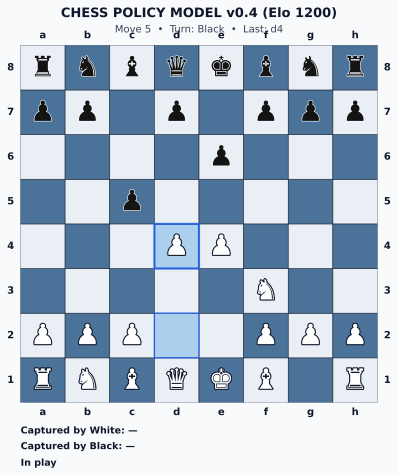


      a   b   c   d   e   f   g   h
   ──────────────────────────────────
 8 │ ♜  ♞  ♝  ♛  ♚  ♝  ♞  ♜ │ 8
 7 │ ♟  ♟  ♟  ♟  ♟  ♟  ♟  ♟ │ 7
 6 │                        │ 6
 5 │                        │ 5
 4 │                        │ 4
 3 │                        │ 3
 2 │ ♟  ♟  ♟  ♟  ♟  ♟  ♟  ♟ │ 2
 1 │ ♜  ♞  ♝  ♛  ♚  ♝  ♞  ♜ │ 1
   ──────────────────────────────────
      a   b   c   d   e   f   g   h

HUMAN (Black @ Elo 1400) vs MODEL (White • Easy @ Elo 1200)
Dedicated HvM folder       : /content/drive/MyDrive/chess/model_v0_4/inference/human_vs_model/20261019_132503_hvm_human_black_elo1400_easy_model_elo1200
Interactive Web Arena link : https://7860-gpu-t4-s-kkb-usw4b2-2u3cx7rz6oct4-b.us-west4-2.prod.colab.dev
Commands: SAN (e4, Nf3) or UCI (e2e4), 'suggest' for AI move suggestion, 'quit'

Model (White, Easy @ Elo 1200) is thinking...
[MODEL_MOVE] MODEL THINKING (ply=1, move=1, side=white)
  Conditioning : target_elo=1200 (bucket=1200)
  Strategy Mode: BALANCED_FIGHTING (material_ad

KeyboardInterrupt: Interrupted by user

In [ ]:
#!/usr/bin/env python3
"""
CHESS POLICY MODEL v0.4 — STANDALONE COLAB & LOCAL INFERENCE + FULL-WIDTH WEB ARENA (SCRIPT 5/5)

Features:
  1. Complete v0.4 feature engineering (20x64 board, 18 global, 32 candidate,
     16 history, 40 perspective-corrected memory, 12 position, 5 flags, 6 geometry)
     + Exchange-Aware Tactical Refinement (Problem #3 Fix).
  2. Dual-Stream FiLM + Legacy v0.4 Elo Checkpoint Auto-Detection.
  3. Elo-Stratified Multi-Tier Reasoning Engine:
     - Easy   : 0-ply raw intuition + soft human-like move sampling
     - Medium : 1-ply tactical guard + controlled opening variety
     - Hard   : 2-ply tactical minimax lookahead + sharp candidate selection
     - Expert : Deep 2-ply minimax lookahead + endgame passed-pawn push + master book variety
  4. Interactive input() selector at startup: 1 = Google Colab (default), 2 = Local PC.
  5. Full-width responsive Web Chess Arena with Royal Blue primary theme and
     Dark / Light theme toggle.
  6. AI Move Suggestion ("Ask AI Suggestion") at Master 2200-Elo depth with
     Approve / Reject confirmation and automatic next-best move cycling on rejection.
  7. Interactive PGN Move Scrubber & Saved Game Reviewer + Detailed chess-rule
     termination explanations + separated `human_vs_model` and `model_vs_model` folders.
"""

from __future__ import annotations

import copy
import datetime as dt
import hashlib
import importlib.util
import json
import math
import os
import random
import shutil
import socket
import subprocess
import sys
import threading
import time
from collections import Counter, defaultdict
from http.server import BaseHTTPRequestHandler, ThreadingHTTPServer
from pathlib import Path
from typing import Any, Dict, List, Optional, Sequence, Set, Tuple
from urllib.parse import parse_qs, urlparse


# ============================================================
# 1. DEPENDENCY BOOTSTRAP
# ============================================================

def ensure_package(module: str, package: str) -> None:
    if importlib.util.find_spec(module) is None:
        print(f"Installing {package} ...")
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", package])


ensure_package("chess", "python-chess>=1.999")
ensure_package("cloudpickle", "cloudpickle>=3.0")
ensure_package("orjson", "orjson>=3.10")
ensure_package("matplotlib", "matplotlib>=3.8")

import chess
import cloudpickle
import matplotlib
matplotlib.use("Agg")
import matplotlib.patheffects as path_effects
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
import orjson
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset

try:
    from google.colab import drive as colab_drive  # type: ignore
    from google.colab import output as colab_output  # type: ignore
    COLAB_AVAILABLE = True
except Exception:
    colab_drive = None
    colab_output = None
    COLAB_AVAILABLE = False


# ============================================================
# 2. CONSTANTS & v0.4 FEATURE DIMENSIONS
# ============================================================

MODEL_VERSION = "0.4"
FEATURE_VERSION = "v0.4"
TRAINING_SAMPLE_SCHEMA = "0.4-training-sample"
MAX_HISTORY_PLIES = 50
BOARD_ROW_ZERO_IS_RANK_8 = True

ELO_MIN = 1200.0
ELO_MAX = 2000.0
ELO_STEP = 100.0
EXPECTED_ELO_BUCKETS = [
    "<1200", "1200", "1300", "1400", "1500", "1600",
    "1700", "1800", "1900", "2000", ">2000", "unknown",
]
ELO_BUCKET_TO_ID = {bucket: idx for idx, bucket in enumerate(EXPECTED_ELO_BUCKETS)}
ELO_ID_TO_BUCKET = {idx: bucket for bucket, idx in ELO_BUCKET_TO_ID.items()}
ELO_CONDITION_CENTER = (ELO_MIN + ELO_MAX) / 2.0
ELO_CONDITION_SCALE = max(ELO_STEP, (ELO_MAX - ELO_MIN) / 2.0)
ELO_NORMALIZED_CLAMP = 4.0
DEFAULT_TARGET_ELO = 1600.0
AI_COACH_SUGGESTION_ELO = 2200.0
MODEL_MOVE_DELAY_SECONDS = 0.8

DIFFICULTY_OFFSETS = {
    "Easy": -200.0,
    "Medium": 0.0,
    "Hard": +200.0,
    "Expert": +350.0,
}

FEATURE_DIMS = {
    "board_tactical": 20,
    "global_tactical": 18,
    "candidate_tactical": 32,
    "history": 16,
    "memory": 40,
    "position": 12,
    "candidate_move_flags": 5,
    "candidate_geometry": 6,
}

PIECE_VALUES = {
    chess.PAWN: 1.0,
    chess.KNIGHT: 3.0,
    chess.BISHOP: 3.0,
    chess.ROOK: 5.0,
    chess.QUEEN: 9.0,
    chess.KING: 0.0,
}

MEMORY_PIECE_VALUES = {
    chess.PAWN: 100,
    chess.KNIGHT: 320,
    chess.BISHOP: 330,
    chess.ROOK: 500,
    chess.QUEEN: 900,
    chess.KING: 0,
}

PIECE_NAMES = {
    chess.PAWN: "pawn",
    chess.KNIGHT: "knight",
    chess.BISHOP: "bishop",
    chess.ROOK: "rook",
    chess.QUEEN: "queen",
    chess.KING: "king",
}

PROMOTION_NAMES = {
    chess.KNIGHT: "knight",
    chess.BISHOP: "bishop",
    chess.ROOK: "rook",
    chess.QUEEN: "queen",
}

SOLID_PIECE_GLYPHS = {
    chess.PAWN: "♟",
    chess.KNIGHT: "♞",
    chess.BISHOP: "♝",
    chess.ROOK: "♜",
    chess.QUEEN: "♛",
    chess.KING: "♚",
}

CENTER_SQUARES = (chess.D4, chess.E4, chess.D5, chess.E5)


def map_difficulty_to_model_elo(human_elo: float, difficulty: str) -> float:
    diff_key = difficulty.strip().title() if difficulty else "Medium"
    if diff_key == "Expert":
        return float(max(2000.0, min(2400.0, float(human_elo) + 350.0)))
    offset = DIFFICULTY_OFFSETS.get(diff_key, 0.0)
    return float(max(1000.0, min(2400.0, float(human_elo) + offset)))


def infer_difficulty_from_elo(target_elo: float, explicit_difficulty: Optional[str] = None) -> str:
    if explicit_difficulty and explicit_difficulty.strip().title() in DIFFICULTY_OFFSETS:
        return explicit_difficulty.strip().title()
    val = float(target_elo)
    if val < 1480.0:
        return "Easy"
    if val < 1720.0:
        return "Medium"
    if val < 1950.0:
        return "Hard"
    return "Expert"


def describe_game_termination(board: chess.Board) -> Dict[str, Any]:
    """Returns a detailed, human-readable chess rule conclusion when the game ends."""
    if not board.is_game_over(claim_draw=True):
        return {
            "is_over": False,
            "result": "*",
            "winner": None,
            "reason_code": "in_play",
            "title": "Game in Play",
            "explanation": "The game is currently active.",
        }

    result = board.result(claim_draw=True)
    if board.is_checkmate():
        winner = "White" if board.turn == chess.BLACK else "Black"
        loser = "Black" if winner == "White" else "White"
        return {
            "is_over": True,
            "result": result,
            "winner": winner.lower(),
            "reason_code": "checkmate",
            "title": f"Checkmate — {winner} Wins ({result})",
            "explanation": f"{loser}'s king is in check and has no legal escape squares.",
        }

    if board.is_stalemate():
        stm = "White" if board.turn == chess.WHITE else "Black"
        return {
            "is_over": True,
            "result": "1/2-1/2",
            "winner": "draw",
            "reason_code": "stalemate",
            "title": "Draw by Stalemate (1/2-1/2)",
            "explanation": f"{stm} to move is not in check but has no legal moves available.",
        }

    if board.is_fivefold_repetition():
        return {
            "is_over": True,
            "result": "1/2-1/2",
            "winner": "draw",
            "reason_code": "fivefold_repetition",
            "title": "Draw by Fivefold Repetition (1/2-1/2)",
            "explanation": "The exact same board position has occurred five times.",
        }

    if board.can_claim_threefold_repetition():
        return {
            "is_over": True,
            "result": "1/2-1/2",
            "winner": "draw",
            "reason_code": "threefold_repetition",
            "title": "Draw by Threefold Repetition (1/2-1/2)",
            "explanation": "The exact same position with the same side to move and rights has been repeated three times.",
        }

    if board.is_seventyfive_moves():
        return {
            "is_over": True,
            "result": "1/2-1/2",
            "winner": "draw",
            "reason_code": "seventyfive_moves",
            "title": "Draw by 75-Move Rule (1/2-1/2)",
            "explanation": "75 consecutive full moves have been played without a pawn advance or piece capture.",
        }

    if board.can_claim_fifty_moves():
        return {
            "is_over": True,
            "result": "1/2-1/2",
            "winner": "draw",
            "reason_code": "fifty_moves",
            "title": "Draw by 50-Move Rule (1/2-1/2)",
            "explanation": "50 consecutive full moves have been played without a pawn advance or piece capture.",
        }

    if board.is_insufficient_material():
        return {
            "is_over": True,
            "result": "1/2-1/2",
            "winner": "draw",
            "reason_code": "insufficient_material",
            "title": "Draw by Insufficient Material (1/2-1/2)",
            "explanation": "Neither player has sufficient mating material left on the board to force checkmate.",
        }

    return {
        "is_over": True,
        "result": result,
        "winner": "draw",
        "reason_code": "draw",
        "title": f"Game Over ({result})",
        "explanation": "The game concluded by standard chess rules.",
    }


# ============================================================
# 3. ENVIRONMENT SELECTION (1 = COLAB DEFAULT, 2 = LOCAL PC)
# ============================================================

def find_local_checkpoint_candidates() -> List[Path]:
    search_roots = [
        Path.cwd(),
        Path.cwd() / "checkpoints",
        Path.cwd() / "chess" / "model_v0_4" / "checkpoints",
        Path("/content/chess/model_v0_4/checkpoints"),
        Path("/content/drive/MyDrive/chess/model_v0_4/checkpoints"),
        Path.home() / "Downloads",
    ]
    preferred_names = [
        "model_v0_4_elo_final.pt",
        "model_v0_4_elo_best.pt",
        "model_v0_4_elo_last.pt",
        "model_v0_4_initial.pt",
    ]
    found: List[Path] = []
    seen: set[Path] = set()

    for root in search_roots:
        if not root.exists():
            continue
        for name in preferred_names:
            candidate = root / name
            if candidate.exists() and candidate.is_file():
                resolved = candidate.resolve()
                if resolved not in seen:
                    seen.add(resolved)
                    found.append(candidate)
        for pt_file in sorted(root.glob("*.pt")):
            if pt_file.is_file():
                resolved = pt_file.resolve()
                if resolved not in seen:
                    seen.add(resolved)
                    found.append(pt_file)
    return found


def print_required_drive_downloads() -> None:
    print("\n" + "=" * 74)
    print("REQUIRED FILES TO DOWNLOAD FROM GOOGLE DRIVE FOR LOCAL EXECUTION")
    print("=" * 74)
    print("Please download at least item #1 from your Google Drive folder:")
    print("  Drive Root: MyDrive/chess/model_v0_4/")
    print("")
    print("  1. Trained Model Checkpoint (REQUIRED):")
    print("     - MyDrive/chess/model_v0_4/checkpoints/model_v0_4_elo_final.pt")
    print("       (or model_v0_4_elo_best.pt)")
    print("  2. Elo Conditioning & Feature Specs (OPTIONAL - embedded in checkpoint):")
    print("     - MyDrive/chess/model_v0_4/reports/elo_conditioning_spec_v04.json")
    print("     - MyDrive/chess/model_v0_4/reports/v04_feature_spec.json")
    print("=" * 74 + "\n")


def configure_runtime_environment() -> Tuple[str, Path, Path, Path]:
    print("=" * 74)
    print("CHESS POLICY MODEL v0.4 — RUNTIME ENVIRONMENT SETUP")
    print("=" * 74)
    raw_mode = input(
        "Select execution environment [1 = Google Colab (default), 2 = Local PC]: "
    ).strip()
    mode = "2" if raw_mode == "2" else "1"

    if mode == "1":
        if COLAB_AVAILABLE and colab_drive is not None:
            try:
                colab_drive.mount("/content/drive", force_remount=False)
            except Exception as exc:
                print(f"Drive mount note: {exc}")

        drive_root = Path(os.environ.get("CHESS_DATA_ROOT", "/content/drive/MyDrive/chess"))
        if not drive_root.exists() and Path("./chess").exists():
            drive_root = Path("./chess").resolve()

        v04_root = drive_root / "model_v0_4"
        ckpt_dir = v04_root / "checkpoints"
        inference_dir = v04_root / "inference"
        local_cache_dir = Path("/content/chess/model_v0_4/checkpoints")
        inference_dir.mkdir(parents=True, exist_ok=True)
        local_cache_dir.mkdir(parents=True, exist_ok=True)

        candidates = [
            ckpt_dir / "model_v0_4_elo_final.pt",
            ckpt_dir / "model_v0_4_elo_best.pt",
            ckpt_dir / "model_v0_4_elo_last.pt",
            ckpt_dir / "model_v0_4_initial.pt",
        ]
        selected_drive_ckpt = next((p for p in candidates if p.exists() and p.stat().st_size > 0), None)

        if selected_drive_ckpt is None:
            print(f"\nNo checkpoint automatically found in {ckpt_dir}.")
            print_required_drive_downloads()
            custom_ckpt = input("Enter full path to your v0.4 .pt checkpoint file: ").strip()
            if not custom_ckpt or not Path(custom_ckpt).expanduser().exists():
                raise FileNotFoundError(f"Checkpoint not found: {custom_ckpt!r}")
            selected_drive_ckpt = Path(custom_ckpt).expanduser().resolve()

        local_ckpt = local_cache_dir / selected_drive_ckpt.name
        if (
            selected_drive_ckpt.resolve() != local_ckpt.resolve()
            and (not local_ckpt.exists() or local_ckpt.stat().st_size != selected_drive_ckpt.stat().st_size)
        ):
            print(f"Caching checkpoint {selected_drive_ckpt.name} -> {local_ckpt} ...")
            shutil.copy2(selected_drive_ckpt, local_ckpt)
        else:
            local_ckpt = selected_drive_ckpt if not local_ckpt.exists() else local_ckpt

        bundle_path = inference_dir / "v04_runtime_bundle.pkl"
        return "colab", local_ckpt, inference_dir, bundle_path

    # Mode 2: Local PC
    print("\nScanning local machine for v0.4 model checkpoints...")
    discovered = find_local_checkpoint_candidates()
    if discovered:
        print("Found local checkpoint candidate(s):")
        for idx, path in enumerate(discovered, start=1):
            size_mb = path.stat().st_size / (1024 ** 2)
            print(f"  [{idx}] {path} ({size_mb:.1f} MB)")
        default_ckpt = discovered[0]
        prompt_text = (
            f"Enter checkpoint number [1-{len(discovered)}] or custom file path "
            f"[default = {default_ckpt}]: "
        )
    else:
        print_required_drive_downloads()
        default_ckpt = None
        prompt_text = "Enter path to downloaded v0.4 checkpoint (.pt): "

    while True:
        user_ckpt_input = input(prompt_text).strip()
        if not user_ckpt_input and default_ckpt is not None:
            chosen_ckpt = default_ckpt
            break
        if user_ckpt_input.isdigit() and 1 <= int(user_ckpt_input) <= len(discovered):
            chosen_ckpt = discovered[int(user_ckpt_input) - 1]
            break
        candidate_path = Path(user_ckpt_input).expanduser()
        if candidate_path.is_dir():
            dir_pts = list(candidate_path.glob("*.pt"))
            if dir_pts:
                chosen_ckpt = dir_pts[0]
                break
        if candidate_path.exists() and candidate_path.is_file():
            chosen_ckpt = candidate_path.resolve()
            break
        print(f"File not found: {user_ckpt_input!r}")
        print_required_drive_downloads()

    default_log_dir = Path.cwd() / "inference"
    user_log_input = input(
        f"Enter directory path to store inference logs & boards [default = {default_log_dir}]: "
    ).strip()
    inference_dir = Path(user_log_input).expanduser().resolve() if user_log_input else default_log_dir.resolve()
    inference_dir.mkdir(parents=True, exist_ok=True)
    bundle_path = inference_dir / "v04_runtime_bundle.pkl"
    return "local", chosen_ckpt, inference_dir, bundle_path


# ============================================================
# 4. COMPLETE v0.4 FEATURE ENGINEERING (EXACT SCRIPT 2/3/4 ALIGNMENT)
# ============================================================

def clamp(value: float, low: float, high: float) -> float:
    return max(low, min(high, value))


def finite_number(value: Any) -> bool:
    if isinstance(value, bool) or value is None:
        return False
    try:
        return math.isfinite(float(value))
    except (TypeError, ValueError, OverflowError):
        return False


def side_to_id(side: str) -> int:
    return 0 if side == "white" else 1


def piece_value(piece: Optional[chess.Piece]) -> float:
    return 0.0 if piece is None else PIECE_VALUES[piece.piece_type]


def controlled_material(board: chess.Board, color: chess.Color) -> float:
    occ = board.occupied_co[color]
    return (
        1.0 * chess.popcount(board.pawns & occ)
        + 3.0 * chess.popcount((board.knights | board.bishops) & occ)
        + 5.0 * chess.popcount(board.rooks & occ)
        + 9.0 * chess.popcount(board.queens & occ)
    )


def count_legal_moves_for_color(board: chess.Board, color: chess.Color) -> int:
    if board.turn == color:
        return board.legal_moves.count()
    temp = board.copy(stack=False)
    temp.turn = color
    return temp.legal_moves.count()


def center_control_count(board: chess.Board, color: chess.Color) -> int:
    return sum(chess.popcount(board.attackers_mask(color, sq)) for sq in CENTER_SQUARES)


def king_ring_pressure(board: chess.Board, king_square: Optional[int], attacker: chess.Color) -> int:
    if king_square is None:
        return 0
    ring_mask = chess.BB_KING_ATTACKS[king_square]
    pressure = 0
    for sq in chess.scan_forward(ring_mask):
        pressure += chess.popcount(board.attackers_mask(attacker, sq))
    return pressure


def hanging_non_king(board: chess.Board, color: chess.Color) -> int:
    non_king_mask = board.occupied_co[color] & ~board.kings
    opp = not color
    count = 0
    for square in chess.scan_forward(non_king_mask):
        if board.attackers_mask(opp, square) and not board.attackers_mask(color, square):
            count += 1
    return count


def pinned_non_king(board: chess.Board, color: chess.Color) -> int:
    non_king_mask = board.occupied_co[color] & ~board.kings
    count = 0
    for square in chess.scan_forward(non_king_mask):
        if board.is_pinned(color, square):
            count += 1
    return count


def compute_board_tactical_features(board: chess.Board) -> List[List[float]]:
    """v0.4 20-dimensional per-square tactical features."""
    turn = board.turn
    is_white_turn = (turn == chess.WHITE)
    white_king = board.king(chess.WHITE)
    black_king = board.king(chess.BLACK)
    pawns_bb = board.pawns
    piece_map = board.piece_map()

    legal_from_count = [0] * 64
    for move in board.legal_moves:
        legal_from_count[move.from_square] += 1

    features: List[List[float]] = []
    for square in range(64):
        piece = piece_map.get(square)
        w_mask = board.attackers_mask(chess.WHITE, square)
        b_mask = board.attackers_mask(chess.BLACK, square)

        white_attack_count = chess.popcount(w_mask)
        black_attack_count = chess.popcount(b_mask)
        current_attack_count = white_attack_count if is_white_turn else black_attack_count
        opponent_attack_count = black_attack_count if is_white_turn else white_attack_count

        pinned_white = 0.0
        pinned_black = 0.0
        signed_piece = 0.0
        is_current_side_piece = 0.0
        is_opponent_piece = 0.0
        current_side_defended = 0.0
        opponent_side_defended = 0.0
        if piece is not None:
            val = PIECE_VALUES[piece.piece_type]
            if piece.color == chess.WHITE:
                signed_piece = val / 9.0
                pinned_white = float(board.is_pinned(chess.WHITE, square))
            else:
                signed_piece = -val / 9.0
                pinned_black = float(board.is_pinned(chess.BLACK, square))
            if piece.color == turn:
                is_current_side_piece = 1.0
                current_side_defended = float(current_attack_count > 0)
            else:
                is_opponent_piece = 1.0
                opponent_side_defended = float(opponent_attack_count > 0)

        current_side_attacked = float(opponent_attack_count > 0 and is_current_side_piece > 0.5)
        current_square_attacked = float(current_attack_count > 0)

        w_pawn_attacks = chess.popcount(w_mask & pawns_bb)
        b_pawn_attacks = chess.popcount(b_mask & pawns_bb)

        dist_wk = 8.0 if white_king is None else float(chess.square_distance(square, white_king))
        dist_bk = 8.0 if black_king is None else float(chess.square_distance(square, black_king))

        features.append([
            signed_piece,
            white_attack_count / 8.0,
            black_attack_count / 8.0,
            current_attack_count / 8.0,
            opponent_attack_count / 8.0,
            pinned_white,
            pinned_black,
            min(legal_from_count[square], 32) / 32.0,
            dist_wk / 7.0,
            dist_bk / 7.0,
            float(dist_wk <= 1.0),
            float(dist_bk <= 1.0),
            is_current_side_piece,
            is_opponent_piece,
            current_side_attacked,
            current_square_attacked,
            w_pawn_attacks / 2.0,
            b_pawn_attacks / 2.0,
            current_side_defended,
            opponent_side_defended,
        ])
    return features


def compute_global_tactical_features(board: chess.Board) -> List[float]:
    """v0.4 18-dimensional global tactical vector."""
    current = board.turn
    opponent = not current
    current_king = board.king(current)
    opponent_king = board.king(opponent)
    white_material = controlled_material(board, chess.WHITE)
    black_material = controlled_material(board, chess.BLACK)
    piece_count = chess.popcount(board.occupied)
    pawn_count = chess.popcount(board.pawns)
    legal_moves = board.legal_moves.count()
    current_attackers_on_king = (
        chess.popcount(board.attackers_mask(opponent, current_king))
        if current_king is not None else 0
    )
    opponent_king_attackers = (
        chess.popcount(board.attackers_mask(current, opponent_king))
        if opponent_king is not None else 0
    )

    return [
        white_material / 39.0,
        black_material / 39.0,
        (white_material - black_material) / 39.0,
        min(legal_moves, 100) / 100.0,
        float(board.is_check()),
        min(current_attackers_on_king, 8) / 8.0,
        min(opponent_king_attackers, 8) / 8.0,
        piece_count / 32.0,
        pawn_count / 16.0,
        float(current == chess.WHITE),
        hanging_non_king(board, current) / 15.0,
        hanging_non_king(board, opponent) / 15.0,
        pinned_non_king(board, current) / 15.0,
        pinned_non_king(board, opponent) / 15.0,
        min(king_ring_pressure(board, current_king, opponent), 24) / 24.0,
        min(king_ring_pressure(board, opponent_king, current), 24) / 24.0,
        float(
            board.has_kingside_castling_rights(current)
            + board.has_queenside_castling_rights(current)
        ) / 2.0,
        float(
            board.has_kingside_castling_rights(opponent)
            + board.has_queenside_castling_rights(opponent)
        ) / 2.0,
    ]


def precompute_board_context(board: chess.Board) -> Dict[str, Any]:
    current = board.turn
    opponent = not current
    current_king_before = board.king(current)
    opponent_king_before = board.king(opponent)

    own_legal_before = board.legal_moves.count()
    opponent_legal_before = count_legal_moves_for_color(board, opponent)
    current_center_before = center_control_count(board, current)

    enemy_king_attackers_before = (
        chess.popcount(board.attackers_mask(current, opponent_king_before))
        if opponent_king_before is not None else 0
    )
    own_king_attackers_before = (
        chess.popcount(board.attackers_mask(opponent, current_king_before))
        if current_king_before is not None else 0
    )
    material_before = controlled_material(board, current) - controlled_material(board, opponent)

    return {
        "current_king_before": current_king_before,
        "opponent_king_before": opponent_king_before,
        "own_legal_before": own_legal_before,
        "opponent_legal_before": opponent_legal_before,
        "current_center_before": current_center_before,
        "enemy_king_attackers_before": enemy_king_attackers_before,
        "own_king_attackers_before": own_king_attackers_before,
        "material_before": material_before,
    }


def compute_candidate_tactical_features(
    board: chess.Board,
    move: chess.Move,
    ctx: Optional[Dict[str, Any]] = None,
) -> List[float]:
    """v0.4 32-dimensional candidate consequence tactical features."""
    if ctx is None:
        ctx = precompute_board_context(board)

    current = board.turn
    opponent = not current
    moving_piece = board.piece_at(move.from_square)

    is_ep = bool(board.is_en_passant(move))
    if is_ep:
        captured_square = move.to_square - 8 if current == chess.WHITE else move.to_square + 8
        captured_piece = board.piece_at(captured_square)
        is_capture = True
    else:
        captured_piece = board.piece_at(move.to_square)
        is_capture = captured_piece is not None

    is_castling = bool(board.is_castling(move))
    is_promotion = move.promotion is not None
    gives_check = bool(board.gives_check(move))

    from_current_attackers = chess.popcount(board.attackers_mask(current, move.from_square))
    from_opponent_attackers = chess.popcount(board.attackers_mask(opponent, move.from_square))
    to_current_attackers = chess.popcount(board.attackers_mask(current, move.to_square))
    to_opponent_attackers = chess.popcount(board.attackers_mask(opponent, move.to_square))
    pinned = float(board.is_pinned(current, move.from_square))

    own_legal_before = ctx["own_legal_before"]
    opponent_legal_before = ctx["opponent_legal_before"]
    current_center_before = ctx["current_center_before"]
    enemy_king_attackers_before = ctx["enemy_king_attackers_before"]
    own_king_attackers_before = ctx["own_king_attackers_before"]
    material_before = ctx["material_before"]

    is_king_move = moving_piece is not None and moving_piece.piece_type == chess.KING
    after_opponent_king = ctx.get("opponent_king_before", board.king(opponent))

    board.push(move)
    try:
        after_current_king = move.to_square if is_king_move else ctx.get("current_king_before", board.king(current))
        to_current_attackers_after = chess.popcount(board.attackers_mask(current, move.to_square))
        to_opponent_attackers_after = chess.popcount(board.attackers_mask(opponent, move.to_square))
        opponent_legal_after = board.legal_moves.count()
        own_legal_after = count_legal_moves_for_color(board, current)
        enemy_king_attackers_after = (
            chess.popcount(board.attackers_mask(current, after_opponent_king))
            if after_opponent_king is not None else 0
        )
        own_king_attackers_after = (
            chess.popcount(board.attackers_mask(opponent, after_current_king))
            if after_current_king is not None else 0
        )
        current_center_after = center_control_count(board, current)
        material_after = controlled_material(board, current) - controlled_material(board, opponent)
        current_king_pressure_after = king_ring_pressure(board, after_current_king, opponent)
        opponent_king_pressure_after = king_ring_pressure(board, after_opponent_king, current)
    finally:
        board.pop()

    material_delta = material_after - material_before
    own_mobility_delta = own_legal_after - own_legal_before
    opponent_mobility_delta = opponent_legal_after - opponent_legal_before
    enemy_king_pressure_delta = enemy_king_attackers_after - enemy_king_attackers_before
    own_king_pressure_delta = own_king_attackers_after - own_king_attackers_before
    destination_defense_balance = to_current_attackers_after - to_opponent_attackers_after
    center_control_delta = current_center_after - current_center_before

    return [
        from_current_attackers / 8.0,
        from_opponent_attackers / 8.0,
        to_current_attackers / 8.0,
        to_opponent_attackers / 8.0,
        to_current_attackers_after / 8.0,
        to_opponent_attackers_after / 8.0,
        pinned,
        float(gives_check),
        float(is_capture),
        float(is_castling),
        float(is_ep),
        float(is_promotion),
        piece_value(captured_piece) / 9.0,
        piece_value(moving_piece) / 9.0,
        (PIECE_VALUES.get(move.promotion, 0.0) if move.promotion else 0.0) / 9.0,
        min(opponent_legal_after, 100) / 100.0,
        enemy_king_attackers_before / 8.0,
        enemy_king_attackers_after / 8.0,
        own_king_attackers_before / 8.0,
        own_king_attackers_after / 8.0,
        enemy_king_pressure_delta / 8.0,
        own_king_pressure_delta / 8.0,
        clamp(material_delta / 9.0, -1.0, 1.0),
        own_legal_before / 100.0,
        own_legal_after / 100.0,
        opponent_legal_before / 100.0,
        own_mobility_delta / 50.0,
        opponent_mobility_delta / 50.0,
        min(current_king_pressure_after, 24) / 24.0,
        min(opponent_king_pressure_after, 24) / 24.0,
        clamp(destination_defense_balance / 8.0, -1.0, 1.0),
        clamp(center_control_delta / 4.0, -1.0, 1.0),
    ]


def candidate_geometry(from_square: int, to_square: int) -> List[float]:
    from_file, from_rank = from_square & 7, from_square >> 3
    to_file, to_rank = to_square & 7, to_square >> 3
    dx, dy = to_file - from_file, to_rank - from_rank
    abs_dx, abs_dy = abs(dx), abs(dy)
    cheb = max(abs_dx, abs_dy)
    manhattan = abs_dx + abs_dy
    return [dx / 7.0, dy / 7.0, abs_dx / 7.0, abs_dy / 7.0, cheb / 7.0, manhattan / 14.0]


def history_move_to_vector(move: Dict[str, Any]) -> List[float]:
    """v0.4 16-dimensional history move vector."""
    features = move.get("move_features") or {}
    uci = move.get("uci")
    if not isinstance(uci, str):
        raise ValueError("History move missing uci")
    parsed = chess.Move.from_uci(uci)

    captured_value = float(features.get("captured_piece_value", 0) or 0) / 900.0
    moved_value = float(features.get("moved_piece_value", 0) or 0) / 900.0
    promotion_value = float(features.get("promotion_piece_value", 0) or 0) / 900.0
    distance = float(features.get("move_distance", 0) or 0) / 7.0
    king_distance = float(features.get("destination_to_opponent_king_distance", 8) or 8) / 8.0
    events = float(features.get("strategic_event_count", len(move.get("strategic_events", []))) or 0) / 8.0

    return [
        parsed.from_square / 63.0,
        parsed.to_square / 63.0,
        float(move.get("side_id", 0 if move.get("side") == "white" else 1)),
        float(bool(features.get("is_capture", False))),
        float(bool(features.get("is_check", False))),
        float(bool(features.get("is_castling", features.get("is_castle", False)))),
        float(bool(features.get("is_en_passant", False))),
        float(bool(features.get("is_promotion", False))),
        clamp(captured_value, 0.0, 1.0),
        clamp(moved_value, 0.0, 1.0),
        clamp(promotion_value, 0.0, 1.0),
        clamp(distance, 0.0, 1.0),
        float(bool(features.get("center_activity", False))),
        clamp(king_distance, 0.0, 1.0),
        float(bool(features.get("is_check_after", features.get("is_check", False)))),
        clamp(events, 0.0, 1.0),
    ]


def position_to_vector(position_state: Dict[str, Any]) -> List[float]:
    """v0.4 12-dimensional position state vector."""
    if not isinstance(position_state, dict):
        position_state = {}
    rights = position_state.get("castling_rights") or {}
    ep = position_state.get("en_passant_square")
    ep_index = 0.0
    ep_exists = 0.0
    if isinstance(ep, str) and len(ep) == 2:
        try:
            ep_index = chess.parse_square(ep) / 63.0
            ep_exists = 1.0
        except Exception:
            pass
    return [
        clamp(float(position_state.get("legal_move_count", 0) or 0) / 100.0, 0.0, 1.0),
        float(bool(position_state.get("is_check", False))),
        float(bool(position_state.get("is_checkmate", False))),
        float(bool(position_state.get("is_stalemate", False))),
        clamp(float(position_state.get("halfmove_clock", 0) or 0) / 100.0, 0.0, 1.0),
        clamp(float(position_state.get("fullmove_number", 1) or 1) / 150.0, 0.0, 1.0),
        float(bool(rights.get("white_kingside", False))),
        float(bool(rights.get("white_queenside", False))),
        float(bool(rights.get("black_kingside", False))),
        float(bool(rights.get("black_queenside", False))),
        ep_exists,
        clamp(ep_index, 0.0, 1.0),
    ]


_BUCKET_CACHE: Dict[Tuple[str, int], int] = {}


def stable_bucket(text: str, modulo: int) -> int:
    key = (text, modulo)
    cached = _BUCKET_CACHE.get(key)
    if cached is not None:
        return cached
    digest = hashlib.md5(text.encode("utf-8")).digest()
    value = int.from_bytes(digest[:4], byteorder="little", signed=False) % modulo
    if len(_BUCKET_CACHE) < 16384:
        _BUCKET_CACHE[key] = value
    return value


def memory_scalar(value: Any, key_path: str) -> float:
    if isinstance(value, bool):
        return 1.0 if value else 0.0
    if not finite_number(value):
        return 0.0
    number = float(value)
    path_lower = key_path.lower()
    if "past_plies" in path_lower or "move_number" in path_lower:
        number /= 100.0
    elif "count" in path_lower or "moves" in path_lower:
        number /= 100.0
    number = math.copysign(math.log1p(abs(number)), number)
    number /= 6.0
    return clamp(number, -1.0, 1.0)


def memory_to_vector32(memory: Dict[str, Any]) -> List[float]:
    vector = [0.0] * 32
    counts = [0.0] * 32

    def visit(value: Any, path: str) -> None:
        if isinstance(value, dict):
            for key, item in value.items():
                key_path = f"{path}.{key}" if path else str(key)
                visit(item, key_path)
            return
        if isinstance(value, list):
            bucket = stable_bucket(path + ".length", 32)
            vector[bucket] += clamp(math.log1p(len(value)) / 6.0, -1.0, 1.0)
            counts[bucket] += 1.0
            for index, item in enumerate(value):
                visit(item, f"{path}[{index}]")
            return
        if isinstance(value, bool):
            bucket = stable_bucket(path, 32)
            vector[bucket] += 1.0 if value else 0.0
            counts[bucket] += 1.0
        elif isinstance(value, (int, float)):
            bucket = stable_bucket(path, 32)
            vector[bucket] += memory_scalar(value, path)
            counts[bucket] += 1.0

    if isinstance(memory, dict):
        visit(memory, "")
    for index in range(32):
        if counts[index] > 1.0:
            vector[index] /= math.sqrt(counts[index])
        vector[index] = clamp(vector[index], -4.0, 4.0)
    return vector


def memory_to_vector40(memory: Dict[str, Any], side_to_move: str = "white") -> List[float]:
    """
    v0.4 40-dimensional memory vector (32 hashed + 8 explicit v0.4 signals).
    Fix 1 Applied: `last_10_ply_material_change_cp` is oriented to `side_to_move`
    just like `material_advantage_side_to_move_cp`.
    """
    hashed = memory_to_vector32(memory)
    signals = memory.get("v04_explicit_signals", {}) if isinstance(memory, dict) else {}
    sign = 1.0 if side_to_move == "white" else -1.0
    explicit = [
        float(signals.get("material_advantage_side_to_move_cp", 0) or 0) / 3900.0,
        (sign * float(signals.get("last_10_ply_material_change_cp", 0) or 0)) / 3900.0,
        clamp(float(signals.get("current_position_repetition_count", 1) or 1) / 3.0, 0.0, 1.0),
        float(bool(signals.get("threefold_occurred", False))),
        clamp(float(signals.get("check_count_difference", 0) or 0) / 10.0, -1.0, 1.0),
        clamp(float(signals.get("capture_count_difference", 0) or 0) / 10.0, -1.0, 1.0),
        clamp(float(signals.get("castle_count_difference", 0) or 0) / 4.0, -1.0, 1.0),
        clamp(float(signals.get("promotion_count_difference", 0) or 0) / 4.0, -1.0, 1.0),
    ]
    return hashed + explicit


def target_elo_bucket_label(target_elo: float) -> str:
    value = float(target_elo)
    if not math.isfinite(value):
        return "1800"
    if value < ELO_MIN:
        return "<1200"
    if value > ELO_MAX:
        return ">2000"
    bucket_steps = int(math.floor((value - ELO_MIN) / ELO_STEP + 0.5))
    bucket_value = max(ELO_MIN, min(ELO_MAX, ELO_MIN + bucket_steps * ELO_STEP))
    return str(int(round(bucket_value)))


# ============================================================
# 5. LONG-TERM MEMORY & RUNTIME RECORD BUILDERS (v0.4)
# ============================================================

def material_difference(board: chess.Board) -> int:
    white = 0
    black = 0
    for piece_type, value in MEMORY_PIECE_VALUES.items():
        white += len(board.pieces(piece_type, chess.WHITE)) * value
        black += len(board.pieces(piece_type, chess.BLACK)) * value
    return white - black


def count_pawn_features(board: chess.Board, color: chess.Color) -> Dict[str, int]:
    pawns = list(board.pieces(chess.PAWN, color))
    files = Counter(chess.square_file(sq) for sq in pawns)
    doubled = sum(max(0, count - 1) for count in files.values())
    isolated = 0
    passed_squares = []

    for sq in pawns:
        f = chess.square_file(sq)
        r = chess.square_rank(sq)
        adjacent_files = {af for af in (f - 1, f + 1) if 0 <= af < 8}
        if not any(files.get(af, 0) > 0 for af in adjacent_files):
            isolated += 1

        enemy = not color
        passed = True
        for enemy_sq in board.pieces(chess.PAWN, enemy):
            ef = chess.square_file(enemy_sq)
            er = chess.square_rank(enemy_sq)
            if abs(ef - f) <= 1:
                if (color == chess.WHITE and er > r) or (color == chess.BLACK and er < r):
                    passed = False
                    break
        if passed:
            passed_squares.append(sq)

    passed_files = {chess.square_file(sq) for sq in passed_squares}
    connected_passed = sum(
        1 for sq in passed_squares
        if (chess.square_file(sq) - 1 in passed_files or chess.square_file(sq) + 1 in passed_files)
    )
    return {
        "isolated_pawns": isolated,
        "doubled_pawns": doubled,
        "passed_pawns": len(passed_squares),
        "connected_passed_pawns": connected_passed,
    }


def piece_activity_summary(
    board: chess.Board,
    move_counts_by_piece: Dict[str, Dict[str, int]],
) -> Dict[str, Any]:
    result: Dict[str, Any] = {}
    for color_name, color in (("white", chess.WHITE), ("black", chess.BLACK)):
        counts = move_counts_by_piece[color_name]
        minors_undeveloped = 0
        start_squares = {
            (chess.B1 if color == chess.WHITE else chess.B8): chess.KNIGHT,
            (chess.G1 if color == chess.WHITE else chess.G8): chess.KNIGHT,
            (chess.C1 if color == chess.WHITE else chess.C8): chess.BISHOP,
            (chess.F1 if color == chess.WHITE else chess.F8): chess.BISHOP,
        }
        for sq, piece_type in start_squares.items():
            piece = board.piece_at(sq)
            if piece and piece.color == color and piece.piece_type == piece_type:
                if counts.get(PIECE_NAMES[piece_type], 0) == 0:
                    minors_undeveloped += 1

        result[color_name] = {
            "undeveloped_minors": minors_undeveloped,
            "king_moved": counts.get("king", 0) > 0,
            "queen_moves": counts.get("queen", 0),
            "rook_moves": counts.get("rook", 0),
            "minor_piece_moves": counts.get("knight", 0) + counts.get("bishop", 0),
        }
    return result


def board_key(board: chess.Board) -> Any:
    return board._transposition_key()


def build_long_term_memory(
    board: chess.Board,
    ply: int,
    material_history: List[int],
    repetition_counts: Dict[Any, int],
    move_counts_by_piece: Dict[str, Dict[str, int]],
    check_counts: Dict[str, int],
    capture_counts: Dict[str, int],
    castle_counts: Dict[str, int],
    promotion_counts: Dict[str, int],
    strategic_events: List[Dict[str, Any]],
) -> Dict[str, Any]:
    current_material = material_difference(board)
    initial_material = material_history[0] if material_history else 0
    largest_swing = max((abs(x - initial_material) for x in material_history), default=0)
    last_10 = material_history[-10:] if material_history else [current_material]
    last_10_swing = current_material - last_10[0]

    current_key = board_key(board)
    current_rep = repetition_counts.get(current_key, 1)
    total_repetitions = sum(1 for n in repetition_counts.values() if n >= 3)

    stm_is_white = (board.turn == chess.WHITE)
    stm_name = "white" if stm_is_white else "black"
    opp_name = "black" if stm_is_white else "white"
    mat_adv_stm = current_material if stm_is_white else -current_material

    return {
        "material_trajectory": {
            "initial_difference_white_cp": initial_material,
            "current_difference_white_cp": current_material,
            "current_advantage_side_to_move_cp": mat_adv_stm,
            "largest_swing_from_initial_cp": largest_swing,
            "last_10_ply_change_cp": last_10_swing,
            "past_plies": max(0, ply - 1),
            "position_count_in_history": len(material_history),
        },
        "pawn_structure": {
            "white": count_pawn_features(board, chess.WHITE),
            "black": count_pawn_features(board, chess.BLACK),
        },
        "piece_activity": piece_activity_summary(board, move_counts_by_piece),
        "repetition": {
            "current_position_count": current_rep,
            "threefold_occurred": current_rep >= 3,
            "repetition_events": total_repetitions,
        },
        "historical_patterns": {
            "checks": {"white": check_counts["white"], "black": check_counts["black"]},
            "captures": {"white": capture_counts["white"], "black": capture_counts["black"]},
            "castles": {"white": castle_counts["white"], "black": castle_counts["black"]},
            "promotions": {"white": promotion_counts["white"], "black": promotion_counts["black"]},
        },
        "v04_explicit_signals": {
            "material_advantage_side_to_move_cp": mat_adv_stm,
            "last_10_ply_material_change_cp": last_10_swing,
            "current_position_repetition_count": current_rep,
            "threefold_occurred": bool(current_rep >= 3 or total_repetitions > 0),
            "check_count_difference": check_counts[stm_name] - check_counts[opp_name],
            "capture_count_difference": capture_counts[stm_name] - capture_counts[opp_name],
            "castle_count_difference": castle_counts[stm_name] - castle_counts[opp_name],
            "promotion_count_difference": promotion_counts[stm_name] - promotion_counts[opp_name],
            "initial_material_difference_white_cp": initial_material,
        },
        "strategic_events": strategic_events[-1000:],
    }


def history_move_from_board(board: chess.Board, move: chess.Move) -> Dict[str, Any]:
    """Populates all v0.4 history move fields."""
    moving_piece = board.piece_at(move.from_square)
    if board.is_en_passant(move):
        captured_piece = board.piece_at(
            move.to_square - 8 if board.turn == chess.WHITE else move.to_square + 8
        )
    else:
        captured_piece = board.piece_at(move.to_square)

    moved_piece_type = int(moving_piece.piece_type if moving_piece else 0)
    captured_piece_type = int(captured_piece.piece_type if captured_piece else 0)
    promotion_piece_type = int(move.promotion or 0)

    moved_val_cp = MEMORY_PIECE_VALUES.get(moved_piece_type, 0)
    captured_val_cp = MEMORY_PIECE_VALUES.get(captured_piece_type, 0)
    promo_val_cp = MEMORY_PIECE_VALUES.get(promotion_piece_type, 0)

    move_dist = chess.square_distance(move.from_square, move.to_square)
    opp_king_sq = board.king(not board.turn)
    dest_to_opp_king = chess.square_distance(move.to_square, opp_king_sq) if opp_king_sq is not None else 8
    center_act = bool(move.to_square in CENTER_SQUARES or move.from_square in CENTER_SQUARES)

    is_cap = bool(board.is_capture(move))
    gives_chk = bool(board.gives_check(move))
    is_castle = bool(board.is_castling(move))
    is_ep = bool(board.is_en_passant(move))
    is_promo = bool(move.promotion is not None)
    side_str = "white" if board.turn == chess.WHITE else "black"

    strategic_events: List[Dict[str, Any]] = []
    if is_cap:
        strategic_events.append({"type": "CAPTURE"})
    if gives_chk:
        strategic_events.append({"type": "CHECK"})
    if is_castle:
        strategic_events.append({"type": "CASTLE"})
    if is_promo:
        strategic_events.append({"type": "PROMOTION"})
    if center_act:
        strategic_events.append({"type": "CENTER_ACTIVITY"})

    mf = {
        "from_square": chess.square_name(move.from_square),
        "to_square": chess.square_name(move.to_square),
        "is_capture": is_cap,
        "is_check": gives_chk,
        "is_check_after": gives_chk,
        "is_castle": is_castle,
        "is_castling": is_castle,
        "is_en_passant": is_ep,
        "is_promotion": is_promo,
        "captured_piece": PIECE_NAMES.get(captured_piece.piece_type) if captured_piece else None,
        "captured_piece_type": captured_piece_type,
        "captured_piece_value": captured_val_cp,
        "moved_piece": PIECE_NAMES.get(moving_piece.piece_type) if moving_piece else None,
        "moved_piece_type": moved_piece_type,
        "moved_piece_value": moved_val_cp,
        "promotion": PROMOTION_NAMES.get(move.promotion) if move.promotion else None,
        "promotion_piece": promotion_piece_type,
        "promotion_piece_value": promo_val_cp,
        "move_distance": move_dist,
        "center_activity": center_act,
        "destination_to_opponent_king_distance": dest_to_opp_king,
        "strategic_event_count": len(strategic_events),
    }

    return {
        "uci": move.uci(),
        "san": board.san(move),
        "side": side_str,
        "side_id": 0 if side_str == "white" else 1,
        "move_features": mf,
        "strategic_events": strategic_events,
    }


def board_to_8x8(board: chess.Board) -> List[List[int]]:
    out: List[List[int]] = []
    for rank in range(7, -1, -1):
        row: List[int] = []
        for file_index in range(8):
            piece = board.piece_at(chess.square(file_index, rank))
            if piece is None:
                row.append(0)
            else:
                row.append(piece.piece_type if piece.color == chess.WHITE else -piece.piece_type)
        out.append(row)
    return out


def make_position_state(board: chess.Board) -> Dict[str, Any]:
    return {
        "castling_rights": {
            "white_kingside": board.has_kingside_castling_rights(chess.WHITE),
            "white_queenside": board.has_queenside_castling_rights(chess.WHITE),
            "black_kingside": board.has_kingside_castling_rights(chess.BLACK),
            "black_queenside": board.has_queenside_castling_rights(chess.BLACK),
        },
        "en_passant_square": chess.square_name(board.ep_square) if board.ep_square is not None else None,
        "halfmove_clock": board.halfmove_clock,
        "fullmove_number": board.fullmove_number,
        "is_check": board.is_check(),
        "is_checkmate": board.is_checkmate(),
        "is_stalemate": board.is_stalemate(),
        "legal_move_count": board.legal_moves.count(),
    }


def determine_phase(board: chess.Board) -> str:
    queens = chess.popcount(board.queens)
    rooks = chess.popcount(board.rooks)
    minors = chess.popcount(board.bishops | board.knights)
    pawns = chess.popcount(board.pawns)
    if queens >= 1 and pawns >= 8:
        return "opening"
    if queens >= 1 and (rooks + minors) >= 5:
        return "middlegame"
    if pawns <= 8 or queens == 0 or rooks <= 1:
        return "endgame"
    return "middlegame"


def runtime_candidate(
    move: chess.Move,
    board: chess.Board,
    ctx: Dict[str, Any],
) -> Dict[str, Any]:
    moving_piece = board.piece_at(move.from_square)
    is_ep = bool(board.is_en_passant(move))
    if is_ep:
        captured_piece = board.piece_at(
            move.to_square - 8 if board.turn == chess.WHITE else move.to_square + 8
        )
        is_cap = True
    else:
        captured_piece = board.piece_at(move.to_square)
        is_cap = captured_piece is not None

    is_chk = bool(board.gives_check(move))
    is_castle = bool(board.is_castling(move))
    is_promo = bool(move.promotion is not None)

    promotion_piece = int(move.promotion or 0)
    captured_piece_type = int(captured_piece.piece_type if captured_piece else 0)
    moved_piece_type = int(moving_piece.piece_type if moving_piece else 0)

    flags = [float(is_cap), float(is_chk), float(is_castle), float(is_ep), float(is_promo)]

    return {
        "uci": move.uci(),
        "san": board.san(move),
        "from_square": int(move.from_square),
        "to_square": int(move.to_square),
        "promotion_piece": promotion_piece,
        "captured_piece_type": captured_piece_type,
        "moved_piece_type": moved_piece_type,
        "move_features": {
            "is_capture": is_cap,
            "is_check": is_chk,
            "is_castling": is_castle,
            "is_castle": is_castle,
            "is_en_passant": is_ep,
            "is_promotion": is_promo,
            "captured_piece": PIECE_NAMES.get(captured_piece.piece_type) if captured_piece else None,
            "moved_piece": PIECE_NAMES.get(moving_piece.piece_type) if moving_piece else None,
            "promotion": PROMOTION_NAMES.get(move.promotion) if move.promotion else None,
        },
        "move_flags": flags,
        "geometry": candidate_geometry(move.from_square, move.to_square),
        "tactical_features": compute_candidate_tactical_features(board, move, ctx=ctx),
    }


def make_runtime_record(
    board: chess.Board,
    history_moves: List[Dict[str, Any]],
    memory: Dict[str, Any],
    target_elo: float = DEFAULT_TARGET_ELO,
) -> Dict[str, Any]:
    controlled_side = "white" if board.turn == chess.WHITE else "black"
    ctx = precompute_board_context(board)
    candidates = [
        runtime_candidate(move, board, ctx=ctx)
        for move in sorted(board.legal_moves, key=lambda m: m.uci())
    ]
    if not candidates:
        raise RuntimeError("Position has no legal moves.")

    state = make_position_state(board)
    history_vectors = [
        history_move_to_vector(m)
        for m in history_moves[-MAX_HISTORY_PLIES:]
    ]
    labels = [{"relative_to_best": 0.0, "is_optimal": False} for _ in candidates]
    elo_bucket = target_elo_bucket_label(target_elo)

    return {
        "schema_version": TRAINING_SAMPLE_SCHEMA,
        "feature_schema_version": FEATURE_VERSION,
        "game_id": "live-inference",
        "ply": len(history_moves) + 1,
        "input": {
            "fen": board.fen(),
            "board_8x8": board_to_8x8(board),
            "side_to_move": controlled_side,
            "side_to_move_id": side_to_id(controlled_side),
            "controlled_side": controlled_side,
            "controlled_side_id": side_to_id(controlled_side),
            "position_state": state,
            "position_features": position_to_vector(state),
            "recent_history": {
                "max_plies": MAX_HISTORY_PLIES,
                "plies_available": len(history_moves),
                "vectors": history_vectors,
            },
            "history": history_vectors,
            "history_lengths": len(history_vectors),
            "memory_features": memory_to_vector40(memory, side_to_move=controlled_side),
            "global_tactical_features": compute_global_tactical_features(board),
            "board_tactical_features": compute_board_tactical_features(board),
            "phase": determine_phase(board),
            "candidate_moves": candidates,
        },
        "target": {
            "candidate_uci": [c["uci"] for c in candidates],
            "candidate_san": [c["san"] for c in candidates],
            "best_move": candidates[0]["uci"],
            "optimal_moves": [candidates[0]["uci"]],
            "candidate_labels": labels,
        },
        "metadata": {
            "game_weight": 1.0,
            "controlled_side_elo": float(target_elo),
            "elo": {
                "white_elo": float(target_elo),
                "black_elo": float(target_elo),
                "controlled_side_elo": float(target_elo),
                "opponent_elo": float(target_elo),
                "elo_difference": 0.0,
                "average_elo": float(target_elo),
                "elo_bucket": elo_bucket,
            },
        },
    }


# ============================================================
# 6. v0.4 COLLATE, EXCHANGE REFINEMENT & DUAL-STREAM FiLM MODELS
# ============================================================

def apply_exchange_aware_tactical_refinement(
    board_tactical: torch.Tensor,
    global_tactical: torch.Tensor,
    candidate_tactical: torch.Tensor,
    controlled_side: torch.Tensor,
) -> Tuple[torch.Tensor, torch.Tensor, torch.Tensor]:
    """
    Problem #3 Fix (matches Script 4 training): Upgrades naive undefended piece
    counts and candidate destination defense balance with outnumbered piece
    detection, enemy pawn threats on minor/major pieces, and Static Exchange (SEE)
    destination risk.
    """
    bt = board_tactical.clone()
    gt = global_tactical.clone()
    ct = candidate_tactical.clone()

    piece_mag = bt[:, :, 0].abs() * 9.0
    curr_att = (bt[:, :, 3] * 8.0).round()
    opp_att = (bt[:, :, 4] * 8.0).round()
    is_curr_piece = (bt[:, :, 12] > 0.5) & (piece_mag > 0.5)
    is_opp_piece = (bt[:, :, 13] > 0.5) & (piece_mag > 0.5)

    w_pawn_att = (bt[:, :, 16] * 2.0).round()
    b_pawn_att = (bt[:, :, 17] * 2.0).round()
    is_white_stm = (controlled_side == 0).unsqueeze(-1)

    opp_pawn_att = torch.where(is_white_stm, b_pawn_att, w_pawn_att)
    curr_pawn_att = torch.where(is_white_stm, w_pawn_att, b_pawn_att)

    curr_undefended = is_curr_piece & (opp_att >= 1.0) & (curr_att < 0.5)
    curr_pawn_threatened = is_curr_piece & (piece_mag >= 2.5) & (opp_pawn_att >= 1.0)
    curr_outnumbered = is_curr_piece & (opp_att > curr_att) & (curr_att >= 1.0)

    curr_vuln_score = torch.zeros_like(piece_mag)
    curr_vuln_score = torch.where(curr_outnumbered, torch.full_like(curr_vuln_score, 0.65), curr_vuln_score)
    curr_vuln_score = torch.where(curr_pawn_threatened, torch.full_like(curr_vuln_score, 0.85), curr_vuln_score)
    curr_vuln_score = torch.where(curr_undefended, torch.ones_like(curr_vuln_score), curr_vuln_score)

    opp_undefended = is_opp_piece & (curr_att >= 1.0) & (opp_att < 0.5)
    opp_pawn_threatened = is_opp_piece & (piece_mag >= 2.5) & (curr_pawn_att >= 1.0)
    opp_outnumbered = is_opp_piece & (curr_att > opp_att) & (opp_att >= 1.0)

    opp_vuln_score = torch.zeros_like(piece_mag)
    opp_vuln_score = torch.where(opp_outnumbered, torch.full_like(opp_vuln_score, 0.65), opp_vuln_score)
    opp_vuln_score = torch.where(opp_pawn_threatened, torch.full_like(opp_vuln_score, 0.85), opp_vuln_score)
    opp_vuln_score = torch.where(opp_undefended, torch.ones_like(opp_vuln_score), opp_vuln_score)

    bt[:, :, 14] = torch.maximum(bt[:, :, 14] * 0.35, curr_vuln_score)
    gt[:, 10] = (curr_vuln_score.sum(dim=-1) / 15.0).clamp(0.0, 1.0)
    gt[:, 11] = (opp_vuln_score.sum(dim=-1) / 15.0).clamp(0.0, 1.0)

    to_curr_after = ct[:, :, 4] * 8.0
    to_opp_after = ct[:, :, 5] * 8.0
    captured_val = ct[:, :, 12] * 9.0
    moving_val = ct[:, :, 13] * 9.0

    net_exposure = (moving_val - captured_val).clamp_min(0.0) / 9.0
    undefended_dest = (to_opp_after >= 0.9) & (to_curr_after < 0.5)
    outnumbered_dest = (to_opp_after > to_curr_after) & (to_curr_after >= 0.5)

    see_penalty = torch.zeros_like(ct[:, :, 30])
    see_penalty = torch.where(outnumbered_dest, 0.35 * net_exposure, see_penalty)
    see_penalty = torch.where(undefended_dest, 0.70 * (moving_val / 9.0), see_penalty)
    ct[:, :, 30] = (ct[:, :, 30] - see_penalty).clamp(-1.0, 1.0)

    return bt, gt, ct


def v04_collate(batch: List[Dict[str, Any]]) -> Dict[str, Any]:
    batch_size = len(batch)
    max_candidates = max(len(sample["input"]["candidate_moves"]) for sample in batch)
    max_history = max(1, min(MAX_HISTORY_PLIES, max(len(sample["input"].get("history", [])) for sample in batch)))

    board_rows: List[List[int]] = []
    board_tactical_rows: List[Any] = []
    global_tactical_rows: List[Any] = []
    position_rows: List[Any] = []
    memory_rows: List[Any] = []
    controlled_side_rows: List[int] = []
    history_length_rows: List[int] = []
    target_elo_rows: List[float] = []
    target_elo_bucket_ids: List[int] = []

    history_tensor = torch.zeros((batch_size, max_history, FEATURE_DIMS["history"]), dtype=torch.float32)
    candidate_from = torch.zeros((batch_size, max_candidates), dtype=torch.long)
    candidate_to = torch.zeros((batch_size, max_candidates), dtype=torch.long)
    candidate_promotion = torch.zeros((batch_size, max_candidates), dtype=torch.long)
    candidate_captured = torch.zeros((batch_size, max_candidates), dtype=torch.long)
    candidate_moved = torch.zeros((batch_size, max_candidates), dtype=torch.long)
    candidate_move_flags = torch.zeros((batch_size, max_candidates, FEATURE_DIMS["candidate_move_flags"]), dtype=torch.float32)
    candidate_geometry_t = torch.zeros((batch_size, max_candidates, FEATURE_DIMS["candidate_geometry"]), dtype=torch.float32)
    candidate_tactical = torch.zeros((batch_size, max_candidates, FEATURE_DIMS["candidate_tactical"]), dtype=torch.float32)
    candidate_mask = torch.zeros((batch_size, max_candidates), dtype=torch.bool)

    for b_idx, sample in enumerate(batch):
        inp = sample["input"]
        meta = sample.get("metadata", {})
        board_8x8 = inp["board_8x8"]
        board_rows.append([int(v) + 6 for row in reversed(board_8x8) for v in row])
        board_tactical_rows.append(inp["board_tactical_features"])
        global_tactical_rows.append(inp["global_tactical_features"])
        position_rows.append(inp["position_features"])
        memory_rows.append(inp["memory_features"])
        controlled_side_rows.append(int(inp["controlled_side_id"]))

        t_elo = float((meta.get("elo") or {}).get("controlled_side_elo", meta.get("controlled_side_elo", DEFAULT_TARGET_ELO)))
        t_bucket = target_elo_bucket_label(t_elo)
        target_elo_rows.append(t_elo)
        target_elo_bucket_ids.append(ELO_BUCKET_TO_ID[t_bucket])

        h_vecs = inp.get("history", [])[-MAX_HISTORY_PLIES:]
        history_length_rows.append(len(h_vecs))
        if h_vecs:
            sliced = h_vecs[-max_history:]
            history_tensor[b_idx, :len(sliced)] = torch.tensor(sliced, dtype=torch.float32)

        cands = inp["candidate_moves"]
        ncands = len(cands)
        candidate_from[b_idx, :ncands] = torch.tensor([int(c["from_square"]) for c in cands], dtype=torch.long)
        candidate_to[b_idx, :ncands] = torch.tensor([int(c["to_square"]) for c in cands], dtype=torch.long)
        candidate_promotion[b_idx, :ncands] = torch.tensor([int(c.get("promotion_piece", 0) or 0) for c in cands], dtype=torch.long)
        candidate_captured[b_idx, :ncands] = torch.tensor([int(c.get("captured_piece_type", 0) or 0) for c in cands], dtype=torch.long)
        candidate_moved[b_idx, :ncands] = torch.tensor([int(c.get("moved_piece_type", 0) or 0) for c in cands], dtype=torch.long)
        candidate_move_flags[b_idx, :ncands] = torch.tensor([c["move_flags"] for c in cands], dtype=torch.float32)
        candidate_geometry_t[b_idx, :ncands] = torch.tensor([c["geometry"] for c in cands], dtype=torch.float32)
        candidate_tactical[b_idx, :ncands] = torch.tensor([c["tactical_features"] for c in cands], dtype=torch.float32)
        candidate_mask[b_idx, :ncands] = True

    return {
        "board": torch.tensor(board_rows, dtype=torch.long),
        "board_tactical": torch.tensor(board_tactical_rows, dtype=torch.float32),
        "global_tactical": torch.tensor(global_tactical_rows, dtype=torch.float32),
        "history": history_tensor,
        "history_lengths": torch.tensor(history_length_rows, dtype=torch.long),
        "position": torch.tensor(position_rows, dtype=torch.float32),
        "memory": torch.tensor(memory_rows, dtype=torch.float32),
        "controlled_side": torch.tensor(controlled_side_rows, dtype=torch.long),
        "target_elo": torch.tensor(target_elo_rows, dtype=torch.float32),
        "target_elo_bucket_id": torch.tensor(target_elo_bucket_ids, dtype=torch.long),
        "candidate_from": candidate_from,
        "candidate_to": candidate_to,
        "candidate_promotion": candidate_promotion,
        "candidate_captured": candidate_captured,
        "candidate_moved": candidate_moved,
        "candidate_move_flags": candidate_move_flags,
        "candidate_geometry": candidate_geometry_t,
        "candidate_tactical": candidate_tactical,
        "candidate_mask": candidate_mask,
    }


class SpatialBoardEncoderV04(nn.Module):
    def __init__(self, model_dim: int = 128, dropout: float = 0.10):
        super().__init__()
        self.piece_embedding = nn.Embedding(13, 48)
        self.square_embedding = nn.Embedding(64, 32)
        self.tactical_projection = nn.Sequential(
            nn.Linear(FEATURE_DIMS["board_tactical"], 32),
            nn.LayerNorm(32),
            nn.GELU(),
            nn.Dropout(dropout),
        )
        self.input_projection = nn.Linear(48 + 32 + 32, model_dim)
        encoder_layer = nn.TransformerEncoderLayer(
            d_model=model_dim,
            nhead=4,
            dim_feedforward=256,
            dropout=dropout,
            activation="gelu",
            batch_first=True,
            norm_first=False,
        )
        self.transformer = nn.TransformerEncoder(encoder_layer, num_layers=4)
        self.output_norm = nn.LayerNorm(model_dim)

    def forward(self, board: torch.Tensor, board_tactical: torch.Tensor):
        batch_size = board.shape[0]
        square_ids = torch.arange(64, device=board.device).unsqueeze(0).expand(batch_size, -1)
        tokens = torch.cat([
            self.piece_embedding(board),
            self.square_embedding(square_ids),
            self.tactical_projection(board_tactical),
        ], dim=-1)
        tokens = self.output_norm(self.transformer(self.input_projection(tokens)))
        return tokens, tokens.mean(dim=1)


class HistoryEncoderV04(nn.Module):
    def __init__(self, hidden_dim: int = 128, dropout: float = 0.10):
        super().__init__()
        self.input_projection = nn.Sequential(
            nn.Linear(FEATURE_DIMS["history"], 64),
            nn.LayerNorm(64),
            nn.GELU(),
            nn.Dropout(dropout),
        )
        self.gru = nn.GRU(input_size=64, hidden_size=hidden_dim, num_layers=2, batch_first=True, dropout=dropout)
        self.output_norm = nn.LayerNorm(hidden_dim)

    def forward(self, history: torch.Tensor, lengths: torch.Tensor):
        outputs, _ = self.gru(self.input_projection(history))
        result = torch.zeros((history.shape[0], outputs.shape[-1]), device=history.device, dtype=outputs.dtype)
        non_empty = lengths > 0
        if non_empty.any():
            result[non_empty] = outputs[non_empty, lengths[non_empty] - 1]
        return self.output_norm(result)


class PositionEncoderV04(nn.Module):
    def __init__(self, hidden_dim: int = 64):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(FEATURE_DIMS["position"], 64),
            nn.LayerNorm(64),
            nn.GELU(),
            nn.Linear(64, hidden_dim),
            nn.LayerNorm(hidden_dim),
            nn.GELU(),
        )

    def forward(self, position: torch.Tensor):
        return self.net(position)


class MemoryEncoderV04(nn.Module):
    def __init__(self, hidden_dim: int = 64):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(FEATURE_DIMS["memory"], 64),
            nn.LayerNorm(64),
            nn.GELU(),
            nn.Linear(64, hidden_dim),
            nn.LayerNorm(hidden_dim),
            nn.GELU(),
        )

    def forward(self, memory: torch.Tensor):
        return self.net(memory)


class GlobalTacticalEncoderV04(nn.Module):
    def __init__(self, hidden_dim: int = 64):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(FEATURE_DIMS["global_tactical"], hidden_dim),
            nn.LayerNorm(hidden_dim),
            nn.GELU(),
        )

    def forward(self, value: torch.Tensor):
        return self.net(value)


class CandidateEncoderV04(nn.Module):
    def __init__(self, model_dim: int = 128, dropout: float = 0.10):
        super().__init__()
        self.from_embedding = nn.Embedding(64, 32)
        self.to_embedding = nn.Embedding(64, 32)
        self.promotion_embedding = nn.Embedding(7, 8)
        self.captured_embedding = nn.Embedding(7, 8)
        self.moved_embedding = nn.Embedding(7, 8)
        self.move_flag_projection = nn.Sequential(
            nn.Linear(FEATURE_DIMS["candidate_move_flags"], 16),
            nn.LayerNorm(16),
            nn.GELU(),
        )
        self.geometry_projection = nn.Sequential(
            nn.Linear(FEATURE_DIMS["candidate_geometry"], 16),
            nn.LayerNorm(16),
            nn.GELU(),
        )
        self.tactical_projection = nn.Sequential(
            nn.Linear(FEATURE_DIMS["candidate_tactical"], 48),
            nn.LayerNorm(48),
            nn.GELU(),
        )
        self.output_projection = nn.Sequential(
            nn.Linear(424, model_dim),
            nn.LayerNorm(model_dim),
            nn.GELU(),
            nn.Dropout(dropout),
        )

    def forward(
        self,
        board_tokens: torch.Tensor,
        candidate_from: torch.Tensor,
        candidate_to: torch.Tensor,
        candidate_promotion: torch.Tensor,
        candidate_captured: torch.Tensor,
        candidate_moved: torch.Tensor,
        candidate_move_flags: torch.Tensor,
        candidate_geometry: torch.Tensor,
        candidate_tactical: torch.Tensor,
    ):
        model_dim = board_tokens.shape[-1]
        from_board_token = board_tokens.gather(1, candidate_from.unsqueeze(-1).expand(-1, -1, model_dim))
        to_board_token = board_tokens.gather(1, candidate_to.unsqueeze(-1).expand(-1, -1, model_dim))
        representation = torch.cat([
            from_board_token,
            to_board_token,
            self.from_embedding(candidate_from),
            self.to_embedding(candidate_to),
            self.promotion_embedding(candidate_promotion.clamp(0, 6)),
            self.captured_embedding(candidate_captured.clamp(0, 6)),
            self.moved_embedding(candidate_moved.clamp(0, 6)),
            self.move_flag_projection(candidate_move_flags),
            self.geometry_projection(candidate_geometry),
            self.tactical_projection(candidate_tactical),
        ], dim=-1)
        return self.output_projection(representation)


class EloConditionEncoderV04(nn.Module):
    def __init__(self, bucket_count: int = len(EXPECTED_ELO_BUCKETS), output_dim: int = 32):
        super().__init__()
        self.scalar_net = nn.Sequential(
            nn.Linear(1, 16),
            nn.LayerNorm(16),
            nn.GELU(),
            nn.Linear(16, 16),
            nn.LayerNorm(16),
            nn.GELU(),
        )
        self.bucket_embedding = nn.Embedding(bucket_count, 16)
        self.output_net = nn.Sequential(
            nn.Linear(32, output_dim),
            nn.LayerNorm(output_dim),
            nn.GELU(),
        )

    def forward(self, target_elo: torch.Tensor, bucket_id: torch.Tensor) -> torch.Tensor:
        normalized = (target_elo.float() - ELO_CONDITION_CENTER) / ELO_CONDITION_SCALE
        normalized = normalized.clamp(-ELO_NORMALIZED_CLAMP, ELO_NORMALIZED_CLAMP).unsqueeze(-1)
        scalar_features = self.scalar_net(normalized)
        bucket_features = self.bucket_embedding(bucket_id.clamp(0, len(EXPECTED_ELO_BUCKETS) - 1))
        return self.output_net(torch.cat([scalar_features, bucket_features], dim=-1))


class ChessPolicyRankerV04Elo(nn.Module):
    """
    Script 4 Elo-Conditioned v0.4 Policy Model with Exchange-Aware SEE Refinement.
    Supports both Dual-Stream FiLM (`use_film=True`) and legacy (`use_film=False`)
    v0.4 Elo checkpoints automatically.
    """
    def __init__(self, dropout: float = 0.10, use_film: bool = True):
        super().__init__()
        self.use_film = use_film
        self.board_encoder = SpatialBoardEncoderV04(model_dim=128, dropout=dropout)
        self.history_encoder = HistoryEncoderV04(hidden_dim=128, dropout=dropout)
        self.position_encoder = PositionEncoderV04(hidden_dim=64)
        self.memory_encoder = MemoryEncoderV04(hidden_dim=64)
        self.global_tactical_encoder = GlobalTacticalEncoderV04(hidden_dim=64)
        self.controlled_side_embedding = nn.Embedding(2, 16)
        self.elo_encoder = EloConditionEncoderV04(bucket_count=len(EXPECTED_ELO_BUCKETS), output_dim=32)
        self.context_projection = nn.Sequential(
            nn.Linear(128 + 128 + 64 + 64 + 64 + 16 + 32, 192),
            nn.LayerNorm(192),
            nn.GELU(),
            nn.Dropout(dropout),
        )
        if self.use_film:
            self.context_film = nn.Linear(32, 192 * 2)
            self.candidate_film = nn.Linear(32, 128 * 2)
        self.candidate_encoder = CandidateEncoderV04(model_dim=128, dropout=dropout)
        self.score_head = nn.Sequential(
            nn.Linear(128 + 192, 160),
            nn.LayerNorm(160),
            nn.GELU(),
            nn.Dropout(dropout),
            nn.Linear(160, 1),
        )

    def forward(self, batch: Dict[str, torch.Tensor]) -> Dict[str, torch.Tensor]:
        board_tact, global_tact, cand_tact = apply_exchange_aware_tactical_refinement(
            batch["board_tactical"],
            batch["global_tactical"],
            batch["candidate_tactical"],
            batch["controlled_side"],
        )

        board_tokens, board_global = self.board_encoder(batch["board"], board_tact)
        history_vector = self.history_encoder(batch["history"], batch["history_lengths"])
        position_vector = self.position_encoder(batch["position"])
        memory_vector = self.memory_encoder(batch["memory"])
        global_tactical_vector = self.global_tactical_encoder(global_tact)
        controlled_side_vector = self.controlled_side_embedding(batch["controlled_side"])
        elo_vector = self.elo_encoder(batch["target_elo"], batch["target_elo_bucket_id"])

        context = self.context_projection(torch.cat([
            board_global,
            history_vector,
            position_vector,
            memory_vector,
            global_tactical_vector,
            controlled_side_vector,
            elo_vector,
        ], dim=-1))

        if self.use_film and hasattr(self, "context_film"):
            gamma_ctx, beta_ctx = self.context_film(elo_vector).chunk(2, dim=-1)
            context = context * (1.0 + torch.tanh(gamma_ctx)) + beta_ctx

        candidate_representation = self.candidate_encoder(
            board_tokens,
            batch["candidate_from"],
            batch["candidate_to"],
            batch["candidate_promotion"],
            batch["candidate_captured"],
            batch["candidate_moved"],
            batch["candidate_move_flags"],
            batch["candidate_geometry"],
            cand_tact,
        )

        if self.use_film and hasattr(self, "candidate_film"):
            gamma_cand, beta_cand = self.candidate_film(elo_vector).unsqueeze(1).chunk(2, dim=-1)
            candidate_representation = candidate_representation * (1.0 + torch.tanh(gamma_cand)) + beta_cand

        candidate_count = candidate_representation.shape[1]
        expanded_context = context.unsqueeze(1).expand(-1, candidate_count, -1)
        scores = self.score_head(torch.cat([candidate_representation, expanded_context], dim=-1)).squeeze(-1)
        scores = scores.masked_fill(~batch["candidate_mask"], torch.finfo(scores.dtype).min)
        return {"scores": scores, "candidate_mask": batch["candidate_mask"]}


class ChessPolicyRankerV04(nn.Module):
    """Script 3 Non-Elo v0.4 fallback model."""
    def __init__(self, dropout: float = 0.10):
        super().__init__()
        self.board_encoder = SpatialBoardEncoderV04(model_dim=128, dropout=dropout)
        self.history_encoder = HistoryEncoderV04(hidden_dim=128, dropout=dropout)
        self.position_encoder = PositionEncoderV04(hidden_dim=64)
        self.memory_encoder = MemoryEncoderV04(hidden_dim=64)
        self.global_tactical_encoder = GlobalTacticalEncoderV04(hidden_dim=64)
        self.controlled_side_embedding = nn.Embedding(2, 16)
        self.context_projection = nn.Sequential(
            nn.Linear(128 + 128 + 64 + 64 + 64 + 16, 160),
            nn.LayerNorm(160),
            nn.GELU(),
            nn.Dropout(dropout),
        )
        self.candidate_encoder = CandidateEncoderV04(model_dim=128, dropout=dropout)
        self.score_head = nn.Sequential(
            nn.Linear(128 + 160, 160),
            nn.LayerNorm(160),
            nn.GELU(),
            nn.Dropout(dropout),
            nn.Linear(160, 1),
        )

    def forward(self, batch: Dict[str, torch.Tensor]) -> Dict[str, torch.Tensor]:
        board_tact, global_tact, cand_tact = apply_exchange_aware_tactical_refinement(
            batch["board_tactical"],
            batch["global_tactical"],
            batch["candidate_tactical"],
            batch["controlled_side"],
        )

        board_tokens, board_global = self.board_encoder(batch["board"], board_tact)
        history_vector = self.history_encoder(batch["history"], batch["history_lengths"])
        position_vector = self.position_encoder(batch["position"])
        memory_vector = self.memory_encoder(batch["memory"])
        global_tactical_vector = self.global_tactical_encoder(global_tact)
        controlled_side_vector = self.controlled_side_embedding(batch["controlled_side"])

        context = self.context_projection(torch.cat([
            board_global,
            history_vector,
            position_vector,
            memory_vector,
            global_tactical_vector,
            controlled_side_vector,
        ], dim=-1))

        candidate_representation = self.candidate_encoder(
            board_tokens,
            batch["candidate_from"],
            batch["candidate_to"],
            batch["candidate_promotion"],
            batch["candidate_captured"],
            batch["candidate_moved"],
            batch["candidate_move_flags"],
            batch["candidate_geometry"],
            cand_tact,
        )
        candidate_count = candidate_representation.shape[1]
        expanded_context = context.unsqueeze(1).expand(-1, candidate_count, -1)
        scores = self.score_head(torch.cat([candidate_representation, expanded_context], dim=-1)).squeeze(-1)
        scores = scores.masked_fill(~batch["candidate_mask"], torch.finfo(scores.dtype).min)
        return {"scores": scores, "candidate_mask": batch["candidate_mask"]}


# ============================================================
# 7. COMPACT BOARD RENDERER (SOLID WHITE & BLACK PIECES)
# ============================================================

BOARD_LIGHT = "#EAEFF6"
BOARD_DARK = "#4B7399"
MOVE_BLUE = "#BFE3FF"
MOVE_BLUE_DARK = "#2563EB"
CHECK_RED = "#F8C4C4"
CHECK_RED_DARK = "#C62828"
BOARD_EDGE = "#1E293B"
TEXT_DARK = "#0F172A"

LIVE_BOARD_DISPLAY = None


def _captured_lines(logger: Optional["GameLogger"]) -> Tuple[str, str]:
    if logger is None:
        return "Captured by White: —", "Captured by Black: —"
    symbols = {"pawn": "♟", "knight": "♞", "bishop": "♝", "rook": "♜", "queen": "♛", "king": "♚"}

    def fmt(counter: Counter) -> str:
        if not counter:
            return "—"
        order = ["queen", "rook", "bishop", "knight", "pawn", "king"]
        parts = [f"{symbols[name]}×{counter[name]}" for name in order if counter.get(name, 0) > 0]
        return "  ".join(parts) if parts else "—"

    return (
        "Captured by White: " + fmt(logger.captures["white"]),
        "Captured by Black: " + fmt(logger.captures["black"]),
    )


def render_board_matplotlib(
    board: chess.Board,
    output_svg: Path,
    output_png: Optional[Path] = None,
    *,
    last_move: Optional[chess.Move] = None,
    move_number: int = 0,
    san: str = "",
    target_elo: float = DEFAULT_TARGET_ELO,
    captured_piece: Optional[str] = None,
    logger: Optional["GameLogger"] = None,
    inline: bool = True,
) -> str:
    global LIVE_BOARD_DISPLAY

    fig = plt.figure(figsize=(6.2, 6.8), dpi=100, facecolor="#F8FAFC")
    ax = fig.add_axes([0.09, 0.16, 0.82, 0.73])
    ax.set_xlim(0, 8)
    ax.set_ylim(0, 8)
    ax.set_aspect("equal")
    ax.axis("off")

    for rank in range(8):
        for file_index in range(8):
            sq_color = BOARD_LIGHT if (rank + file_index) % 2 != 0 else BOARD_DARK
            ax.add_patch(
                Rectangle((file_index, rank), 1, 1, facecolor=sq_color, edgecolor=BOARD_EDGE, linewidth=0.6)
            )

    if last_move is not None:
        for sq, lw in ((last_move.from_square, 1.4), (last_move.to_square, 2.2)):
            fx, rr = chess.square_file(sq), chess.square_rank(sq)
            ax.add_patch(
                Rectangle(
                    (fx, rr), 1, 1,
                    facecolor=MOVE_BLUE,
                    edgecolor=MOVE_BLUE_DARK,
                    linewidth=lw,
                    alpha=0.82,
                )
            )

    if board.is_check():
        checked_king_sq = board.king(board.turn)
        if checked_king_sq is not None:
            fx, rr = chess.square_file(checked_king_sq), chess.square_rank(checked_king_sq)
            ax.add_patch(
                Rectangle(
                    (fx + 0.04, rr + 0.04), 0.92, 0.92,
                    facecolor=CHECK_RED,
                    edgecolor=CHECK_RED_DARK,
                    linewidth=2.4,
                    alpha=0.95,
                )
            )

    for square, piece in board.piece_map().items():
        fx, rr = chess.square_file(square), chess.square_rank(square)
        glyph = SOLID_PIECE_GLYPHS[piece.piece_type]
        if piece.color == chess.WHITE:
            fill_color = "#FFFFFF"
            stroke_color = "#0F172A"
            stroke_width = 2.2
        else:
            fill_color = "#141414"
            stroke_color = "#F8FAFC"
            stroke_width = 1.2

        if board.is_check() and piece.piece_type == chess.KING and piece.color == board.turn:
            stroke_color = CHECK_RED_DARK
            stroke_width = 2.6

        txt = ax.text(
            fx + 0.5,
            rr + 0.48,
            glyph,
            ha="center",
            va="center",
            fontsize=28,
            fontfamily="DejaVu Sans",
            color=fill_color,
            fontweight="bold",
            zorder=5,
        )
        txt.set_path_effects([
            path_effects.Stroke(linewidth=stroke_width, foreground=stroke_color),
            path_effects.Normal(),
        ])

    for i, file_name in enumerate("abcdefgh"):
        ax.text(i + 0.5, -0.22, file_name, ha="center", va="center", fontsize=10, color=TEXT_DARK, fontweight="bold")
        ax.text(i + 0.5, 8.22, file_name, ha="center", va="center", fontsize=10, color=TEXT_DARK, fontweight="bold")
    for i, rank_name in enumerate("12345678"):
        ax.text(-0.22, i + 0.5, rank_name, ha="center", va="center", fontsize=10, color=TEXT_DARK, fontweight="bold")
        ax.text(8.22, i + 0.5, rank_name, ha="center", va="center", fontsize=10, color=TEXT_DARK, fontweight="bold")

    title_side = "White" if board.turn == chess.WHITE else "Black"
    fig.text(
        0.5, 0.955,
        f"CHESS POLICY MODEL v0.4 (Elo {int(round(target_elo))})",
        ha="center", va="center", fontsize=13, color=TEXT_DARK, fontweight="bold",
    )
    fig.text(
        0.5, 0.922,
        f"Move {move_number}  •  Turn: {title_side}" + (f"  •  Last: {san}" if san else ""),
        ha="center", va="center", fontsize=10, color="#334155",
    )

    cap_white, cap_black = _captured_lines(logger)
    fig.text(0.10, 0.102, cap_white, ha="left", va="center", fontsize=9.5, color=TEXT_DARK, fontweight="bold")
    fig.text(0.10, 0.070, cap_black, ha="left", va="center", fontsize=9.5, color=TEXT_DARK, fontweight="bold")

    term_info = describe_game_termination(board)
    status = term_info["title"] if term_info["is_over"] else (
        f"CHECK — {title_side} in check" if board.is_check() else "In play"
    )
    if captured_piece:
        status += f"  •  Captured: {captured_piece}"
    fig.text(
        0.10, 0.036, status,
        ha="left", va="center", fontsize=9.5,
        color=(CHECK_RED_DARK if board.is_check() else TEXT_DARK),
        fontweight="bold",
    )

    output_svg.parent.mkdir(parents=True, exist_ok=True)
    fig.savefig(output_svg, format="svg", bbox_inches="tight", facecolor=fig.get_facecolor())
    if output_png is not None:
        fig.savefig(output_png, format="png", bbox_inches="tight", facecolor=fig.get_facecolor(), dpi=110)
    plt.close(fig)

    if inline:
        try:
            from IPython import get_ipython
            from IPython.display import SVG, display
            if get_ipython() is not None:
                svg_obj = SVG(filename=str(output_svg))
                if LIVE_BOARD_DISPLAY is None:
                    LIVE_BOARD_DISPLAY = display(svg_obj, display_id=True)
                else:
                    LIVE_BOARD_DISPLAY.update(svg_obj)
        except Exception:
            pass

    return str(output_svg)


def print_terminal_board(board: chess.Board, last_move: Optional[chess.Move] = None) -> None:
    light = (234, 239, 246)
    dark = (75, 115, 153)
    blue = (191, 227, 255)
    files = "  a   b   c   d   e   f   g   h"
    print("\n    " + files)
    print("   " + "─" * 34)
    for rank in range(7, -1, -1):
        row = [f" {rank + 1} │"]
        for file_index in range(8):
            square = chess.square(file_index, rank)
            is_last = last_move is not None and square in (last_move.from_square, last_move.to_square)
            bg = blue if is_last else (light if (rank + file_index) % 2 != 0 else dark)
            piece = board.piece_at(square)
            glyph = SOLID_PIECE_GLYPHS[piece.piece_type] if piece else " "
            fg = "255;255;255" if (piece and piece.color == chess.WHITE) else "20;20;20"
            if board.is_check() and square == board.king(board.turn):
                bg = (248, 196, 196)
                fg = "198;40;40"
            r, g, b = bg
            row.append(f"\033[48;2;{r};{g};{b}m\033[38;2;{fg}m {glyph} \033[0m")
        row.append(f"│ {rank + 1}")
        print("".join(row))
    print("   " + "─" * 34)
    print("    " + files)


# ============================================================
# 8. SEPARATED FOLDER HIERARCHY (`human_vs_model` & `model_vs_model`)
# ============================================================

class GameLogger:
    """
    Organizes games into dedicated sub-directories under `inference/`:
      - `inference/human_vs_model/<timestamp>_hvm_human_<side>_elo<h_elo>_<diff>_model_elo<m_elo>/`
      - `inference/model_vs_model/<timestamp>_mvm_white_elo<w_elo>_vs_black_elo<b_elo>/`
      - `inference/position_analysis/<timestamp>_analysis_elo<elo>/`
    """

    def __init__(
        self,
        inference_root: Path,
        mode: str,
        target_elo: float = DEFAULT_TARGET_ELO,
        human_color: str = "white",
        human_elo: float = 1500.0,
        difficulty: str = "Medium",
        white_elo: float = DEFAULT_TARGET_ELO,
        black_elo: float = DEFAULT_TARGET_ELO,
    ):
        now = dt.datetime.now().astimezone()
        stamp = now.strftime("%Y%m%d_%H%M%S")
        self.mode = mode
        self.target_elo = float(target_elo)
        self.human_color = human_color
        self.human_elo = float(human_elo)
        self.difficulty = difficulty
        self.white_elo = float(white_elo)
        self.black_elo = float(black_elo)

        mode_lower = mode.lower()
        if "human" in mode_lower:
            category_dir = inference_root / "human_vs_model"
            diff_slug = difficulty.lower().replace(" ", "_")
            self.game_id = (
                f"{stamp}_hvm_human_{human_color}_elo{int(round(human_elo))}"
                f"_{diff_slug}_model_elo{int(round(target_elo))}"
            )
        elif "model vs model" in mode_lower or "model_vs_model" in mode_lower:
            category_dir = inference_root / "model_vs_model"
            self.game_id = (
                f"{stamp}_mvm_white_elo{int(round(white_elo))}"
                f"_vs_black_elo{int(round(black_elo))}"
            )
        else:
            category_dir = inference_root / "position_analysis"
            self.game_id = f"{stamp}_analysis_elo{int(round(target_elo))}"

        self.game_dir = category_dir / self.game_id
        self.board_dir = self.game_dir / "boards"
        self.board_dir.mkdir(parents=True, exist_ok=True)

        self.moves_jsonl_path = self.game_dir / "moves.jsonl"
        self.thinking_log_path = self.game_dir / "thinking.log"
        self.thinking_jsonl_path = self.game_dir / "thinking.jsonl"
        self.pgn_path = self.game_dir / "game.pgn"
        self.summary_json_path = self.game_dir / "game_summary.json"

        self.move_number = 0
        self.captures = {"white": Counter(), "black": Counter()}
        self.san_moves: List[str] = []
        self.thinking_history: List[Dict[str, Any]] = []

        start_payload = {
            "event": "game_start",
            "game_id": self.game_id,
            "mode": mode,
            "human_color": human_color if "human" in mode_lower else None,
            "human_elo": self.human_elo if "human" in mode_lower else None,
            "difficulty": difficulty if "human" in mode_lower else None,
            "model_target_elo": self.target_elo,
            "white_elo": self.white_elo,
            "black_elo": self.black_elo,
            "started_at": now.isoformat(),
            "game_dir": str(self.game_dir),
        }
        self.write_move_event(start_payload)
        self.summary_json_path.write_text(json.dumps(start_payload, indent=2), encoding="utf-8")
        self.log_thinking_text(
            f"=== GAME STARTED | id={self.game_id} | mode={mode} | "
            f"white_elo={self.white_elo:.0f} | black_elo={self.black_elo:.0f} ==="
        )

    def write_move_event(self, event: Dict[str, Any]) -> None:
        line = json.dumps(event, ensure_ascii=False, default=str) + "\n"
        with self.moves_jsonl_path.open("a", encoding="utf-8") as f:
            f.write(line)
            f.flush()

    def log_thinking_text(self, text: str) -> None:
        stamp = dt.datetime.now().astimezone().strftime("%Y-%m-%d %H:%M:%S.%f")[:-3]
        formatted = f"[{stamp}] {text}"
        with self.thinking_log_path.open("a", encoding="utf-8") as f:
            f.write(formatted + "\n")
            f.flush()

    def record_thinking(self, analysis: Dict[str, Any], also_print: bool = True) -> List[str]:
        now_iso = dt.datetime.now().astimezone().isoformat()
        payload = {"timestamp": now_iso, "game_id": self.game_id, **analysis}
        self.thinking_history.append(payload)
        with self.thinking_jsonl_path.open("a", encoding="utf-8") as f:
            f.write(json.dumps(payload, ensure_ascii=False, default=str) + "\n")
            f.flush()

        purpose = analysis.get("purpose", "MODEL_MOVE")
        tier = analysis.get("difficulty_tier", "Medium")
        lines = [
            f"[{purpose} | Tier={tier}] MODEL THINKING (ply={analysis['ply']}, move={analysis['fullmove_number']}, side={analysis['side']})",
            f"  Conditioning : target_elo={analysis['target_elo']:.0f} (bucket={analysis['target_elo_bucket']})",
            f"  Strategy Mode: {analysis.get('strategic_mode', 'BALANCED')} "
            f"(material_adv={analysis.get('material_advantage_cp', 0):+d} cp, phase={analysis['phase']})",
            f"  Board State  : in_check={analysis['in_check']} | "
            f"legal_moves={analysis['legal_move_count']} | history_used={analysis['history_plies_used']}",
            f"  Score Stats  : range=[{analysis['score_min']:+.4f}, {analysis['score_max']:+.4f}] | "
            f"mean={analysis['score_mean']:+.4f} | std={analysis['score_std']:.4f} | "
            f"top1_prob={analysis['top1_prob']*100:.1f}% | gap1_2={analysis['best_second_gap']:+.4f}",
            "  Top Candidates (Adjusted = Raw + Elo-Stratified Tactical/Minimax Bonus):",
        ]
        for item in analysis["top_candidates"]:
            tags = ", ".join(item["tags"]) if item["tags"] else "quiet"
            moved = item["moved_piece"] or "?"
            captured = item["captured_piece"] or "-"
            raw_sc = item.get("raw_score", item["score"])
            adj_sc = item.get("tactical_adjustment", 0.0)
            lines.append(
                f"    #{item['rank']:>2} {item['san']:<8} ({item['uci']:<5}) | "
                f"score={item['score']:+.4f} (raw={raw_sc:+.4f}, Δadj={adj_sc:+.2f}) | "
                f"prob={item['prob']*100:5.1f}% | moved={moved:<6} cap={captured:<6} [{tags}]"
            )

        for line in lines:
            self.log_thinking_text(line)
            if also_print:
                print(line)
        return lines

    def record_move(
        self,
        board_before: chess.Board,
        board_after: chess.Board,
        move: chess.Move,
        san: str,
        actor: str,
        ranking: Optional[List[Dict[str, Any]]] = None,
        analysis: Optional[Dict[str, Any]] = None,
    ) -> Dict[str, Any]:
        self.move_number += 1
        side = "white" if board_before.turn == chess.WHITE else "black"
        if board_before.is_en_passant(move):
            captured_piece = board_before.piece_at(
                move.to_square - 8 if board_before.turn == chess.WHITE else move.to_square + 8
            )
        else:
            captured_piece = board_before.piece_at(move.to_square)

        captured_name = PIECE_NAMES.get(captured_piece.piece_type) if captured_piece else None
        if captured_name:
            self.captures[side][captured_name] += 1

        self.san_moves.append(san)
        sel_policy = (analysis or {}).get("selection_policy", "direct")
        self.log_thinking_text(
            f"MOVE PLAYED #{self.move_number}: {actor.upper()} ({side}) played {san} ({move.uci()}) "
            f"[policy={sel_policy}]"
            + (f" [captured {captured_name}]" if captured_name else "")
        )

        svg_path = self.board_dir / f"board_{self.move_number:04d}.svg"
        png_path = self.board_dir / f"board_{self.move_number:04d}.png"
        render_board_matplotlib(
            board_after,
            svg_path,
            png_path,
            last_move=move,
            move_number=self.move_number,
            san=san,
            target_elo=self.target_elo,
            captured_piece=captured_name,
            logger=self,
            inline=True,
        )
        shutil.copy2(svg_path, self.board_dir / "current_board.svg")
        shutil.copy2(png_path, self.board_dir / "current_board.png")

        event = {
            "event": "move",
            "game_id": self.game_id,
            "move_number": self.move_number,
            "ply": self.move_number,
            "timestamp": dt.datetime.now().astimezone().isoformat(),
            "side": side,
            "actor": actor,
            "san": san,
            "uci": move.uci(),
            "from": chess.square_name(move.from_square),
            "to": chess.square_name(move.to_square),
            "target_elo": self.target_elo,
            "fen_before": board_before.fen(),
            "fen_after": board_after.fen(),
            "captured_piece": captured_name,
            "captures_by_white": dict(self.captures["white"]),
            "captures_by_black": dict(self.captures["black"]),
            "ranking": ranking or [],
            "model_decision_analysis": analysis,
            "board_svg": str(svg_path),
            "board_png": str(png_path),
        }
        self.write_move_event(event)
        self._write_pgn()
        return event

    def _write_pgn(self, result_str: str = "*") -> None:
        tokens: List[str] = []
        for index in range(0, len(self.san_moves), 2):
            move_no = index // 2 + 1
            white = self.san_moves[index]
            if index + 1 < len(self.san_moves):
                tokens.append(f"{move_no}. {white} {self.san_moves[index + 1]}")
            else:
                tokens.append(f"{move_no}. {white}")
        with self.pgn_path.open("w", encoding="utf-8") as f:
            f.write(f'[Event "{self.mode}"]\n')
            f.write(f'[White "Elo {int(round(self.white_elo))}"]\n')
            f.write(f'[Black "Elo {int(round(self.black_elo))}"]\n')
            f.write(f'[Result "{result_str}"]\n\n')
            f.write(" ".join(tokens) + f" {result_str}\n")
            f.flush()

    def finish(self, board: chess.Board, termination_info: Dict[str, Any]) -> None:
        result = termination_info.get("result", "*")
        title = termination_info.get("title", "Game Over")
        explanation = termination_info.get("explanation", "")
        self.log_thinking_text(
            f"=== GAME FINISHED | {title} | {explanation} | total_moves={len(self.san_moves)} ==="
        )
        self._write_pgn(result_str=result)
        end_payload = {
            "event": "game_end",
            "game_id": self.game_id,
            "mode": self.mode,
            "timestamp": dt.datetime.now().astimezone().isoformat(),
            "result": result,
            "termination": termination_info,
            "final_fen": board.fen(),
            "moves": len(self.san_moves),
            "san_moves": self.san_moves,
            "white_elo": self.white_elo,
            "black_elo": self.black_elo,
            "human_color": self.human_color,
            "human_elo": self.human_elo,
            "difficulty": self.difficulty,
            "captures_by_white": dict(self.captures["white"]),
            "captures_by_black": dict(self.captures["black"]),
        }
        self.write_move_event(end_payload)
        self.summary_json_path.write_text(json.dumps(end_payload, indent=2), encoding="utf-8")


# ============================================================
# 9. MODEL LOADING & ELO-STRATIFIED 2-PLY MINIMAX REASONING ENGINE
# ============================================================

LAST_MODEL_ANALYSIS: Dict[str, Any] = {}


def load_v04_runtime(checkpoint_path: Path, inference_dir: Path, bundle_path: Path) -> Dict[str, Any]:
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    checkpoint = torch.load(checkpoint_path, map_location="cpu", weights_only=False)
    state_dict = checkpoint.get("model_state_dict", checkpoint)

    is_elo_conditioned = (
        checkpoint.get("model_variant") == "v0.4-elo-conditioned"
        or any(k.startswith("elo_encoder.") for k in state_dict.keys())
    )
    has_film = any(k.startswith("context_film.") for k in state_dict.keys())

    if is_elo_conditioned:
        model: nn.Module = ChessPolicyRankerV04Elo(dropout=0.10, use_film=has_film)
        variant_name = "v0.4-elo-film" if has_film else "v0.4-elo-conditioned"
    else:
        model = ChessPolicyRankerV04(dropout=0.10)
        variant_name = "v0.4-base"

    model.load_state_dict(state_dict, strict=True)
    model.eval()

    model_cpu = copy.deepcopy(model).to("cpu").eval()
    bundle = {
        "bundle_version": "v0.4-standalone-inference-4.0-stratified-arena",
        "model_version": MODEL_VERSION,
        "model_variant": variant_name,
        "is_elo_conditioned": is_elo_conditioned,
        "has_film": has_film,
        "checkpoint_path": str(checkpoint_path),
        "checkpoint_epoch": checkpoint.get("best_epoch", checkpoint.get("epoch", "?")),
        "best_val_top1": checkpoint.get("best_val_top1"),
        "best_val_regret": checkpoint.get("best_val_regret"),
        "inference_dir": str(inference_dir),
        "device": device,
        "model": model.to(device).eval(),
    }

    try:
        serializable_bundle = {
            **{k: v for k, v in bundle.items() if k not in ("model", "device")},
            "model": model_cpu,
        }
        with bundle_path.open("wb") as f:
            cloudpickle.dump(serializable_bundle, f, protocol=5)
    except Exception as exc:
        print(f"Bundle save note: {exc}")

    return bundle


def _move_tags(candidate: Dict[str, Any]) -> List[str]:
    mf = candidate.get("move_features", {})
    tags: List[str] = []
    if mf.get("is_capture"):
        tags.append(f"capture:{mf.get('captured_piece') or 'piece'}")
    if mf.get("is_check"):
        tags.append("check")
    if mf.get("is_castling") or mf.get("is_castle"):
        tags.append("castle")
    if mf.get("is_en_passant"):
        tags.append("en-passant")
    if mf.get("is_promotion"):
        tags.append(f"promotion:{mf.get('promotion') or 'queen'}")
    return tags


def _static_position_eval_cp(board: chess.Board, perspective: chess.Color) -> float:
    """
    Fast centipawn + positional evaluation from `perspective` side:
      - Material balance (P=100, N=320, B=330, R=500, Q=900)
      - Bishop pair bonus (+35 cp)
      - Center control (+12 cp per attack on d4/e4/d5/e5)
      - King safety / king-ring pressure (-18 cp per enemy attacker near king)
      - Hanging / undefended piece penalty (-110 cp)
    """
    if board.is_checkmate():
        return -10000.0 if board.turn == perspective else 10000.0
    if board.is_stalemate() or board.is_insufficient_material() or board.can_claim_fifty_moves():
        return 0.0

    mat_white = material_difference(board)
    mat_persp = float(mat_white if perspective == chess.WHITE else -mat_white)

    own_bishops = chess.popcount(board.bishops & board.occupied_co[perspective])
    opp_bishops = chess.popcount(board.bishops & board.occupied_co[not perspective])
    bishop_pair_cp = (35.0 if own_bishops >= 2 else 0.0) - (35.0 if opp_bishops >= 2 else 0.0)

    center_cp = 12.0 * (
        center_control_count(board, perspective) - center_control_count(board, not perspective)
    )

    own_king = board.king(perspective)
    opp_king = board.king(not perspective)
    king_safety_cp = 18.0 * (
        king_ring_pressure(board, opp_king, perspective)
        - king_ring_pressure(board, own_king, not perspective)
    )

    own_hanging = hanging_non_king(board, perspective)
    opp_hanging = hanging_non_king(board, not perspective)
    if board.turn == perspective:
        hanging_cp = 110.0 * opp_hanging - 45.0 * own_hanging
    else:
        hanging_cp = 45.0 * opp_hanging - 110.0 * own_hanging

    return mat_persp + bishop_pair_cp + center_cp + king_safety_cp + hanging_cp


def evaluate_candidate_tactical_consequences(
    board: chess.Board,
    move: chess.Move,
    repetition: Dict[Any, int],
    history_moves: List[Dict[str, Any]],
    material_adv_cp: int,
    phase_str: str,
    target_elo: float = DEFAULT_TARGET_ELO,
    difficulty: str = "Medium",
) -> Tuple[float, List[str]]:
    """
    Elo-Stratified Tactical & Positional Consequence Evaluator:
      - Easy   (<1480 Elo): 0-ply shallow intuition (recognizes immediate Mate-in-1
        and stalemate traps when ahead, without 2-ply blunder shield or deep SEE).
      - Medium (1480-1719): 1-ply tactical guard + repetition contempt + avoids
        immediate Mate-in-1 blunders.
      - Hard   (1720-1949): Full 2-ply tactical minimax lookahead (evaluates
        opponent's strongest capture/check/promotion refutation and material swing).
      - Expert (>=1950 Elo): Deep 2-ply minimax lookahead + passed-pawn endgame
        push bonuses + aggressive win-conversion contempt.
    """
    extra_tags: List[str] = []
    score_adjustment = 0.0
    elo_val = float(target_elo)
    diff_upper = (difficulty or "").strip().upper()

    is_easy = (elo_val < 1480.0) or (diff_upper == "EASY" and elo_val < 1650.0)
    is_expert = (elo_val >= 1950.0) or (diff_upper == "EXPERT")
    is_hard = (not is_easy and not is_expert) and ((elo_val >= 1720.0) or (diff_upper == "HARD"))

    our_color = board.turn
    is_capture = board.is_capture(move)
    moving_piece = board.piece_at(move.from_square)
    is_pawn_move = moving_piece is not None and moving_piece.piece_type == chess.PAWN
    base_static_cp = _static_position_eval_cp(board, our_color)

    is_ping_pong = False
    if len(history_moves) >= 2 and not is_capture and not is_pawn_move:
        prev_own_uci = history_moves[-2].get("uci", "")
        if len(prev_own_uci) >= 4:
            try:
                prev_own_move = chess.Move.from_uci(prev_own_uci)
                if (
                    move.from_square == prev_own_move.to_square
                    and move.to_square == prev_own_move.from_square
                ):
                    is_ping_pong = True
            except Exception:
                pass

    board.push(move)
    try:
        if board.is_checkmate():
            extra_tags.append("CHECKMATE!")
            return 12.0, extra_tags

        if is_easy:
            if board.is_stalemate() and material_adv_cp >= 200:
                score_adjustment -= 2.5
                extra_tags.append("stalemate-trap")
            return score_adjustment, extra_tags

        new_key = board_key(board)
        prior_occurrences = repetition.get(new_key, 0)
        is_stalemate = board.is_stalemate()
        is_insufficient = board.is_insufficient_material()
        is_fifty_moves = board.can_claim_fifty_moves()
        is_draw_rule = is_stalemate or is_insufficient or is_fifty_moves
        is_threefold = prior_occurrences >= 2
        is_twofold = prior_occurrences == 1

        if is_stalemate:
            extra_tags.append("stalemate-draw")
        elif is_threefold:
            extra_tags.append("3fold-draw")
        elif is_twofold:
            extra_tags.append("repeats-pos")
        elif is_draw_rule:
            extra_tags.append("rule-draw")

        if is_ping_pong:
            extra_tags.append("ping-pong")

        contempt_scale = 1.35 if is_expert else (1.10 if is_hard else 0.80)
        if is_draw_rule or is_threefold:
            if material_adv_cp >= 50:
                score_adjustment -= contempt_scale * (5.0 + (material_adv_cp / 200.0))
            elif material_adv_cp >= -50:
                score_adjustment -= contempt_scale * 0.90
            else:
                score_adjustment += contempt_scale * (3.0 + (abs(material_adv_cp) / 300.0))
        elif is_twofold:
            if material_adv_cp >= 50:
                score_adjustment -= contempt_scale * (2.2 + (material_adv_cp / 400.0))
            elif material_adv_cp >= -50:
                score_adjustment -= contempt_scale * 0.45
            else:
                score_adjustment += contempt_scale * 0.90

        if is_ping_pong and not (is_draw_rule or is_threefold):
            if material_adv_cp >= 50:
                score_adjustment -= contempt_scale * 1.00
            elif material_adv_cp >= -50:
                score_adjustment -= contempt_scale * 0.35

        opp_moves = list(board.legal_moves)
        opp_can_mate_in_1 = False
        all_opp_replies_get_mated = bool(opp_moves) and (board.is_check() or len(opp_moves) <= 6)
        worst_static_after_opp_reply_cp = 10000.0

        for opp_mv in opp_moves:
            is_opp_tactical = board.is_capture(opp_mv) or board.gives_check(opp_mv) or (opp_mv.promotion is not None)
            board.push(opp_mv)
            try:
                if board.is_checkmate():
                    opp_can_mate_in_1 = True
                    all_opp_replies_get_mated = False
                    break

                if all_opp_replies_get_mated:
                    has_mate_reply = False
                    for our_reply in board.legal_moves:
                        if board.gives_check(our_reply):
                            board.push(our_reply)
                            is_m = board.is_checkmate()
                            board.pop()
                            if is_m:
                                has_mate_reply = True
                                break
                    if not has_mate_reply:
                        all_opp_replies_get_mated = False

                if (is_hard or is_expert) and (is_opp_tactical or len(opp_moves) <= 10):
                    ev_cp = _static_position_eval_cp(board, our_color)
                    if ev_cp < worst_static_after_opp_reply_cp:
                        worst_static_after_opp_reply_cp = ev_cp
            finally:
                board.pop()

        if opp_can_mate_in_1:
            score_adjustment -= 10.0
            extra_tags.append("BLUNDERS-MATE!")
        elif all_opp_replies_get_mated:
            score_adjustment += 6.5
            extra_tags.append("FORCED-MATE-2!")
        elif (is_hard or is_expert) and worst_static_after_opp_reply_cp < 9999.0:
            net_swing_cp = worst_static_after_opp_reply_cp - base_static_cp
            minimax_weight = 0.0045 if is_expert else 0.0025
            swing_adj = clamp(net_swing_cp * minimax_weight, -3.2, 2.2)
            score_adjustment += swing_adj
            if net_swing_cp <= -220:
                extra_tags.append(f"loses-exchange({int(net_swing_cp)}cp)")
            elif net_swing_cp >= 180:
                extra_tags.append(f"wins-tactic(+{int(net_swing_cp)}cp)")

        if is_expert:
            if phase_str == "endgame" and is_pawn_move:
                to_rank = chess.square_rank(move.to_square)
                adv_rank = to_rank if our_color == chess.WHITE else (7 - to_rank)
                if adv_rank >= 4:
                    score_adjustment += 0.18 * (adv_rank - 3)
                    extra_tags.append("passed-push")
            if board.is_check() and material_adv_cp >= 0 and not is_twofold:
                score_adjustment += 0.15

    finally:
        board.pop()

    return score_adjustment, extra_tags


def select_move_by_elo_and_difficulty(
    ranking: List[Dict[str, Any]],
    ply: int,
    target_elo: float,
    difficulty: str = "Medium",
    purpose: str = "MODEL_MOVE",
    excluded_ucis: Optional[Set[str]] = None,
) -> Tuple[Dict[str, Any], str]:
    """
    Selects a move from `ranking` according to the difficulty / Elo tier:
      - AI_SUGGESTION_FOR_HUMAN: Returns the highest-ranked candidate not in
        `excluded_ucis` (so rejecting a suggestion and asking again cycles to
        the next strongest move!).
      - Expert (>=1950 Elo): Opening variety in the first 6 plies among master book
        candidates within 0.12 score of #1; strict Top-1 optimal play thereafter.
      - Hard (1720-1949 Elo): Opening variety in the first 8 plies within 0.22 of #1;
        near-optimal in middlegame/endgame.
      - Medium (1480-1719 Elo): Softmax sampling over top 3 moves within 0.45 of #1.
      - Easy (<1480 Elo): Human-like softmax sampling over top 4 moves within 1.25 of #1.
    """
    if not ranking:
        raise ValueError("Empty ranking list.")

    if purpose != "MODEL_MOVE":
        if excluded_ucis:
            for cand in ranking:
                if cand["uci"] not in excluded_ucis:
                    return cand, f"coach_alternative(rank={cand['rank']})"
        return ranking[0], "strict_top1_coach"

    if len(ranking) == 1:
        return ranking[0], "single_legal_move"

    top1 = ranking[0]
    top1_tags = set(top1.get("tags") or [])
    if "CHECKMATE!" in top1_tags or "FORCED-MATE-2!" in top1_tags:
        return top1, "forced_mate_top1"

    elo_val = float(target_elo)
    diff_upper = (difficulty or "").strip().upper()
    is_easy = (elo_val < 1480.0) or (diff_upper == "EASY" and elo_val < 1650.0)
    is_expert = (elo_val >= 1950.0) or (diff_upper == "EXPERT")
    is_hard = (not is_easy and not is_expert) and ((elo_val >= 1720.0) or (diff_upper == "HARD"))

    if is_expert:
        if ply <= 6:
            pool = [
                c for c in ranking[:3]
                if (top1["score"] - c["score"]) <= 0.14
                and "BLUNDERS-MATE!" not in (c.get("tags") or [])
                and not any(t.startswith("loses-exchange") for t in (c.get("tags") or []))
            ]
            if len(pool) > 1:
                chosen = random.choice(pool)
                return chosen, f"expert_book_variety(rank={chosen['rank']},pool={len(pool)})"
        return top1, "expert_strict_top1"

    if is_hard:
        max_gap = 0.24 if ply <= 8 else 0.08
        max_k = 3 if ply <= 8 else 2
        pool = [
            c for c in ranking[:max_k]
            if (top1["score"] - c["score"]) <= max_gap
            and "BLUNDERS-MATE!" not in (c.get("tags") or [])
        ]
        if len(pool) <= 1:
            return top1, "hard_strict_top1"
        temp = 0.16
    elif not is_easy:
        max_gap = 0.48 if ply <= 10 else 0.28
        pool = [
            c for c in ranking[:3]
            if (top1["score"] - c["score"]) <= max_gap
            and "BLUNDERS-MATE!" not in (c.get("tags") or [])
        ]
        if len(pool) <= 1:
            return top1, "medium_top1"
        temp = 0.30
    else:
        pool = [c for c in ranking[:4] if (top1["score"] - c["score"]) <= 1.30]
        if len(pool) <= 1:
            return top1, "easy_single"
        temp = 0.65

    weights = [math.exp((c["score"] - top1["score"]) / max(0.05, temp)) for c in pool]
    total_w = sum(weights)
    probs = [w / total_w for w in weights]
    chosen = random.choices(pool, weights=probs, k=1)[0]
    tier_name = "easy" if is_easy else ("hard" if is_hard else "medium")
    return chosen, f"elo_sampled(tier={tier_name},rank={chosen['rank']},pool={len(pool)})"


def infer_ranked_moves(
    bundle: Dict[str, Any],
    board: chess.Board,
    history_moves: List[Dict[str, Any]],
    memory: Dict[str, Any],
    target_elo: float = DEFAULT_TARGET_ELO,
    difficulty: Optional[str] = None,
    top_n: int = 5,
    logger: Optional[GameLogger] = None,
    print_thoughts: bool = True,
    repetition: Optional[Dict[Any, int]] = None,
    purpose: str = "MODEL_MOVE",
) -> Tuple[List[Dict[str, Any]], Dict[str, Any]]:
    global LAST_MODEL_ANALYSIS

    device: torch.device = bundle["device"]
    model: nn.Module = bundle["model"]
    resolved_difficulty = infer_difficulty_from_elo(target_elo, difficulty)

    record = make_runtime_record(board, history_moves, memory, target_elo=target_elo)
    batch = v04_collate([record])
    batch = {k: (v.to(device) if torch.is_tensor(v) else v) for k, v in batch.items()}

    with torch.inference_mode():
        outputs = model(batch)
        raw_scores = outputs["scores"].float()[0]
        mask = outputs["candidate_mask"][0]

    candidates = record["input"]["candidate_moves"]
    phase_str = record["input"]["phase"]
    mat_diff_white = material_difference(board)
    material_adv_cp = mat_diff_white if board.turn == chess.WHITE else -mat_diff_white

    if repetition is None:
        repetition = Counter()
        replay = chess.Board()
        repetition[board_key(replay)] += 1
        for hm in history_moves:
            try:
                replay.push_uci(hm["uci"])
                repetition[board_key(replay)] += 1
            except Exception:
                break
        repetition[board_key(board)] = max(1, repetition.get(board_key(board), 1))

    adjusted_scores = raw_scores.clone()
    consequence_tags_by_idx: Dict[int, List[str]] = {}
    adjustments_by_idx: Dict[int, float] = {}

    valid = torch.nonzero(mask, as_tuple=False).squeeze(-1)
    for c_idx_t in valid:
        c_idx = int(c_idx_t.item())
        cand = candidates[c_idx]
        mv = chess.Move.from_uci(cand["uci"])
        adj, extra_tags = evaluate_candidate_tactical_consequences(
            board=board,
            move=mv,
            repetition=repetition,
            history_moves=history_moves,
            material_adv_cp=material_adv_cp,
            phase_str=phase_str,
            target_elo=target_elo,
            difficulty=resolved_difficulty,
        )
        adjusted_scores[c_idx] += adj
        adjustments_by_idx[c_idx] = adj
        consequence_tags_by_idx[c_idx] = extra_tags

    probs = torch.softmax(
        adjusted_scores.masked_fill(~mask, torch.finfo(torch.float32).min), dim=-1
    )
    ordered = valid[torch.argsort(adjusted_scores[valid], descending=True)]

    valid_scores = adjusted_scores[ordered].detach().cpu().tolist()
    valid_probs = probs[ordered].detach().cpu().tolist()
    best_score = float(valid_scores[0])
    second_score = float(valid_scores[1]) if len(valid_scores) > 1 else best_score
    mean_score = sum(valid_scores) / max(1, len(valid_scores))
    variance = sum((x - mean_score) ** 2 for x in valid_scores) / max(1, len(valid_scores))
    std_score = math.sqrt(variance)

    detailed: List[Dict[str, Any]] = []
    for rank_idx, cand_idx_t in enumerate(ordered[:max(top_n, 10)]):
        c_idx = int(cand_idx_t.item())
        cand = candidates[c_idx]
        sc = float(adjusted_scores[c_idx].item())
        raw_sc = float(raw_scores[c_idx].item())
        adj_sc = float(adjustments_by_idx.get(c_idx, 0.0))
        pr = float(probs[c_idx].item())
        tags = _move_tags(cand) + consequence_tags_by_idx.get(c_idx, [])
        detailed.append({
            "rank": rank_idx + 1,
            "uci": cand["uci"],
            "san": cand["san"],
            "from": chess.square_name(cand["from_square"]),
            "to": chess.square_name(cand["to_square"]),
            "from_square": cand["from_square"],
            "to_square": cand["to_square"],
            "score": sc,
            "raw_score": raw_sc,
            "tactical_adjustment": adj_sc,
            "prob": pr,
            "delta_from_best": sc - best_score,
            "moved_piece": cand.get("move_features", {}).get("moved_piece"),
            "captured_piece": cand.get("move_features", {}).get("captured_piece"),
            "tags": tags,
        })

    ranking = [item.copy() for item in detailed[:top_n]]
    side = "white" if board.turn == chess.WHITE else "black"
    elo_bucket = target_elo_bucket_label(target_elo)

    strategic_mode = (
        "PLAY_FOR_WIN_AVOID_DRAW" if material_adv_cp >= 50
        else "SEEK_DRAW_OR_PERPETUAL" if material_adv_cp <= -150
        else "BALANCED_FIGHTING"
    )

    analysis = {
        "purpose": purpose,
        "difficulty_tier": resolved_difficulty,
        "side": side,
        "phase": phase_str,
        "ply": len(history_moves) + 1,
        "fullmove_number": board.fullmove_number,
        "material_advantage_cp": material_adv_cp,
        "strategic_mode": strategic_mode,
        "target_elo": float(target_elo),
        "target_elo_bucket": elo_bucket,
        "in_check": bool(board.is_check()),
        "legal_move_count": len(candidates),
        "candidate_count": len(candidates),
        "history_plies_used": min(len(history_moves), MAX_HISTORY_PLIES),
        "score_min": float(min(valid_scores)),
        "score_max": float(max(valid_scores)),
        "score_mean": float(mean_score),
        "score_std": float(std_score),
        "best_score": best_score,
        "second_score": second_score,
        "best_second_gap": float(best_score - second_score),
        "top1_prob": float(valid_probs[0]) if valid_probs else 0.0,
        "top_candidates": detailed[:10],
    }
    LAST_MODEL_ANALYSIS = analysis

    if logger is not None:
        logger.record_thinking(analysis, also_print=print_thoughts)

    return ranking, analysis


# ============================================================
# 10. GAME SESSION MANAGER (WITH AI SUGGESTIONS & PGN REVIEW)
# ============================================================

def parse_user_move(board: chess.Board, text: str) -> chess.Move:
    text = text.strip()
    if not text:
        raise ValueError("Empty move.")
    try:
        move = chess.Move.from_uci(text.lower())
        if board.is_legal(move):
            return move
    except Exception:
        pass
    try:
        return board.parse_san(text)
    except Exception as exc:
        raise ValueError(f"Invalid or illegal move: {text}") from exc


def rebuild_memory_state_from_moves(
    board: chess.Board,
    history_moves: List[Dict[str, Any]],
    repetition: Counter,
    material_history: List[int],
) -> Dict[str, Any]:
    move_counts_by_piece: Dict[str, Dict[str, int]] = {"white": defaultdict(int), "black": defaultdict(int)}
    check_counts = {"white": 0, "black": 0}
    capture_counts = {"white": 0, "black": 0}
    castle_counts = {"white": 0, "black": 0}
    promotion_counts = {"white": 0, "black": 0}
    strategic_events: List[Dict[str, Any]] = []

    for item in history_moves:
        side = item["side"]
        mf = item.get("move_features", {})
        if mf.get("is_check"):
            check_counts[side] += 1
        if mf.get("is_capture"):
            capture_counts[side] += 1
        if mf.get("is_castle") or mf.get("is_castling"):
            castle_counts[side] += 1
        if mf.get("is_promotion"):
            promotion_counts[side] += 1
        moved_name = mf.get("moved_piece")
        if moved_name:
            move_counts_by_piece[side][str(moved_name).lower()] += 1
        strategic_events.extend(item.get("strategic_events", []))

    return build_long_term_memory(
        board=board,
        ply=len(history_moves) + 1,
        material_history=material_history,
        repetition_counts=repetition,
        move_counts_by_piece=move_counts_by_piece,
        check_counts=check_counts,
        capture_counts=capture_counts,
        castle_counts=castle_counts,
        promotion_counts=promotion_counts,
        strategic_events=strategic_events,
    )


def serialize_board_pieces(board: chess.Board) -> Dict[str, Dict[str, str]]:
    pieces_map: Dict[str, Dict[str, str]] = {}
    for sq, piece in board.piece_map().items():
        pieces_map[chess.square_name(sq)] = {
            "color": "white" if piece.color == chess.WHITE else "black",
            "type": PIECE_NAMES[piece.piece_type],
            "symbol": piece.symbol(),
            "glyph": SOLID_PIECE_GLYPHS[piece.piece_type],
        }
    return pieces_map


class LiveGameSession:
    """Thread-safe game state manager backing the REST endpoints and Web UI."""

    def __init__(self, bundle: Dict[str, Any], inference_dir: Path):
        self.bundle = bundle
        self.inference_dir = inference_dir
        self.lock = threading.Lock()

        self.mode = "Human vs Model"
        self.human_color = "white"
        self.human_elo = 1500.0
        self.difficulty = "Medium"
        self.target_elo = map_difficulty_to_model_elo(self.human_elo, self.difficulty)
        self.white_elo = self.human_elo
        self.black_elo = self.target_elo

        self.board = chess.Board()
        self.history_moves: List[Dict[str, Any]] = []
        self.repetition: Counter = Counter({board_key(self.board): 1})
        self.material_history: List[int] = [material_difference(self.board)]
        self.last_move: Optional[chess.Move] = None
        self.last_analysis: Optional[Dict[str, Any]] = None
        self.pending_suggestion: Optional[Dict[str, Any]] = None
        self.rejected_suggestion_ucis: Set[str] = set()
        self.ply_snapshots: List[Dict[str, Any]] = []

        self.logger = GameLogger(
            self.inference_dir,
            self.mode,
            target_elo=self.target_elo,
            human_color=self.human_color,
            human_elo=self.human_elo,
            difficulty=self.difficulty,
            white_elo=self.white_elo,
            black_elo=self.black_elo,
        )
        self._record_ply_snapshot_unlocked(san=None, actor="start", analysis=None)

    def _record_ply_snapshot_unlocked(
        self,
        san: Optional[str],
        actor: str,
        analysis: Optional[Dict[str, Any]],
    ) -> None:
        self.ply_snapshots.append({
            "ply": len(self.san_moves_unlocked()),
            "move_number": self.logger.move_number,
            "fullmove_number": self.board.fullmove_number,
            "fen": self.board.fen(),
            "turn": "white" if self.board.turn == chess.WHITE else "black",
            "san": san,
            "actor": actor,
            "is_check": self.board.is_check(),
            "last_move": {
                "from": chess.square_name(self.last_move.from_square),
                "to": chess.square_name(self.last_move.to_square),
                "uci": self.last_move.uci(),
            } if self.last_move else None,
            "pieces": serialize_board_pieces(self.board),
            "captures": {
                "white": dict(self.logger.captures["white"]),
                "black": dict(self.logger.captures["black"]),
            },
            "analysis": copy.deepcopy(analysis) if analysis else None,
        })

    def san_moves_unlocked(self) -> List[str]:
        return list(self.logger.san_moves)

    def start_new_game(
        self,
        mode: str = "Human vs Model",
        human_color: str = "white",
        human_elo: float = 1500.0,
        difficulty: str = "Medium",
        white_elo: Optional[float] = None,
        black_elo: Optional[float] = None,
        target_elo: Optional[float] = None,
        starting_fen: Optional[str] = None,
    ) -> Dict[str, Any]:
        with self.lock:
            self.mode = mode
            self.human_color = human_color.lower() if human_color.lower() in ("white", "black") else "white"
            self.human_elo = float(human_elo or 1500.0)
            self.difficulty = difficulty if difficulty in DIFFICULTY_OFFSETS else "Medium"

            if "model vs model" in mode.lower():
                self.white_elo = float(white_elo if white_elo is not None else (target_elo or 1800.0))
                self.black_elo = float(black_elo if black_elo is not None else (target_elo or 1800.0))
                self.target_elo = self.white_elo
            else:
                mapped_elo = map_difficulty_to_model_elo(self.human_elo, self.difficulty)
                self.target_elo = float(target_elo) if target_elo is not None else mapped_elo
                if self.human_color == "white":
                    self.white_elo = self.human_elo
                    self.black_elo = self.target_elo
                else:
                    self.white_elo = self.target_elo
                    self.black_elo = self.human_elo

            self.board = chess.Board(starting_fen) if starting_fen else chess.Board()
            self.history_moves = []
            self.repetition = Counter({board_key(self.board): 1})
            self.material_history = [material_difference(self.board)]
            self.last_move = None
            self.last_analysis = None
            self.pending_suggestion = None
            self.rejected_suggestion_ucis.clear()
            self.ply_snapshots = []

            self.logger = GameLogger(
                self.inference_dir,
                self.mode,
                target_elo=self.target_elo,
                human_color=self.human_color,
                human_elo=self.human_elo,
                difficulty=self.difficulty,
                white_elo=self.white_elo,
                black_elo=self.black_elo,
            )
            self._record_ply_snapshot_unlocked(san=None, actor="start", analysis=None)

            svg_path = self.logger.board_dir / "board_0000.svg"
            render_board_matplotlib(
                self.board, svg_path, move_number=0, target_elo=self.target_elo, logger=self.logger, inline=False
            )
            return self._serialize_state_unlocked()

    def request_ai_suggestion(self, suggestion_elo: Optional[float] = None) -> Dict[str, Any]:
        """
        Computes a Master-tier (2200 Elo, Expert 2-ply minimax) move suggestion
        for the human player without playing it on the board. If the human rejected
        a previous suggestion on this same ply, automatically proposes the next
        strongest candidate move!
        """
        with self.lock:
            if self.board.is_game_over(claim_draw=True):
                raise ValueError("Game is already over.")

            elo_to_use = float(
                suggestion_elo
                if suggestion_elo is not None
                else max(AI_COACH_SUGGESTION_ELO, self.human_elo, self.target_elo)
            )
            memory = rebuild_memory_state_from_moves(
                self.board, self.history_moves, self.repetition, self.material_history
            )
            ranking, analysis = infer_ranked_moves(
                self.bundle,
                self.board,
                self.history_moves,
                memory,
                target_elo=elo_to_use,
                difficulty="Expert",
                top_n=10,
                logger=self.logger,
                print_thoughts=False,
                repetition=self.repetition,
                purpose="AI_SUGGESTION_FOR_HUMAN",
            )
            best_cand, sel_policy = select_move_by_elo_and_difficulty(
                ranking=ranking,
                ply=len(self.history_moves) + 1,
                target_elo=elo_to_use,
                difficulty="Expert",
                purpose="AI_SUGGESTION_FOR_HUMAN",
                excluded_ucis=self.rejected_suggestion_ucis,
            )
            analysis["selection_policy"] = sel_policy
            analysis["selected_move_rank"] = best_cand["rank"]

            self.pending_suggestion = {
                "rank": best_cand["rank"],
                "uci": best_cand["uci"],
                "san": best_cand["san"],
                "from": best_cand["from"],
                "to": best_cand["to"],
                "score": best_cand["score"],
                "raw_score": best_cand.get("raw_score", best_cand["score"]),
                "tactical_adjustment": best_cand.get("tactical_adjustment", 0.0),
                "prob": best_cand["prob"],
                "tags": best_cand.get("tags", []),
                "suggestion_elo": elo_to_use,
                "strategic_mode": analysis.get("strategic_mode", "BALANCED"),
                "rejected_count": len(self.rejected_suggestion_ucis),
                "top_alternatives": ranking[:5],
            }
            self.last_analysis = analysis
            return self._serialize_state_unlocked()

    def reject_ai_suggestion(self) -> Dict[str, Any]:
        with self.lock:
            if self.pending_suggestion and self.pending_suggestion.get("uci"):
                self.rejected_suggestion_ucis.add(str(self.pending_suggestion["uci"]))
            self.pending_suggestion = None
            return self._serialize_state_unlocked()

    def apply_human_move(self, move_str: str) -> Dict[str, Any]:
        with self.lock:
            if self.board.is_game_over(claim_draw=True):
                raise ValueError("Game is already over.")
            move = parse_user_move(self.board, move_str)
            board_before = self.board.copy(stack=False)
            san = self.board.san(move)
            self.history_moves.append(history_move_from_board(self.board, move))
            self.board.push(move)
            self.last_move = move
            self.pending_suggestion = None
            self.rejected_suggestion_ucis.clear()
            self.repetition[board_key(self.board)] += 1
            self.material_history.append(material_difference(self.board))
            self.logger.record_move(board_before, self.board, move, san, actor="human")
            self._record_ply_snapshot_unlocked(san=san, actor="human", analysis=None)

            if self.board.is_game_over(claim_draw=True):
                term_info = describe_game_termination(self.board)
                self.logger.finish(self.board, term_info)
            return self._serialize_state_unlocked()

    def play_model_move(self, target_elo_override: Optional[float] = None) -> Dict[str, Any]:
        with self.lock:
            if self.board.is_game_over(claim_draw=True):
                return self._serialize_state_unlocked()

            is_white_turn = (self.board.turn == chess.WHITE)
            if "model vs model" in self.mode.lower():
                active_elo = self.white_elo if is_white_turn else self.black_elo
                active_difficulty = infer_difficulty_from_elo(active_elo)
            else:
                active_elo = float(target_elo_override) if target_elo_override is not None else self.target_elo
                active_difficulty = self.difficulty

            self.target_elo = active_elo
            self.logger.target_elo = active_elo
            self.pending_suggestion = None
            self.rejected_suggestion_ucis.clear()

            memory = rebuild_memory_state_from_moves(
                self.board, self.history_moves, self.repetition, self.material_history
            )
            ranking, analysis = infer_ranked_moves(
                self.bundle,
                self.board,
                self.history_moves,
                memory,
                target_elo=active_elo,
                difficulty=active_difficulty,
                top_n=8,
                logger=self.logger,
                print_thoughts=False,
                repetition=self.repetition,
                purpose="MODEL_MOVE",
            )
            selected, selection_policy = select_move_by_elo_and_difficulty(
                ranking=ranking,
                ply=len(self.history_moves) + 1,
                target_elo=active_elo,
                difficulty=active_difficulty,
                purpose="MODEL_MOVE",
            )
            analysis["selection_policy"] = selection_policy
            analysis["selected_move_rank"] = selected["rank"]

            move = chess.Move.from_uci(selected["uci"])
            board_before = self.board.copy(stack=False)
            san = self.board.san(move)
            self.history_moves.append(history_move_from_board(self.board, move))
            self.board.push(move)
            self.last_move = move
            self.last_analysis = analysis
            self.repetition[board_key(self.board)] += 1
            self.material_history.append(material_difference(self.board))
            self.logger.record_move(
                board_before, self.board, move, san, actor="model", ranking=ranking[:5], analysis=analysis
            )
            self._record_ply_snapshot_unlocked(san=san, actor="model", analysis=analysis)

            if self.board.is_game_over(claim_draw=True):
                term_info = describe_game_termination(self.board)
                self.logger.finish(self.board, term_info)
            return self._serialize_state_unlocked()

    def list_saved_games(self) -> List[Dict[str, Any]]:
        games_list: List[Dict[str, Any]] = []
        for subdir_name in ("human_vs_model", "model_vs_model"):
            cat_dir = self.inference_dir / subdir_name
            if not cat_dir.exists():
                continue
            for gdir in sorted(cat_dir.iterdir(), key=lambda p: p.stat().st_mtime, reverse=True):
                if not gdir.is_dir():
                    continue
                moves_file = gdir / "moves.jsonl"
                if not moves_file.exists():
                    continue
                summary_file = gdir / "game_summary.json"
                meta: Dict[str, Any] = {}
                if summary_file.exists():
                    try:
                        meta = json.loads(summary_file.read_text(encoding="utf-8"))
                    except Exception:
                        meta = {}
                games_list.append({
                    "game_id": gdir.name,
                    "category": subdir_name,
                    "mode": meta.get("mode", subdir_name.replace("_", " ").title()),
                    "result": meta.get("result", "*"),
                    "moves": meta.get("moves", 0),
                    "white_elo": meta.get("white_elo"),
                    "black_elo": meta.get("black_elo"),
                    "difficulty": meta.get("difficulty"),
                    "path": str(gdir),
                })
                if len(games_list) >= 40:
                    break
        return games_list

    def load_saved_game_for_review(self, game_id: str) -> Dict[str, Any]:
        for subdir_name in ("human_vs_model", "model_vs_model", "position_analysis"):
            gdir = self.inference_dir / subdir_name / game_id
            if gdir.exists() and (gdir / "moves.jsonl").exists():
                break
        else:
            raise FileNotFoundError(f"Saved game not found: {game_id}")

        board = chess.Board()
        snapshots: List[Dict[str, Any]] = [{
            "ply": 0,
            "move_number": 0,
            "fullmove_number": 1,
            "fen": board.fen(),
            "turn": "white",
            "san": None,
            "actor": "start",
            "is_check": False,
            "last_move": None,
            "pieces": serialize_board_pieces(board),
            "captures": {"white": {}, "black": {}},
            "analysis": None,
        }]
        san_history: List[str] = []
        game_meta: Dict[str, Any] = {"game_id": game_id, "game_dir": str(gdir)}

        for line in (gdir / "moves.jsonl").read_text(encoding="utf-8").splitlines():
            if not line.strip():
                continue
            ev = json.loads(line)
            if ev.get("event") == "game_start":
                game_meta.update(ev)
            elif ev.get("event") == "move":
                mv = chess.Move.from_uci(ev["uci"])
                board.push(mv)
                san_history.append(ev["san"])
                snapshots.append({
                    "ply": len(san_history),
                    "move_number": ev.get("move_number", len(san_history)),
                    "fullmove_number": board.fullmove_number,
                    "fen": board.fen(),
                    "turn": "white" if board.turn == chess.WHITE else "black",
                    "san": ev["san"],
                    "actor": ev.get("actor", "model"),
                    "is_check": board.is_check(),
                    "last_move": {
                        "from": chess.square_name(mv.from_square),
                        "to": chess.square_name(mv.to_square),
                        "uci": mv.uci(),
                    },
                    "pieces": serialize_board_pieces(board),
                    "captures": {
                        "white": ev.get("captures_by_white", {}),
                        "black": ev.get("captures_by_black", {}),
                    },
                    "analysis": ev.get("model_decision_analysis"),
                })

        thinking_tail = ""
        tlog = gdir / "thinking.log"
        if tlog.exists():
            lines = tlog.read_text(encoding="utf-8").splitlines()
            thinking_tail = "\n".join(lines[-80:])

        term_info = describe_game_termination(board)
        return {
            "game_id": game_id,
            "game_dir": str(gdir),
            "mode": game_meta.get("mode", "Saved Game Review"),
            "white_elo": game_meta.get("white_elo"),
            "black_elo": game_meta.get("black_elo"),
            "san_history": san_history,
            "ply_snapshots": snapshots,
            "termination": term_info,
            "thinking_log_tail": thinking_tail,
        }

    def analyze_custom_position(
        self,
        fen: str,
        move_tokens: List[str],
        target_elo: float = DEFAULT_TARGET_ELO,
    ) -> Dict[str, Any]:
        with self.lock:
            board = chess.Board(fen) if fen.strip() else chess.Board()
            replay = chess.Board()
            hist_moves: List[Dict[str, Any]] = []
            rep = Counter({board_key(replay): 1})
            mat_hist = [material_difference(replay)]

            for tok in move_tokens:
                tok = tok.strip()
                if not tok:
                    continue
                mv = parse_user_move(replay, tok)
                hist_moves.append(history_move_from_board(replay, mv))
                replay.push(mv)
                rep[board_key(replay)] += 1
                mat_hist.append(material_difference(replay))

            if not move_tokens:
                rep = Counter({board_key(board): 1})
                mat_hist = [material_difference(board)]

            memory = rebuild_memory_state_from_moves(board, hist_moves, rep, mat_hist)
            analysis_logger = GameLogger(self.inference_dir, "Position_Analysis", target_elo=target_elo)
            ranking, analysis = infer_ranked_moves(
                self.bundle,
                board,
                hist_moves,
                memory,
                target_elo=float(target_elo),
                difficulty=infer_difficulty_from_elo(target_elo),
                top_n=10,
                logger=analysis_logger,
                print_thoughts=False,
                repetition=rep,
                purpose="CUSTOM_FEN_ANALYSIS",
            )
            svg_path = analysis_logger.board_dir / "analysis_board.svg"
            render_board_matplotlib(
                board, svg_path, move_number=len(hist_moves), target_elo=target_elo, logger=analysis_logger, inline=False
            )
            return {
                "fen": board.fen(),
                "turn": "white" if board.turn == chess.WHITE else "black",
                "target_elo": float(target_elo),
                "ranking": ranking,
                "analysis": analysis,
                "game_dir": str(analysis_logger.game_dir),
                "thinking_log_path": str(analysis_logger.thinking_log_path),
            }

    def get_state(self) -> Dict[str, Any]:
        with self.lock:
            return self._serialize_state_unlocked()

    def _serialize_state_unlocked(self) -> Dict[str, Any]:
        legal_moves_list = []
        for mv in self.board.legal_moves:
            legal_moves_list.append({
                "uci": mv.uci(),
                "san": self.board.san(mv),
                "from": chess.square_name(mv.from_square),
                "to": chess.square_name(mv.to_square),
                "promotion": chess.piece_symbol(mv.promotion) if mv.promotion else None,
            })

        thinking_tail = ""
        if self.logger.thinking_log_path.exists():
            lines = self.logger.thinking_log_path.read_text(encoding="utf-8").splitlines()
            thinking_tail = "\n".join(lines[-55:])

        term_info = describe_game_termination(self.board)
        return {
            "game_id": self.logger.game_id,
            "game_dir": str(self.logger.game_dir),
            "thinking_log_file": str(self.logger.thinking_log_path),
            "mode": self.mode,
            "human_color": self.human_color,
            "human_elo": self.human_elo,
            "difficulty": self.difficulty,
            "target_elo": self.target_elo,
            "white_elo": self.white_elo,
            "black_elo": self.black_elo,
            "target_elo_bucket": target_elo_bucket_label(self.target_elo),
            "fen": self.board.fen(),
            "turn": "white" if self.board.turn == chess.WHITE else "black",
            "move_number": self.logger.move_number,
            "fullmove_number": self.board.fullmove_number,
            "is_check": self.board.is_check(),
            "is_checkmate": self.board.is_checkmate(),
            "is_stalemate": self.board.is_stalemate(),
            "is_game_over": term_info["is_over"],
            "result": term_info["result"] if term_info["is_over"] else None,
            "termination": term_info,
            "last_move": {
                "from": chess.square_name(self.last_move.from_square),
                "to": chess.square_name(self.last_move.to_square),
                "uci": self.last_move.uci(),
            } if self.last_move else None,
            "san_history": self.logger.san_moves,
            "ply_snapshots": self.ply_snapshots,
            "captures": {
                "white": dict(self.logger.captures["white"]),
                "black": dict(self.logger.captures["black"]),
            },
            "pieces": serialize_board_pieces(self.board),
            "legal_moves": legal_moves_list,
            "pending_suggestion": self.pending_suggestion,
            "last_analysis": self.last_analysis,
            "thinking_log_tail": thinking_tail,
        }


# ============================================================
# 11. FULL-WIDTH WEB ARENA HTML/JS + REST API ENDPOINTS
# ============================================================

WEB_UI_HTML = """<!DOCTYPE html>
<html lang="en">
<head>
<meta charset="UTF-8">
<meta name="viewport" content="width=device-width, initial-scale=1.0">
<title>Chess Policy Model v0.4 — Pro Chess Arena</title>
<style>
  :root, [data-theme="dark"] {
    --bg: #0b1120;
    --panel: #111827;
    --panel-alt: #1e293b;
    --border: #26334d;
    --primary: #2563eb;
    --primary-hover: #1d4ed8;
    --primary-soft: rgba(37, 99, 235, 0.18);
    --accent-cyan: #06b6d4;
    --success: #16a34a;
    --danger: #dc2626;
    --warning: #f59e0b;
    --text: #f8fafc;
    --muted: #94a3b8;
    --light-sq: #e2e8f0;
    --dark-sq: #3b6998;
    --move-hl: rgba(59, 130, 246, 0.45);
    --sel-hl: rgba(16, 185, 129, 0.55);
    --suggest-hl: rgba(245, 158, 11, 0.65);
    --check-hl: rgba(220, 38, 38, 0.72);
  }
  [data-theme="light"] {
    --bg: #f1f5f9;
    --panel: #ffffff;
    --panel-alt: #f8fafc;
    --border: #cbd5e1;
    --primary: #2563eb;
    --primary-hover: #1d4ed8;
    --primary-soft: rgba(37, 99, 235, 0.12);
    --accent-cyan: #0284c7;
    --success: #15803d;
    --danger: #b91c1c;
    --warning: #d97706;
    --text: #0f172a;
    --muted: #475569;
    --light-sq: #f0f4f8;
    --dark-sq: #4b7399;
    --move-hl: rgba(37, 99, 235, 0.38);
    --sel-hl: rgba(22, 163, 74, 0.48);
    --suggest-hl: rgba(245, 158, 11, 0.60);
    --check-hl: rgba(220, 38, 38, 0.68);
  }
  * { box-sizing: border-box; margin: 0; padding: 0; }
  body {
    font-family: -apple-system, BlinkMacSystemFont, "Inter", "Segoe UI", Roboto, sans-serif;
    background: var(--bg);
    color: var(--text);
    width: 100%;
    min-height: 100vh;
    padding: 12px 18px;
    transition: background 0.2s, color 0.2s;
  }
  .topbar {
    width: 100%;
    display: flex;
    flex-wrap: wrap;
    justify-content: space-between;
    align-items: center;
    gap: 12px;
    background: linear-gradient(90deg, #1e3a8a 0%, #2563eb 100%);
    color: #ffffff;
    padding: 12px 20px;
    border-radius: 12px;
    margin-bottom: 14px;
    box-shadow: 0 4px 18px rgba(37, 99, 235, 0.28);
  }
  .topbar-title {
    display: flex;
    align-items: center;
    gap: 12px;
  }
  .topbar-title h1 {
    font-size: 1.22rem;
    font-weight: 800;
    letter-spacing: 0.2px;
  }
  .topbar-sub {
    font-size: 0.76rem;
    color: #dbeafe;
    font-family: monospace;
    margin-top: 2px;
  }
  .topbar-actions {
    display: flex;
    align-items: center;
    gap: 8px;
    flex-wrap: wrap;
  }
  .badge {
    background: rgba(255, 255, 255, 0.16);
    color: #fff;
    font-size: 0.76rem;
    padding: 5px 11px;
    border-radius: 999px;
    font-weight: 600;
    font-family: monospace;
  }
  .arena-grid {
    width: 100%;
    display: grid;
    grid-template-columns: 340px minmax(460px, 560px) 1fr;
    gap: 16px;
    align-items: start;
  }
  @media (max-width: 1280px) {
    .arena-grid {
      grid-template-columns: minmax(430px, 520px) 1fr;
    }
    .left-col { grid-column: 1 / -1; }
  }
  @media (max-width: 860px) {
    .arena-grid { grid-template-columns: 1fr; }
  }
  .card {
    background: var(--panel);
    border: 1px solid var(--border);
    border-radius: 12px;
    padding: 14px;
    box-shadow: 0 4px 14px rgba(0, 0, 0, 0.18);
  }
  .card-title {
    font-size: 0.92rem;
    font-weight: 700;
    color: var(--text);
    margin-bottom: 10px;
    display: flex;
    justify-content: space-between;
    align-items: center;
    border-bottom: 1px solid var(--border);
    padding-bottom: 7px;
  }
  .board-container {
    display: flex;
    flex-direction: column;
    align-items: center;
  }
  .player-banner {
    width: 100%;
    max-width: 496px;
    display: flex;
    justify-content: space-between;
    align-items: center;
    background: var(--panel-alt);
    border: 1px solid var(--border);
    padding: 8px 12px;
    border-radius: 8px;
    margin: 6px 0;
    font-size: 0.86rem;
    font-weight: 600;
  }
  .player-elo-pill {
    background: var(--primary);
    color: #fff;
    padding: 2px 8px;
    border-radius: 6px;
    font-size: 0.76rem;
    font-family: monospace;
  }
  .board-grid {
    width: 488px;
    height: 488px;
    max-width: 92vw;
    max-height: 92vw;
    display: grid;
    grid-template-columns: repeat(8, 1fr);
    grid-template-rows: repeat(8, 1fr);
    border: 4px solid #1e3a8a;
    border-radius: 6px;
    user-select: none;
    box-shadow: 0 10px 28px rgba(0, 0, 0, 0.45);
  }
  .sq {
    position: relative;
    display: flex;
    align-items: center;
    justify-content: center;
    font-size: 42px;
    cursor: pointer;
    line-height: 1;
  }
  .sq.light { background: var(--light-sq); }
  .sq.dark { background: var(--dark-sq); }
  .sq.last-move { box-shadow: inset 0 0 0 999px var(--move-hl); }
  .sq.selected { box-shadow: inset 0 0 0 999px var(--sel-hl); }
  .sq.suggested { box-shadow: inset 0 0 0 999px var(--suggest-hl); }
  .sq.in-check { box-shadow: inset 0 0 0 999px var(--check-hl); }
  .sq .coord-file {
    position: absolute; bottom: 2px; right: 4px;
    font-size: 10px; font-weight: 800; color: #0f172a; pointer-events: none; opacity: 0.75;
  }
  .sq .coord-rank {
    position: absolute; top: 2px; left: 4px;
    font-size: 10px; font-weight: 800; color: #0f172a; pointer-events: none; opacity: 0.75;
  }
  .legal-dot {
    position: absolute;
    width: 15px; height: 15px;
    background: rgba(37, 99, 235, 0.78);
    border-radius: 50%;
    pointer-events: none;
    z-index: 3;
  }
  .legal-ring {
    position: absolute;
    inset: 3px;
    border: 3.5px solid rgba(220, 38, 38, 0.82);
    border-radius: 50%;
    pointer-events: none;
    z-index: 3;
  }
  .piece {
    font-family: "DejaVu Sans", "Segoe UI Symbol", "Noto Sans Symbols 2", sans-serif;
    font-weight: 700;
    pointer-events: none;
    z-index: 2;
  }
  .piece.white {
    color: #FFFFFF;
    -webkit-text-stroke: 2.1px #0f172a;
    paint-order: stroke fill;
    filter: drop-shadow(0 2px 2px rgba(0, 0, 0, 0.40));
  }
  .piece.black {
    color: #141414;
    -webkit-text-stroke: 1.3px #f8fafc;
    paint-order: stroke fill;
    filter: drop-shadow(0 2px 2px rgba(0, 0, 0, 0.35));
  }
  .scrubber-bar {
    width: 100%;
    max-width: 496px;
    display: flex;
    justify-content: space-between;
    align-items: center;
    gap: 6px;
    margin-top: 8px;
    background: var(--panel-alt);
    border: 1px solid var(--border);
    padding: 6px 10px;
    border-radius: 8px;
  }
  .scrubber-bar button {
    flex: 1;
    padding: 6px 8px;
    font-size: 0.82rem;
  }
  button {
    padding: 8px 13px;
    background: var(--primary);
    color: #fff;
    border: none;
    border-radius: 7px;
    font-weight: 600;
    font-size: 0.84rem;
    cursor: pointer;
    transition: background 0.15s, transform 0.08s;
  }
  button:hover:not(:disabled) { background: var(--primary-hover); }
  button:active:not(:disabled) { transform: scale(0.98); }
  button.secondary { background: var(--panel-alt); color: var(--text); border: 1px solid var(--border); }
  button.secondary:hover:not(:disabled) { background: var(--border); }
  button.success { background: var(--success); }
  button.warning { background: var(--warning); color: #0f172a; font-weight: 700; }
  button.danger { background: var(--danger); }
  button:disabled { opacity: 0.45; cursor: not-allowed; }
  .btn-row { display: flex; flex-wrap: wrap; gap: 8px; margin-bottom: 10px; }

  .pgn-scroll {
    max-height: 250px;
    overflow-y: auto;
    border: 1px solid var(--border);
    border-radius: 8px;
    background: var(--panel-alt);
    margin-bottom: 10px;
  }
  .pgn-row {
    display: grid;
    grid-template-columns: 44px 1fr 1fr;
    border-bottom: 1px solid var(--border);
    font-size: 0.83rem;
  }
  .pgn-no {
    padding: 5px 8px;
    color: var(--muted);
    font-family: monospace;
    background: rgba(0, 0, 0, 0.12);
  }
  .pgn-ply {
    padding: 5px 10px;
    cursor: pointer;
    font-weight: 600;
  }
  .pgn-ply:hover { background: var(--primary-soft); }
  .pgn-ply.active-ply {
    background: var(--primary);
    color: #ffffff;
  }
  .suggestion-banner {
    display: none;
    background: var(--primary-soft);
    border: 2px solid var(--warning);
    border-radius: 10px;
    padding: 12px;
    margin-bottom: 12px;
  }
  .suggestion-banner.visible { display: block; }
  .conclusion-banner {
    display: none;
    background: linear-gradient(135deg, rgba(37, 99, 235, 0.22), rgba(22, 163, 74, 0.22));
    border: 2px solid var(--primary);
    border-radius: 10px;
    padding: 12px 14px;
    margin-bottom: 12px;
  }
  .conclusion-banner.visible { display: block; }
  table {
    width: 100%;
    border-collapse: collapse;
    font-size: 0.81rem;
    margin-bottom: 12px;
  }
  th, td {
    text-align: left;
    padding: 6px 8px;
    border-bottom: 1px solid var(--border);
  }
  th { color: var(--muted); font-weight: 600; }
  .log-box {
    background: #090d16;
    border: 1px solid var(--border);
    border-radius: 8px;
    padding: 10px;
    font-family: "JetBrains Mono", Consolas, monospace;
    font-size: 0.77rem;
    line-height: 1.45;
    white-space: pre-wrap;
    max-height: 270px;
    overflow-y: auto;
    color: #dbeafe;
  }
  select, input[type="number"], input[type="text"] {
    width: 100%;
    padding: 7px 9px;
    background: var(--panel-alt);
    border: 1px solid var(--border);
    color: var(--text);
    border-radius: 6px;
    font-size: 0.86rem;
  }
  label { display: block; font-size: 0.77rem; color: var(--muted); margin-bottom: 4px; font-weight: 600; }
  .modal-backdrop {
    display: none;
    position: fixed;
    inset: 0;
    background: rgba(5, 10, 22, 0.76);
    z-index: 100;
    align-items: center;
    justify-content: center;
    padding: 16px;
  }
  .modal-backdrop.open { display: flex; }
  .modal-card {
    width: 100%;
    max-width: 480px;
    background: var(--panel);
    border: 2px solid var(--primary);
    border-radius: 14px;
    padding: 20px;
    box-shadow: 0 20px 50px rgba(0, 0, 0, 0.65);
  }
  .form-group { margin-bottom: 12px; }
</style>
</head>
<body data-theme="dark">

<!-- TOP BAR -->
<div class="topbar">
  <div class="topbar-title">
    <div>
      <h1>♔ Chess Policy Model v0.4 — Elo-Conditioned Pro Arena</h1>
      <div class="topbar-sub" id="logPathBanner">Initializing game folder...</div>
    </div>
  </div>
  <div class="topbar-actions">
    <span class="badge" id="runtimeBadge">v0.4 Ready</span>
    <button onclick="openNewGameModal()" style="background:#ffffff; color:#1e3a8a; font-weight:800;">+ New Game</button>
    <button class="secondary" onclick="toggleTheme()" id="themeBtn" style="background:rgba(255,255,255,0.16); color:#fff; border:none;">☀️ Light Theme</button>
  </div>
</div>

<!-- 3-COLUMN FULL-WIDTH ARENA -->
<div class="arena-grid">

  <!-- LEFT COLUMN: GAME SETUP INFO, PGN MOVE REVIEWER & ARCHIVE -->
  <div class="card left-col">
    <div class="card-title">
      <span>📜 PGN Move Reviewer & History</span>
      <span id="reviewStatusBadge" style="font-size:0.74rem; color:var(--accent-cyan);">Live</span>
    </div>

    <div class="pgn-scroll" id="pgnContainer"></div>

    <div class="btn-row">
      <button class="secondary" onclick="returnToLive()" id="btnReturnLive" style="width:100%; display:none;">⏮ Return to Live Game</button>
    </div>

    <div class="card-title" style="margin-top:10px;">
      <span>📂 Saved Games Archive (HvM & MvM)</span>
      <button class="secondary" style="padding:3px 8px; font-size:0.74rem;" onclick="refreshSavedGames()">Refresh</button>
    </div>
    <div class="form-group">
      <select id="savedGamesSelect" onchange="onSelectSavedGame()">
        <option value="">-- Select a past game to review on board --</option>
      </select>
    </div>

    <div class="card-title" style="margin-top:10px;">
      <span>🔍 Custom FEN Position Analyzer</span>
    </div>
    <div class="form-group">
      <label>FEN String (blank = current board)</label>
      <input type="text" id="customFenInput" placeholder="Paste FEN here...">
    </div>
    <button class="secondary" style="width:100%;" onclick="analyzeCustomFen()">Analyze FEN Position</button>
  </div>

  <!-- CENTER COLUMN: INTERACTIVE CHESS BOARD + TIMELINE SCRUBBER -->
  <div class="card board-container">
    <div class="player-banner">
      <span id="topPlayerLabel">Black (Model)</span>
      <span class="player-elo-pill" id="topPlayerElo">Elo 1600</span>
    </div>

    <div class="board-grid" id="boardGrid"></div>

    <div class="player-banner">
      <span id="bottomPlayerLabel">White (Human)</span>
      <span class="player-elo-pill" id="bottomPlayerElo">Elo 1500</span>
    </div>

    <div class="scrubber-bar">
      <button class="secondary" onclick="scrubTo(0)" title="First Move">|&lt;&lt;</button>
      <button class="secondary" onclick="scrubDelta(-1)" title="Previous Move">&lt; Prev</button>
      <span id="plyIndicator" style="font-size:0.8rem; font-weight:700; min-width:90px; text-align:center;">Ply 0 / 0</span>
      <button class="secondary" onclick="scrubDelta(1)" title="Next Move">Next &gt;</button>
      <button class="secondary" onclick="scrubTo('latest')" title="Latest Position">&gt;&gt;|</button>
      <button class="secondary" onclick="flipBoard()" title="Flip Board">⇅ Flip</button>
    </div>

    <div class="player-banner" style="flex-direction:column; align-items:flex-start; gap:4px; margin-top:8px;">
      <div style="width:100%; display:flex; justify-content:space-between;">
        <span id="turnIndicator" style="color:var(--accent-cyan);">Turn: WHITE</span>
        <span id="modeIndicator" style="color:var(--muted);">Human vs Model</span>
      </div>
      <div id="capWhite" style="font-size:0.8rem;">Captured by White: —</div>
      <div id="capBlack" style="font-size:0.8rem;">Captured by Black: —</div>
    </div>
  </div>

  <!-- RIGHT COLUMN: AI SUGGESTION APPROVAL, CONTROLS, CANDIDATE TABLE & THINKING LOGS -->
  <div class="card">
    <div class="conclusion-banner" id="conclusionBanner">
      <div style="font-size:1.02rem; font-weight:800; margin-bottom:4px;" id="conclusionTitle">Game Over</div>
      <div style="font-size:0.85rem; color:var(--muted);" id="conclusionText"></div>
    </div>

    <!-- AI Move Suggestion Banner (Approve / Reject / Next Alternative) -->
    <div class="suggestion-banner" id="suggestionBanner">
      <div style="display:flex; justify-content:space-between; align-items:center; margin-bottom:6px;">
        <strong style="font-size:0.92rem;">💡 AI Suggested Move: <span id="sugMoveSan" style="color:var(--warning);"></span></strong>
        <span class="player-elo-pill" id="sugConfidencePill">Prob: --%</span>
      </div>
      <div style="font-size:0.81rem; margin-bottom:8px; color:var(--muted);" id="sugReasoningText"></div>
      <div class="btn-row" style="margin-bottom:0;">
        <button class="success" onclick="approveSuggestion()">✅ Approve & Play Move</button>
        <button class="danger" onclick="rejectSuggestion()">✖ Reject (Ask Next Alternative)</button>
      </div>
    </div>

    <div class="card-title">
      <span>🎮 Action & AI Controls</span>
      <span id="strategyModeBadge" style="font-size:0.75rem; color:var(--accent-cyan);">BALANCED</span>
    </div>

    <div class="btn-row">
      <button class="warning" id="btnAskSuggestion" onclick="askAiSuggestion()">💡 Ask AI Suggestion</button>
      <button id="btnForceModel" onclick="triggerModelMove()">🤖 Force Model Move</button>
      <button class="secondary" id="btnAutoPlay" onclick="toggleAutoPlay()">▶ Start MvM Auto-Play</button>
      <div style="display:flex; align-items:center; gap:6px; margin-left:auto;">
        <label style="margin:0;">Pace(ms):</label>
        <input type="number" id="delayInput" value="950" min="250" max="5000" step="100" style="width:82px;">
      </div>
    </div>

    <div class="card-title">
      <span id="rankingTableTitle">📊 Top Model Candidate Rankings</span>
    </div>
    <table>
      <thead>
        <tr><th>#</th><th>Move</th><th>UCI</th><th>Final</th><th>Raw</th><th>ΔAdj</th><th>Prob</th><th>Tactical Tags</th></tr>
      </thead>
      <tbody id="rankingBody">
        <tr><td colspan="8" style="color:var(--muted);">Play a move or click "Ask AI Suggestion" to inspect model reasoning.</td></tr>
      </tbody>
    </table>

    <div class="card-title">
      <span>🧠 Timestamped Model Thinking Stream</span>
    </div>
    <div class="log-box" id="thinkingLogBox">Waiting for model thoughts...</div>
  </div>
</div>

<!-- NEW GAME CONFIGURATION MODAL -->
<div class="modal-backdrop" id="newGameModal">
  <div class="modal-card">
    <div class="card-title" style="font-size:1.05rem;">
      <span>♔ Start New Chess Game</span>
      <button class="secondary" style="padding:3px 9px;" onclick="closeNewGameModal()">✕</button>
    </div>

    <div class="form-group">
      <label>Select Game Mode</label>
      <select id="modalModeSelect" onchange="onModalModeChange()">
        <option value="Human vs Model">Human vs Model (Play against AI + AI Coach)</option>
        <option value="Model vs Model">Model vs Model (Watch AI vs AI Arena)</option>
      </select>
    </div>

    <div id="hvmOptionsBox">
      <div class="form-group">
        <label>Your Playing Side</label>
        <select id="modalHumanColor">
          <option value="white">Play as White (Move First)</option>
          <option value="black">Play as Black</option>
        </select>
      </div>
      <div class="form-group">
        <label>Your Chess Elo / Expertness Score (1000–2400)</label>
        <input type="number" id="modalHumanElo" value="1500" min="800" max="2600" step="50" oninput="updateMappedEloPreview()">
      </div>
      <div class="form-group">
        <label>AI Difficulty Level</label>
        <select id="modalDifficulty" onchange="updateMappedEloPreview()">
          <option value="Easy">Easy (Model Elo = Your Elo - 200 • 0-Ply Human-Like)</option>
          <option value="Medium" selected>Medium (Model Elo = Your Elo • 1-Ply Club Guard)</option>
          <option value="Hard">Hard (Model Elo = Your Elo + 200 • 2-Ply Tactical Minimax)</option>
          <option value="Expert">Expert (Master Tier: max(2000, Your Elo + 350) • Deep 2-Ply Minimax)</option>
        </select>
      </div>
      <div style="background:var(--primary-soft); border:1px solid var(--primary); padding:8px 12px; border-radius:8px; font-size:0.83rem; margin-bottom:12px;">
        Mapped AI Model Conditioning Elo: <strong id="mappedModelEloText">1500</strong>
      </div>
    </div>

    <div id="mvmOptionsBox" style="display:none;">
      <div class="form-group">
        <label>White Model Expertness Score (Elo 1000–2400)</label>
        <input type="number" id="modalWhiteElo" value="1800" min="800" max="2600" step="50">
      </div>
      <div class="form-group">
        <label>Black Model Expertness Score (Elo 1000–2400)</label>
        <input type="number" id="modalBlackElo" value="1800" min="800" max="2600" step="50">
      </div>
    </div>

    <div class="btn-row" style="justify-content:flex-end; margin-top:14px; margin-bottom:0;">
      <button class="secondary" onclick="closeNewGameModal()">Cancel</button>
      <button onclick="confirmStartNewGame()">Start Game</button>
    </div>
  </div>
</div>

<script>
let gameState = null;
let reviewData = null;
let viewedPly = null;
let selectedSquare = null;
let boardFlipped = false;
let autoPlayTimer = null;
let busy = false;

const FILES = ['a','b','c','d','e','f','g','h'];

async function apiCall(path, method='GET', body=null) {
  const opts = { method, headers: {'Content-Type': 'application/json'} };
  if (body) opts.body = JSON.stringify(body);
  const res = await fetch(path, opts);
  const data = await res.json();
  if (!res.ok) throw new Error(data.error || 'Request failed');
  return data;
}

function toggleTheme() {
  const body = document.body;
  const next = body.getAttribute('data-theme') === 'dark' ? 'light' : 'dark';
  body.setAttribute('data-theme', next);
  document.getElementById('themeBtn').textContent = next === 'dark' ? '☀️ Light Theme' : '🌙 Dark Theme';
}

function openNewGameModal() {
  updateMappedEloPreview();
  document.getElementById('newGameModal').classList.add('open');
}

function closeNewGameModal() {
  document.getElementById('newGameModal').classList.remove('open');
}

function onModalModeChange() {
  const mode = document.getElementById('modalModeSelect').value;
  const isMvm = mode === 'Model vs Model';
  document.getElementById('hvmOptionsBox').style.display = isMvm ? 'none' : 'block';
  document.getElementById('mvmOptionsBox').style.display = isMvm ? 'block' : 'none';
}

function computeMappedElo(humanElo, difficulty) {
  if (difficulty === 'Expert') return Math.max(2000, Math.min(2400, humanElo + 350));
  const offsets = { 'Easy': -200, 'Medium': 0, 'Hard': 200 };
  return Math.max(1000, Math.min(2400, humanElo + (offsets[difficulty] || 0)));
}

function updateMappedEloPreview() {
  const hElo = parseFloat(document.getElementById('modalHumanElo').value || '1500');
  const diff = document.getElementById('modalDifficulty').value;
  const mapped = computeMappedElo(hElo, diff);
  document.getElementById('mappedModelEloText').textContent = `${Math.round(mapped)} (${diff})`;
}

function activeSnapshots() {
  const src = reviewData || gameState;
  return (src && src.ply_snapshots) ? src.ply_snapshots : [];
}

function currentViewedSnapshot() {
  const snaps = activeSnapshots();
  if (!snaps.length) return null;
  if (viewedPly === null || viewedPly >= snaps.length) {
    return snaps[snaps.length - 1];
  }
  return snaps[Math.max(0, viewedPly)];
}

function isViewingHistoricalPly() {
  if (reviewData !== null) return true;
  const snaps = activeSnapshots();
  return viewedPly !== null && viewedPly < snaps.length - 1;
}

function scrubTo(target) {
  const snaps = activeSnapshots();
  if (!snaps.length) return;
  if (target === 'latest') {
    viewedPly = reviewData ? (snaps.length - 1) : null;
  } else {
    viewedPly = Math.max(0, Math.min(snaps.length - 1, parseInt(target, 10)));
    if (!reviewData && viewedPly === snaps.length - 1) viewedPly = null;
  }
  selectedSquare = null;
  renderAll();
}

function scrubDelta(delta) {
  const snaps = activeSnapshots();
  if (!snaps.length) return;
  const cur = (viewedPly === null) ? (snaps.length - 1) : viewedPly;
  scrubTo(cur + delta);
}

function returnToLive() {
  reviewData = null;
  viewedPly = null;
  document.getElementById('savedGamesSelect').value = '';
  renderAll();
}

function renderPgnTable() {
  const container = document.getElementById('pgnContainer');
  container.innerHTML = '';
  const src = reviewData || gameState;
  if (!src || !src.san_history) return;

  const moves = src.san_history;
  const snaps = activeSnapshots();
  const activePly = (viewedPly === null) ? (snaps.length - 1) : viewedPly;

  for (let i = 0; i < moves.length; i += 2) {
    const row = document.createElement('div');
    row.className = 'pgn-row';

    const noSpan = document.createElement('span');
    noSpan.className = 'pgn-no';
    noSpan.textContent = `${Math.floor(i / 2) + 1}.`;
    row.appendChild(noSpan);

    const wSpan = document.createElement('span');
    wSpan.className = 'pgn-ply' + (activePly === i + 1 ? ' active-ply' : '');
    wSpan.textContent = moves[i];
    wSpan.onclick = () => scrubTo(i + 1);
    row.appendChild(wSpan);

    const bSpan = document.createElement('span');
    bSpan.className = 'pgn-ply' + (activePly === i + 2 ? ' active-ply' : '');
    if (i + 1 < moves.length) {
      bSpan.textContent = moves[i + 1];
      bSpan.onclick = () => scrubTo(i + 2);
    } else {
      bSpan.textContent = '';
    }
    row.appendChild(bSpan);

    container.appendChild(row);
  }
}

function renderAll() {
  const grid = document.getElementById('boardGrid');
  grid.innerHTML = '';
  const src = reviewData || gameState;
  if (!src) return;

  const snap = currentViewedSnapshot();
  const pieces = snap ? snap.pieces : src.pieces;
  const lastMove = snap ? snap.last_move : src.last_move;
  const isCheck = snap ? snap.is_check : src.is_check;
  const turn = snap ? snap.turn : src.turn;
  const captures = snap ? snap.captures : src.captures;
  const snaps = activeSnapshots();
  const curPly = snap ? snap.ply : src.move_number;
  const maxPly = Math.max(0, snaps.length - 1);

  document.getElementById('plyIndicator').textContent = `Ply ${curPly} / ${maxPly}`;
  const inReview = isViewingHistoricalPly();
  document.getElementById('btnReturnLive').style.display = inReview ? 'block' : 'none';
  document.getElementById('reviewStatusBadge').textContent = reviewData
    ? 'Archived Game Review'
    : (inReview ? `History Preview (Ply ${curPly})` : 'Live Board');

  const wElo = Math.round(src.white_elo || src.target_elo || 1600);
  const bElo = Math.round(src.black_elo || src.target_elo || 1600);
  const isMvm = (src.mode || '').toLowerCase().includes('model vs model');
  const wDesc = isMvm ? 'White (Model)' : (src.human_color === 'white' ? 'White (Human)' : `White (Model • ${src.difficulty || ''})`);
  const bDesc = isMvm ? 'Black (Model)' : (src.human_color === 'black' ? 'Black (Human)' : `Black (Model • ${src.difficulty || ''})`);

  if (boardFlipped) {
    document.getElementById('topPlayerLabel').textContent = wDesc;
    document.getElementById('topPlayerElo').textContent = `Elo ${wElo}`;
    document.getElementById('bottomPlayerLabel').textContent = bDesc;
    document.getElementById('bottomPlayerElo').textContent = `Elo ${bElo}`;
  } else {
    document.getElementById('topPlayerLabel').textContent = bDesc;
    document.getElementById('topPlayerElo').textContent = `Elo ${bElo}`;
    document.getElementById('bottomPlayerLabel').textContent = wDesc;
    document.getElementById('bottomPlayerElo').textContent = `Elo ${wElo}`;
  }

  const ranks = boardFlipped ? [0,1,2,3,4,5,6,7] : [7,6,5,4,3,2,1,0];
  const fileIndices = boardFlipped ? [7,6,5,4,3,2,1,0] : [0,1,2,3,4,5,6,7];

  const legalTargets = {};
  if (!inReview && selectedSquare && gameState) {
    for (const mv of gameState.legal_moves) {
      if (mv.from === selectedSquare) {
        legalTargets[mv.to] = mv;
      }
    }
  }

  const pendingSug = (!inReview && gameState) ? gameState.pending_suggestion : null;

  for (const r of ranks) {
    for (const f of fileIndices) {
      const sqName = FILES[f] + (r + 1);
      const isLight = (r + f) % 2 !== 0;
      const cell = document.createElement('div');
      cell.className = 'sq ' + (isLight ? 'light' : 'dark');

      if (lastMove && (lastMove.from === sqName || lastMove.to === sqName)) {
        cell.classList.add('last-move');
      }
      if (pendingSug && (pendingSug.from === sqName || pendingSug.to === sqName)) {
        cell.classList.add('suggested');
      }
      if (!inReview && selectedSquare === sqName) {
        cell.classList.add('selected');
      }

      const piece = pieces[sqName];
      if (piece && isCheck && piece.type === 'king' && piece.color === turn) {
        cell.classList.add('in-check');
      }

      if (f === fileIndices[0]) {
        const rk = document.createElement('span');
        rk.className = 'coord-rank';
        rk.textContent = (r + 1);
        cell.appendChild(rk);
      }
      if (r === ranks[7]) {
        const fl = document.createElement('span');
        fl.className = 'coord-file';
        fl.textContent = FILES[f];
        cell.appendChild(fl);
      }

      if (piece) {
        const pSpan = document.createElement('span');
        pSpan.className = 'piece ' + piece.color;
        pSpan.textContent = piece.glyph;
        cell.appendChild(pSpan);
      }

      if (legalTargets[sqName]) {
        const indicator = document.createElement('div');
        indicator.className = piece ? 'legal-ring' : 'legal-dot';
        cell.appendChild(indicator);
      }

      cell.onclick = () => onSquareClick(sqName);
      grid.appendChild(cell);
    }
  }

  const term = src.termination || { is_over: false };
  const concBanner = document.getElementById('conclusionBanner');
  if (term.is_over) {
    concBanner.classList.add('visible');
    document.getElementById('conclusionTitle').textContent = `🏁 ${term.title}`;
    document.getElementById('conclusionText').textContent = term.explanation;
  } else {
    concBanner.classList.remove('visible');
  }

  const sugBanner = document.getElementById('suggestionBanner');
  if (pendingSug) {
    sugBanner.classList.add('visible');
    const rkNum = pendingSug.rank || 1;
    document.getElementById('sugMoveSan').textContent =
      `#${rkNum} ${pendingSug.san} (${pendingSug.uci})`;
    document.getElementById('sugConfidencePill').textContent =
      `Confidence: ${(pendingSug.prob * 100).toFixed(1)}% • Score: ${pendingSug.score >= 0 ? '+' : ''}${pendingSug.score.toFixed(3)}`;
    const tagStr = (pendingSug.tags || []).join(', ') || 'positional';
    document.getElementById('sugReasoningText').textContent =
      `Strategy: ${pendingSug.strategic_mode} | Tactical tags: [${tagStr}] | Coach Elo: ${Math.round(pendingSug.suggestion_elo)}`;
  } else {
    sugBanner.classList.remove('visible');
  }

  document.getElementById('turnIndicator').textContent = term.is_over
    ? `${term.title}`
    : `Turn: ${turn.toUpperCase()}${isCheck ? ' (CHECK!)' : ''}`;
  document.getElementById('modeIndicator').textContent = src.mode || '';

  const fmtCap = (obj) => {
    const entries = Object.entries(obj || {});
    return entries.length ? entries.map(([k,v]) => `${k} ×${v}`).join(', ') : '—';
  };
  document.getElementById('capWhite').textContent = 'Captured by White: ' + fmtCap(captures.white);
  document.getElementById('capBlack').textContent = 'Captured by Black: ' + fmtCap(captures.black);
  document.getElementById('logPathBanner').textContent = 'Active Folder: ' + (src.game_dir || '');

  const activeAnalysis = (snap && snap.analysis) ? snap.analysis : src.last_analysis;
  const tbody = document.getElementById('rankingBody');
  if (activeAnalysis && activeAnalysis.top_candidates) {
    const modeStr = activeAnalysis.strategic_mode || 'BALANCED';
    const matAdv = activeAnalysis.material_advantage_cp || 0;
    const selPol = activeAnalysis.selection_policy ? ` • ${activeAnalysis.selection_policy}` : '';
    document.getElementById('strategyModeBadge').textContent =
      `${modeStr} (${matAdv >= 0 ? '+' : ''}${matAdv} cp)${selPol}`;
    document.getElementById('rankingTableTitle').textContent =
      `📊 Model Candidate Rankings (Ply ${activeAnalysis.ply} • ${activeAnalysis.side.toUpperCase()} @ Elo ${Math.round(activeAnalysis.target_elo)})`;

    tbody.innerHTML = '';
    for (const c of activeAnalysis.top_candidates.slice(0, 7)) {
      const tr = document.createElement('tr');
      const rawSc = (c.raw_score !== undefined) ? c.raw_score : c.score;
      const adjSc = (c.tactical_adjustment !== undefined) ? c.tactical_adjustment : 0.0;
      tr.innerHTML = `
        <td>${c.rank}</td>
        <td><b>${c.san}</b></td>
        <td><code>${c.uci}</code></td>
        <td>${c.score >= 0 ? '+' : ''}${c.score.toFixed(4)}</td>
        <td>${rawSc >= 0 ? '+' : ''}${rawSc.toFixed(4)}</td>
        <td>${adjSc >= 0 ? '+' : ''}${adjSc.toFixed(2)}</td>
        <td>${(c.prob * 100).toFixed(1)}%</td>
        <td>${(c.tags || []).join(', ') || 'quiet'}</td>
      `;
      tbody.appendChild(tr);
    }
  } else {
    tbody.innerHTML = '<tr><td colspan="8" style="color:var(--muted);">No model analysis recorded for this ply yet.</td></tr>';
  }

  if (src.thinking_log_tail) {
    const box = document.getElementById('thinkingLogBox');
    box.textContent = src.thinking_log_tail;
    box.scrollTop = box.scrollHeight;
  }

  renderPgnTable();
}

async function onSquareClick(sqName) {
  if (busy || !gameState || gameState.is_game_over || isViewingHistoricalPly()) return;

  if (selectedSquare) {
    const matching = gameState.legal_moves.filter(m => m.from === selectedSquare && m.to === sqName);
    if (matching.length > 0) {
      let chosenUci = matching[0].uci;
      const queenPromo = matching.find(m => m.promotion === 'q');
      if (queenPromo) chosenUci = queenPromo.uci;
      selectedSquare = null;
      await submitHumanMove(chosenUci);
      return;
    }
  }

  const piece = gameState.pieces[sqName];
  if (piece && piece.color === gameState.turn) {
    selectedSquare = (selectedSquare === sqName) ? null : sqName;
  } else {
    selectedSquare = null;
  }
  renderAll();
}

async function askAiSuggestion() {
  if (busy || !gameState || gameState.is_game_over || isViewingHistoricalPly()) return;
  busy = true;
  try {
    gameState = await apiCall('/api/suggest_move', 'POST', {});
    renderAll();
  } catch (err) {
    alert(err.message);
  } finally {
    busy = false;
  }
}

async function approveSuggestion() {
  if (!gameState || !gameState.pending_suggestion) return;
  const uci = gameState.pending_suggestion.uci;
  await submitHumanMove(uci);
}

async function rejectSuggestion() {
  if (!gameState) return;
  busy = true;
  try {
    gameState = await apiCall('/api/reject_suggestion', 'POST', {});
    renderAll();
  } catch (err) {
    console.error(err);
  } finally {
    busy = false;
  }
}

async function submitHumanMove(uci) {
  busy = true;
  try {
    gameState = await apiCall('/api/human_move', 'POST', { move: uci });
    viewedPly = null;
    renderAll();
    if (!gameState.is_game_over && gameState.mode === 'Human vs Model' && gameState.turn !== gameState.human_color) {
      const delay = parseInt(document.getElementById('delayInput').value || '850', 10);
      setTimeout(() => triggerModelMove(), Math.min(1200, Math.max(250, delay)));
    }
  } catch (err) {
    alert(err.message);
  } finally {
    busy = false;
  }
}

async function triggerModelMove() {
  if (busy || !gameState || gameState.is_game_over) return;
  busy = true;
  try {
    reviewData = null;
    viewedPly = null;
    gameState = await apiCall('/api/model_move', 'POST', {});
    renderAll();
  } catch (err) {
    console.error(err);
  } finally {
    busy = false;
  }
}

async function confirmStartNewGame() {
  stopAutoPlay();
  closeNewGameModal();
  const mode = document.getElementById('modalModeSelect').value;
  const humanColor = document.getElementById('modalHumanColor').value;
  const humanElo = parseFloat(document.getElementById('modalHumanElo').value || '1500');
  const difficulty = document.getElementById('modalDifficulty').value;
  const whiteElo = parseFloat(document.getElementById('modalWhiteElo').value || '1800');
  const blackElo = parseFloat(document.getElementById('modalBlackElo').value || '1800');

  reviewData = null;
  viewedPly = null;
  selectedSquare = null;
  boardFlipped = (mode === 'Human vs Model' && humanColor === 'black');

  gameState = await apiCall('/api/new_game', 'POST', {
    mode: mode,
    human_color: humanColor,
    human_elo: humanElo,
    difficulty: difficulty,
    white_elo: whiteElo,
    black_elo: blackElo,
  });
  await refreshSavedGames();
  renderAll();

  if (mode === 'Human vs Model' && humanColor === 'black') {
    setTimeout(() => triggerModelMove(), 500);
  } else if (mode === 'Model vs Model') {
    toggleAutoPlay();
  }
}

function flipBoard() {
  boardFlipped = !boardFlipped;
  renderAll();
}

function stopAutoPlay() {
  if (autoPlayTimer) {
    clearInterval(autoPlayTimer);
    autoPlayTimer = null;
  }
  document.getElementById('btnAutoPlay').textContent = '▶ Start MvM Auto-Play';
}

function toggleAutoPlay() {
  if (autoPlayTimer) {
    stopAutoPlay();
    return;
  }
  const delay = Math.max(300, parseInt(document.getElementById('delayInput').value || '950', 10));
  document.getElementById('btnAutoPlay').textContent = '⏸ Stop Auto-Play';
  autoPlayTimer = setInterval(async () => {
    if (!gameState || gameState.is_game_over || isViewingHistoricalPly()) {
      stopAutoPlay();
      return;
    }
    if (!busy) {
      await triggerModelMove();
    }
  }, delay);
}

async function refreshSavedGames() {
  try {
    const res = await apiCall('/api/list_saved_games');
    const sel = document.getElementById('savedGamesSelect');
    const currentVal = sel.value;
    sel.innerHTML = '<option value="">-- Select a past game to review on board --</option>';
    for (const g of (res.games || [])) {
      const opt = document.createElement('option');
      opt.value = g.game_id;
      opt.textContent = `[${g.category === 'human_vs_model' ? 'HvM' : 'MvM'}] ${g.game_id} (${g.result})`;
      sel.appendChild(opt);
    }
    sel.value = currentVal;
  } catch (err) {
    console.error(err);
  }
}

async function onSelectSavedGame() {
  const gid = document.getElementById('savedGamesSelect').value;
  if (!gid) {
    returnToLive();
    return;
  }
  stopAutoPlay();
  try {
    reviewData = await apiCall('/api/load_saved_game?game_id=' + encodeURIComponent(gid));
    viewedPly = reviewData.ply_snapshots.length - 1;
    renderAll();
  } catch (err) {
    alert(err.message);
  }
}

async function analyzeCustomFen() {
  const fen = document.getElementById('customFenInput').value.trim();
  busy = true;
  try {
    const res = await apiCall('/api/analyze', 'POST', {
      fen: fen || (gameState ? gameState.fen : ''),
      target_elo: gameState ? gameState.target_elo : 1800,
    });
    if (gameState) {
      gameState.last_analysis = res.analysis;
      renderAll();
    }
  } catch (err) {
    alert(err.message);
  } finally {
    busy = false;
  }
}

async function init() {
  const status = await apiCall('/api/status');
  document.getElementById('runtimeBadge').textContent =
    `${status.model_variant} • ${status.device.toUpperCase()}`;
  gameState = await apiCall('/api/game_state');
  await refreshSavedGames();
  renderAll();
}

init();
</script>
</body>
</html>
"""


def create_api_handler(session: LiveGameSession):
    class ChessAPIHandler(BaseHTTPRequestHandler):
        def log_message(self, format: str, *args: Any) -> None:
            pass

        def _send_json(self, payload: Dict[str, Any], status_code: int = 200) -> None:
            raw = json.dumps(payload, ensure_ascii=False, default=str).encode("utf-8")
            self.send_response(status_code)
            self.send_header("Content-Type", "application/json; charset=utf-8")
            self.send_header("Access-Control-Allow-Origin", "*")
            self.send_header("Content-Length", str(len(raw)))
            self.end_headers()
            self.wfile.write(raw)

        def _read_json_body(self) -> Dict[str, Any]:
            length = int(self.headers.get("Content-Length", "0") or "0")
            if length <= 0:
                return {}
            raw = self.rfile.read(length)
            return json.loads(raw.decode("utf-8"))

        def do_OPTIONS(self) -> None:
            self.send_response(204)
            self.send_header("Access-Control-Allow-Origin", "*")
            self.send_header("Access-Control-Allow-Methods", "GET, POST, OPTIONS")
            self.send_header("Access-Control-Allow-Headers", "Content-Type")
            self.end_headers()

        def do_GET(self) -> None:
            parsed = urlparse(self.path)
            if parsed.path in ("/", "/index.html"):
                body = WEB_UI_HTML.encode("utf-8")
                self.send_response(200)
                self.send_header("Content-Type", "text/html; charset=utf-8")
                self.send_header("Content-Length", str(len(body)))
                self.end_headers()
                self.wfile.write(body)
                return

            if parsed.path == "/api/status":
                self._send_json({
                    "status": "ok",
                    "model_version": MODEL_VERSION,
                    "model_variant": session.bundle["model_variant"],
                    "is_elo_conditioned": session.bundle["is_elo_conditioned"],
                    "has_film": session.bundle.get("has_film", False),
                    "checkpoint_path": session.bundle["checkpoint_path"],
                    "checkpoint_epoch": session.bundle["checkpoint_epoch"],
                    "device": str(session.bundle["device"]),
                    "inference_dir": str(session.inference_dir),
                    "elo_buckets": EXPECTED_ELO_BUCKETS,
                })
                return

            if parsed.path == "/api/game_state":
                self._send_json(session.get_state())
                return

            if parsed.path == "/api/list_saved_games":
                self._send_json({"games": session.list_saved_games()})
                return

            if parsed.path == "/api/load_saved_game":
                qs = parse_qs(parsed.query)
                gid = (qs.get("game_id") or [""])[0]
                try:
                    self._send_json(session.load_saved_game_for_review(gid))
                except Exception as exc:
                    self._send_json({"error": str(exc)}, status_code=404)
                return

            self._send_json({"error": f"Unknown endpoint {parsed.path}"}, status_code=404)

        def do_POST(self) -> None:
            parsed = urlparse(self.path)
            try:
                data = self._read_json_body()
                if parsed.path == "/api/new_game":
                    state = session.start_new_game(
                        mode=str(data.get("mode", "Human vs Model")),
                        human_color=str(data.get("human_color", "white")),
                        human_elo=float(data.get("human_elo", 1500.0)),
                        difficulty=str(data.get("difficulty", "Medium")),
                        white_elo=float(data["white_elo"]) if data.get("white_elo") is not None else None,
                        black_elo=float(data["black_elo"]) if data.get("black_elo") is not None else None,
                        target_elo=float(data["target_elo"]) if data.get("target_elo") is not None else None,
                        starting_fen=data.get("fen"),
                    )
                    self._send_json(state)
                    return

                if parsed.path == "/api/suggest_move":
                    elo_val = data.get("target_elo")
                    state = session.request_ai_suggestion(
                        suggestion_elo=float(elo_val) if elo_val is not None else None
                    )
                    self._send_json(state)
                    return

                if parsed.path == "/api/reject_suggestion":
                    state = session.reject_ai_suggestion()
                    self._send_json(state)
                    return

                if parsed.path in ("/api/human_move", "/api/move"):
                    move_str = str(data.get("move", "")).strip()
                    state = session.apply_human_move(move_str)
                    self._send_json(state)
                    return

                if parsed.path == "/api/model_move":
                    elo_val = data.get("target_elo")
                    state = session.play_model_move(
                        target_elo_override=float(elo_val) if elo_val is not None else None
                    )
                    self._send_json(state)
                    return

                if parsed.path == "/api/analyze":
                    fen = str(data.get("fen", "")).strip()
                    moves = data.get("moves", [])
                    if isinstance(moves, str):
                        moves = moves.split()
                    elo_val = float(data.get("target_elo", DEFAULT_TARGET_ELO))
                    result = session.analyze_custom_position(fen, list(moves), target_elo=elo_val)
                    self._send_json(result)
                    return

                self._send_json({"error": f"Unknown POST endpoint {parsed.path}"}, status_code=404)
            except Exception as exc:
                self._send_json({"error": str(exc)}, status_code=400)

    return ChessAPIHandler


def find_free_port(preferred: int = 7860) -> int:
    for port in range(preferred, preferred + 50):
        with socket.socket(socket.AF_INET, socket.SOCK_STREAM) as s:
            if s.connect_ex(("127.0.0.1", port)) != 0:
                return port
    with socket.socket(socket.AF_INET, socket.SOCK_STREAM) as s:
        s.bind(("127.0.0.1", 0))
        return int(s.getsockname()[1])


def start_web_and_api_server(session: LiveGameSession, env_mode: str) -> Tuple[ThreadingHTTPServer, str]:
    port = find_free_port(7860)
    handler_cls = create_api_handler(session)
    server = ThreadingHTTPServer(("0.0.0.0", port), handler_cls)
    thread = threading.Thread(target=server.serve_forever, daemon=True)
    thread.start()

    web_url = f"http://127.0.0.1:{port}"
    if env_mode == "colab" and COLAB_AVAILABLE and colab_output is not None:
        try:
            proxy_url = colab_output.eval_js(f"google.colab.kernel.proxyPort({port})")
            if proxy_url:
                web_url = str(proxy_url)
        except Exception:
            pass

    return server, web_url


# ============================================================
# 12. INTERACTIVE TERMINAL FLOWS (WITH DIFFICULTY & SUGGESTIONS)
# ============================================================

def prompt_color(default: str = "white") -> str:
    while True:
        val = input(f"Choose your color (white/black) [{default}]: ").strip().lower()
        if not val:
            return default
        if val in ("white", "black"):
            return val
        print("Please enter 'white' or 'black'.")


def prompt_difficulty(default: str = "Medium") -> str:
    options = {"1": "Easy", "2": "Medium", "3": "Hard", "4": "Expert",
               "easy": "Easy", "medium": "Medium", "hard": "Hard", "expert": "Expert"}
    while True:
        raw = input(f"Choose Difficulty [1=Easy, 2=Medium, 3=Hard, 4=Expert] [{default}]: ").strip().lower()
        if not raw:
            return default
        if raw in options:
            return options[raw]
        print("Please enter Easy, Medium, Hard, or Expert (or 1-4).")


def prompt_target_elo(prompt_label: str = "Target Elo", default: float = 1500.0) -> float:
    while True:
        raw = input(f"{prompt_label} (1000-2400) [{int(default)}]: ").strip()
        if not raw:
            return default
        try:
            val = float(raw)
            if 600 <= val <= 3200:
                return val
        except ValueError:
            pass
        print("Please enter a valid numeric Elo (e.g. 1200, 1500, 1800, 2000).")


def play_human_vs_model_cli(bundle: Dict[str, Any], inference_dir: Path, web_url: str) -> None:
    human_color = prompt_color("white")
    model_color = "black" if human_color == "white" else "white"
    human_elo = prompt_target_elo("Enter Your Human Elo (Expertness Score)", 1500.0)
    difficulty = prompt_difficulty("Medium")
    target_elo = map_difficulty_to_model_elo(human_elo, difficulty)
    white_elo = human_elo if human_color == "white" else target_elo
    black_elo = target_elo if human_color == "white" else human_elo

    board = chess.Board()
    history_moves: List[Dict[str, Any]] = []
    repetition = Counter({board_key(board): 1})
    material_history = [material_difference(board)]
    rejected_ucis: Set[str] = set()
    logger = GameLogger(
        inference_dir,
        "Human vs Model",
        target_elo=target_elo,
        human_color=human_color,
        human_elo=human_elo,
        difficulty=difficulty,
        white_elo=white_elo,
        black_elo=black_elo,
    )

    init_svg = logger.board_dir / "board_0000.svg"
    render_board_matplotlib(board, init_svg, move_number=0, target_elo=target_elo, logger=logger, inline=True)
    print_terminal_board(board)

    print("\n" + "=" * 74)
    print(
        f"HUMAN ({human_color.title()} @ Elo {human_elo:.0f}) vs "
        f"MODEL ({model_color.title()} • {difficulty} @ Elo {target_elo:.0f})"
    )
    print(f"Dedicated HvM folder       : {logger.game_dir}")
    print(f"Interactive Web Arena link : {web_url}")
    print("Commands: SAN (e4, Nf3) or UCI (e2e4), 'suggest' for AI move suggestion, 'quit'")
    print("=" * 74)

    while True:
        if board.is_game_over(claim_draw=True):
            term_info = describe_game_termination(board)
            logger.finish(board, term_info)
            print(f"\n🏁 {term_info['title']}")
            print(f"   Reason: {term_info['explanation']}")
            print(f"   Saved in: {logger.game_dir}")
            return

        side = "white" if board.turn == chess.WHITE else "black"
        if side == model_color:
            print(f"\nModel ({model_color.title()}, {difficulty} @ Elo {target_elo:.0f}) is thinking...")
            time.sleep(MODEL_MOVE_DELAY_SECONDS)
            memory = rebuild_memory_state_from_moves(board, history_moves, repetition, material_history)
            ranking, analysis = infer_ranked_moves(
                bundle, board, history_moves, memory,
                target_elo=target_elo, difficulty=difficulty,
                top_n=8, logger=logger, print_thoughts=True,
                repetition=repetition,
            )
            selected, sel_policy = select_move_by_elo_and_difficulty(
                ranking=ranking,
                ply=len(history_moves) + 1,
                target_elo=target_elo,
                difficulty=difficulty,
                purpose="MODEL_MOVE",
            )
            analysis["selection_policy"] = sel_policy
            analysis["selected_move_rank"] = selected["rank"]

            move = chess.Move.from_uci(selected["uci"])
            board_before = board.copy(stack=False)
            san = board.san(move)
            history_moves.append(history_move_from_board(board, move))
            board.push(move)
            repetition[board_key(board)] += 1
            material_history.append(material_difference(board))
            rejected_ucis.clear()
            logger.record_move(board_before, board, move, san, actor="model", ranking=ranking[:5], analysis=analysis)
            print_terminal_board(board, last_move=move)
            print(f"Model played: {san} ({move.uci()}) [policy={sel_policy}]")
            continue

        cmd = input(f"\nYour move ({human_color.title()}) [or 'suggest' / 'quit']: ").strip()
        if cmd.lower() == "quit":
            logger.finish(board, {"result": "*", "title": "Game Aborted", "explanation": "Player exited."})
            print(f"Game saved to: {logger.game_dir}")
            return
        if cmd.lower() in ("suggest", "hint"):
            memory = rebuild_memory_state_from_moves(board, history_moves, repetition, material_history)
            coach_elo = max(AI_COACH_SUGGESTION_ELO, human_elo, target_elo)
            ranking, _ = infer_ranked_moves(
                bundle, board, history_moves, memory,
                target_elo=coach_elo, difficulty="Expert", top_n=8,
                logger=logger, print_thoughts=True, repetition=repetition,
                purpose="AI_SUGGESTION_FOR_HUMAN",
            )
            sug, _ = select_move_by_elo_and_difficulty(
                ranking=ranking,
                ply=len(history_moves) + 1,
                target_elo=coach_elo,
                difficulty="Expert",
                purpose="AI_SUGGESTION_FOR_HUMAN",
                excluded_ucis=rejected_ucis,
            )
            confirm = input(
                f"💡 AI Coach (#{sug['rank']}) suggests {sug['san']} ({sug['uci']}) [prob={(sug['prob']*100):.1f}%]. "
                "Approve and play this move? (y/n): "
            ).strip().lower()
            if confirm in ("y", "yes"):
                cmd = sug["uci"]
            else:
                rejected_ucis.add(sug["uci"])
                print("Suggestion rejected. Type 'suggest' again for the next alternative, or enter your own move.")
                continue

        try:
            move = parse_user_move(board, cmd)
        except ValueError as exc:
            print(exc)
            continue

        board_before = board.copy(stack=False)
        san = board.san(move)
        history_moves.append(history_move_from_board(board, move))
        board.push(move)
        repetition[board_key(board)] += 1
        material_history.append(material_difference(board))
        rejected_ucis.clear()
        logger.record_move(board_before, board, move, san, actor="human")
        print_terminal_board(board, last_move=move)


def play_model_vs_model_cli(bundle: Dict[str, Any], inference_dir: Path) -> None:
    white_elo = prompt_target_elo("Enter Expertness Score (Elo) for White Model", 1800.0)
    black_elo = prompt_target_elo("Enter Expertness Score (Elo) for Black Model", 1800.0)

    board = chess.Board()
    history_moves: List[Dict[str, Any]] = []
    repetition = Counter({board_key(board): 1})
    material_history = [material_difference(board)]
    logger = GameLogger(
        inference_dir,
        "Model vs Model",
        target_elo=(white_elo + black_elo) / 2.0,
        white_elo=white_elo,
        black_elo=black_elo,
    )

    init_svg = logger.board_dir / "board_0000.svg"
    render_board_matplotlib(board, init_svg, move_number=0, target_elo=white_elo, logger=logger, inline=True)
    print_terminal_board(board)

    print(f"\nMODEL (White @ Elo {white_elo:.0f}) vs MODEL (Black @ Elo {black_elo:.0f})")
    print(f"Dedicated MvM folder: {logger.game_dir}")

    while True:
        if board.is_game_over(claim_draw=True):
            term_info = describe_game_termination(board)
            logger.finish(board, term_info)
            print(f"\n🏁 {term_info['title']}")
            print(f"   Reason: {term_info['explanation']}")
            return

        is_white = (board.turn == chess.WHITE)
        active_elo = white_elo if is_white else black_elo
        active_diff = infer_difficulty_from_elo(active_elo)
        logger.target_elo = active_elo

        time.sleep(MODEL_MOVE_DELAY_SECONDS)
        memory = rebuild_memory_state_from_moves(board, history_moves, repetition, material_history)
        ranking, analysis = infer_ranked_moves(
            bundle, board, history_moves, memory,
            target_elo=active_elo, difficulty=active_diff, top_n=8,
            logger=logger, print_thoughts=True,
            repetition=repetition,
        )
        selected, sel_policy = select_move_by_elo_and_difficulty(
            ranking=ranking,
            ply=len(history_moves) + 1,
            target_elo=active_elo,
            difficulty=active_diff,
            purpose="MODEL_MOVE",
        )
        analysis["selection_policy"] = sel_policy
        analysis["selected_move_rank"] = selected["rank"]

        move = chess.Move.from_uci(selected["uci"])
        board_before = board.copy(stack=False)
        san = board.san(move)
        history_moves.append(history_move_from_board(board, move))
        board.push(move)
        repetition[board_key(board)] += 1
        material_history.append(material_difference(board))
        logger.record_move(board_before, board, move, san, actor="model", ranking=ranking[:5], analysis=analysis)
        print_terminal_board(board, last_move=move)

        cmd = input("Press Enter for next move (or type 'quit' to stop): ").strip().lower()
        if cmd == "quit":
            logger.finish(board, {"result": "*", "title": "Game Aborted", "explanation": "Stopped by user."})
            print(f"Game saved to: {logger.game_dir}")
            return


def analyze_position_cli(session: LiveGameSession) -> None:
    print("\nANALYZE POSITION (v0.4 ELO-CONDITIONED + EXCHANGE SEE + 2-PLY MINIMAX)")
    fen = input("FEN (blank = starting position): ").strip()
    raw_moves = input("Previous moves, oldest to newest (space-separated SAN/UCI; blank = none): ").strip()
    target_elo = prompt_target_elo("Target Elo for analysis", DEFAULT_TARGET_ELO)
    tokens = raw_moves.split() if raw_moves else []

    try:
        res = session.analyze_custom_position(fen, tokens, target_elo=target_elo)
        board = chess.Board(res["fen"])
        print_terminal_board(board)
        print(f"\nAnalysis saved to folder: {res['game_dir']}")
        print(f"Thinking log file       : {res['thinking_log_path']}")
        log_text = Path(res["thinking_log_path"]).read_text(encoding="utf-8")
        print("\n" + log_text)
    except Exception as exc:
        print(f"Analysis failed: {exc}")


# ============================================================
# 13. MAIN ENTRY POINT
# ============================================================

def main() -> None:
    env_mode, checkpoint_path, inference_dir, bundle_path = configure_runtime_environment()
    bundle = load_v04_runtime(checkpoint_path, inference_dir, bundle_path)
    session = LiveGameSession(bundle, inference_dir)
    server, web_url = start_web_and_api_server(session, env_mode)

    print("\n" + "=" * 76)
    print("CHESS POLICY MODEL v0.4 — PRO CHESS ARENA & API SERVER READY")
    print("=" * 76)
    print(f"Environment         : {env_mode.upper()}")
    print(f"Inference device    : {bundle['device']}")
    print(f"Loaded checkpoint   : {bundle['checkpoint_path']} (epoch {bundle['checkpoint_epoch']})")
    print(f"Model variant       : {bundle['model_variant']} (FiLM={bundle.get('has_film', False)})")
    print("Reasoning Engine    : Elo-Stratified 2-Ply Minimax + Exchange SEE + Contempt")
    print(f"HvM Logs Folder     : {inference_dir / 'human_vs_model'}")
    print(f"MvM Logs Folder     : {inference_dir / 'model_vs_model'}")
    print("-" * 76)
    print("🌐 OPEN THIS LINK IN A NEW BROWSER TAB FOR THE FULL-WIDTH INTERACTIVE UI:")
    print(f"   👉 {web_url}")
    print("=" * 76)

    try:
        while True:
            print("\nTERMINAL MENU (Web Arena remains live in the background at the link above!):")
            print("  1. Play Human vs Model (Terminal + Difficulty Mapping + AI Move Suggestions)")
            print("  2. Watch Model vs Model (Terminal + Independent White/Black Elos)")
            print("  3. Analyze Custom FEN + Move History + Target Elo")
            print("  4. Keep Web UI Server Running (Play in Browser Tab)")
            print("  5. Exit")
            choice = input("Select option [1-5]: ").strip()
            if choice == "1":
                play_human_vs_model_cli(bundle, inference_dir, web_url)
            elif choice == "2":
                play_model_vs_model_cli(bundle, inference_dir)
            elif choice == "3":
                analyze_position_cli(session)
            elif choice == "4":
                print(f"\nWeb Arena is active! Open this link in a new tab:\n  👉 {web_url}")
                input("Press Enter here anytime to return to the terminal menu...")
            elif choice == "5":
                print("Shutting down server. Goodbye!")
                break
            else:
                print("Please choose 1, 2, 3, 4, or 5.")
    finally:
        server.shutdown()


if __name__ == "__main__":
    main()